# Розробка та експериментальне оцінювання лінійної моделі машинного навчання для виявлення тексту, згенерованого штучним інтелектом

**Автор:** Артем Гордієвський

Пояснювальна записка до дипломної роботи, подана до **Neoversity** на здобуття ступеня **Master of Science in Computer Science**.

In [2]:
# Оптимізація пам'яті в Jupyter Notebook
%reset_selective -f Out

import sys
if 'IPython' in sys.modules:
    ip = sys.modules['IPython'].get_ipython()
    ip.history_manager.reset()
    ip.user_ns['Out'] = {}

In [3]:
import gc
import ctypes

def force_free_memory():
    # Примусово викликаємо збірку сміття
    gc.collect()
    
    # Примусово викликаємо збірку сміття glibc на Linux
    try:
        ctypes.CDLL('libc.so.6').malloc_trim(0)
    except Exception as e:
        print(f"malloc_trim failed: {e}")

# Usage:
# del my_huge_dataframe
# force_free_memory()

# Збір і підготовка даних

Мета цього етапу — сформувати корпус людських текстів і текстів, згенерованих штучним інтелектом, для навчання та експериментального оцінювання лінійної моделі машинного навчання.

Підготовка даних передбачає вибір джерел, приведення датасетів до спільного формату, перевірку міток, обробку пропущених значень, видалення дублікатів і аналіз розподілу текстів за класами, мовами та джерелами. Під час формування навчальної, валідаційної та тестової вибірок необхідно врахувати споріднені тексти, щоб зменшити ризик витоку даних між вибірками.

## RAID

RAID — один із найбільших і найповніших датасетів для оцінювання моделей виявлення текстів, згенерованих штучним інтелектом. Він містить понад 10 мільйонів документів, охоплює 11 великих мовних моделей, 11 жанрів, 4 стратегії декодування та 12 типів атак, спрямованих на обхід детекторів. Датасет призначений для незалежного та надійного оцінювання якості детекторів ШІ-тексту.

Джерело: [офіційний репозиторій RAID](https://github.com/liamdugan/raid).

In [3]:
%pip install raid-bench pandas pyarrow


Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
from raid.utils import load_data


In [5]:
raid_train_df = load_data(split="train", include_adversarial=True)
raid_test_df = load_data(split="test", include_adversarial=True)
raid_extra_df = load_data(split="extra", include_adversarial=True)


In [6]:
print("Розмір тестового датасету:", raid_test_df.shape)
raid_test_df.head()

Розмір тестового датасету: (672000, 2)


,id,generation
0,64005577-3d63-4583-8945-7541d3e53e7d,"The Sunspot Number, created by R.Wolf in 184..."
1,c2b9df67-4e29-45ca-bdcc-7065fb907b77,We present several analogies between convex ...
2,07904f22-8530-4d3b-bf49-6bd1642d89f7,Let H be a homology theory for algebraic var...
3,dc5aa023-6f57-4f9c-833a-c0f322a994fa,"The two parallel concepts of ""small"" sets of..."
4,1b1ab19b-fe6f-458d-a666-06bbc1791534,We present new solutions to the strong explo...


In [7]:
# Об’єднуємо train та extra
raid_df = pd.concat([raid_train_df, raid_extra_df], ignore_index=True)

print("Розмір об’єднаного датасету:", raid_df.shape)
raid_df.head()


Розмір об’єднаного датасету: (7654920, 11)


,id,adv_source_id,source_id,model,decoding,repetition_penalty,attack,domain,title,prompt,generation
0,e5e058ce-be2b-459d-af36-32532aaba5ff,e5e058ce-be2b-459d-af36-32532aaba5ff,e5e058ce-be2b-459d-af36-32532aaba5ff,human,NaN,NaN,none,abstracts,FUTURE-AI: Guiding Principles and Consensus Re...,NaN,The recent advancements in artificial intellig...
1,f95b107b-d176-4af5-90f7-4d0bb20caf93,f95b107b-d176-4af5-90f7-4d0bb20caf93,f95b107b-d176-4af5-90f7-4d0bb20caf93,human,NaN,NaN,none,abstracts,EdgeFlow: Achieving Practical Interactive Segm...,NaN,High-quality training data play a key role in ...
2,856d8972-9e3d-4544-babc-0fe16f21e04d,856d8972-9e3d-4544-babc-0fe16f21e04d,856d8972-9e3d-4544-babc-0fe16f21e04d,human,NaN,NaN,none,abstracts,Semi-supervised Contrastive Learning for Label...,NaN,The success of deep learning methods in medica...
3,fbc8a5ea-90fa-47b8-8fa7-73dd954f1524,fbc8a5ea-90fa-47b8-8fa7-73dd954f1524,fbc8a5ea-90fa-47b8-8fa7-73dd954f1524,human,NaN,NaN,none,abstracts,Combo Loss: Handling Input and Output Imbalanc...,NaN,Simultaneous segmentation of multiple organs f...
4,72c41b8d-0069-4886-b734-a4000ffca286,72c41b8d-0069-4886-b734-a4000ffca286,72c41b8d-0069-4886-b734-a4000ffca286,human,NaN,NaN,none,abstracts,Attention-Based 3D Seismic Fault Segmentation ...,NaN,Detection faults in seismic data is a crucial ...


### Example domains:

In [8]:
print(raid_df["model"].value_counts())
print(raid_df["domain"].value_counts())
print(raid_df["attack"].value_counts())

model
llama-chat      874848
mpt             874848
mpt-chat        874848
gpt2            874848
mistral         874848
mistral-chat    874848
gpt3            437424
cohere          437424
chatgpt         437424
gpt4            437424
cohere-chat     437424
human           218712
Name: count, dtype: int64
domain
german       827400
czech        825300
books        748020
news         747600
reddit       747180
wiki         747180
recipes      744240
poetry       743820
abstracts    741720
reviews      396060
code         386400
Name: count, dtype: int64
attack
none                      637910
whitespace                637910
upper_lower               637910
synonym                   637910
perplexity_misspelling    637910
paraphrase                637910
number                    637910
insert_paragraphs         637910
homoglyph                 637910
article_deletion          637910
alternative_spelling      637910
zero_width_space          637910
Name: count, dtype: int64


In [9]:
raid_df = raid_df[["model", "domain", "attack", "generation"]].copy()
raid_df = raid_df.rename(columns={"generation": "text"})

raid_df["language"] = "english"
raid_df.loc[raid_df["domain"] == "german", "language"] = "german"
raid_df.loc[raid_df["domain"] == "czech", "language"] = "czech"

raid_df["label"] = (raid_df["model"] != "human").astype(int)

raid_df.loc[raid_df["domain"].isin(["german", "czech"]), "domain"] = "unknown"

raid_df["source"] = "RAID"

raid_df.head()

,model,domain,attack,text,language,label,source
0,human,abstracts,none,The recent advancements in artificial intellig...,english,0,RAID
1,human,abstracts,none,High-quality training data play a key role in ...,english,0,RAID
2,human,abstracts,none,The success of deep learning methods in medica...,english,0,RAID
3,human,abstracts,none,Simultaneous segmentation of multiple organs f...,english,0,RAID
4,human,abstracts,none,Detection faults in seismic data is a crucial ...,english,0,RAID


In [16]:
raid_df.to_parquet("raid_clean.parquet", index=False)
print("Збережено: raid_clean.parquet")

Збережено: raid_clean.parquet


In [17]:
# очистка пам'яті
del raid_train_df
del raid_test_df
del raid_extra_df
del raid_df
force_free_memory()

## MAGE

MAGE — датасет для виявлення текстів, згенерованих штучним інтелектом, що охоплює різні джерела текстів і мовні моделі.

Джерело: [офіційний репозиторій MAGE](https://github.com/yafuly/MAGE).


In [1]:
%pip install "datasets==4.0"


Note: you may need to restart the kernel to use updated packages.


In [2]:
from datasets import load_dataset

mage = load_dataset("yaful/MAGE")
print(mage)


/home/artem/miniconda3/envs/diploma/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Generating test split: 100%|██████████| 60743/60743 [00:00<00:00, 91511.40 examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'src'],
        num_rows: 319071
    })
    validation: Dataset({
        features: ['text', 'label', 'src'],
        num_rows: 56792
    })
    test: Dataset({
        features: ['text', 'label', 'src'],
        num_rows: 60743
    })
})


Початкову частину датасету збережемо в колонці `split`, а інформацію про походження тексту — в `src`.

In [4]:
import pandas as pd
# Об’єднуємо частини, зберігаючи їхні назви
mage_parts = []

for split in mage:
    part_df = mage[split].to_pandas()
    part_df["split"] = split
    mage_parts.append(part_df)

mage_df = pd.concat(mage_parts, ignore_index=True)

print(mage_df.shape)
mage_df.head()


(436606, 4)


,text,label,src,split
0,White girls very rarely date Asian men. Even i...,1,cmv_human,train
1,I am a 23 year old male Indian American male. ...,1,cmv_human,train
2,"Take three people, Persons A, B, and C. They l...",1,cmv_human,train
3,(A) Work part-time in high school; Then go to ...,1,cmv_human,train
4,When police introduce a new form of speed prev...,1,cmv_human,train


У вихідному датасеті мітки мають значення `0 — ШІ`, `1 — людина`. Перетворимо їх на наш формат: `0 — людина`, `1 — ШІ`. 

In [6]:
print(mage_df["split"].value_counts())

split
train         319071
test           60743
validation     56792
Name: count, dtype: int64


In [7]:
# Приводимо дані до спільного формату
mage_df["domain"] = mage_df["src"].str.split("_").str[0]
mage_df["language"] = "english"
mage_df["source"] = "MAGE"
mage_df["label"] = (mage_df["label"] == 0).astype(int)

# Деталі генератора залишаються в src
mage_df["model"] = mage_df["src"].str.split("_").str[1]
mage_df.loc[mage_df["label"] == 0, "model"] = "human"
mage_df["attack"] = "unknown"

mage_df = mage_df[["model", "domain", "attack", "text", "language",
                   "label", "source", "src", "split"]].copy()

mage_df.head()


,model,domain,attack,text,language,label,source,src,split
0,human,cmv,unknown,White girls very rarely date Asian men. Even i...,english,0,MAGE,cmv_human,train
1,human,cmv,unknown,I am a 23 year old male Indian American male. ...,english,0,MAGE,cmv_human,train
2,human,cmv,unknown,"Take three people, Persons A, B, and C. They l...",english,0,MAGE,cmv_human,train
3,human,cmv,unknown,(A) Work part-time in high school; Then go to ...,english,0,MAGE,cmv_human,train
4,human,cmv,unknown,When police introduce a new form of speed prev...,english,0,MAGE,cmv_human,train


In [9]:
mage_test_df = mage_df[mage_df["split"] == "test"].copy()
mage_df = mage_df[mage_df["split"] != "test"].copy()

mage_test_df = mage_test_df.drop(columns=["src", "split"])
mage_df = mage_df.drop(columns=["src", "split"])

print("MAGE:", mage_df.shape)
print("MAGE test:", mage_test_df.shape)


MAGE: (375863, 7)
MAGE test: (60743, 7)


In [16]:
mage_df.to_parquet("mage_clean.parquet", index=False)
mage_test_df.to_parquet("mage_test.parquet", index=False)

print("Збережено: mage_clean.parquet, mage_test.parquet")

# Видаляємо також проміжні дані MAGE
del mage_df, mage_test_df, mage, mage_parts, part_df
force_free_memory()


NameError: name 'mage_df' is not defined

## SemEval-2024 Task 8 Subtask A Multilingual

Багатомовний датасет для виявлення текстів, згенерованих штучним інтелектом.

Джерело: [SemEval2024-task8 на Hugging Face](https://huggingface.co/datasets/d0rj/SemEval2024-task8).


In [17]:
from datasets import load_dataset

semeval = load_dataset("d0rj/SemEval2024-task8", "subtaskA_multilingual")
print(semeval)


Generating test split: 100%|██████████| 42378/42378 [00:00<00:00, 155488.37 examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'model', 'source', 'id', 'domain'],
        num_rows: 172417
    })
    dev: Dataset({
        features: ['text', 'label', 'model', 'source', 'id', 'domain'],
        num_rows: 4000
    })
    test: Dataset({
        features: ['text', 'label', 'model', 'source', 'id', 'domain'],
        num_rows: 42378
    })
})


In [18]:
semeval_df = pd.concat([
    semeval["train"].to_pandas(),
    semeval["dev"].to_pandas()
], ignore_index=True)

semeval_test_df = semeval["test"].to_pandas()

print("SemEval:", semeval_df.shape)
print("SemEval test:", semeval_test_df.shape)
semeval_df.head()


SemEval: (176417, 6)
SemEval test: (42378, 6)


,text,label,model,source,id,domain
0,Forza Motorsport is a popular racing game that...,1,chatGPT,wikihow,0,None
1,Buying Virtual Console games for your Nintendo...,1,chatGPT,wikihow,1,None
2,Windows NT 4.0 was a popular operating system ...,1,chatGPT,wikihow,2,None
3,How to Make Perfume\n\nPerfume is a great way ...,1,chatGPT,wikihow,3,None
4,How to Convert Song Lyrics to a Song'\n\nConve...,1,chatGPT,wikihow,4,None


In [23]:
semeval_test_df.head()

,text,label,model,source,id,domain
0,"In today's world, there are more ways to commu...",0,human,None,0,outfox
1,Das Konzept der Primärversorgung soll in Zukun...,1,chatGPT,None,1,german
2,Driverless vehicles have been around for many ...,1,bloomz,None,2,outfox
3,The current electoral college process used for...,1,davinci,None,3,outfox
4,يعتبر خبير التغذية الألماني أوفه كنوب أن رائحة...,1,chatGPT,None,4,arabic


In [25]:
semeval_df["domain"].value_counts(dropna=False)

domain
None    176417
Name: count, dtype: int64

In [26]:
languages = ["arabic", "german", "bulgarian", "chinese", "indonesian",
             "russian", "urdu", "italian"]

for df in [semeval_df, semeval_test_df]:
    # У domain можуть бути пропуски, а в source — назва мови або джерела
    df["domain"] = df["domain"].fillna(df["source"])
    df["language"] = "english"

    mask = df["source"].isin(languages)
    df.loc[mask, "language"] = df.loc[mask, "source"]

    mask = df["domain"].isin(languages)
    df.loc[mask, "language"] = df.loc[mask, "domain"]
    df.loc[mask, "domain"] = "unknown"

    df["source"] = "SemEval"
    df["attack"] = "unknown"
    df["label"] = df["label"].astype(int)
    df["model"] = df["model"].fillna("unknown")
    df.loc[df["label"] == 0, "model"] = "human"

columns = ["model", "domain", "attack", "text", "language", "label", "source"]
semeval_df = semeval_df[columns].copy()
semeval_test_df = semeval_test_df[columns].copy()

semeval_df.head()


,model,domain,attack,text,language,label,source
0,chatGPT,wikihow,unknown,Forza Motorsport is a popular racing game that...,english,1,SemEval
1,chatGPT,wikihow,unknown,Buying Virtual Console games for your Nintendo...,english,1,SemEval
2,chatGPT,wikihow,unknown,Windows NT 4.0 was a popular operating system ...,english,1,SemEval
3,chatGPT,wikihow,unknown,How to Make Perfume\n\nPerfume is a great way ...,english,1,SemEval
4,chatGPT,wikihow,unknown,How to Convert Song Lyrics to a Song'\n\nConve...,english,1,SemEval


In [29]:
semeval_df.to_parquet("semeval_clean.parquet", index=False)
semeval_test_df.to_parquet("semeval_test.parquet", index=False)

print("Збережено: semeval_clean.parquet, semeval_test.parquet")


Збережено: semeval_clean.parquet, semeval_test.parquet


## HC3

HC3 (Human ChatGPT Comparison Corpus) містить запитання та відповіді людей і ChatGPT з різних тематичних джерел. 

Джерело: [HC3 на Hugging Face](https://huggingface.co/datasets/Hello-SimpleAI/HC3).


In [30]:
from datasets import load_dataset

hc3 = load_dataset("Hello-SimpleAI/HC3", revision="refs/convert/parquet")
print(hc3)


Generating train split: 48644 examples [00:00, 171110.22 examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'question', 'human_answers', 'chatgpt_answers', 'source'],
        num_rows: 48644
    })
})


In [31]:
hc3_raw_df = hc3["train"].to_pandas()

print(hc3_raw_df.shape)
hc3_raw_df.head()


(48644, 5)


,id,question,human_answers,chatgpt_answers,source
0,0,"Why is every book I hear about a "" NY Times # ...","[Basically there are many categories of "" Best...",[There are many different best seller lists th...,reddit_eli5
1,1,"If salt is so bad for cars , why do we use it ...",[salt is good for not dying in car crashes and...,[Salt is used on roads to help melt ice and sn...,reddit_eli5
2,2,Why do we still have SD TV channels when HD lo...,[The way it works is that old TV stations got ...,[There are a few reasons why we still have SD ...,reddit_eli5
3,3,Why has nobody assassinated Kim Jong - un He i...,[You ca n't just go around assassinating the l...,[It is generally not acceptable or ethical to ...,reddit_eli5
4,4,How was airplane technology able to advance so...,[Wanting to kill the shit out of Germans drive...,[After the Wright Brothers made the first powe...,reddit_eli5


In [32]:
rows = []

for _, row in hc3_raw_df.iterrows():
    human_answers = row["human_answers"]
    chatgpt_answers = row["chatgpt_answers"]

    if human_answers is None:
        human_answers = []
    if chatgpt_answers is None:
        chatgpt_answers = []

    for answer in human_answers:
        if pd.notna(answer) and str(answer).strip():
            rows.append({
                "model": "human",
                "domain": row["source"],
                "attack": "none",
                "text": answer,
                "language": "english",
                "label": 0,
                "source": "HC3"
            })

    for answer in chatgpt_answers:
        if pd.notna(answer) and str(answer).strip():
            rows.append({
                "model": "chatgpt",
                "domain": row["source"],
                "attack": "none",
                "text": answer,
                "language": "english",
                "label": 1,
                "source": "HC3"
            })

hc3_df = pd.DataFrame(rows)

print(hc3_df.shape)
hc3_df.head()


(170862, 7)


,model,domain,attack,text,language,label,source
0,human,reddit_eli5,none,"Basically there are many categories of "" Best ...",english,0,HC3
1,human,reddit_eli5,none,"If you 're hearing about it , it 's because it...",english,0,HC3
2,human,reddit_eli5,none,"One reason is lots of catagories . However , h...",english,0,HC3
3,chatgpt,reddit_eli5,none,There are many different best seller lists tha...,english,1,HC3
4,human,reddit_eli5,none,salt is good for not dying in car crashes and ...,english,0,HC3


In [33]:
print(hc3_df["label"].value_counts())
print(hc3_df["domain"].value_counts())


label
0    117092
1     53770
Name: count, dtype: int64
domain
reddit_eli5    67996
finance         8436
open_qa         4733
medicine        2582
wiki_csai       1684
Name: count, dtype: int64


In [36]:
hc3_chinese = load_dataset("Hello-SimpleAI/HC3-Chinese", revision="refs/convert/parquet")

hc3_chinese

DatasetDict({
    train: Dataset({
        features: ['id', 'question', 'human_answers', 'chatgpt_answers', 'source'],
        num_rows: 25706
    })
})

In [37]:
hc3_chinese_raw_df = hc3_chinese["train"].to_pandas()

print(hc3_chinese_raw_df.shape)
hc3_chinese_raw_df.head()

(25706, 5)


,id,question,human_answers,chatgpt_answers,source
0,0,盗贼天赋盗贼怎么加天赋?知道告诉一下下啦~~,[搞匕首还加出血（楼上）？\r\n天赋看你喜爱了，31 8 12 和 21 8 22 PK...,[如果你在玩角色扮演游戏（RPG），那么你可能是在问如何在游戏中给你的盗贼角色加天赋。具体方...,open_qa
1,1,Ps2比 画面好吗?差距很大吗? Ps2比psp画面好吗?差距很大吗?,[毕竟显示媒介一个大，另一个只是小屏幕，所以单凭肉眼观察我觉得差距不大的，而且psp有些技术...,[PlayStation 2 (PS2) 的画面质量通常要高于 PlayStation Po...,open_qa
2,2,加装方向助力我有一普桑想加装一套方向助力可以吗？？怎么改？,"[普桑想加装一套方向助力可以的.\r\n首先要换方向机,曲轴皮带盘.\r\n加装助力泵油管,...",[是的，您可以尝试在您的普桑车辆上安装方向助力系统。但是，在安装前，您需要考虑几个因素： \...,open_qa
3,3,比斯巨兽的皮干什么用的？多少钱？,[做史诗装备用的~~把比斯巨兽（黑石塔上层的一个BOSS）的皮拨了（很小几率出比斯巨兽皮~大...,[比斯巨兽是什么？我不知道这是什么东西。您可以告诉我更多关于比斯巨兽的信息吗？我将尽力帮助您。],open_qa
4,4,神州行手机号码成为空号了怎么办，卡里还有几十圆钱，还可以再用吗,[如果停机时间不长，可以到移动公司营业厅办理余额转移的。],[如果您的神州行手机号码已经成为空号，您可以尝试联系神州行客服进行处理。神州行客服通常会帮助...,open_qa


In [38]:
chinese_rows = []

for _, row in hc3_chinese_raw_df.iterrows():
    human_answers = row["human_answers"]
    chatgpt_answers = row["chatgpt_answers"]

    if human_answers is None:
        human_answers = []
    if chatgpt_answers is None:
        chatgpt_answers = []

    for answer in human_answers:
        if pd.notna(answer) and str(answer).strip():
            chinese_rows.append({
                "model": "human",
                "domain": row["source"],
                "attack": "none",
                "text": answer,
                "language": "chinese",
                "label": 0,
                "source": "HC3"
            })

    for answer in chatgpt_answers:
        if pd.notna(answer) and str(answer).strip():
            chinese_rows.append({
                "model": "chatgpt",
                "domain": row["source"],
                "attack": "none",
                "text": answer,
                "language": "chinese",
                "label": 1,
                "source": "HC3"
            })

hc3_chinese_df = pd.DataFrame(chinese_rows)
hc3_chinese_df.head()


,model,domain,attack,text,language,label,source
0,human,open_qa,none,搞匕首还加出血（楼上）？\r\n天赋看你喜爱了，31 8 12 和 21 8 22 PK都...,chinese,0,HC3
1,chatgpt,open_qa,none,如果你在玩角色扮演游戏（RPG），那么你可能是在问如何在游戏中给你的盗贼角色加天赋。具体方法...,chinese,1,HC3
2,human,open_qa,none,毕竟显示媒介一个大，另一个只是小屏幕，所以单凭肉眼观察我觉得差距不大的，而且psp有些技术领...,chinese,0,HC3
3,chatgpt,open_qa,none,PlayStation 2 (PS2) 的画面质量通常要高于 PlayStation Por...,chinese,1,HC3
4,human,open_qa,none,"普桑想加装一套方向助力可以的.\r\n首先要换方向机,曲轴皮带盘.\r\n加装助力泵油管,助...",chinese,0,HC3


In [39]:
# Додаємо китайські тексти до англомовних
hc3_df = pd.concat([hc3_df, hc3_chinese_df], ignore_index=True)

print(hc3_df.shape)
print(hc3_df["language"].value_counts())
print(hc3_df["label"].value_counts())


(250090, 7)
language
english    170862
chinese     79228
Name: count, dtype: int64
label
0    161554
1     88536
Name: count, dtype: int64


In [40]:
hc3_df.to_parquet("hc3_clean.parquet", index=False)
print("Збережено: hc3_clean.parquet")


Збережено: hc3_clean.parquet


## Ghostbuster

Ghostbuster містить людські та згенеровані тексти трьох напрямів: есе (`essay`), новини (`reuter`) та творчі тексти (`wp`). На цьому етапі беремо основні папки `human`, `gpt` і `claude`.



Джерело: [офіційний репозиторій даних Ghostbuster](https://github.com/vivek3141/ghostbuster-data).


In [42]:
!git clone https://github.com/vivek3141/ghostbuster-data.git


Клонування в "ghostbuster-data"..
remote: Enumerating objects: 165086, done.
remote: Counting objects: 100% (6455/6455), done.
remote: Compressing objects: 100% (6354/6354), done.
remote: Total 165086 (delta 104), reused 6398 (delta 100), pack-reused 158631 (from 1)
Отримання об’єктів: 100% (165086/165086), 636.57 MiB | 9.38 MiB/s, готово.
Розв’язання дельт: 100% (18707/18707), готово.
Оновлення файлів: 100% (156011/156011), готово.


In [45]:
# Повторно готуємо датасет із пошуком у підпапках авторів
from pathlib import Path

base = Path("ghostbuster-data")
ghostbuster_rows = []

for domain in ["essay", "reuter", "wp"]:
    for model in ["human", "gpt", "claude"]:
        folder = base / domain / model

        for file in sorted(folder.rglob("*.txt")):
            try:
                text = file.read_text(encoding="utf-8")
            except UnicodeDecodeError:
                text = file.read_text(encoding="latin-1")

            if text.strip():
                ghostbuster_rows.append({
                    "model": model,
                    "domain": domain,
                    "attack": "none",
                    "text": text,
                    "language": "english",
                    "label": 0 if model == "human" else 1,
                    "source": "Ghostbuster"
                })

ghostbuster_df = pd.DataFrame(ghostbuster_rows)

print(ghostbuster_df.shape)
ghostbuster_df.head()


(29995, 7)


,model,domain,attack,text,language,label,source
0,human,essay,none,The 2013 film 12 Years a Slave proved that sla...,english,0,Ghostbuster
1,human,essay,none,The primary source for this study is the gener...,english,0,Ghostbuster
2,human,essay,none,There are multiple factors that stand behind t...,english,0,Ghostbuster
3,human,essay,none,Supervision is a process of knowledge exchange...,english,0,Ghostbuster
4,human,essay,none,Ackerman Institute for the Family (2021). Beve...,english,0,Ghostbuster


In [46]:
print(ghostbuster_df["domain"].value_counts())
print(ghostbuster_df["model"].value_counts())
print(ghostbuster_df["label"].value_counts())


domain
essay     10995
reuter    10000
wp         9000
Name: count, dtype: int64
model
gpt       12001
claude     9000
human      8994
Name: count, dtype: int64
label
1    21001
0     8994
Name: count, dtype: int64


In [ ]:
# Повторно готуємо датасет із пошуком у підпапках авторів
from pathlib import Path

base = Path("ghostbuster-data")
ghostbuster_rows = []

for domain in ["essay", "reuter", "wp"]:
    for model in ["human", "gpt", "claude"]:
        folder = base / domain / model

        for file in sorted(folder.rglob("*.txt")):
            try:
                text = file.read_text(encoding="utf-8")
            except UnicodeDecodeError:
                text = file.read_text(encoding="latin-1")

            if text.strip():
                ghostbuster_rows.append({
                    "model": model,
                    "domain": domain,
                    "attack": "none",
                    "text": text,
                    "language": "english",
                    "label": 0 if model == "human" else 1,
                    "source": "Ghostbuster"
                })

ghostbuster_df = pd.DataFrame(ghostbuster_rows)

print(ghostbuster_df.shape)
ghostbuster_df.head()


In [ ]:
ghostbuster_df.to_parquet("ghostbuster_clean.parquet", index=False)
print("Збережено: ghostbuster_clean.parquet")


Збережено: ghostbuster_clean.parquet


## GRiD

GRiD (GPT Reddit Dataset) містить тексти з Reddit та тексти, згенеровані GPT-3.5. Використовуємо відфільтровану версію датасету. 

Джерело: [офіційний репозиторій GRiD](https://github.com/madlab-ucr/GriD).


In [ ]:
!git clone https://github.com/madlab-ucr/GriD.git


Клонування в "GriD"..
remote: Enumerating objects: 75, done.
remote: Counting objects: 100% (20/20), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 75 (delta 12), reused 11 (delta 11), pack-reused 55 (from 1)
Отримання об’єктів: 100% (75/75), 20.09 MiB | 15.26 MiB/s, готово.
Розв’язання дельт: 100% (21/21), готово.


In [ ]:
grid_raw_df = pd.read_csv("GriD/reddit_datasets/reddit_filtered_dataset.csv")

print(grid_raw_df.shape)
grid_raw_df.head()


(6513, 2)


,Data,Labels
0,"Of course! The relevant passage is: ""As to you...",0
1,I've actually written a bit about this before....,0
2,The Waco standoff in 1993 was a complex and co...,1
3,Incredible answer. This was very well sourced ...,0
4,The identification of the ruins of Troy is bas...,1


In [ ]:
grid_df = grid_raw_df.rename(columns={"Data": "text", "Labels": "label"}).copy()

# Видаляємо пропущені та порожні тексти
grid_df = grid_df.dropna(subset=["text"])
grid_df = grid_df[grid_df["text"].str.strip() != ""].copy()

grid_df["label"] = grid_df["label"].astype(int)
grid_df["model"] = "gpt-3.5"
grid_df.loc[grid_df["label"] == 0, "model"] = "human"
grid_df["domain"] = "reddit"
grid_df["attack"] = "none"
grid_df["language"] = "english"
grid_df["source"] = "GRiD"

grid_df = grid_df[["model", "domain", "attack", "text", "language", "label", "source"]]

print(grid_df.shape)
grid_df.head()


(6513, 7)


,model,domain,attack,text,language,label,source
0,human,reddit,none,"Of course! The relevant passage is: ""As to you...",english,0,GRiD
1,human,reddit,none,I've actually written a bit about this before....,english,0,GRiD
2,gpt-3.5,reddit,none,The Waco standoff in 1993 was a complex and co...,english,1,GRiD
3,human,reddit,none,Incredible answer. This was very well sourced ...,english,0,GRiD
4,gpt-3.5,reddit,none,The identification of the ruins of Troy is bas...,english,1,GRiD


In [ ]:
print(grid_df["label"].value_counts())
print(grid_df["model"].value_counts())


label
0    5145
1    1368
Name: count, dtype: int64
model
human      5145
gpt-3.5    1368
Name: count, dtype: int64


In [ ]:
grid_df.to_parquet("grid_clean.parquet", index=False)
print("Збережено: grid_clean.parquet")


Збережено: grid_clean.parquet


## WebText

Використовуємо файл `webtext.test.jsonl` з відкритого набору GPT-2 Output Dataset. Він містить людські тексти, тому всі записи отримують мітку `0`. Згенеровані GPT-2 тексти поширюються окремими файлами й на цьому етапі не завантажуються.

Джерело: [офіційний репозиторій GPT-2 Output Dataset](https://github.com/openai/gpt-2-output-dataset).


In [ ]:
from pathlib import Path
from urllib.request import urlretrieve
import json

Path("data").mkdir(exist_ok=True)

url = "https://openaipublic.blob.core.windows.net/gpt-2/output-dataset/v1/webtext.test.jsonl"
webtext_path = "data/webtext.test.jsonl"

urlretrieve(url, webtext_path)
print("Завантажено:", webtext_path)


Завантажено: data/webtext.test.jsonl


In [ ]:
webtext_rows = []

with open(webtext_path, "r", encoding="utf-8") as file:
    for line in file:
        record = json.loads(line)
        text = record.get("text", "")

        if text.strip():
            webtext_rows.append({
                "model": "human",
                "domain": "webtext",
                "attack": "none",
                "text": text,
                "language": "english",
                "label": 0,
                "source": "WebText"
            })

webtext_df = pd.DataFrame(webtext_rows)

print(webtext_df.shape)
webtext_df.head()


(5000, 7)


,model,domain,attack,text,language,label,source
0,human,webtext,none,Is this restaurant family-friendly ? Yes No Un...,english,0,WebText
1,human,webtext,none,Clinton talks about her time of 'reflection' d...,english,0,WebText
2,human,webtext,none,House Majority Whip Steve Scalise has been dis...,english,0,WebText
3,human,webtext,none,Insight Course: Lesson 14\n\nControl of the Mi...,english,0,WebText
4,human,webtext,none,BY JENNIE MCNULTY\n\nLesbian.com\n\nYou know W...,english,0,WebText


In [ ]:
print(webtext_df["label"].value_counts())


label
0    5000
Name: count, dtype: int64


In [ ]:
webtext_df.to_parquet("webtext_clean.parquet", index=False)
print("Збережено: webtext_clean.parquet")


Збережено: webtext_clean.parquet


## HC3-Plus

HC3-Plus розширює HC3 текстами із завдань перекладу, підсумовування та перефразування. 


Джерело: [офіційний репозиторій HC3-Plus](https://github.com/suu990901/chatgpt-comparison-detection-HC3-Plus).



In [ ]:
!git clone https://github.com/suu990901/chatgpt-comparison-detection-HC3-Plus.git


Клонування в "chatgpt-comparison-detection-HC3-Plus"..
remote: Enumerating objects: 50, done.
remote: Counting objects: 100% (24/24), done.
remote: Compressing objects: 100% (24/24), done.
remote: Total 50 (delta 13), reused 0 (delta 0), pack-reused 26 (from 1)
Отримання об’єктів: 100% (50/50), 42.94 MiB | 9.00 MiB/s, готово.
Розв’язання дельт: 100% (18/18), готово.


In [ ]:
from pathlib import Path

base = Path("chatgpt-comparison-detection-HC3-Plus/data")
hc3_plus_parts = []

for folder, language in [("en", "english"), ("zh", "chinese")]:
    for file in sorted((base / folder).glob("*.jsonl")):
        part_df = pd.read_json(file, lines=True)
        part_df["language"] = language
        part_df["split"] = file.stem
        hc3_plus_parts.append(part_df)

hc3_plus_df = pd.concat(hc3_plus_parts, ignore_index=True)

print(hc3_plus_df.shape)
hc3_plus_df.head()


(323521, 4)


,text,label,language,split
0,You ca n't just go around assassinating the le...,0,english,test_hc3_QA
1,It would n't really do any good . It 's not li...,0,english,test_hc3_QA
2,Partly because any country found to be doing s...,0,english,test_hc3_QA
3,It is generally not acceptable or ethical to a...,1,english,test_hc3_QA
4,They are not colored . Just as white paint is ...,0,english,test_hc3_QA


In [ ]:
hc3_plus_df = hc3_plus_df.dropna(subset=["text", "label"]).copy()
hc3_plus_df = hc3_plus_df[hc3_plus_df["text"].str.strip() != ""].copy()

hc3_plus_df["label"] = hc3_plus_df["label"].astype(int)
hc3_plus_df["model"] = "chatgpt"
hc3_plus_df.loc[hc3_plus_df["label"] == 0, "model"] = "human"
hc3_plus_df["domain"] = "unknown"
hc3_plus_df["attack"] = "unknown"
hc3_plus_df["source"] = "HC3-Plus"

hc3_plus_df = hc3_plus_df[["model", "domain", "attack", "text", "language",
                          "label", "source", "split"]]

hc3_test_df = hc3_plus_df[hc3_plus_df["split"].str.startswith("test_hc3_QA")].copy()
hc3_plus_df = hc3_plus_df[~hc3_plus_df["split"].str.startswith("test_hc3_QA")].copy()

print("HC3-Plus:", hc3_plus_df.shape)
print("HC3 test:", hc3_test_df.shape)
hc3_plus_df.head()


HC3-Plus: (290776, 8)
HC3 test: (32745, 8)


,model,domain,attack,text,language,label,source,split
25049,chatgpt,unknown,unknown,Can you provide more context? Is this part of ...,english,1,HC3-Plus,test_hc3_si
25050,human,unknown,unknown,"Please explain what is ""Artificial intelligence""",english,0,HC3-Plus,test_hc3_si
25051,chatgpt,unknown,unknown,Is it good to have oil at a lower price? Some ...,english,1,HC3-Plus,test_hc3_si
25052,human,unknown,unknown,Is n't cheap oil a good thing ? Sometimes I re...,english,0,HC3-Plus,test_hc3_si
25053,chatgpt,unknown,unknown,In which films has Taylor Lautner appeared?,english,1,HC3-Plus,test_hc3_si


In [ ]:
print(hc3_plus_df["language"].value_counts())
print(hc3_plus_df["label"].value_counts())
print(hc3_plus_df["split"].value_counts())
print(hc3_test_df["split"].value_counts())


language
english    203036
chinese     87740
Name: count, dtype: int64
label
0    157427
1    133349
Name: count, dtype: int64
split
train          207126
test_hc3_si     60632
val_hc3_si      15387
val_hc3_QA       7631
Name: count, dtype: int64
split
test_hc3_QA    32745
Name: count, dtype: int64


In [ ]:
hc3_plus_df = hc3_plus_df.drop(columns=["split"])
hc3_plus_test_df = hc3_test_df.drop(columns=["split"])

hc3_plus_df.to_parquet("hc3_plus_clean.parquet", index=False)
hc3_test_df.to_parquet("hc3_test.parquet", index=False)

print("Збережено: hc3_plus_clean.parquet, hc3_test.parquet")


Збережено: hc3_plus_clean.parquet, hc3_test.parquet


## LMSYS-Chat-GPT-5-Chat-Response

Датасет містить відповіді GPT-5-Chat на запити з LMSYS-Chat. Використовуємо лише `teacher_response` як текст; усі записи мають мітку `1 — ШІ`. Частини `train` і `test` залишаємо окремо.

Категорію запиту використовуємо як `domain`. Мову поки позначаємо `unknown`, оскільки окремої колонки мови немає, а відповіді можуть бути різними мовами.

Джерело: [картка датасету](https://huggingface.co/datasets/ytz20/LMSYS-Chat-GPT-5-Chat-Response).


In [ ]:
from datasets import load_dataset

lmsys_gpt5 = load_dataset("ytz20/LMSYS-Chat-GPT-5-Chat-Response")
print(lmsys_gpt5)


DatasetDict({
    train: Dataset({
        features: ['id', 'content', 'teacher_response', 'category', 'grounded', 'flaw', 'agreement'],
        num_rows: 192014
    })
    test: Dataset({
        features: ['id', 'content', 'teacher_response', 'category', 'grounded', 'flaw', 'agreement'],
        num_rows: 479
    })
})


In [ ]:
lmsys_gpt5_df = lmsys_gpt5["train"].to_pandas()
lmsys_gpt5_test_df = lmsys_gpt5["test"].to_pandas()

print("Train:", lmsys_gpt5_df.shape)
print("Test:", lmsys_gpt5_test_df.shape)
lmsys_gpt5_df.head()


Train: (192014, 7)
Test: (479, 7)


,id,content,teacher_response,category,grounded,flaw,agreement
0,58d2f42779e248bca6f34c46b2a96f12,"[{'content': 'You are a helpful assistant.', '...","Sure! Here are a few low-level, dark-themed ma...",brainstorming,False,normal,None
1,74377832ccc1410da3074a87c5250b2d,"[{'content': 'You are a helpful assistant.', '...",Sure! Below is a simple implementation of a TO...,coding,False,normal,None
2,80bffda1964a4720bd217dd8008d8fb5,"[{'content': 'You are a helpful assistant.', '...",Artificial intelligence (AI) is transforming t...,specific format writing,False,normal,None
3,2d8bde1ab2d24a85afd5377dd5b63caf,"[{'content': 'You are a helpful assistant.', '...",B,instruction following,True,normal,True
4,f9ed672061444f3b8ae4ca82b9384c32,"[{'content': 'You are a helpful assistant.', '...",One of the most misunderstood fandoms in the w...,explanation,False,normal,None


In [ ]:
for df in [lmsys_gpt5_df, lmsys_gpt5_test_df]:
    df["text"] = df["teacher_response"]
    df["domain"] = df["category"].fillna("unknown")
    df["model"] = "gpt-5-chat"
    df["attack"] = "none"
    df["language"] = "english"
    df["label"] = 1
    df["source"] = "LMSYS-GPT5"

columns = ["model", "domain", "attack", "text", "language", "label", "source"]
lmsys_gpt5_df = lmsys_gpt5_df[columns].dropna(subset=["text"]).copy()
lmsys_gpt5_test_df = lmsys_gpt5_test_df[columns].dropna(subset=["text"]).copy()

lmsys_gpt5_df = lmsys_gpt5_df[lmsys_gpt5_df["text"].str.strip() != ""].copy()
lmsys_gpt5_test_df = lmsys_gpt5_test_df[lmsys_gpt5_test_df["text"].str.strip() != ""].copy()

print("Train:", lmsys_gpt5_df.shape)
print("Test:", lmsys_gpt5_test_df.shape)
lmsys_gpt5_df.head()


Train: (192003, 7)
Test: (479, 7)


,model,domain,attack,text,language,label,source
0,gpt-5-chat,brainstorming,none,"Sure! Here are a few low-level, dark-themed ma...",english,1,LMSYS-GPT5
1,gpt-5-chat,coding,none,Sure! Below is a simple implementation of a TO...,english,1,LMSYS-GPT5
2,gpt-5-chat,specific format writing,none,Artificial intelligence (AI) is transforming t...,english,1,LMSYS-GPT5
3,gpt-5-chat,instruction following,none,B,english,1,LMSYS-GPT5
4,gpt-5-chat,explanation,none,One of the most misunderstood fandoms in the w...,english,1,LMSYS-GPT5


In [ ]:
print(lmsys_gpt5_df["domain"].value_counts())
print(lmsys_gpt5_df["label"].value_counts())


domain
explanation                24483
coding                     21789
tutorial                   17806
question answering         12832
brainstorming              11413
specific format writing    11249
creative writing           10651
free-form chat              9552
trivia                      7870
math                        6568
roleplaying                 6205
instruction following       5165
information extraction      4770
planning and scheduling     4126
paraphrasing                3906
debating                    3422
summarization               3274
debugging                   2891
logical reasoning           2857
text classification         2367
text manipulation           2284
text completion             2129
ethical reasoning           2022
translation                 1782
question generation         1709
copywriting                 1665
text comparison             1598
proofreading                1559
pattern recognition         1365
spatial reasoning           1350
sen

In [ ]:
lmsys_gpt5_df = pd.concat([lmsys_gpt5_df, lmsys_gpt5_test_df], ignore_index=True)

print(lmsys_gpt5_df.shape)
lmsys_gpt5_df.head()


(192482, 7)


,model,domain,attack,text,language,label,source
0,gpt-5-chat,brainstorming,none,"Sure! Here are a few low-level, dark-themed ma...",english,1,LMSYS-GPT5
1,gpt-5-chat,coding,none,Sure! Below is a simple implementation of a TO...,english,1,LMSYS-GPT5
2,gpt-5-chat,specific format writing,none,Artificial intelligence (AI) is transforming t...,english,1,LMSYS-GPT5
3,gpt-5-chat,instruction following,none,B,english,1,LMSYS-GPT5
4,gpt-5-chat,explanation,none,One of the most misunderstood fandoms in the w...,english,1,LMSYS-GPT5


In [ ]:
lmsys_gpt5_df.to_parquet("lmsys_gpt5_clean.parquet", index=False)
print("Збережено: lmsys_gpt5_clean.parquet")


Збережено: lmsys_gpt5_clean.parquet


## SynthID Text Research

Корпус згенерованих англомовних текстів для дослідження водяних знаків. Усі відібрані тексти мають мітку `1 — ШІ`

Джерело: [картка SynthID Text Research](https://huggingface.co/datasets/bigdatamark/synthid-text-research).


In [ ]:
%pip install huggingface_hub


Note: you may need to restart the kernel to use updated packages.


In [ ]:
from huggingface_hub import snapshot_download
from pathlib import Path

synthid_path = snapshot_download(
    repo_id="bigdatamark/synthid-text-research",
    repo_type="dataset",
    allow_patterns=["*.txt"],
    local_dir="data/synthid-text-research"
)

print("Завантажено:", synthid_path)


Fetching 1403 files:  75%|███████▍  | 1048/1403 [00:57<00:16, 21.10it/s]HTTP Error 429 thrown while requesting HEAD https://huggingface.co/datasets/bigdatamark/synthid-text-research/resolve/877ba5f5f2a2543c9695d7d8d2535b9cdfeb96f5/qwen3-8b_clean/20.txt
Rate limited. Waiting 13.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/datasets/bigdatamark/synthid-text-research/resolve/877ba5f5f2a2543c9695d7d8d2535b9cdfeb96f5/qwen3-8b_clean/2.txt
Rate limited. Waiting 13.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/datasets/bigdatamark/synthid-text-research/resolve/877ba5f5f2a2543c9695d7d8d2535b9cdfeb96f5/qwen3-8b_clean/21.txt
Rate limited. Waiting 13.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/datasets/bigdatamark/synthid-text-research/resolve/877ba5f5f2a2543c9695d7d8d2535b9cdfeb96f5/qwen3-8b_clean/16.txt
Rate limited. Waiting 13.0s before retry [R

Завантажено: /home/artem/diploma/data/synthid-text-research


In [ ]:
synthid_rows = []

for file in sorted(Path(synthid_path).glob("*/*.txt")):
    if not file.stem.isdigit():
        continue

    text = file.read_text(encoding="utf-8")

    if text.strip():
        synthid_rows.append({
            "model": file.parent.name,
            "domain": "creative writing",
            "attack": "none",
            "text": text,
            "language": "english",
            "label": 1,
            "source": "SynthID-Text-Research"
        })

synthid_df = pd.DataFrame(synthid_rows)

print(synthid_df.shape)
synthid_df.head()


(1086, 7)


,model,domain,attack,text,language,label,source
0,claude-sonnet-5,creative writing,none,# A Winter in the Harbour Town\n\nThe first fr...,english,1,SynthID-Text-Research
1,claude-sonnet-5,creative writing,none,# The Winter Harbour\n\nThe frost came early t...,english,1,SynthID-Text-Research
2,claude-sonnet-5,creative writing,none,"The frost came early that year, settling over ...",english,1,SynthID-Text-Research
3,claude-sonnet-5,creative writing,none,# The Long Season\n\nThe first frost came earl...,english,1,SynthID-Text-Research
4,claude-sonnet-5,creative writing,none,"The winter came in sideways that year, salt-he...",english,1,SynthID-Text-Research


In [ ]:
print(synthid_df["model"].value_counts())
print(synthid_df["label"].value_counts())


model
claude-sonnet-5          80
gemini-3.7               80
ox_alpha                 80
gpt-5.6                  80
gemini-3.1-pro           46
haiku-5.5-api            40
qwen3-8b_wm              40
qwen3-8b_clean           40
opus-5.5                 40
mistral-7b-v0.3_wm       40
mistral-7b-v0.3_clean    40
llama-3.1-8b_wm          40
llama-3.1-8b_clean       40
gpt-6.1-sol              40
haiku-5.5                40
fable-5.1                40
gpt-6-sol                40
gpt-6-luna               40
gpt-6-astra              40
gemma-4-12b_clean        40
gemini-4                 40
gemini-3.8               40
sonnet-5.5               40
Name: count, dtype: int64
label
1    1086
Name: count, dtype: int64


In [ ]:
synthid_df.to_parquet("synthid_clean.parquet", index=False)
print("Збережено: synthid_clean.parquet")


Збережено: synthid_clean.parquet


## DAIGT v4

Датасет для виявлення згенерованих есе.
Джерело: [DAIGT-V4-TRAIN-DATASET](https://www.kaggle.com/datasets/thedrcat/daigt-v4-train-dataset).


In [ ]:
%pip install kagglehub


  Using cached kagglehub-1.0.3-py3-none-any.whl.metadata (40 kB)
  Using cached kagglesdk-0.1.38-py3-none-any.whl.metadata (13 kB)
Using cached kagglehub-1.0.3-py3-none-any.whl (73 kB)
Using cached kagglesdk-0.1.38-py3-none-any.whl (290 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [kagglehub]/3 [kagglesdk]
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import kagglehub
from pathlib import Path

daigt_path = kagglehub.dataset_download("thedrcat/daigt-v4-train-dataset")

print("Папка датасету:", daigt_path)
for file in Path(daigt_path).rglob("*.csv"):
    print(file.name)


100%|██████████| 48.9M/48.9M [00:02<00:00, 20.9MB/s]

Extracting files...


Папка датасету: /home/artem/.cache/kagglehub/datasets/thedrcat/daigt-v4-train-dataset/versions/1
train_v4_drcat_01.csv
daigt_magic_generations.csv


In [ ]:
daigt_raw_df = pd.read_csv(Path(daigt_path) / "train_v4_drcat_01.csv")

print(daigt_raw_df.shape)
print(daigt_raw_df.columns.tolist())
daigt_raw_df.head()


(73573, 6)
['text', 'label', 'prompt_name', 'source', 'RDizzl3_seven', 'model']


,text,label,prompt_name,source,RDizzl3_seven,model
0,Phones\n\nModern humans today are always on th...,0,Phones and driving,persuade_corpus,False,human
1,This essay will explain if drivers should or s...,0,Phones and driving,persuade_corpus,False,human
2,Driving while the use of cellular devices\n\nT...,0,Phones and driving,persuade_corpus,False,human
3,Phones & Driving\n\nDrivers should not be able...,0,Phones and driving,persuade_corpus,False,human
4,Cell Phone Operation While Driving\n\nThe abil...,0,Phones and driving,persuade_corpus,False,human


In [ ]:
daigt_df = daigt_raw_df[["model", "text", "label"]].copy()

daigt_df = daigt_df.dropna(subset=["text", "label"])
daigt_df = daigt_df[daigt_df["text"].str.strip() != ""].copy()

daigt_df["model"] = daigt_df["model"].fillna("unknown")
daigt_df["label"] = daigt_df["label"].astype(int)
daigt_df.loc[daigt_df["label"] == 0, "model"] = "human"
daigt_df["domain"] = "essay"
daigt_df["attack"] = "unknown"
daigt_df["language"] = "english"
daigt_df["source"] = "DAIGT-v4"

daigt_df = daigt_df[["model", "domain", "attack", "text", "language", "label", "source"]]

print(daigt_df.shape)
daigt_df.head()


(73573, 7)


,model,domain,attack,text,language,label,source
0,human,essay,unknown,Phones\n\nModern humans today are always on th...,english,0,DAIGT-v4
1,human,essay,unknown,This essay will explain if drivers should or s...,english,0,DAIGT-v4
2,human,essay,unknown,Driving while the use of cellular devices\n\nT...,english,0,DAIGT-v4
3,human,essay,unknown,Phones & Driving\n\nDrivers should not be able...,english,0,DAIGT-v4
4,human,essay,unknown,Cell Phone Operation While Driving\n\nThe abil...,english,0,DAIGT-v4


In [ ]:
print(daigt_df["label"].value_counts())
print(daigt_df["model"].value_counts())


label
1    46203
0    27370
Name: count, dtype: int64
model
human      27373
llama      15796
mistral    13439
falcon      4536
gpt         4161
davinci     2099
claude      2000
palm        1733
babbage      698
curie        696
ada          692
cohere       350
Name: count, dtype: int64


In [ ]:
daigt_df.to_parquet("daigt_clean.parquet", index=False)
print("Збережено: daigt_clean.parquet")


Збережено: daigt_clean.parquet


## MULTITuDEv3

Багатомовний датасет людських і згенерованих новинних текстів, що охоплює 21 мову, зокрема українську. 

Джерело: [MULTITuDEv3 на Zenodo](https://zenodo.org/records/15519413).


In [6]:
import pandas as pd

multitude_raw_df = pd.read_csv("multitude_v3_clean.csv.gz", index_col=0)

print(multitude_raw_df.shape)
print(multitude_raw_df["split"].value_counts())
multitude_raw_df.head()


(206330, 7)
split
train    156240
test      50090
Name: count, dtype: int64


,text,label,multi_label,split,language,length,source
0,Якщо ви розумітельний сайт забезпечення продук...,1,opt-iml-max-30b,train,uk,26,MULTITuDE_MassiveSumm_interfax
1,В ходе дискуссий стороны договорились расширит...,1,aya-101,test,ru,125,MULTITuDE_MassiveSumm_dw
2,Az Európai Parlament (EP) bővítési stratégiájá...,1,Llama-2-70b-chat-hf,train,hu,150,MULTITuDE_MassiveSumm_24
3,"Da muss einer bizarre Mutproben bestehen, sich...",0,human,train,de,150,MassiveSumm_spiegel
4,"""El Ministro de Tecnología de la Información, ...",1,vicuna-13b,train,es,28,MULTITuDE_MassiveSumm_20minutos


In [7]:
language_map = {
    "ar": "arabic", "bg": "bulgarian", "ca": "catalan",
    "zh": "chinese", "hr": "croatian", "cs": "czech",
    "nl": "dutch", "en": "english", "de": "german",
    "el": "greek", "hu": "hungarian", "ga": "irish",
    "pl": "polish", "pt": "portuguese", "ro": "romanian",
    "ru": "russian", "gd": "scottish gaelic", "sk": "slovak",
    "sl": "slovenian", "es": "spanish", "uk": "ukrainian"
}

multitude_df = multitude_raw_df.rename(columns={"multi_label": "model"}).copy()
multitude_df = multitude_df.dropna(subset=["text", "label"])
multitude_df = multitude_df[multitude_df["text"].str.strip() != ""].copy()

multitude_df["language"] = multitude_df["language"].map(language_map).fillna("unknown")
multitude_df["domain"] = "news"
multitude_df["attack"] = "none"
multitude_df["label"] = multitude_df["label"].astype(int)
multitude_df["source"] = "MULTITuDEv3"

multitude_test_df = multitude_df[multitude_df["split"] == "test"].copy()
multitude_df = multitude_df[multitude_df["split"] == "train"].copy()

columns = ["model", "domain", "attack", "text", "language", "label", "source"]
multitude_df = multitude_df[columns].copy()
multitude_test_df = multitude_test_df[columns].copy()

print("Train:", multitude_df.shape)
print("Test:", multitude_test_df.shape)
multitude_df.head()


Train: (156240, 7)
Test: (50090, 7)


,model,domain,attack,text,language,label,source
0,opt-iml-max-30b,news,none,Якщо ви розумітельний сайт забезпечення продук...,ukrainian,1,MULTITuDEv3
2,Llama-2-70b-chat-hf,news,none,Az Európai Parlament (EP) bővítési stratégiájá...,hungarian,1,MULTITuDEv3
3,human,news,none,"Da muss einer bizarre Mutproben bestehen, sich...",german,0,MULTITuDEv3
4,vicuna-13b,news,none,"""El Ministro de Tecnología de la Información, ...",spanish,1,MULTITuDEv3
5,human,news,none,Tha còir gum faigh pàrantan ann an Glaschu fio...,scottish gaelic,0,MULTITuDEv3


In [8]:
print(multitude_df["language"].value_counts())
print(multitude_df["model"].value_counts())
print(multitude_df["label"].value_counts())


language
arabic             7975
hungarian          7964
czech              7962
dutch              7958
portuguese         7956
english            7954
bulgarian          7954
german             7951
croatian           7951
romanian           7949
spanish            7947
slovenian          7947
slovak             7946
polish             7946
russian            7945
greek              7944
ukrainian          7939
chinese            7926
scottish gaelic    7899
catalan            2894
irish              2333
Name: count, dtype: int64
model
aya-101                     19650
human                       19648
gpt-3.5-turbo-0125          19640
Mistral-7B-Instruct-v0.2    19639
v5-Eagle-7B-HF              19610
vicuna-13b                  19598
opt-iml-max-30b             19358
Llama-2-70b-chat-hf         19097
Name: count, dtype: int64
label
1    136592
0     19648
Name: count, dtype: int64


In [9]:
multitude_df.to_parquet("multitude_clean.parquet", index=False)
multitude_test_df.to_parquet("multitude_test.parquet", index=False)

print("Збережено: multitude_clean.parquet, multitude_test.parquet")


Збережено: multitude_clean.parquet, multitude_test.parquet


## Об’єднання тренувальних датасетів

Завантажуємо збережені тренувальні датасети та перевіряємо пропущені значення і порожні рядки, зокрема рядки з одних пробілів. Окремі тестові файли не включаємо.


In [1]:
import pandas as pd

train_files = [
    "raid_clean.parquet",
    "mage_clean.parquet",
    "semeval_clean.parquet",
    "ghostbuster_clean.parquet",
    "grid_clean.parquet",
    "webtext_clean.parquet",
    "hc3_plus_clean.parquet",
    "lmsys_gpt5_clean.parquet",
    "synthid_clean.parquet",
    "daigt_clean.parquet",
    "multitude_clean.parquet"
]

train_parts = []

for file in train_files:
    part_df = pd.read_parquet(file)
    print(file, part_df.shape)
    train_parts.append(part_df)

all_train_df = pd.concat(train_parts, ignore_index=True)


del train_parts, part_df

print("Об’єднаний датасет:", all_train_df.shape)
all_train_df.head()


raid_clean.parquet (7654920, 7)
mage_clean.parquet (375863, 7)
semeval_clean.parquet (176417, 7)
ghostbuster_clean.parquet (29995, 7)
grid_clean.parquet (6513, 7)
webtext_clean.parquet (5000, 7)
hc3_plus_clean.parquet (290776, 7)
lmsys_gpt5_clean.parquet (192482, 7)
synthid_clean.parquet (1086, 7)
daigt_clean.parquet (73573, 7)
multitude_clean.parquet (156240, 7)
Об’єднаний датасет: (8962865, 7)


,model,domain,attack,text,language,label,source
0,human,abstracts,none,The recent advancements in artificial intellig...,english,0,RAID
1,human,abstracts,none,High-quality training data play a key role in ...,english,0,RAID
2,human,abstracts,none,The success of deep learning methods in medica...,english,0,RAID
3,human,abstracts,none,Simultaneous segmentation of multiple organs f...,english,0,RAID
4,human,abstracts,none,Detection faults in seismic data is a crucial ...,english,0,RAID


In [2]:
# Видаляємо NA, порожні тексти та тексти лише з пробільних символів
empty_texts = all_train_df["text"].fillna("").str.strip().eq("")
print("Видалено порожніх текстів:", empty_texts.sum())

all_train_df = all_train_df.loc[~empty_texts].reset_index(drop=True)
print("Залишилося текстів:", len(all_train_df))


Видалено порожніх текстів: 1
Залишилося текстів: 8962864


In [3]:
print("NA за колонками:")
print(all_train_df.isna().sum())

na_rows = all_train_df.isna().any(axis=1)
print("Рядків із NA:", na_rows.sum())

all_train_df.loc[na_rows].head(20)


NA за колонками:
model       0
domain      0
attack      0
text        0
language    0
label       0
source      0
dtype: int64
Рядків із NA: 0


,model,domain,attack,text,language,label,source


## Збалансованість набору даних

In [4]:
# Загальна статистика: 0 — людина, 1 — ШІ
overall_stats = all_train_df["label"].value_counts().reindex([0, 1], fill_value=0)
overall_stats.index = ["Людина", "ШІ"]
overall_stats = overall_stats.to_frame("Кількість")
overall_stats["Частка, %"] = (overall_stats["Кількість"] / len(all_train_df) * 100).round(2)

display(overall_stats)

# Статистика за мовами
language_stats = pd.crosstab(all_train_df["language"], all_train_df["label"], dropna=False)
language_stats = language_stats.reindex(columns=[0, 1], fill_value=0)
language_stats.columns = ["Людина", "ШІ"]
language_stats["Разом"] = language_stats["Людина"] + language_stats["ШІ"]
language_stats["Людина, %"] = (language_stats["Людина"] / language_stats["Разом"] * 100).round(2)
language_stats["ШІ, %"] = (language_stats["ШІ"] / language_stats["Разом"] * 100).round(2)

language_stats.sort_values("Разом", ascending=False)


,Кількість,"Частка, %"
Людина,650259,7.26
ШІ,8312605,92.74


,Людина,ШІ,Разом,"Людина, %","ШІ, %"
language,,,,,
english,518966,6515345,7034311,7.38,92.62
german,25140,811211,836351,3.01,96.99
czech,24580,808682,833262,2.95,97.05
chinese,52430,55169,107599,48.73,51.27
bulgarian,7000,12954,19954,35.08,64.92
russian,2000,7945,9945,20.11,79.89
arabic,1500,7475,8975,16.71,83.29
hungarian,1000,6964,7964,12.56,87.44
dutch,999,6959,7958,12.55,87.45


## Перевірка та видалення дублікатів текстів

Порівнюємо тексти без нормалізації. Для однакового тексту з різними мітками видаляємо всі записи; для однакових міток залишаємо перший запис.


In [5]:
# Шукаємо точні дублікати текстів
rows_before = len(all_train_df)
text_counts = all_train_df["text"].value_counts()
duplicate_texts = text_counts[text_counts > 1]

# Якщо той самий текст має різні label, видаляємо всі його записи
label_counts = all_train_df.groupby("text")["label"].nunique(dropna=False)
conflicting_texts = label_counts[label_counts > 1].index
conflict_rows = all_train_df["text"].isin(conflicting_texts)
removed_conflicts = int(conflict_rows.sum())

all_train_df = all_train_df.loc[~conflict_rows].copy()

# Для повторів з однаковим label залишаємо перший запис
rows_after_conflicts = len(all_train_df)
all_train_df = all_train_df.drop_duplicates(subset=["text", "label"]).reset_index(drop=True)
removed_duplicates = rows_after_conflicts - len(all_train_df)

print("Рядків до обробки:", rows_before)
print("Унікальних текстів із повторами:", len(duplicate_texts))
print("Рядків у групах повторів:", int(duplicate_texts.sum()))
print("Текстів із різними label:", len(conflicting_texts))
print("Видалено рядків із конфліктними label:", removed_conflicts)
print("Видалено зайвих повторів з однаковим label:", removed_duplicates)
print("Усього видалено рядків:", removed_conflicts + removed_duplicates)
print("Залишилося рядків:", len(all_train_df))
print("Повторів тексту після обробки:", all_train_df["text"].duplicated().sum())


Рядків до обробки: 8962864
Унікальних текстів із повторами: 529774
Рядків у групах повторів: 1649488
Текстів із різними label: 29
Видалено рядків із конфліктними label: 376
Видалено зайвих повторів з однаковим label: 1119367
Усього видалено рядків: 1119743
Залишилося рядків: 7843121
Повторів тексту після обробки: 0


In [6]:
all_train_df.to_parquet("all_train_clean.parquet", index=False)
print("Збережено: all_train_clean.parquet")


Збережено: all_train_clean.parquet


### Статистика за мовами та тематикою

In [7]:
import pandas as pd
all_train_df = pd.read_parquet("all_train_clean.parquet")

print("Статистика за мовами:")
display(all_train_df["language"].value_counts(dropna=False).to_frame("Кількість"))

print("Статистика за доменами:")
display(all_train_df["domain"].value_counts(dropna=False).to_frame("Кількість"))

print("Статистика за label: 0 — людина, 1 — ШІ")
display(all_train_df["label"].value_counts(dropna=False).to_frame("Кількість"))

print("Статистика за мовою, доменом і label:")
group_stats = (
    all_train_df.groupby(["language", "domain", "label"], dropna=False)
    .size()
    .reset_index(name="Кількість")
    .sort_values("Кількість", ascending=False)
)
with pd.option_context("display.max_rows", None):
    display(group_stats)


Статистика за мовами:


,Кількість
language,
english,6249029
czech,670838
german,664733
chinese,107180
bulgarian,19954
russian,9945
arabic,8975
hungarian,7964
dutch,7958


Статистика за доменами:


,Кількість
domain,
unknown,1646258
news,833944
wiki,702304
recipes,692852
reddit,687062
books,659341
abstracts,644844
poetry,597500
reviews,351447


Статистика за label: 0 — людина, 1 — ШІ


,Кількість
label,
1,7222388
0,620733


Статистика за мовою, доменом і label:


,language,domain,label,Кількість
95,english,wiki,1,682223
64,english,recipes,1,672365
52,english,news,1,664636
66,english,reddit,1,646987
19,czech,unknown,1,642762
27,english,books,1,639858
109,german,unknown,1,637549
23,english,abstracts,1,625695
59,english,poetry,1,579366
70,english,reviews,1,341023


In [8]:

print("Частка кожної мови, %:")
display((all_train_df["language"].value_counts(normalize=True, dropna=False) * 100)
        .round(2).to_frame("Частка, %"))

print("Частка кожного домену, %:")
display((all_train_df["domain"].value_counts(normalize=True, dropna=False) * 100)
        .round(2).to_frame("Частка, %"))

print("Загальна частка label, %: 0 — людина, 1 — ШІ")
display((all_train_df["label"].value_counts(normalize=True, dropna=False) * 100)
        .round(2).to_frame("Частка, %"))

print("Частка label у межах кожної мови, %:")
language_labels = pd.crosstab(
    all_train_df["language"], all_train_df["label"],
    normalize="index", dropna=False
).reindex(columns=[0, 1], fill_value=0)
language_labels.columns = ["Людина (label=0), %", "ШІ (label=1), %"]
display((language_labels * 100).round(2))

print("Частка label у межах кожного домену, %:")
domain_labels = pd.crosstab(
    all_train_df["domain"], all_train_df["label"],
    normalize="index", dropna=False
).reindex(columns=[0, 1], fill_value=0)
domain_labels.columns = ["Людина (label=0), %", "ШІ (label=1), %"]
display((domain_labels * 100).round(2))

print("Частка кожної моделі, %:")
model_stats = (all_train_df["model"].value_counts(normalize=True, dropna=False) * 100)
model_stats = model_stats.round(2).to_frame("Частка, %")

with pd.option_context("display.max_rows", None):
    display(model_stats)


Частка кожної мови, %:


,"Частка, %"
language,
english,79.68
czech,8.55
german,8.48
chinese,1.37
bulgarian,0.25
russian,0.13
arabic,0.11
hungarian,0.10
dutch,0.10


Частка кожного домену, %:


,"Частка, %"
domain,
unknown,20.99
news,10.63
wiki,8.95
recipes,8.83
reddit,8.76
books,8.41
abstracts,8.22
poetry,7.62
reviews,4.48


Загальна частка label, %: 0 — людина, 1 — ШІ


,"Частка, %"
label,
1,92.09
0,7.91


... (2 outputs left out)

Частка label у межах кожного домену, %:


,"Людина (label=0), %","ШІ (label=1), %"
domain,,
abstracts,2.97,97.03
arxiv,51.60,48.40
books,2.95,97.05
brainstorming,0.00,100.00
cmv,22.54,77.46
code,2.64,97.36
coding,0.00,100.00
copywriting,0.00,100.00
creative writing,0.00,100.00


Частка кожної моделі, %:


,"Частка, %"
model,
mistral,9.99
llama-chat,9.83
gpt2,9.55
mistral-chat,9.51
mpt-chat,9.26
mpt,9.19
human,7.91
chatgpt,6.49
cohere,5.03


### Згрупуємо мовні моделі

In [9]:
# Основні групи моделей; решта — Other
models = all_train_df["model"].fillna("unknown").str.strip().str.lower()
all_train_df["model_group"] = "Other"

all_train_df.loc[models == "human", "model_group"] = "Human"
all_train_df.loc[models.str.startswith("mistral"), "model_group"] = "Mistral"
all_train_df.loc[models.str.startswith(("llama", "vicuna")), "model_group"] = "Llama"
all_train_df.loc[models.str.startswith("mpt"), "model_group"] = "MPT"
all_train_df.loc[models.str.startswith(("cohere", "aya")), "model_group"] = "Cohere"
all_train_df.loc[models.str.startswith("gpt2"), "model_group"] = "GPT-2"
all_train_df.loc[models.str.startswith(("chatgpt", "gpt3", "gpt4", "gpt-")), "model_group"] = "GPT-3+"
all_train_df.loc[models.isin(["gpt", "davinci", "babbage", "curie", "ada"]), "model_group"] = "GPT-3+"
all_train_df.loc[models.str.startswith(("claude", "sonnet", "opus", "haiku")), "model_group"] = "Claude"
all_train_df.loc[models.str.startswith(("gemini", "palm", "gemma")), "model_group"] = "Google"

model_group_stats = (
    all_train_df["model_group"].value_counts(normalize=True, dropna=False) * 100
).round(4).to_frame("Частка, %")

display(model_group_stats)


,"Частка, %"
model_group,
Mistral,19.7491
GPT-3+,19.4381
MPT,18.4586
Llama,10.5230
Cohere,10.0488
GPT-2,9.5452
Human,7.9144
Other,4.1543
Claude,0.1433


### Згрупуємо типи текстів

In [10]:
domain_groups = {
    "wiki": ["wiki", "wikipedia"],
    "news": ["news", "xsum", "reuter"],
    "science": ["abstracts", "arxiv", "peerread", "sci"],
    "creative": ["books", "poetry", "wp", "roct", "hswag",
                         "creative writing", "roleplaying", "text completion",
                         "brainstorming", "specific format writing", "copywriting"],
    "reviews": ["reviews", "yelp"],
    "discussion": ["reddit", "cmv", "free-form chat", "debating", "essay"],
    "instruction": ["recipes", "wikihow", "tutorial", "eli5", "squad",
                                "explanation", "question answering", "trivia",
                                "question generation", "instruction following",
                                "planning and scheduling"],
    "technical": [
        "code", "coding", "debugging", "math", "logical reasoning", "ethical reasoning",
        "spatial reasoning", "pattern recognition", "information extraction",
        "text classification", "text comparison", "sentiment analysis"
    ],
    "editing": [
        "tldr", "summarization", "paraphrasing", "translation", "proofreading",
        "text manipulation"
    ],
    "other": ["unknown", "webtext"]
}

domains = all_train_df["domain"].fillna("unknown").str.strip().str.lower()
all_train_df["domain_group"] = "other"

for group, values in domain_groups.items():
    all_train_df.loc[domains.isin(values), "domain_group"] = group

print("Частки укрупнених доменів, %:")
domain_group_stats = (
    all_train_df["domain_group"].value_counts(normalize=True) * 100
).round(2).to_frame("Частка, %")
display(domain_group_stats)

print("Частки label у межах кожної категорії, %:")
domain_group_labels = pd.crosstab(
    all_train_df["domain_group"], all_train_df["label"], normalize="index"
).reindex(columns=[0, 1], fill_value=0)
domain_group_labels.columns = ["Людина (label=0), %", "ШІ (label=1), %"]
display((domain_group_labels * 100).round(2))


Частки укрупнених доменів, %:


,"Частка, %"
domain_group,
other,21.05
creative,18.06
instruction,11.30
news,11.24
discussion,10.37
wiki,9.32
science,9.16
reviews,5.22
technical,3.76


Частки label у межах кожної категорії, %:


,"Людина (label=0), %","ШІ (label=1), %"
domain_group,,
creative,4.45,95.55
discussion,9.48,90.52
editing,13.31,86.69
instruction,8.42,91.58
news,5.75,94.25
other,13.22,86.78
reviews,10.98,89.02
science,6.26,93.74
technical,2.22,97.78


In [11]:
# Довжина в символах та словах 
text_lengths = pd.DataFrame({
    "Символи": all_train_df["text"].str.len(),
    "Слова": all_train_df["text"].str.count(r"\S+")
})

print("Загальна статистика довжини текстів:")
display(text_lengths.describe().round(2))

for label, name in [(0, "Людина"), (1, "ШІ")]:
    print("\nДовжина текстів —", name)
    display(text_lengths.loc[all_train_df["label"] == label].describe().round(2))

for language in sorted(all_train_df["language"].dropna().unique()):
    print("\nДовжина текстів — мова:", language)
    display(text_lengths.loc[all_train_df["language"] == language].describe().round(2))


Загальна статистика довжини текстів:


,Символи,Слова
count,7843121.00,7843121.00
mean,1482.69,224.54
std,1197.78,170.10
min,1.00,1.00
25%,803.00,126.00
50%,1336.00,208.00
75%,1944.00,308.00
max,198470.00,33223.00



Довжина текстів — Людина


,Символи,Слова
count,620733.00,620733.00
mean,1566.52,250.69
std,2670.82,413.98
min,1.00,1.00
25%,265.00,47.00
50%,1067.00,172.00
75%,1745.00,281.00
max,198470.00,33223.00



Довжина текстів — ШІ


,Символи,Слова
count,7222388.00,7222388.00
mean,1475.49,222.30
std,971.73,128.95
min,1.00,1.00
25%,834.00,130.00
50%,1361.00,211.00
75%,1950.00,309.00
max,35867.00,4581.00


... (42 outputs left out)


Довжина текстів — мова: ukrainian


,Символи,Слова
count,7939.00,7939.00
mean,734.24,101.16
std,346.97,49.78
min,30.00,6.00
25%,470.00,64.00
50%,729.00,100.00
75%,991.00,135.00
max,2499.00,510.00



Довжина текстів — мова: urdu


,Символи,Слова
count,5899.00,5899.00
mean,1653.25,352.86
std,1329.89,286.13
min,57.00,13.00
25%,875.00,186.00
50%,1154.00,248.00
75%,1740.00,371.00
max,20568.00,4512.00


In [12]:
# Для цих мов залишаємо тексти довжиною від 25 символів
short_texts = (
    all_train_df["language"].isin(["german", "english", "czech"])
    & (all_train_df["text"].str.len() < 25)
)

print("Видалено за мовами:")
print(all_train_df.loc[short_texts, "language"].value_counts())
print("Усього видалено:", short_texts.sum())

all_train_df = all_train_df.loc[~short_texts].reset_index(drop=True)
print("Залишилося текстів:", len(all_train_df))


Видалено за мовами:
language
english    7554
czech       510
german      138
Name: count, dtype: int64
Усього видалено: 8202
Залишилося текстів: 7834919


In [15]:
# Довжина в символах та словах 
text_lengths = pd.DataFrame({
    "Символи": all_train_df["text"].str.len(),
    "Слова": all_train_df["text"].str.count(r"\S+")
})

print("Загальна статистика довжини текстів:")
display(text_lengths.describe().round(2))

for label, name in [(0, "Людина"), (1, "ШІ")]:
    print("\nДовжина текстів —", name)
    display(text_lengths.loc[all_train_df["label"] == label].describe().round(2))

for language in sorted(all_train_df["language"].dropna().unique()):
    print("\nДовжина текстів — мова:", language)
    display(text_lengths.loc[all_train_df["language"] == language].describe().round(2))


Загальна статистика довжини текстів:


,Символи,Слова
count,7834919.00,7834919.00
mean,1484.23,224.78
std,1197.47,170.04
min,1.00,1.00
25%,805.00,126.00
50%,1338.00,208.00
75%,1945.00,308.00
max,198470.00,33223.00



Довжина текстів — Людина


,Символи,Слова
count,618870.00,618870.00
mean,1571.19,251.43
std,2673.48,414.38
min,1.00,1.00
25%,269.00,47.00
50%,1070.00,173.00
75%,1749.00,282.00
max,198470.00,33223.00



Довжина текстів — ШІ


,Символи,Слова
count,7216049.00,7216049.00
mean,1476.77,222.49
std,971.19,128.84
min,1.00,1.00
25%,835.00,130.00
50%,1362.00,211.00
75%,1951.00,309.00
max,35867.00,4581.00


... (42 outputs left out)


Довжина текстів — мова: ukrainian


,Символи,Слова
count,7939.00,7939.00
mean,734.24,101.16
std,346.97,49.78
min,30.00,6.00
25%,470.00,64.00
50%,729.00,100.00
75%,991.00,135.00
max,2499.00,510.00



Довжина текстів — мова: urdu


,Символи,Слова
count,5899.00,5899.00
mean,1653.25,352.86
std,1329.89,286.13
min,57.00,13.00
25%,875.00,186.00
50%,1154.00,248.00
75%,1740.00,371.00
max,20568.00,4512.00


In [14]:
all_train_df.to_parquet("all_train_clean.parquet", index=False)
print("Збережено: all_train_clean.parquet")


Збережено: all_train_clean.parquet


# Балансування датасету

Мета цього етапу — зменшити дисбаланс між людськими текстами (`label = 0`) та текстами, згенерованими ШІ (`label = 1`), з урахуванням мови та домену.

Спочатку визначимо кількість текстів кожного класу та дефіцит людських текстів за мовами. Розрахунок до співвідношення 1:1 використовуємо як орієнтир, а не як обов'язкову вимогу завантажити стільки нових текстів.

Балансування виконуємо лише для навчальної вибірки. Склад відкладених тестових наборів не змінюємо. Якщо пізніше формуватимемо власні validation і test, спочатку відокремимо їх, а потім збалансуємо train.


## Джерела додаткових людських текстів

| Джерело | Тип текстів | Призначення |
|---|---|---|
| [Europarl](https://www.statmt.org/europarl/) | Парламентські виступи 1996–2011 років, 21 європейська мова | Поповнення формальних текстів, зокрема чеською та німецькою |
| [Amazon Reviews — SetFit](https://huggingface.co/SetFit/datasets) | Відгуки різними мовами | Поповнення домену відгуків; початкові оцінки не є мітками авторства |
| [XSum](https://huggingface.co/datasets/EdinburghNLP/xsum) | Англомовні новинні статті та резюме | Поповнення новинних текстів із перевіркою перетинів із MAGE та HC3-Plus |
| [Wikimedia Dumps](https://dumps.wikimedia.org/) | Енциклопедичні статті різними мовами | Додаткове джерело; бажано використовувати знімки до листопада 2022 року |

Добираємо тексти різних жанрів і порівнянної довжини. Велика кількість текстів лише з одного джерела може створити зв'язок між стилем джерела та міткою класу. Старі дати зменшують ризик потрапляння сучасних ШІ-текстів, але самі по собі не доводять людське авторство.

Для додаткових джерел зберігаємо походження текстів і дату версії корпусу. Перед додаванням перевіряємо дублікати та перетини з тестовими даними. Значення `language = unknown` потребують окремого визначення мови.


## Балансування за мовою, доменом і довжиною

Створюємо окремий `balanced_df`: у кожній комбінації `language × domain_group × length_group` випадково залишаємо однакову кількість людських і ШІ-текстів. Початковий `all_train_df` зберігаємо.

Довжину вимірюємо в символах і використовуємо інтервали: до 100, 100–249, 250–499, 500–999, 1000–1999, 2000–3999 та від 4000 символів. Баланс усередині інтервалу не означає однакову точну довжину.

Групи з одним класом не потрапляють у збалансовану вибірку; їх окремо показуємо у звіті. Розміри різних мов і доменів не вирівнюємо між собою. Для остаточного навчання цей відбір слід застосувати лише до train після відокремлення validation і test.


In [18]:
# Потреба в людських текстах: поки лише розрахунок на поточному корпусі
addition_meta = all_train_df[["language", "domain_group", "label"]].copy()
addition_meta["length_group"] = pd.cut(
    all_train_df["text"].str.len(),
    bins=[0, 100, 250, 500, 1000, 2000, 4000, float("inf")],
    labels=["0-99", "100-249", "250-499", "500-999",
            "1000-1999", "2000-3999", "4000+"],
    right=False
)

addition_plan = (
    addition_meta.groupby(["language", "domain_group", "length_group", "label"],
                          observed=True, dropna=False)
    .size().unstack("label", fill_value=0)
    .reindex(columns=[0, 1], fill_value=0)
)
addition_plan.columns = ["human", "ai"]
addition_plan["human_needed"] = (addition_plan["ai"] - addition_plan["human"]).clip(lower=0)
addition_plan = addition_plan[addition_plan["human_needed"] > 0].reset_index()

# Найближчі джерела для всіх узагальнених доменів
# Це наближене зіставлення, а не твердження, що жанри однакові.
source_options = {
    "wiki": "Wikimedia Dumps",
    "news": "XSum; Wikimedia Dumps",
    "science": "Wikimedia Dumps — наукові статті",
    "creative": "Amazon Reviews — відгуки про книги; Wikimedia Dumps — література",
    "reviews": "Amazon Reviews — SetFit",
    "discussion": "Europarl; Amazon Reviews — SetFit",
    "instruction": "Wikimedia Dumps — практичні та довідкові статті",
    "technical": "Wikimedia Dumps — технічні статті",
    "editing": "XSum — людські резюме; Europarl — паралельні переклади",
    "other": "Wikimedia Dumps; Europarl; Amazon Reviews — SetFit"
}

addition_plan["suggested_source"] = addition_plan["domain_group"].map(source_options)
addition_plan["suggested_source"] = addition_plan["suggested_source"].fillna("Wikimedia Dumps")

# XSum англомовний: для інших мов використовуємо інші джерела
addition_plan.loc[
    (addition_plan["domain_group"] == "news") & (addition_plan["language"] != "english"),
    "suggested_source"
] = "Wikimedia Dumps — статті про події"
addition_plan.loc[
    (addition_plan["domain_group"] == "editing") & (addition_plan["language"] != "english"),
    "suggested_source"
] = "Europarl — паралельні переклади; Wikimedia Dumps — вступи статей"

addition_plan["human_target"] = addition_plan["human"] + addition_plan["human_needed"]
addition_plan["ai_target"] = addition_plan["ai"]

print("План поповнення до балансу класів у кожній групі:")
display(addition_plan.sort_values("human_needed", ascending=False))
print("Потрібно додати людських текстів:", addition_plan["human_needed"].sum())

print("Потреба за можливими джерелами (доступність ще не перевірена):")
display(addition_plan.groupby("suggested_source")["human_needed"].sum()
        .sort_values(ascending=False).to_frame())


План поповнення до балансу класів у кожній групі:


,language,domain_group,length_group,human,ai,human_needed,suggested_source,human_target,ai_target
59,english,creative,1000-1999,26880,569632,542752,Amazon Reviews — відгуки про книги; Wikimedia ...,569632,569632
80,english,instruction,1000-1999,27389,458485,431096,Wikimedia Dumps — практичні та довідкові статті,458485,458485
129,german,other,1000-1999,16525,415312,398787,Wikimedia Dumps; Europarl; Amazon Reviews — Se...,415312,415312
58,english,creative,500-999,2242,363580,361338,Amazon Reviews — відгуки про книги; Wikimedia ...,363580,363580
46,czech,other,1000-1999,6404,345886,339482,Wikimedia Dumps; Europarl; Amazon Reviews — Se...,345886,345886
...,...,...,...,...,...,...,...,...,...
176,russian,other,250-499,0,3,3,Wikimedia Dumps; Europarl; Amazon Reviews — Se...,3,3
209,urdu,other,0-99,0,3,3,Wikimedia Dumps; Europarl; Amazon Reviews — Se...,3,3
13,bulgarian,other,250-499,0,2,2,Wikimedia Dumps; Europarl; Amazon Reviews — Se...,2,2
144,hungarian,news,4000+,0,1,1,Wikimedia Dumps — статті про події,1,1


Потрібно додати людських текстів: 6646462
Потреба за можливими джерелами (доступність ще не перевірена):


,human_needed
suggested_source,
Amazon Reviews — відгуки про книги; Wikimedia Dumps — література,1289968
Wikimedia Dumps; Europarl; Amazon Reviews — SetFit,1263401
Wikimedia Dumps — практичні та довідкові статті,736356
XSum; Wikimedia Dumps,668881
Wikimedia Dumps,661121
Europarl; Amazon Reviews — SetFit,659228
Wikimedia Dumps — наукові статті,628367
Amazon Reviews — SetFit,320175
Wikimedia Dumps — технічні статті,278878


## Завантаження та добір додаткових текстів

Читаємо джерела потоково та добираємо цілі документи потрібною мовою і довжиною. Спочатку використовуємо XSum, Amazon Reviews та Europarl за найближчими доменами, потім Wikipedia для залишкових потреб. Справжній домен записуємо в `original_domain`, а наближену цільову категорію — у `domain_group`.

Для Wikipedia використовуємо готовий багатомовний знімок **20231101** з [wikimedia/wikipedia](https://huggingface.co/datasets/wikimedia/wikipedia). Він пізніший за бажаний поріг 2022 року: це джерело зі слабкою міткою людського авторства, а не гарантія відсутності ШІ. Europarl тут представлений окремими реченнями, тому довгі інтервали можуть залишитися незаповненими.

Для відтворюваності фіксуємо ревізію кожного Hugging Face корпусу. Виключаємо точні повтори поточного корпусу й збережених тестових файлів. Ліміт перегляду — 500 000 записів на джерело/мову; його можна збільшити. За наявності дефіциту код зберігає проміжний результат і звіт, але не оголошує датасет збалансованим.


In [19]:
import hashlib
import pandas as pd
from pathlib import Path
from datasets import load_dataset
from huggingface_hub import HfApi

MAX_SCAN = 500_000
api = HfApi()

language_codes = {
    "english": "en", "german": "de", "czech": "cs", "chinese": "zh",
    "arabic": "ar", "bulgarian": "bg", "indonesian": "id", "urdu": "ur",
    "russian": "ru", "ukrainian": "uk", "catalan": "ca", "croatian": "hr",
    "dutch": "nl", "greek": "el", "hungarian": "hu", "irish": "ga",
    "polish": "pl", "portuguese": "pt", "romanian": "ro",
    "scottish gaelic": "gd", "slovak": "sk", "slovenian": "sl", "spanish": "es"
}

# План має бути обчислений для поточного all_train_df попередньою коміркою
remaining = addition_plan.set_index(["language", "domain_group", "length_group"])["human_needed"].to_dict()

# Хеші текстів замість додаткової копії всіх текстів
seen_hashes = set()
for text in all_train_df["text"]:
    seen_hashes.add(hashlib.sha256(text.encode("utf-8")).digest())


human_additions = []
download_errors = []


/home/artem/miniconda3/envs/diploma/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [20]:
# Джерела та їхні природні категорії
jobs = []
needed_languages = addition_plan["language"].unique()

if "english" in needed_languages:
    jobs.append(("EdinburghNLP/xsum", None, "english", "news", "XSum"))

for language in needed_languages:
    code = language_codes.get(language)
    if code in ["en", "de", "es", "fr", "ja", "zh"]:
        jobs.append((f"SetFit/amazon_reviews_multi_{code}", None,
                     language, "reviews", "Amazon Reviews"))

    if code in ["en", "bg", "cs", "da", "de", "el", "es", "et", "fi", "fr",
                "hu", "it", "lt", "lv", "nl", "pl", "pt", "ro", "sk", "sl", "sv"]:
        pair = "de-en" if code == "en" else "-".join(sorted([code, "en"]))
        jobs.append(("Helsinki-NLP/europarl", pair, language, "discussion", "Europarl"))

# Wikipedia ставимо останньою як резерв для всіх категорій
for language in needed_languages:
    code = language_codes.get(language)
    if code:
        jobs.append(("wikimedia/wikipedia", f"20231101.{code}",
                     language, "wiki", "Wikimedia Dumps"))

print("Заплановано джерел/мов:", len(jobs))


Заплановано джерел/мов: 41


In [21]:
length_bins = [0, 100, 250, 500, 1000, 2000, 4000, float("inf")]
length_names = ["0-99", "100-249", "250-499", "500-999", "1000-1999", "2000-3999", "4000+"]

for repo, config, language, original_domain, source in jobs:
    if not any(key[0] == language and count > 0 for key, count in remaining.items()):
        continue

    print("Завантаження:", source, language)
    try:
        revision = api.dataset_info(repo).sha
        data = load_dataset(repo, config, split="train", streaming=True, revision=revision)
        added_before = len(human_additions)

        for number, record in enumerate(data):
            if number >= MAX_SCAN:
                break

            if source == "XSum":
                variants = [(record["document"], "news"), (record["summary"], "editing")]
                source_id = str(record["id"])
            elif source == "Europarl":
                variants = [(record["translation"][language_codes[language]], "discussion")]
                source_id = f"{config}:{number}"
            else:
                variants = [(record["text"], original_domain)]
                source_id = str(record.get("url", record.get("id", number)))

            for text, natural_domain in variants:
                if not isinstance(text, str) or not text.strip():
                    continue
                length = len(text)
                if language in ["english", "german", "czech"] and length < 25:
                    continue
                if length <= 1:
                    continue
                length_group = next(length_names[i] for i in range(len(length_names))
                                    if length_bins[i] <= length < length_bins[i + 1])

                possible = [key for key, count in remaining.items()
                            if count > 0 and key[0] == language and str(key[2]) == length_group]
                if source != "Wikimedia Dumps":
                    # Відгуки й виступи допускаємо лише в близькі категорії
                    near = {"reviews": ["reviews", "creative", "discussion", "other"],
                            "discussion": ["discussion", "editing", "other"],
                            "news": ["news", "other"], "editing": ["editing", "other"]}
                    possible = [key for key in possible if key[1] in near[natural_domain]]
                if not possible:
                    continue

                digest = hashlib.sha256(text.encode("utf-8")).digest()
                if digest in seen_hashes:
                    continue

                # Спочатку природна категорія, потім найбільший залишковий дефіцит
                target = max(possible, key=lambda key: (key[1] == natural_domain, remaining[key]))
                human_additions.append({
                    "model": "human", "model_group": "Human", "domain": natural_domain,
                    "domain_group": target[1], "original_domain": natural_domain,
                    "target_domain_group": target[1], "attack": "none", "text": text,
                    "language": language, "label": 0, "source": source,
                    "source_version": revision, "source_id": source_id,
                    "source_snapshot": "20231101" if source == "Wikimedia Dumps" else config,
                    "length_group": length_group
                })
                seen_hashes.add(digest)
                remaining[target] -= 1

            if not any(key[0] == language and count > 0 for key, count in remaining.items()):
                break

        print("Додано:", len(human_additions) - added_before)
    except Exception as error:
        download_errors.append({"source": source, "language": language, "error": str(error)})
        print("Помилка джерела:", source, language, str(error))

additional_human_df = pd.DataFrame(human_additions)
print("Усього дібрано:", len(additional_human_df))


Завантаження: XSum english


Додано: 204822
Завантаження: Europarl bulgarian
Додано: 13
Завантаження: Amazon Reviews chinese


Repo card metadata block was not found. Setting CardData to empty.


Додано: 1186
Завантаження: Europarl czech
Додано: 52952
Завантаження: Europarl dutch
Додано: 0
Завантаження: Amazon Reviews english
Додано: 99810
Завантаження: Europarl english
Додано: 66946
Завантаження: Amazon Reviews german


Repo card metadata block was not found. Setting CardData to empty.


Додано: 39517
Завантаження: Europarl german
Додано: 5419
Завантаження: Europarl greek
Додано: 0
Завантаження: Europarl hungarian
Додано: 0
Завантаження: Europarl polish
Додано: 0
Завантаження: Europarl portuguese
Додано: 0
Завантаження: Europarl romanian
Додано: 0
Завантаження: Europarl slovak
Додано: 0
Завантаження: Europarl slovenian
Додано: 0
Завантаження: Amazon Reviews spanish


Repo card metadata block was not found. Setting CardData to empty.


Додано: 0
Завантаження: Europarl spanish
Додано: 0
Завантаження: Wikimedia Dumps arabic
Додано: 6111
Завантаження: Wikimedia Dumps bulgarian
Додано: 7029
Завантаження: Wikimedia Dumps catalan
Додано: 2166
Завантаження: Wikimedia Dumps chinese
Додано: 7988
Завантаження: Wikimedia Dumps croatian
Додано: 5951
Завантаження: Wikimedia Dumps czech
Додано: 317323
Завантаження: Wikimedia Dumps dutch
Додано: 5960
Завантаження: Wikimedia Dumps english
Додано: 452638
Завантаження: Wikimedia Dumps german
Додано: 250908
Завантаження: Wikimedia Dumps greek
Додано: 5949
Завантаження: Wikimedia Dumps hungarian
Додано: 5964
Завантаження: Wikimedia Dumps indonesian
Додано: 1645
Завантаження: Wikimedia Dumps irish
Додано: 1747
Завантаження: Wikimedia Dumps polish
Додано: 5946
Завантаження: Wikimedia Dumps portuguese
Додано: 5958
Завантаження: Wikimedia Dumps romanian
Додано: 5949
Завантаження: Wikimedia Dumps russian
Додано: 6824
Завантаження: Wikimedia Dumps scottish gaelic
Додано: 5901
Завантаження: Wi

In [22]:
# Проміжне збереження та чесний звіт про непокриті потреби
additional_human_df.to_parquet("additional_human.parquet", index=False)

remaining_report = pd.DataFrame([
    {"language": key[0], "domain_group": key[1],
     "length_group": str(key[2]), "human_needed": count}
    for key, count in remaining.items() if count > 0
])
remaining_report.to_csv("remaining_human_needed.csv", index=False)
display(remaining_report)
if download_errors:
    display(pd.DataFrame(download_errors))

# Окремий результат: початковий корпус не перезаписуємо
supplemented_df = pd.concat([all_train_df, additional_human_df], ignore_index=True)
supplemented_df.to_parquet("all_train_supplemented.parquet", index=False)

if sum(remaining.values()) > 0:
    print("Баланс ще не досягнуто. Бракує людських текстів:", sum(remaining.values()))
    print("Збережено проміжний корпус і remaining_human_needed.csv.")
else:
    # Якщо в деяких початкових групах людей більше, зменшуємо лише їхній надлишок
    check_meta = supplemented_df[["language", "domain_group", "label"]].copy()
    check_meta["length_group"] = pd.cut(supplemented_df["text"].str.len(),
        bins=length_bins, labels=length_names, right=False)
    keep_indices = []
    for _, group in check_meta.groupby(["language", "domain_group", "length_group"],
                                       observed=True, dropna=False):
        human = group[group["label"] == 0]
        ai = group[group["label"] == 1]
        size = min(len(human), len(ai))
        keep_indices.extend(human.sample(n=size, random_state=42).index)
        keep_indices.extend(ai.sample(n=size, random_state=42).index)
    balanced_df = supplemented_df.loc[keep_indices].sample(frac=1, random_state=42).reset_index(drop=True)
    balanced_df.to_parquet("all_train_balanced.parquet", index=False)
    print("Збережено: all_train_balanced.parquet")
    print(balanced_df["label"].value_counts())
    print("Не включено надлишкових людських записів:", len(supplemented_df) - len(balanced_df))


,language,domain_group,length_group,human_needed
0,czech,news,500-999,2401
1,czech,news,1000-1999,2184
2,czech,other,500-999,46494
3,czech,other,1000-1999,206746
4,english,creative,250-499,50915
5,english,creative,500-999,347807
6,english,creative,1000-1999,542752
7,english,creative,2000-3999,249028
8,english,discussion,250-499,11337
9,english,discussion,500-999,150321


Баланс ще не досягнуто. Бракує людських текстів: 5049258
Збережено проміжний корпус і remaining_human_needed.csv.


### Поповнення залишку з Wikipedia з обрізанням

Продовжуємо попередній добір без ліміту кількості переглянутих статей. Довгі тексти обрізаємо до верхньої межі потрібного інтервалу мінус один символ. Із кожної статті беремо не більше одного фрагмента; зберігаємо URL, ревізію корпусу, початкову довжину та ознаку обрізання.

Цільова `domain_group` використовується для числового балансування, але фактичний жанр цих записів залишається енциклопедичним (`original_domain = wiki`). Це не забезпечує справжнього жанрового балансу. Якщо статей не вистачить, залишковий дефіцит буде показано у звіті.


In [23]:
# Продовжуємо попередній добір: remaining та human_additions уже існують
wiki_revision = api.dataset_info("wikimedia/wikipedia").sha
used_wiki_ids = {
    (row["language"], row["source_id"])
    for row in human_additions if row["source"] == "Wikimedia Dumps"
}
wiki_added = 0

for language in sorted({key[0] for key, count in remaining.items() if count > 0}):
    code = language_codes.get(language)
    if not code:
        print("Немає коду мови:", language)
        continue

    print("Wikipedia:", language)
    wiki_data = load_dataset("wikimedia/wikipedia", f"20231101.{code}",
                             split="train", streaming=True, revision=wiki_revision)
    added_before = wiki_added

    # Без попереднього MAX_SCAN: читаємо до покриття потреби або кінця корпусу
    for record in wiki_data:
        pending = [key for key, count in remaining.items()
                   if key[0] == language and count > 0]
        if not pending:
            break

        source_id = str(record.get("url", record["id"]))
        if (language, source_id) in used_wiki_ids:
            continue

        full_text = record["text"]
        full_hash = hashlib.sha256(full_text.encode("utf-8")).digest()
        if full_hash in seen_hashes:
            continue

        # Беремо спочатку довші інтервали, щоб довгі статті не витратити на короткі
        pending.sort(key=lambda key: (length_names.index(str(key[2])), remaining[key]), reverse=True)
        for target in pending:
            band = length_names.index(str(target[2]))
            lower = max(length_bins[band], 25 if language in ["english", "german", "czech"] else 2)
            upper = length_bins[band + 1]
            if len(full_text) < lower:
                continue

            text = full_text if upper == float("inf") else full_text[:int(upper) - 1]
            digest = hashlib.sha256(text.encode("utf-8")).digest()
            if digest in seen_hashes:
                continue

            human_additions.append({
                "model": "human", "model_group": "Human", "domain": "wiki",
                "domain_group": target[1], "original_domain": "wiki",
                "target_domain_group": target[1], "attack": "none", "text": text,
                "language": language, "label": 0, "source": "Wikimedia Dumps",
                "source_version": wiki_revision, "source_id": source_id,
                "source_snapshot": "20231101", "length_group": str(target[2]),
                "original_length": len(full_text), "truncated": len(text) < len(full_text)
            })
            seen_hashes.update([full_hash, digest])
            used_wiki_ids.add((language, source_id))
            remaining[target] -= 1
            wiki_added += 1
            break  # Не більше одного фрагмента з кожної статті

    print("Додано:", wiki_added - added_before)
    print("Залишковий дефіцит мови:", sum(count for key, count in remaining.items() if key[0] == language))

additional_human_df = pd.DataFrame(human_additions)
additional_human_df.to_parquet("additional_human.parquet", index=False)

remaining_report = pd.DataFrame([
    {"language": key[0], "domain_group": key[1], "length_group": str(key[2]), "human_needed": count}
    for key, count in remaining.items() if count > 0
], columns=["language", "domain_group", "length_group", "human_needed"])
remaining_report.to_csv("remaining_human_needed.csv", index=False)
print("Додано на цьому етапі:", wiki_added)
print("Залишковий дефіцит:", sum(remaining.values()))
display(remaining_report)


Wikipedia: czech
Додано: 137285
Залишковий дефіцит мови: 120540
Wikipedia: english
Додано: 4463148
Залишковий дефіцит мови: 0
Wikipedia: german
Додано: 328285
Залишковий дефіцит мови: 0
Додано на цьому етапі: 4928718
Залишковий дефіцит: 120540


,language,domain_group,length_group,human_needed
0,czech,news,500-999,2401
1,czech,news,1000-1999,2184
2,czech,other,500-999,40079
3,czech,other,1000-1999,75876


In [24]:
supplemented_df = pd.concat([all_train_df, additional_human_df], ignore_index=True)
supplemented_df.to_parquet("all_train_supplemented.parquet", index=False)

if sum(remaining.values()) > 0:
    print("Збережено поповнений корпус; баланс ще не досягнуто.")
else:
    check_meta = supplemented_df[["language", "domain_group", "label"]].copy()
    check_meta["length_group"] = pd.cut(supplemented_df["text"].str.len(),
        bins=length_bins, labels=length_names, right=False)
    keep_indices = []
    for _, group in check_meta.groupby(["language", "domain_group", "length_group"],
                                       observed=True, dropna=False):
        human = group[group["label"] == 0]
        ai = group[group["label"] == 1]
        size = min(len(human), len(ai))
        keep_indices.extend(human.sample(n=size, random_state=42).index)
        keep_indices.extend(ai.sample(n=size, random_state=42).index)

    balanced_df = supplemented_df.loc[keep_indices].sample(frac=1, random_state=42).reset_index(drop=True)
    balanced_df.to_parquet("all_train_balanced.parquet", index=False)
    print("Збережено: all_train_balanced.parquet")
    print(balanced_df["label"].value_counts())
    print("Не включено надлишкових людських записів:", len(supplemented_df) - len(balanced_df))


Збережено поповнений корпус; баланс ще не досягнуто.


In [25]:
# Баланс за мовами після поповнення
language_balance = pd.crosstab(
    supplemented_df["language"], supplemented_df["label"], dropna=False
).reindex(columns=[0, 1], fill_value=0)

language_balance.columns = ["Людина", "ШІ"]
language_balance["Разом"] = language_balance["Людина"] + language_balance["ШІ"]
language_balance["Людина, %"] = (
    language_balance["Людина"] / language_balance["Разом"] * 100
).round(2)
language_balance["ШІ, %"] = (
    language_balance["ШІ"] / language_balance["Разом"] * 100
).round(2)

language_balance.sort_values("Разом", ascending=False)


,Людина,ШІ,Разом,"Людина, %","ШІ, %"
language,,,,,
english,5783702,5745137,11528839,50.17,49.83
german,644362,644362,1288724,50.00,50.00
czech,528674,649214,1177888,44.88,55.12
chinese,61216,55138,116354,52.61,47.39
bulgarian,14042,12954,26996,52.02,47.98
russian,8824,7945,16769,52.62,47.38
arabic,7611,7475,15086,50.45,49.55
hungarian,6964,6964,13928,50.00,50.00
dutch,6959,6959,13918,50.00,50.00


In [26]:
supplemented_df.to_parquet("all_train_supplemented.parquet", index=False)
language_balance.to_csv("language_balance.csv")

print("Збережено: all_train_supplemented.parquet, language_balance.csv")


Збережено: all_train_supplemented.parquet, language_balance.csv


# Розвідувальний аналіз даних (EDA)




In [1]:
%pip install matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.


## Підготовка даних та оформлення

Довжина в символах включає пробіли. Кількість слів визначаємо за пробільними роздільниками; для китайської мови це не повноцінна сегментація слів. Пропуски метаданих відображаємо як unknown.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from matplotlib.text import Text

supplemented_df = pd.read_parquet("all_train_supplemented.parquet")

# Кількість і перелік категорій одразу після завантаження
for column, title in [("source", "Джерела"), ("language", "Мови"),
                      ("domain_group", "Групи доменів"), ("model_group", "Групи моделей")]:
    values = sorted(supplemented_df[column].dropna().unique())
    print(f"{title}: {len(values)}")
    print(", ".join(values))
    print("Пропусків:", supplemented_df[column].isna().sum())
    print()

eda_df = supplemented_df[["label", "language", "source", "model_group", "domain_group"]].copy()
eda_df["chars"] = supplemented_df["text"].str.len()
eda_df["words"] = supplemented_df["text"].str.count(r"\S+")
eda_df["class"] = eda_df["label"].map({0: "Людина", 1: "ШІ"})
for column in ["language", "source", "model_group", "domain_group"]:
    eda_df[column] = eda_df[column].fillna("unknown")

print("Рядків:", len(eda_df))
print("Некоректних або відсутніх label:", (~eda_df["label"].isin([0, 1])).sum())
print("Відсутніх текстів:", eda_df["chars"].isna().sum())

FIGURES = Path("eda_figures")
TABLES = Path("eda_tables")
FIGURES.mkdir(exist_ok=True)
TABLES.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 300, "savefig.dpi": 300,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "bold",
    "font.family": "Times New Roman"
})
class_order = ["Людина", "ШІ"]
class_colors = ["#258C85", "#E48852"]
class_palette = dict(zip(class_order, class_colors))
plot_df = eda_df

# Спільне збереження і показ кожного графіка
def show_plot(fig, name):
    for text in fig.findobj(match=Text):
        text.set_linespacing(1)
    fig.tight_layout(pad=0.4)
    fig.savefig(FIGURES / f"{name}.png", dpi=300, facecolor="white",
                bbox_inches="tight", pad_inches=0.03)
    plt.show()
    plt.close(fig)


Джерела: 15
Amazon Reviews, DAIGT-v4, Europarl, GRiD, Ghostbuster, HC3-Plus, LMSYS-GPT5, MAGE, MULTITuDEv3, RAID, SemEval, SynthID-Text-Research, WebText, Wikimedia Dumps, XSum
Пропусків: 0

Мови: 23
arabic, bulgarian, catalan, chinese, croatian, czech, dutch, english, german, greek, hungarian, indonesian, irish, polish, portuguese, romanian, russian, scottish gaelic, slovak, slovenian, spanish, ukrainian, urdu
Пропусків: 0

Групи доменів: 10
creative, discussion, editing, instruction, news, other, reviews, science, technical, wiki
Пропусків: 0

Групи моделей: 10
Claude, Cohere, GPT-2, GPT-3+, Google, Human, Llama, MPT, Mistral, Other
Пропусків: 0

Рядків: 14360841
Некоректних або відсутніх label: 0
Відсутніх текстів: 0


## Загальний баланс людських і ШІ-текстів

Таблиця містить кількість і відсоток від загальної кількості записів. Підписи стовпчиків показують обидва показники.


,Кількість,"Частка, %"
class,,
Людина,7144792,49.75
ШІ,7216049,50.25


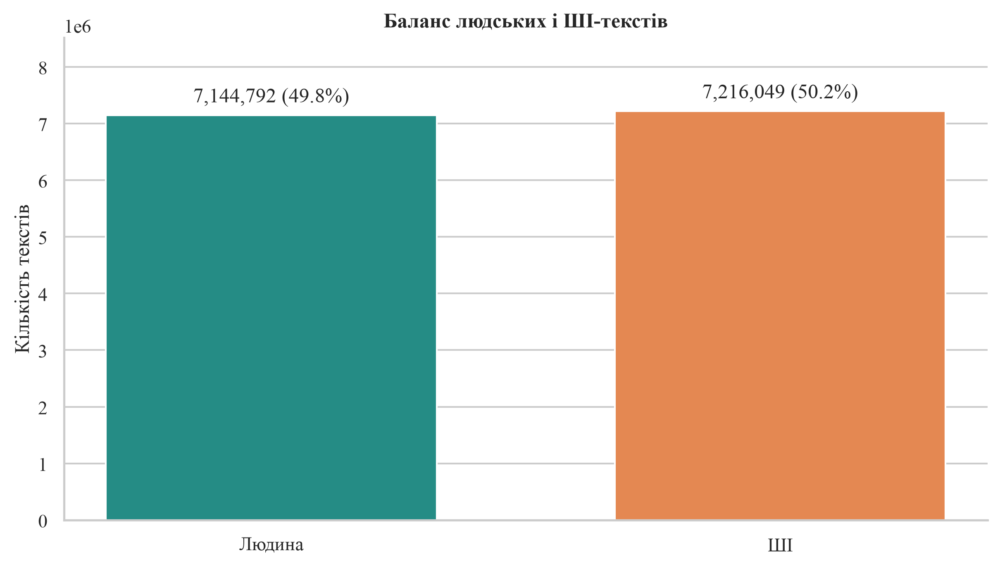

In [3]:
label_stats = eda_df["class"].value_counts().reindex(class_order, fill_value=0).to_frame("Кількість")
label_stats["Частка, %"] = (label_stats["Кількість"] / len(eda_df) * 100).round(2)
display(label_stats)
label_stats.to_csv(TABLES / "01_labels.csv")

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(label_stats.index, label_stats["Кількість"], color=class_colors, width=0.65)
ax.bar_label(bars, labels=[f"{row['Кількість']:,.0f} ({row['Частка, %']:.1f}%)"
                          for _, row in label_stats.iterrows()], padding=5)
ax.set(title="Баланс людських і ШІ-текстів", ylabel="Кількість текстів")
ax.grid(axis="x", visible=False)
ax.margins(y=0.18)
show_plot(fig, "01_labels")


## Кількість текстів за джерелами

Повний корпус: кількість та відсоток кожної категорії. На графіку категорії відсортовані за кількістю.


,Кількість,"Частка, %"
source,,
RAID,6539608,45.54
Wikimedia Dumps,6055257,42.17
MAGE,375853,2.62
HC3-Plus,284923,1.98
XSum,204822,1.43
LMSYS-GPT5,185750,1.29
SemEval,176408,1.23
MULTITuDEv3,156238,1.09
Amazon Reviews,140513,0.98


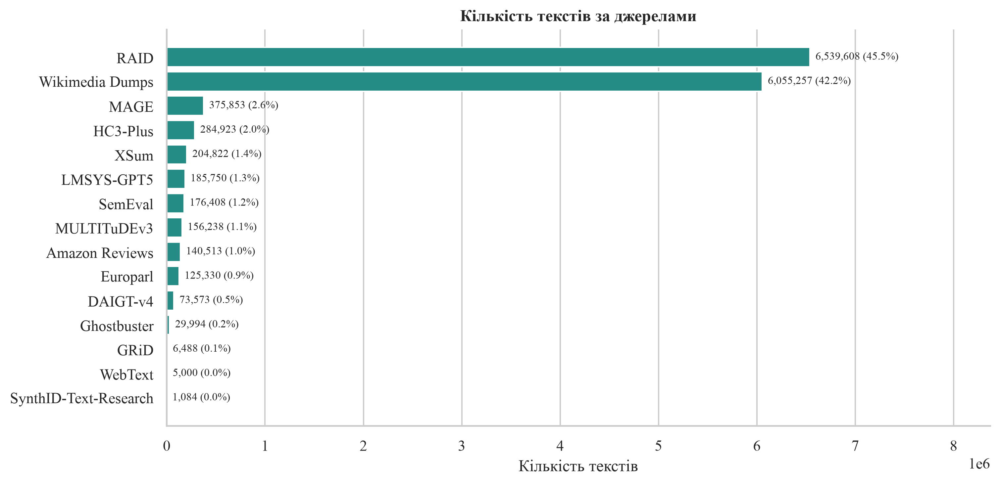

In [4]:
category_stats = eda_df["source"].value_counts(dropna=False).to_frame("Кількість")
category_stats["Частка, %"] = (category_stats["Кількість"] / len(eda_df) * 100).round(2)
display(category_stats)
category_stats.to_csv(TABLES / "02_source.csv")

shown = category_stats.sort_values("Кількість")
fig, ax = plt.subplots(figsize=(10, max(4, len(shown) * 0.32)))
bars = ax.barh(shown.index.astype(str), shown["Кількість"], color="#258C85")
ax.bar_label(bars, labels=[f"{row['Кількість']:,.0f} ({row['Частка, %']:.1f}%)"
                          for _, row in shown.iterrows()], padding=4, fontsize=8)
ax.set(title="Кількість текстів за джерелами", xlabel="Кількість текстів", ylabel="")
ax.grid(axis="y", visible=False)
ax.margins(x=0.28)
show_plot(fig, "02_source")


## Кількість текстів за мовами

Повний корпус: кількість та відсоток кожної категорії. На графіку категорії відсортовані за кількістю.


,Кількість,"Частка, %"
language,,
english,11528839,80.28
german,1288724,8.97
czech,1177888,8.20
chinese,116354,0.81
bulgarian,26996,0.19
russian,16769,0.12
arabic,15086,0.11
hungarian,13928,0.10
dutch,13918,0.10


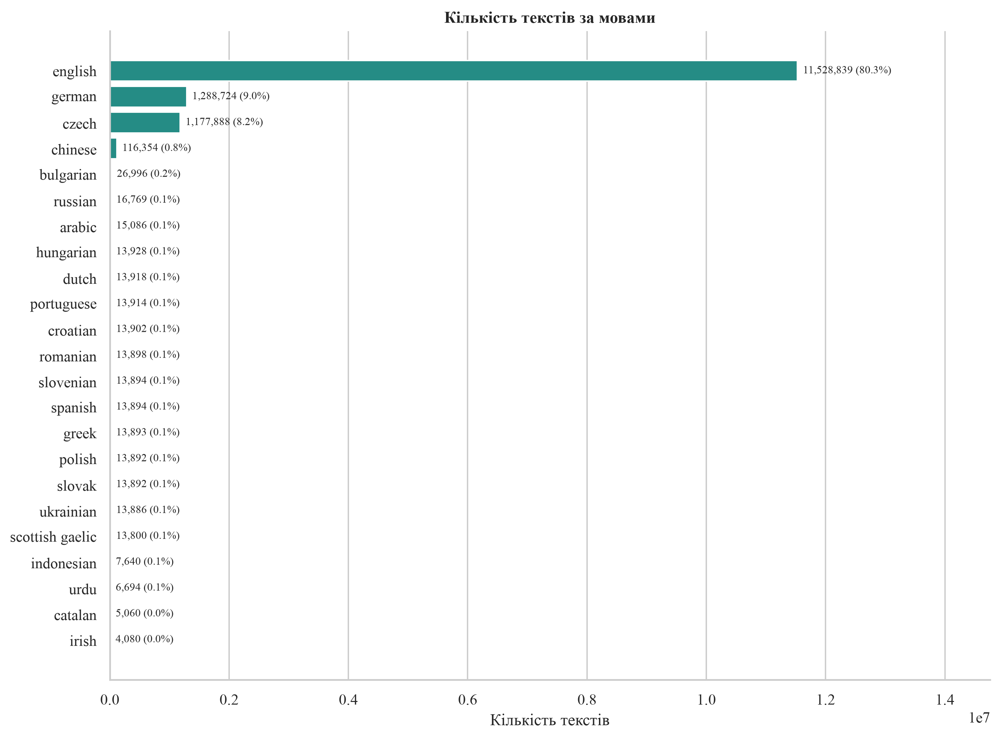

In [5]:
category_stats = eda_df["language"].value_counts(dropna=False).to_frame("Кількість")
category_stats["Частка, %"] = (category_stats["Кількість"] / len(eda_df) * 100).round(2)
display(category_stats)
category_stats.to_csv(TABLES / "03_language.csv")

shown = category_stats.sort_values("Кількість")
fig, ax = plt.subplots(figsize=(10, max(4, len(shown) * 0.32)))
bars = ax.barh(shown.index.astype(str), shown["Кількість"], color="#258C85")
ax.bar_label(bars, labels=[f"{row['Кількість']:,.0f} ({row['Частка, %']:.1f}%)"
                          for _, row in shown.iterrows()], padding=4, fontsize=8)
ax.set(title="Кількість текстів за мовами", xlabel="Кількість текстів", ylabel="")
ax.grid(axis="y", visible=False)
ax.margins(x=0.28)
show_plot(fig, "03_language")


## Кількість текстів за групами моделей

Категорію `Human` виключено з таблиці та графіка. Відсотки обчислюємо серед решти моделей.


,Кількість,"Частка, %"
model_group,,
Mistral,1548526,21.46
GPT-3+,1520641,21.07
MPT,1446694,20.05
Llama,825033,11.43
Cohere,787849,10.92
GPT-2,748263,10.37
Other,325822,4.52
Claude,11239,0.16
Google,1979,0.03


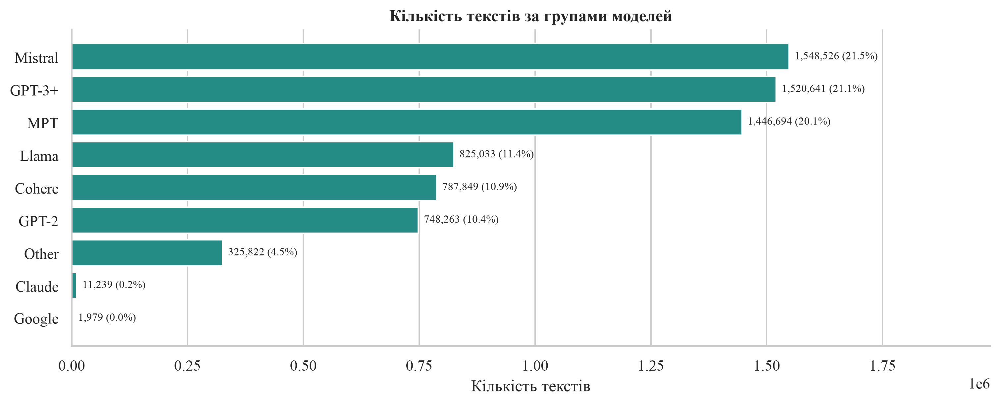

In [6]:
model_data = eda_df.loc[eda_df["model_group"].str.lower() != "human"]
category_stats = model_data["model_group"].value_counts(dropna=False).to_frame("Кількість")
category_stats["Частка, %"] = (category_stats["Кількість"] / len(model_data) * 100).round(2)
display(category_stats)
category_stats.to_csv(TABLES / "04_model_group.csv")

shown = category_stats.sort_values("Кількість")
fig, ax = plt.subplots(figsize=(10, max(4, len(shown) * 0.32)))
bars = ax.barh(shown.index.astype(str), shown["Кількість"], color="#258C85")
ax.bar_label(bars, labels=[f"{row['Кількість']:,.0f} ({row['Частка, %']:.1f}%)"
                          for _, row in shown.iterrows()], padding=4, fontsize=8)
ax.set(title="Кількість текстів за групами моделей", xlabel="Кількість текстів", ylabel="")
ax.grid(axis="y", visible=False)
ax.margins(x=0.28)
show_plot(fig, "04_model_group")


## Кількість текстів за групами доменів

Повний корпус: кількість та відсоток кожної категорії. На графіку категорії відсортовані за кількістю.


,Кількість,"Частка, %"
domain_group,,
other,2795652,19.47
creative,2706118,18.84
news,1656458,11.53
instruction,1622076,11.30
discussion,1472650,10.25
wiki,1392398,9.70
science,1346658,9.38
reviews,729177,5.08
technical,570754,3.97


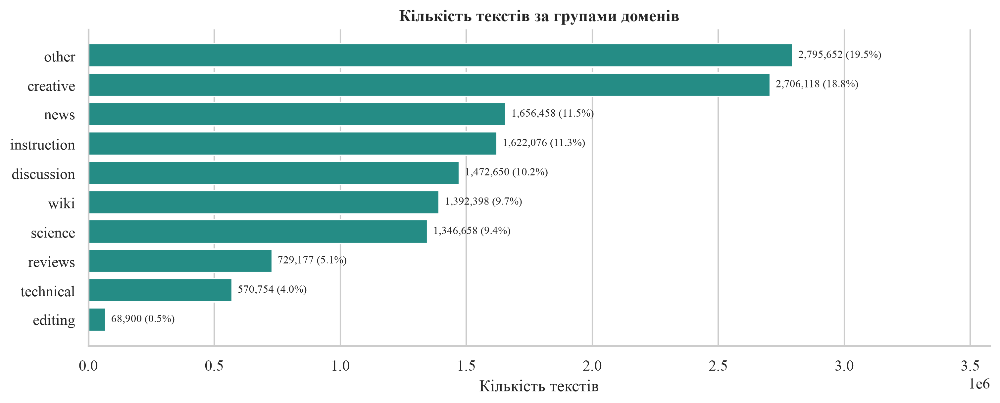

In [7]:
category_stats = eda_df["domain_group"].value_counts(dropna=False).to_frame("Кількість")
category_stats["Частка, %"] = (category_stats["Кількість"] / len(eda_df) * 100).round(2)
display(category_stats)
category_stats.to_csv(TABLES / "05_domain_group.csv")

shown = category_stats.sort_values("Кількість")
fig, ax = plt.subplots(figsize=(10, max(4, len(shown) * 0.32)))
bars = ax.barh(shown.index.astype(str), shown["Кількість"], color="#258C85")
ax.bar_label(bars, labels=[f"{row['Кількість']:,.0f} ({row['Частка, %']:.1f}%)"
                          for _, row in shown.iterrows()], padding=4, fontsize=8)
ax.set(title="Кількість текстів за групами доменів", xlabel="Кількість текстів", ylabel="")
ax.grid(axis="y", visible=False)
ax.margins(x=0.28)
show_plot(fig, "05_domain_group")


## Баланс класів: мови

Кількості та відсотки класів у кожній групі. Пунктир позначає співвідношення 50:50.


class,Людина,ШІ,Разом,"Людина, %","ШІ, %"
language,,,,,
english,5783702,5745137,11528839,50.17,49.83
german,644362,644362,1288724,50.00,50.00
czech,528674,649214,1177888,44.88,55.12
chinese,61216,55138,116354,52.61,47.39
bulgarian,14042,12954,26996,52.02,47.98
russian,8824,7945,16769,52.62,47.38
arabic,7611,7475,15086,50.45,49.55
hungarian,6964,6964,13928,50.00,50.00
dutch,6959,6959,13918,50.00,50.00


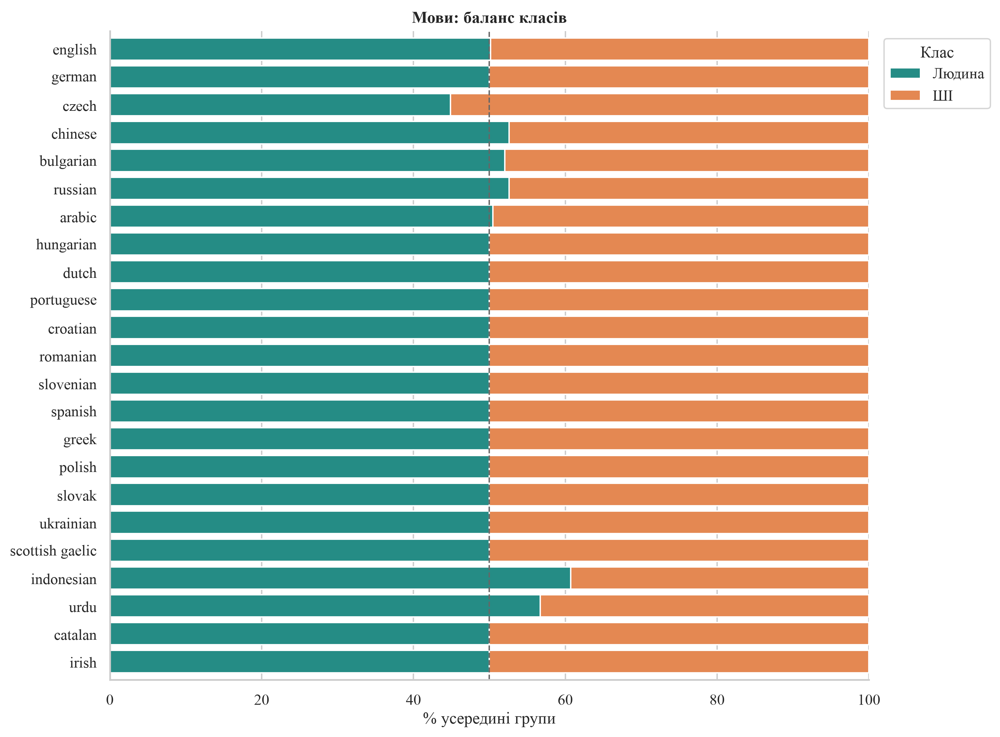

In [8]:
counts = pd.crosstab(eda_df["language"], eda_df["class"]).reindex(columns=class_order, fill_value=0)
counts = counts.loc[counts.sum(axis=1).sort_values(ascending=False).index]
shares = counts.div(counts.sum(axis=1), axis=0) * 100
balance_stats = counts.copy()
balance_stats["Разом"] = counts.sum(axis=1)
balance_stats["Людина, %"] = shares["Людина"].round(2)
balance_stats["ШІ, %"] = shares["ШІ"].round(2)
display(balance_stats)
balance_stats.to_csv(TABLES / "06_language_balance.csv")

ax = shares.plot.barh(stacked=True, color=class_colors,
                     figsize=(10, max(4, len(shares) * 0.32)), width=0.8)
ax.axvline(50, color="#666666", linestyle="--", linewidth=1)
ax.set(title="Мови: баланс класів", xlabel="% усередині групи", ylabel="", xlim=(0, 100))
ax.invert_yaxis()
ax.legend(title="Клас", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(axis="y", visible=False)
show_plot(ax.figure, "06_language_balance")


## Баланс класів: домени

Кількості та відсотки класів у кожній групі. Пунктир позначає співвідношення 50:50.


class,Людина,ШІ,Разом,"Людина, %","ШІ, %"
domain_group,,,,,
other,1363997,1431655,2795652,48.79,51.21
creative,1353059,1353059,2706118,50.00,50.00
news,825937,830521,1656458,49.86,50.14
instruction,811038,811038,1622076,50.00,50.00
discussion,736325,736325,1472650,50.00,50.00
wiki,696199,696199,1392398,50.00,50.00
science,673329,673329,1346658,50.00,50.00
reviews,365081,364096,729177,50.07,49.93
technical,285377,285377,570754,50.00,50.00


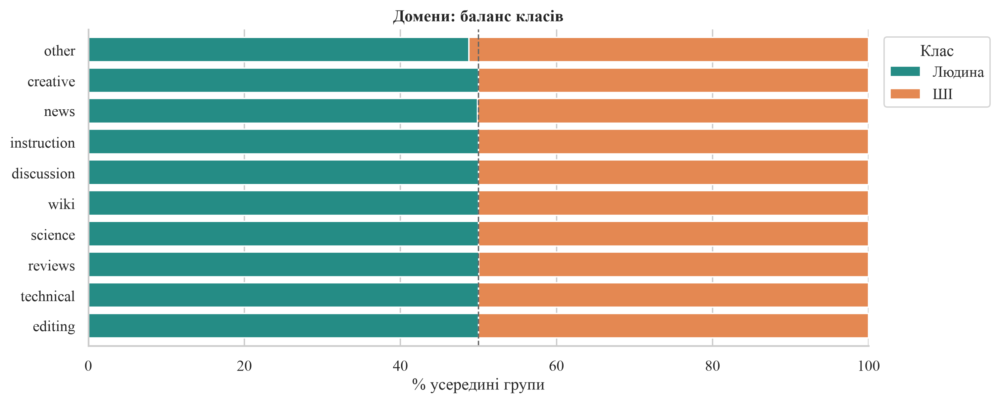

In [9]:
counts = pd.crosstab(eda_df["domain_group"], eda_df["class"]).reindex(columns=class_order, fill_value=0)
counts = counts.loc[counts.sum(axis=1).sort_values(ascending=False).index]
shares = counts.div(counts.sum(axis=1), axis=0) * 100
balance_stats = counts.copy()
balance_stats["Разом"] = counts.sum(axis=1)
balance_stats["Людина, %"] = shares["Людина"].round(2)
balance_stats["ШІ, %"] = shares["ШІ"].round(2)
display(balance_stats)
balance_stats.to_csv(TABLES / "07_domain_group_balance.csv")

ax = shares.plot.barh(stacked=True, color=class_colors,
                     figsize=(10, max(4, len(shares) * 0.32)), width=0.8)
ax.axvline(50, color="#666666", linestyle="--", linewidth=1)
ax.set(title="Домени: баланс класів", xlabel="% усередині групи", ylabel="", xlim=(0, 100))
ax.invert_yaxis()
ax.legend(title="Клас", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(axis="y", visible=False)
show_plot(ax.figure, "07_domain_group_balance")


## Загальна статистика довжин у символах за класами

Таблиці обчислюються на всіх записах. Гістограма та накопичений розподіл — на всіх даних; кожен клас нормується окремо. Логарифмічна вісь дозволяє показати довгий хвіст. Нульові довжини не включені до логарифмічного графіка.


In [10]:
length_stats = eda_df.groupby("class")["chars"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
).reindex(class_order).round(2)
display(length_stats)
length_stats.to_csv(TABLES / "08_chars_by_class.csv")
print("Нульові довжини:", eda_df["chars"].eq(0).sum())



,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
class,,,,,,,,,,,,
Людина,7144792.0,1820.93,2317.52,1.0,79.0,235.0,799.0,1580.0,1999.0,3999.0,6979.0,518241.0
ШІ,7216049.0,1476.77,971.19,1.0,68.0,258.0,835.0,1362.0,1951.0,2998.0,4656.0,35867.0


Нульові довжини: 0


### Розподіл довжин у символах


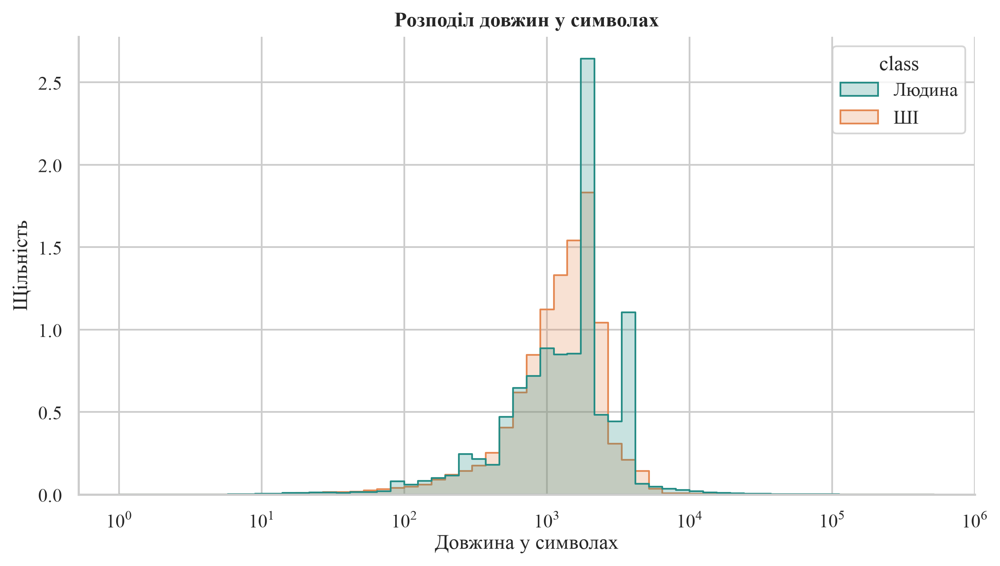

In [11]:
positive = plot_df[plot_df["chars"] > 0]
fig, ax = plt.subplots(figsize=(8, 4.5))
if len(positive) > 0:
    sns.histplot(data=positive, x="chars", hue="class", hue_order=class_order,
                 palette=class_palette, stat="density", common_norm=False,
                 element="step", bins=60, log_scale=True, ax=ax)
ax.set(title="Розподіл довжин у символах", xlabel="Довжина у символах", ylabel="Щільність")
show_plot(fig, "08_chars_histogram")


### Накопичений розподіл довжин у символах


/tmp/ipykernel_22633/171791287.py:53: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout(pad=0.4)
/tmp/ipykernel_22633/171791287.py:54: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.savefig(FIGURES / f"{name}.png", dpi=300, facecolor="white",
/home/artem/miniconda3/envs/diploma/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


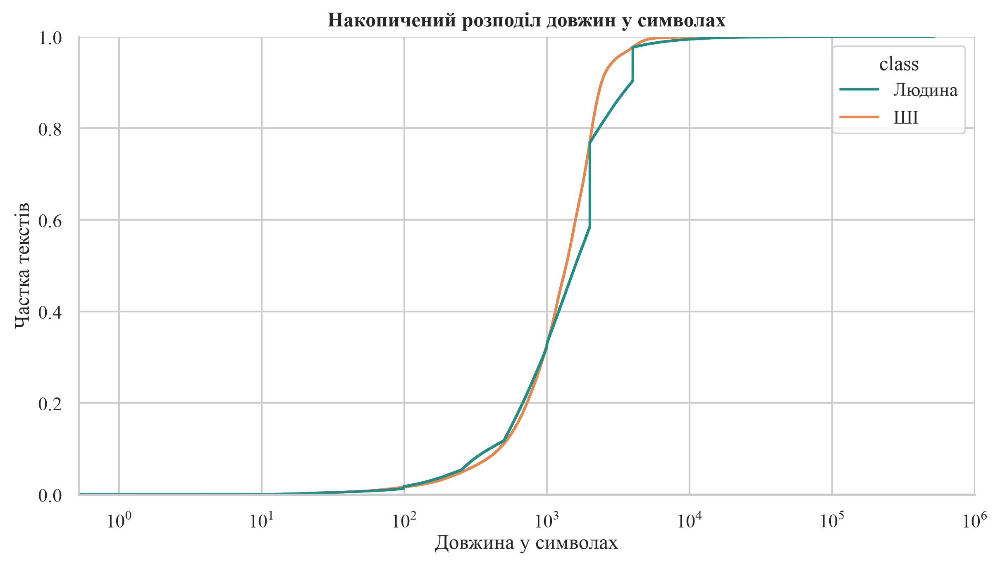

In [12]:
positive = plot_df[plot_df["chars"] > 0]
fig, ax = plt.subplots(figsize=(8, 4.5))
if len(positive) > 0:
    sns.ecdfplot(data=positive, x="chars", hue="class", hue_order=class_order,
                 palette=class_palette, ax=ax)
    ax.set_xscale("log")
ax.set(title="Накопичений розподіл довжин у символах",
       xlabel="Довжина у символах", ylabel="Частка текстів")
show_plot(fig, "08_chars_ecdf")


## Загальна статистика довжин у словах за класами

Таблиці обчислюються на всіх записах. Гістограма та накопичений розподіл — на всіх даних; кожен клас нормується окремо. Логарифмічна вісь дозволяє показати довгий хвіст. Нульові довжини не включені до логарифмічного графіка.


In [13]:
length_stats = eda_df.groupby("class")["words"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
).reindex(class_order).round(2)
display(length_stats)
length_stats.to_csv(TABLES / "09_words_by_class.csv")
print("Нульові довжини:", eda_df["words"].eq(0).sum())



,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
class,,,,,,,,,,,,
Людина,7144792.0,284.84,357.17,1.0,9.0,36.0,122.0,243.0,334.0,660.0,1117.0,75994.0
ШІ,7216049.0,222.49,128.84,1.0,7.0,40.0,130.0,211.0,309.0,404.0,534.0,4581.0


Нульові довжини: 0


### Розподіл довжин у словах


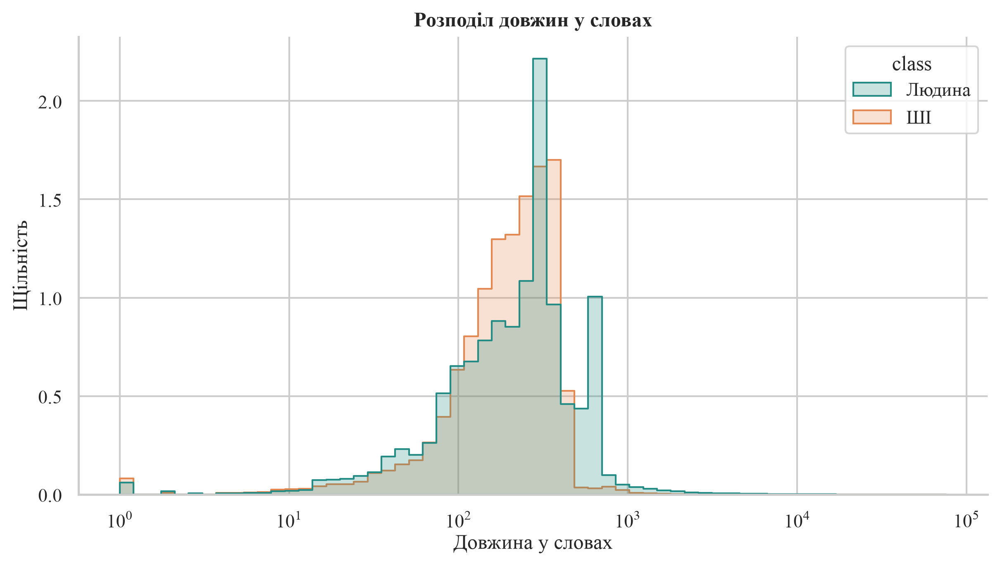

In [14]:
positive = plot_df[plot_df["words"] > 0]
fig, ax = plt.subplots(figsize=(8, 4.5))
if len(positive) > 0:
    sns.histplot(data=positive, x="words", hue="class", hue_order=class_order,
                 palette=class_palette, stat="density", common_norm=False,
                 element="step", bins=60, log_scale=True, ax=ax)
ax.set(title="Розподіл довжин у словах", xlabel="Довжина у словах", ylabel="Щільність")
show_plot(fig, "09_words_histogram")


### Накопичений розподіл довжин у словах


/tmp/ipykernel_22633/171791287.py:53: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout(pad=0.4)
/tmp/ipykernel_22633/171791287.py:54: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.savefig(FIGURES / f"{name}.png", dpi=300, facecolor="white",
/home/artem/miniconda3/envs/diploma/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


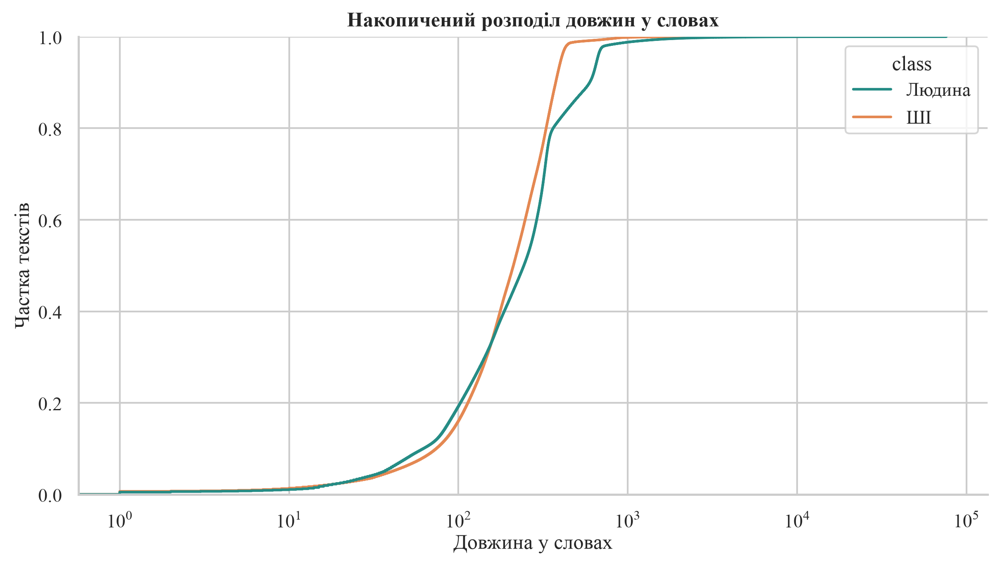

In [15]:
positive = plot_df[plot_df["words"] > 0]
fig, ax = plt.subplots(figsize=(8, 4.5))
if len(positive) > 0:
    sns.ecdfplot(data=positive, x="words", hue="class", hue_order=class_order,
                 palette=class_palette, ax=ax)
    ax.set_xscale("log")
ax.set(title="Накопичений розподіл довжин у словах",
       xlabel="Довжина у словах", ylabel="Частка текстів")
show_plot(fig, "09_words_ecdf")


## Статистика довжин за мовами

Показуємо кількість, середнє, медіану, мінімум, максимум і квартилі для кожної групи та класу. Boxplot побудовані на всіх даних; точки викидів приховані лише на графіку.


Довжина: символи


count     mean       std     min      25%     50%  \
language        class                                                           
arabic          Людина     7611.0   641.71    516.78     7.0   317.00   489.0   
                ШІ         7475.0   573.26    343.73    29.0   368.00   491.0   
bulgarian       Людина    14042.0  1545.23   1104.51    48.0   766.00  1597.0   
                ШІ        12954.0  1481.09    882.52    25.0   769.25  1254.5   
catalan         Людина     2530.0  1207.54    466.72    26.0   955.00  1224.0   
                ШІ         2530.0  1186.32    402.80    71.0   946.25  1293.0   
chinese         Людина    61216.0   121.68    290.36     1.0    20.00    37.0   
                ШІ        55138.0   100.05    137.36     1.0    22.00    37.0   
croatian        Людина     6951.0   995.37    490.16    44.0   627.00   957.0   
                ШІ         6951.0   905.67    360.14    15.0   632.00   975.0   
czech           Людина   528674.0  1536.18   1178.48    25.0   808.00  1500.0   
                ШІ       649214.0  1256.79    652.53    25.0   918.00  1131.0   
dutch           Людина     6959.0  1188.90    502.39     5.0   852.00  1192.0   
                ШІ         6959.0  1160.28    443.27    17.0   846.00  1249.0   
english         Людина  5783702.0  1854.10   2148.75    25.0   794.00  1550.0   
                ШІ      5745137.0  1512.33   1019.12    25.0   817.00  1399.0   
german          Людина   644362.0  2057.27   3891.75    25.0  1323.00  1999.0   
                ШІ       644362.0  1594.71    712.55    25.0  1203.00  1546.0   
greek           Людина     6947.0   516.63    344.65     2.0   293.00   434.0   
                ШІ         6946.0   492.82    299.21    24.0   306.00   441.0   
hungarian       Людина     6964.0   822.78    448.12    41.0   495.00   739.5   
                ШІ         6964.0   763.07    354.09    24.0   497.00   735.0   
indonesian      Людина     4640.0  2403.01   1199.63    16.0  1706.00  2252.5   
                ШІ         3000.0  2415.61    316.94  1584.0  2199.00  2391.5   
irish           Людина     2040.0   804.71    510.27    41.0   434.75   703.5   
                ШІ         2040.0   758.15    381.96    40.0   453.00   782.5   
polish          Людина     6946.0   950.36    498.03     3.0   561.00   891.0   
                ШІ         6946.0   870.11    377.36    19.0   567.25   911.0   
portuguese      Людина     6957.0  1107.60    505.64     9.0   716.00  1110.0   
                ШІ         6957.0  1081.94    443.28    23.0   741.00  1131.0   
romanian        Людина     6949.0  1086.46    513.70    37.0   647.00  1099.0   
                ШІ         6949.0  1031.39    408.12    21.0   717.00  1119.0   
russian         Людина     8824.0   865.07    529.53    25.0   492.00   712.0   
                ШІ         7945.0   828.75    470.01    38.0   451.00   779.0   
scottish gaelic Людина     6900.0   400.25    340.29    13.0   174.00   292.0   
                ШІ         6900.0   392.72    309.04    13.0   166.00   291.0   
slovak          Людина     6946.0   874.00    463.86    10.0   528.25   798.0   
                ШІ         6946.0   818.80    356.70    31.0   535.25   837.0   
slovenian       Людина     6947.0   960.66    469.90    41.0   595.00   912.0   
                ШІ         6947.0   892.50    357.71    11.0   608.50   934.0   
spanish         Людина     6947.0  1105.44    492.50    27.0   716.00  1115.0   
                ШІ         6947.0  1106.60    462.34    19.0   752.50  1140.0   
ukrainian       Людина     6943.0   815.13    477.74    18.0   472.00   730.0   
                ШІ         6943.0   745.50    357.59    30.0   466.00   737.0   
urdu            Людина     3795.0  4243.61  13969.95    11.0   790.00  1282.0   
                ШІ         2899.0  1988.94   1464.28    57.0   984.50  1208.0   

                            75%       max  
language        class                      
arabic          Людина   788.00    7644.0  
       

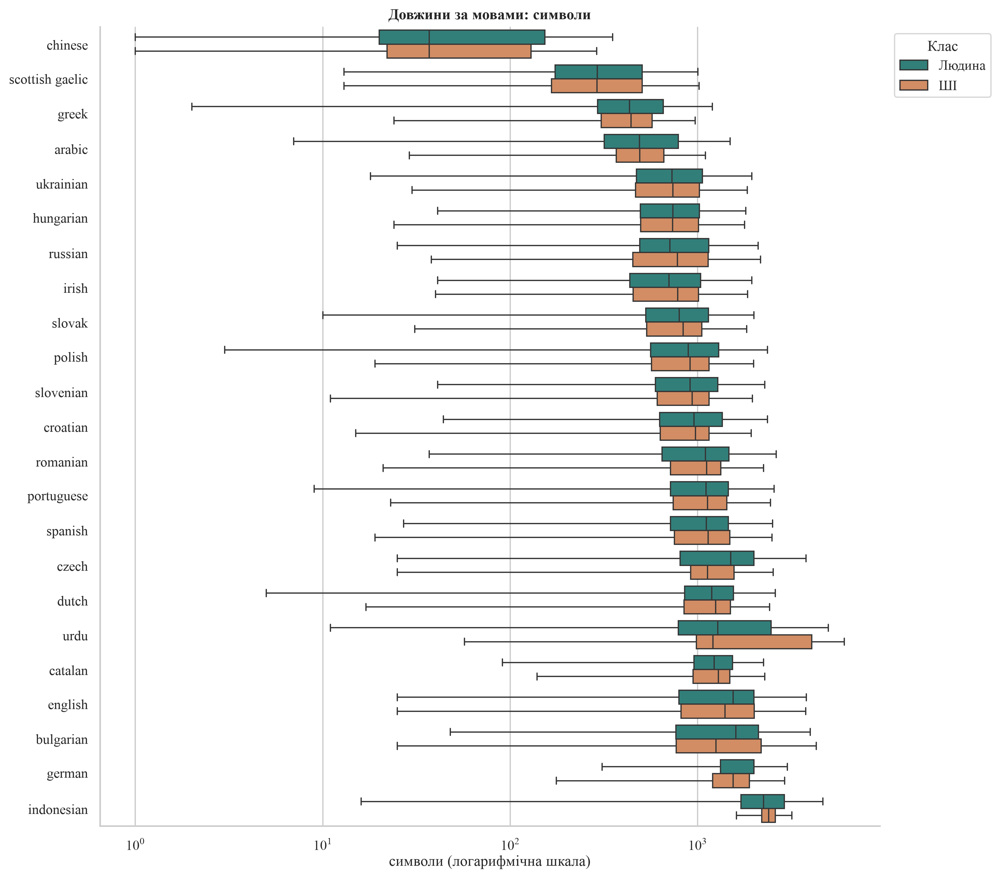

Довжина: слова


count    mean      std    min     25%    50%  \
language        class                                                      
arabic          Людина     7611.0  104.89    84.77    1.0   51.00   80.0   
                ШІ         7475.0   93.07    55.15    6.0   60.00   79.0   
bulgarian       Людина    14042.0  240.03   172.10    6.0  117.00  247.0   
                ШІ        12954.0  228.61   137.87    6.0  117.00  194.0   
catalan         Людина     2530.0  194.64    77.69    4.0  147.00  198.0   
                ШІ         2530.0  195.25    67.09    7.0  154.00  212.0   
chinese         Людина    61216.0    4.34    12.63    1.0    1.00    1.0   
                ШІ        55138.0    3.22    12.98    1.0    1.00    1.0   
croatian        Людина     6951.0  145.20    72.91    5.0   90.00  141.0   
                ШІ         6951.0  137.89    56.85    6.0   96.00  145.0   
czech           Людина   528674.0  226.33   170.45    2.0  119.00  220.0   
                ШІ       649214.0  180.39    85.33    1.0  137.00  167.0   
dutch           Людина     6959.0  176.66    76.46    1.0  126.00  177.0   
                ШІ         6959.0  180.76    70.54    6.0  131.00  191.0   
english         Людина  5783702.0  296.31   343.50    1.0  123.00  245.0   
                ШІ      5745137.0  231.61   134.82    1.0  130.00  224.0   
german          Людина   644362.0  278.53   508.75    2.0  176.00  265.0   
                ШІ       644362.0  215.92    80.56    1.0  167.00  219.0   
greek           Людина     6947.0   75.25    51.65    1.0   41.00   63.0   
                ШІ         6946.0   73.87    47.17    6.0   44.25   65.0   
hungarian       Людина     6964.0  108.35    59.81    5.0   65.00   97.0   
                ШІ         6964.0  105.52    47.64    6.0   69.00  101.0   
indonesian      Людина     4640.0  336.73   172.57    1.0  240.00  314.0   
                ШІ         3000.0  330.80    44.04  215.0  300.00  326.0   
irish           Людина     2040.0  130.51    82.76    4.0   70.00  115.0   
                ШІ         2040.0  135.50    68.23    6.0   83.00  138.0   
polish          Людина     6946.0  128.60    67.72    1.0   75.00  122.0   
                ШІ         6946.0  121.94    54.25    6.0   80.00  126.0   
portuguese      Людина     6957.0  175.68    80.90    1.0  113.00  176.0   
                ШІ         6957.0  173.31    71.85    6.0  119.00  180.0   
romanian        Людина     6949.0  164.49    74.81    6.0  103.00  164.0   
                ШІ         6949.0  161.19    64.86    6.0  113.00  171.0   
russian         Людина     8824.0  114.79    72.30    3.0   65.00   96.0   
                ШІ         7945.0  112.43    65.49    6.0   60.00  104.0   
scottish gaelic Людина     6900.0   63.34    53.39    1.0   28.00   47.0   
                ШІ         6900.0   65.50    53.06    6.0   27.00   48.0   
slovak          Людина     6946.0  125.36    67.44    1.0   75.00  115.0   
                ШІ         6946.0  122.78    56.15    6.0   79.00  124.0   
slovenian       Людина     6947.0  142.34    69.39    7.0   90.00  136.0   
                ШІ         6947.0  139.33    58.38    6.0   95.00  143.0   
spanish         Людина     6947.0  174.13    78.41    4.0  113.00  175.0   
                ШІ         6947.0  181.70    75.81    6.0  126.00  186.0   
ukrainian       Людина     6943.0  108.96    63.57    2.0   63.00   98.0   
                ШІ         6943.0  102.96    51.44    6.0   64.00  101.0   
urdu            Людина     3795.0  897.51  3008.30    2.0  164.50  272.0   
                ШІ         2899.0  426.68   313.34   13.0  212.50  259.0   

                          75%      max  
language        class                   
arabic          Людина  130.0   1169.0  
                ШІ      107.0    372.0  
bulgarian       Людина  329.0   8483.0  
                ШІ      334.0   1026.0  
catalan         Людина  248.0    643.0  
                ШІ      245.0    461.0  
chinese         Людина    3.0    800.0  
          

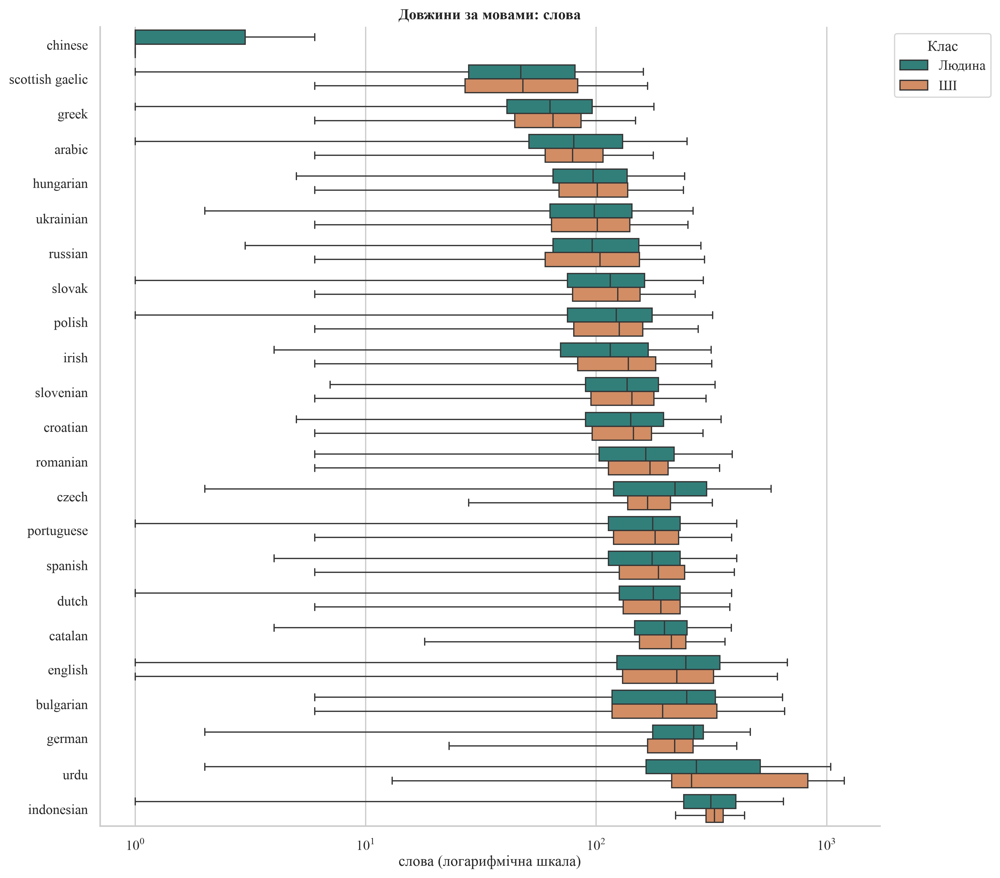

In [16]:
for metric, unit in [("chars", "символи"), ("words", "слова")]:
    stats = eda_df.groupby(["language", "class"])[metric].describe().round(2)
    print("Довжина:", unit)
    display(stats)
    stats.to_csv(TABLES / f"10_language_{metric}.csv")

    order = eda_df.groupby("language")[metric].median().sort_values().index
    fig, ax = plt.subplots(figsize=(11, max(4, len(order) * 0.42)))
    positive = plot_df[plot_df[metric] > 0]
    if len(positive) > 0:
        sns.boxplot(data=positive, x=metric, y="language", hue="class",
                    hue_order=class_order, order=order, palette=class_palette,
                    showfliers=False, ax=ax)
        ax.set_xscale("log")
        ax.legend(title="Клас", bbox_to_anchor=(1.01, 1), loc="upper left")
    ax.set(title=f"Довжини за мовами: {unit}", xlabel=f"{unit} (логарифмічна шкала)", ylabel="")
    show_plot(fig, f"10_language_{metric}")


## Статистика довжин за доменами

Показуємо кількість, середнє, медіану, мінімум, максимум і квартилі для кожної групи та класу. Boxplot побудовані на всіх даних; точки викидів приховані лише на графіку.


Довжина: символи


count     mean      std   min     25%     50%  \
domain_group class                                                       
creative     Людина  1353059.0  1795.77  2113.25  25.0   776.0  1346.0   
             ШІ      1353059.0  1469.57  1005.15  25.0   794.0  1312.0   
discussion   Людина   736325.0  1777.69  2153.01  25.0   685.0  1444.0   
             ШІ       736325.0  1469.74  1291.51  25.0   675.0  1278.0   
editing      Людина    34450.0  1374.85  2779.20  25.0   285.0   987.5   
             ШІ        34450.0  1004.85  1081.22  25.0   285.0   635.0   
instruction  Людина   811038.0  1739.57  1653.59  27.0   977.0  1500.0   
             ШІ       811038.0  1482.21   840.67  25.0   970.0  1383.0   
news         Людина   825937.0  1968.08  1369.57   2.0   999.0  1911.0   
             ШІ       830521.0  1644.72  1034.39   7.0   981.0  1565.0   
other        Людина  1363997.0  1648.42  2936.58   1.0   741.0  1712.0   
             ШІ      1431655.0  1329.42   760.92   1.0   893.0  1230.0   
reviews      Людина   365081.0  2010.01  2113.93  25.0   890.0  1999.0   
             ШІ       364096.0  1568.55   888.84  25.0   864.0  1549.0   
science      Людина   673329.0  1732.52  2105.37  30.0   726.0  1188.0   
             ШІ       673329.0  1367.40   861.69  25.0   764.0  1074.0   
technical    Людина   285377.0   974.19  1521.51  25.0   199.0   433.0   
             ШІ       285377.0   790.61   881.24  25.0   180.0   425.0   
wiki         Людина   696199.0  2529.24  3216.14  29.0  1414.0  1999.0   
             ШІ       696199.0  1956.94   849.63  25.0  1441.0  1923.0   

                        75%       max  
domain_group class                     
creative     Людина  1999.0  208743.0  
             ШІ      1930.0   27321.0  
discussion   Людина  1999.0  154385.0  
             ШІ      1940.0   35867.0  
editing      Людина  1999.0  198107.0  
             ШІ      1323.0   13893.0  
instruction  Людина  1999.0  152999.0  
             ШІ      1777.0   17135.0  
news         Людина  2480.0  174045.0  
             ШІ      2117.0   20841.0  
other        Людина  1999.0  518241.0  
             ШІ      1751.0   17400.0  
reviews      Людина  2314.0  166255.0  
             ШІ      2060.0    7124.0  
science      Людина  1999.0  277429.0  
             ШІ      1849.0    8605.0  
technical    Людина  1609.0  120335.0  
             ШІ      1222.0   19042.0  
wiki         Людина  3072.0  211728.0  
             ШІ      2304.0    8656.0

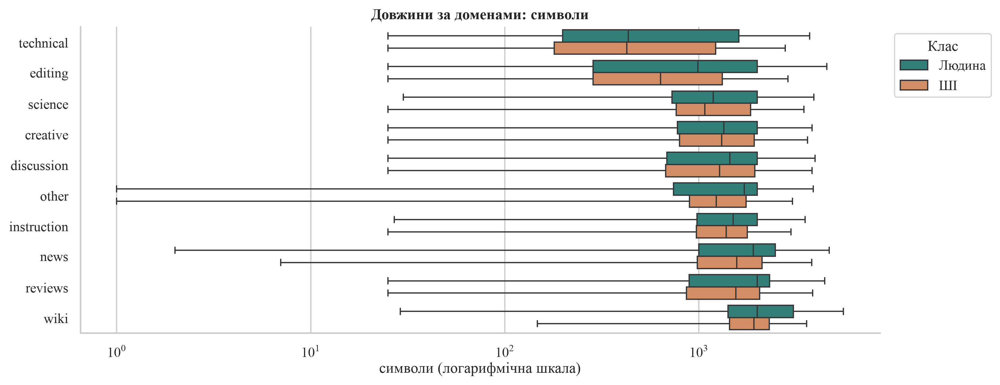

Довжина: слова


count    mean     std  min    25%    50%     75%  \
domain_group class                                                          
creative     Людина  1353059.0  285.32  337.99  2.0  119.0  212.0  330.00   
             ШІ      1353059.0  235.13  137.82  1.0  136.0  215.0  324.00   
discussion   Людина   736325.0  285.13  336.68  1.0  105.0  231.0  339.00   
             ШІ       736325.0  237.10  168.24  1.0  114.0  215.0  339.00   
editing      Людина    34450.0  220.47  450.71  3.0   43.0  141.0  317.00   
             ШІ        34450.0  159.97  171.05  1.0   46.0  101.0  211.75   
instruction  Людина   811038.0  278.36  274.37  5.0  149.0  238.0  325.00   
             ШІ       811038.0  236.17  118.26  1.0  161.0  235.0  291.00   
news         Людина   825937.0  316.67  222.30  1.0  156.0  296.0  404.00   
             ШІ       830521.0  246.92  129.02  1.0  154.0  246.0  339.00   
other        Людина  1363997.0  233.08  408.66  1.0  106.0  236.0  292.00   
             ШІ      1431655.0  185.64   96.59  1.0  130.0  179.0  246.00   
reviews      Людина   365081.0  323.73  337.61  5.0  143.0  305.0  371.00   
             ШІ       364096.0  243.88  120.82  1.0  139.0  246.0  337.00   
science      Людина   673329.0  273.71  340.15  4.0  111.0  180.0  333.00   
             ШІ       673329.0  186.03  109.26  1.0  107.0  146.0  254.00   
technical    Людина   285377.0  153.95  245.55  1.0   29.0   65.0  250.00   
             ШІ       285377.0  112.51  121.16  1.0   25.0   60.0  174.00   
wiki         Людина   696199.0  401.97  508.92  1.0  221.0  326.0  487.00   
             ШІ       696199.0  285.42   91.30  1.0  225.0  301.0  353.00   

                         max  
domain_group class            
creative     Людина  34903.0  
             ШІ       4149.0  
discussion   Людина  24618.0  
             ШІ       4094.0  
editing      Людина  33901.0  
             ШІ       2025.0  
instruction  Людина  26375.0  
             ШІ       2830.0  
news         Людина  29189.0  
             ШІ       2470.0  
other        Людина  75994.0  
             ШІ       1529.0  
reviews      Людина  23554.0  
             ШІ       1422.0  
science      Людина  48059.0  
             ШІ       2985.0  
technical    Людина  23474.0  
             ШІ       4581.0  
wiki         Людина  33223.0  
             ШІ       2445.0

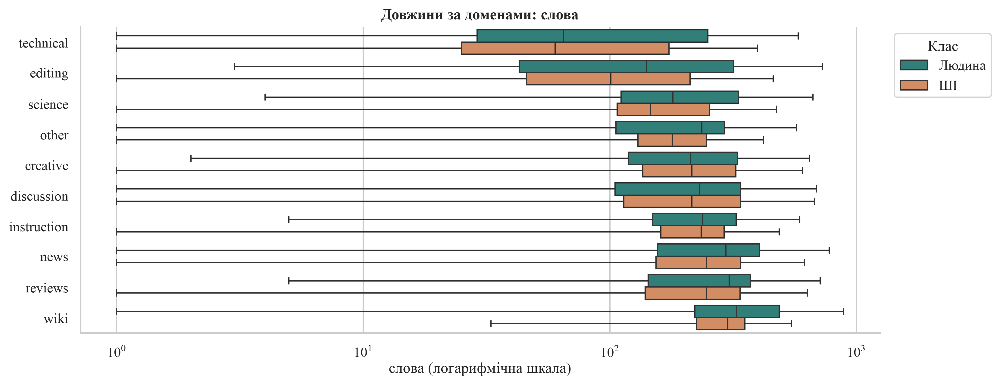

In [17]:
for metric, unit in [("chars", "символи"), ("words", "слова")]:
    stats = eda_df.groupby(["domain_group", "class"])[metric].describe().round(2)
    print("Довжина:", unit)
    display(stats)
    stats.to_csv(TABLES / f"11_domain_group_{metric}.csv")

    order = eda_df.groupby("domain_group")[metric].median().sort_values().index
    fig, ax = plt.subplots(figsize=(11, max(4, len(order) * 0.42)))
    positive = plot_df[plot_df[metric] > 0]
    if len(positive) > 0:
        sns.boxplot(data=positive, x=metric, y="domain_group", hue="class",
                    hue_order=class_order, order=order, palette=class_palette,
                    showfliers=False, ax=ax)
        ax.set_xscale("log")
        ax.legend(title="Клас", bbox_to_anchor=(1.01, 1), loc="upper left")
    ax.set(title=f"Довжини за доменами: {unit}", xlabel=f"{unit} (логарифмічна шкала)", ylabel="")
    show_plot(fig, f"11_domain_group_{metric}")


## Баланс класів у різних діапазонах довжини

Для символів і слів використовуємо окремі межі. Перший графік показує, як довжини розподілені всередині класів; другий — співвідношення класів у кожному діапазоні. Це різні знаменники відсотків.


Символи


class,Людина,ШІ,Людина — % класу,ШІ — % класу,Людина — % діапазону,ШІ — % діапазону
chars,,,,,,
0–99,124633,114528,1.74,1.59,52.11,47.89
100–249,254791,231980,3.57,3.21,52.34,47.66
250–499,460566,454036,6.45,6.29,50.36,49.64
500–999,1522149,1563013,21.30,21.66,49.34,50.66
1000–1999,3127947,3203405,43.78,44.39,49.40,50.60
2000–3999,1489012,1485454,20.84,20.59,50.06,49.94
4000+,165694,163633,2.32,2.27,50.31,49.69


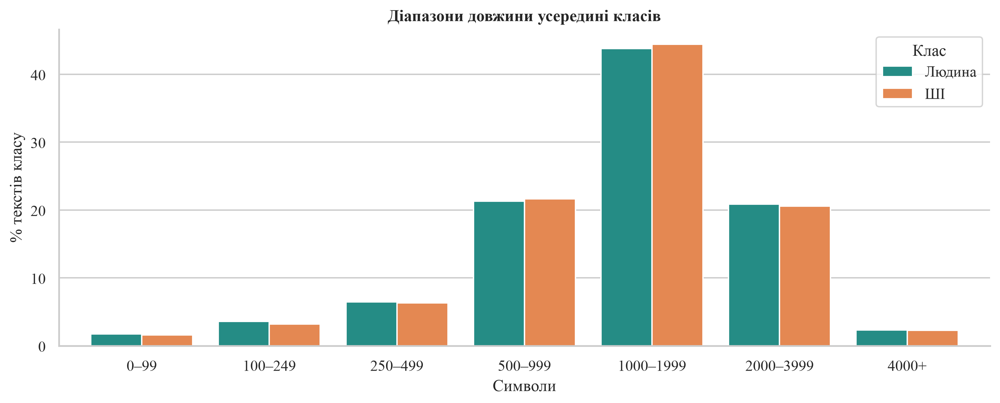

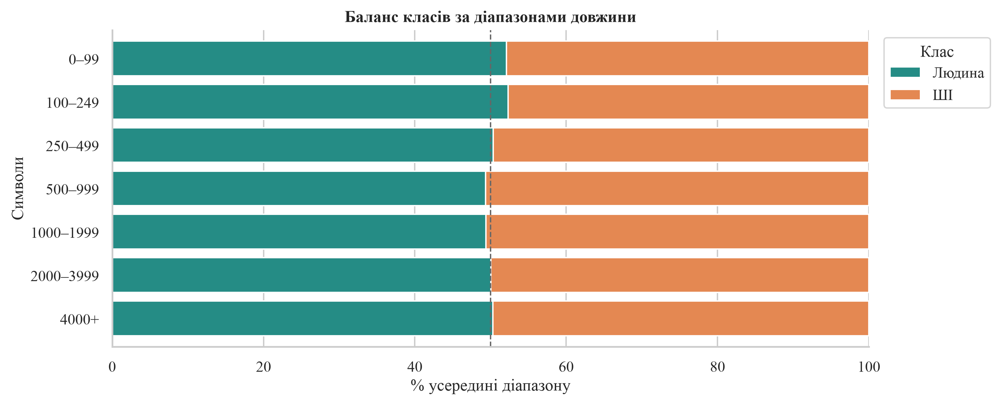

Слова


class,Людина,ШІ,Людина — % класу,ШІ — % класу,Людина — % діапазону,ШІ — % діапазону
words,,,,,,
0–24,226263,209156,3.17,2.90,51.96,48.04
25–49,338791,242581,4.74,3.36,58.27,41.73
50–99,800000,695089,11.20,9.63,53.51,46.49
100–199,1666973,2232928,23.33,30.94,42.74,57.26
200–399,2837435,3431363,39.71,47.55,45.26,54.74
400–799,1152953,373650,16.14,5.18,75.52,24.48
800+,122377,31282,1.71,0.43,79.64,20.36


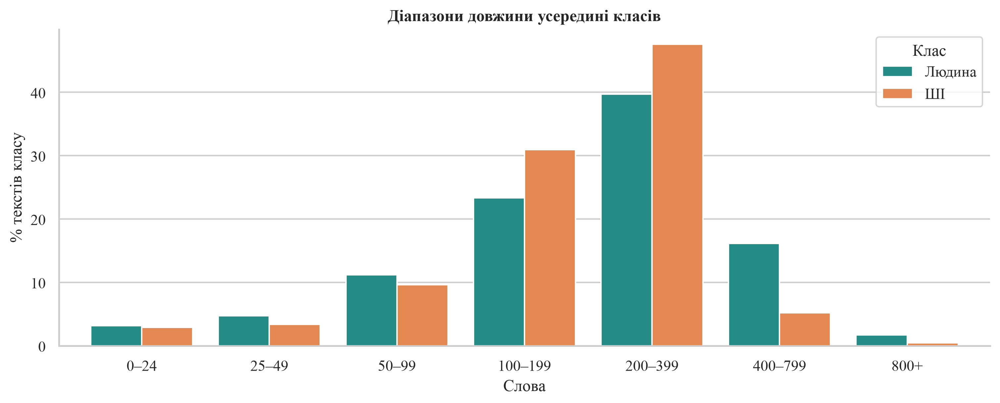

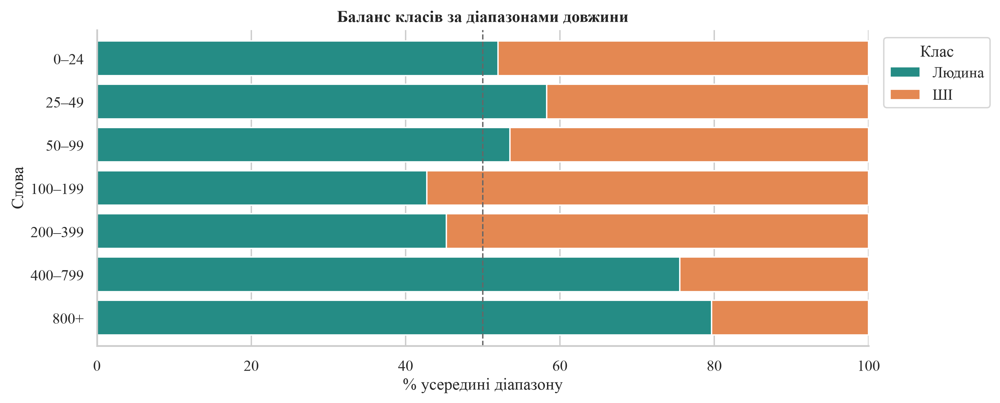

In [18]:
length_settings = [
    ("chars", "Символи", [0, 100, 250, 500, 1000, 2000, 4000, float("inf")],
     ["0–99", "100–249", "250–499", "500–999", "1000–1999", "2000–3999", "4000+"]),
    ("words", "Слова", [0, 25, 50, 100, 200, 400, 800, float("inf")],
     ["0–24", "25–49", "50–99", "100–199", "200–399", "400–799", "800+"])
]

for metric, unit, bins, names in length_settings:
    band = pd.cut(eda_df[metric], bins=bins, labels=names, right=False)
    counts = pd.crosstab(band, eda_df["class"]).reindex(index=names, columns=class_order, fill_value=0)
    within_class = counts.div(counts.sum(axis=0).replace(0, np.nan), axis=1) * 100
    within_band = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0) * 100
    table = counts.copy()
    table["Людина — % класу"] = within_class["Людина"].round(2)
    table["ШІ — % класу"] = within_class["ШІ"].round(2)
    table["Людина — % діапазону"] = within_band["Людина"].round(2)
    table["ШІ — % діапазону"] = within_band["ШІ"].round(2)
    print(unit)
    display(table)
    table.to_csv(TABLES / f"12_{metric}_bands.csv")

    ax = within_class.plot.bar(figsize=(10, 4), color=class_colors, rot=0, width=0.8)
    ax.set(title="Діапазони довжини усередині класів", xlabel=unit, ylabel="% текстів класу")
    ax.legend(title="Клас")
    ax.grid(axis="x", visible=False)
    show_plot(ax.figure, f"12_{metric}_within_class")

    ax = within_band.plot.barh(stacked=True, figsize=(10, 4), color=class_colors, width=0.8)
    ax.axvline(50, color="#666666", linestyle="--", linewidth=1)
    ax.set(title="Баланс класів за діапазонами довжини", xlabel="% усередині діапазону", ylabel=unit, xlim=(0, 100))
    ax.invert_yaxis()
    ax.legend(title="Клас", bbox_to_anchor=(1.01, 1), loc="upper left")
    ax.grid(axis="y", visible=False)
    show_plot(ax.figure, f"13_{metric}_within_band")


# Поділ датасету на train, val і test

Завантажуємо `all_train_supplemented.parquet`. Ділимо 80% / 10% / 10% усередині комбінацій **language × domain_group × model_group**. Джерело та label не використовуємо для стратифікації. Окремо перевіряємо розподіли трьох ознак і баланс label.

Пропорції наближені через округлення; групи з менш ніж 10 записами залишаємо в train та виводимо у звіті.


In [1]:
import pandas as pd
import numpy as np
from IPython.display import display

supplemented_df = pd.read_parquet("all_train_supplemented.parquet")
print("Завантажено рядків:", len(supplemented_df))

split_columns = ["language", "domain_group", "model_group"]

# Перед поділом перевіряємо точні повтори текстів
print("Повторів тексту:", supplemented_df["text"].duplicated().sum())
if supplemented_df["text"].duplicated().any():
    raise ValueError("Спочатку видаліть дублікати текстів, щоб вони не потрапили в різні вибірки.")

split_meta = supplemented_df[split_columns]
group_sizes = split_meta.groupby(split_columns, dropna=False, observed=True).size()
rare_groups = group_sizes[group_sizes < 10]
print("Малих груп (лише train):", len(rare_groups))
print("Записів у малих групах:", rare_groups.sum())
display(rare_groups.to_frame("Кількість"))


Завантажено рядків: 14360841
Повторів тексту: 0
Малих груп (лише train): 0
Записів у малих групах: 0


,,,Кількість
language,domain_group,model_group,


In [2]:
rng = np.random.default_rng(42)
train_indices = []
val_indices = []
test_indices = []

# indices містить позиції рядків, тому нижче використовуємо iloc
for positions in split_meta.groupby(split_columns, dropna=False, observed=True).indices.values():
    positions = rng.permutation(positions)
    size = len(positions)

    if size < 10:
        train_indices.append(positions)
        continue

    val_size = max(1, int(round(size * 0.1)))
    test_size = max(1, int(round(size * 0.1)))

    val_indices.append(positions[:val_size])
    test_indices.append(positions[val_size:val_size + test_size])
    train_indices.append(positions[val_size + test_size:])

train_positions = np.concatenate(train_indices) if train_indices else np.array([], dtype=int)
val_positions = np.concatenate(val_indices) if val_indices else np.array([], dtype=int)
test_positions = np.concatenate(test_indices) if test_indices else np.array([], dtype=int)

train_df = supplemented_df.iloc[rng.permutation(train_positions)].reset_index(drop=True)
val_df = supplemented_df.iloc[rng.permutation(val_positions)].reset_index(drop=True)
test_df = supplemented_df.iloc[rng.permutation(test_positions)].reset_index(drop=True)

assert len(train_df) + len(val_df) + len(test_df) == len(supplemented_df)

split_stats = pd.DataFrame({
    "Кількість": [len(train_df), len(val_df), len(test_df)]
}, index=["train", "val", "test"])
split_stats["Частка, %"] = (split_stats["Кількість"] / len(supplemented_df) * 100).round(2)
display(split_stats)


,Кількість,"Частка, %"
train,11488661,80.0
val,1436090,10.0
test,1436090,10.0


In [3]:
# Частки ознак у початковому корпусі та кожній вибірці
split_reports = []
for column in split_columns + ["label"]:
    shares = pd.concat({
        "Увесь корпус, %": supplemented_df[column].value_counts(normalize=True, dropna=False) * 100,
        "Train, %": train_df[column].value_counts(normalize=True, dropna=False) * 100,
        "Val, %": val_df[column].value_counts(normalize=True, dropna=False) * 100,
        "Test, %": test_df[column].value_counts(normalize=True, dropna=False) * 100
    }, axis=1).fillna(0)
    print(column)
    display(shares.round(3))
    print("Максимальне відхилення від корпусу, відсоткові пункти:")
    display(shares[["Train, %", "Val, %", "Test, %"]]
            .sub(shares["Увесь корпус, %"], axis=0).abs().max().round(3))
    report = shares.rename_axis("category").reset_index()
    report.insert(0, "feature", column)
    split_reports.append(report)

# Перевіряємо поділ всередині спільних комбінацій
joint_report = pd.concat({
    "Увесь корпус": supplemented_df.groupby(split_columns, dropna=False, observed=True).size(),
    "Train": train_df.groupby(split_columns, dropna=False, observed=True).size(),
    "Val": val_df.groupby(split_columns, dropna=False, observed=True).size(),
    "Test": test_df.groupby(split_columns, dropna=False, observed=True).size()
}, axis=1).fillna(0)
for name in ["Train", "Val", "Test"]:
    joint_report[name + ", % групи"] = (joint_report[name] / joint_report["Увесь корпус"] * 100).round(2)
display(joint_report)


language


,"Увесь корпус, %","Train, %","Val, %","Test, %"
language,,,,
english,80.280,80.280,80.279,80.279
german,8.974,8.974,8.974,8.974
czech,8.202,8.202,8.202,8.202
chinese,0.810,0.810,0.810,0.810
bulgarian,0.188,0.188,0.188,0.188
russian,0.117,0.117,0.117,0.117
arabic,0.105,0.105,0.105,0.105
hungarian,0.097,0.097,0.097,0.097
dutch,0.097,0.097,0.097,0.097


Максимальне відхилення від корпусу, відсоткові пункти:


Train, %    0.0
Val, %      0.0
Test, %     0.0
dtype: float64

domain_group


,"Увесь корпус, %","Train, %","Val, %","Test, %"
domain_group,,,,
other,19.467,19.467,19.467,19.467
creative,18.844,18.844,18.844,18.844
news,11.535,11.534,11.535,11.535
instruction,11.295,11.295,11.295,11.295
discussion,10.255,10.255,10.255,10.255
wiki,9.696,9.696,9.696,9.696
science,9.377,9.377,9.377,9.377
reviews,5.078,5.078,5.077,5.077
technical,3.974,3.974,3.974,3.974


... (7 outputs left out)

,"Увесь корпус, %","Train, %","Val, %","Test, %"
label,,,,
1,50.248,50.248,50.248,50.248
0,49.752,49.752,49.752,49.752


Максимальне відхилення від корпусу, відсоткові пункти:


Train, %    0.0
Val, %      0.0
Test, %     0.0
dtype: float64

Увесь корпус  Train  Val  Test  \
language  domain_group model_group                                   
arabic    news         Cohere               1000    800  100   100   
                       GPT-3+               1000    800  100   100   
                       Human                6975   5579  698   698   
                       Llama                1985   1589  198   198   
                       Mistral               999    799  100   100   
...                                          ...    ...  ...   ...   
ukrainian news         Llama                1964   1572  196   196   
                       Mistral              1000    800  100   100   
                       Other                1979   1583  198   198   
urdu      other        GPT-3+               2899   2319  290   290   
                       Human                3795   3035  380   380   

                                    Train, % групи  Val, % групи  \
language  domain_group model_group                                 
arabic    news         Cohere                80.00         10.00   
                       GPT-3+                80.00         10.00   
                       Human                 79.99         10.01   
                       Llama                 80.05          9.97   
                       Mistral               79.98         10.01   
...                                            ...           ...   
ukrainian news         Llama                 80.04          9.98   
                       Mistral               80.00         10.00   
                       Other                 79.99         10.01   
urdu      other        GPT-3+                79.99         10.00   
                       Human                 79.97         10.01   

                                    Test, % групи  
language  domain_group model_group                 
arabic    news         Cohere               10.00  
                       GPT-3+               10.00  
                       Human                10.01  
                       Llama                 9.97  
                       Mistral              10.01  
...                                           ...  
ukrainian news         Llama                 9.98  
                       Mistral              10.00  
                       Other                10.01  
urdu      other        GPT-3+               10.00  
                       Human                10.01  

[219 rows x 7 columns]

In [4]:
train_df.to_parquet("train.parquet", index=False)
val_df.to_parquet("val.parquet", index=False)
test_df.to_parquet("test.parquet", index=False)

split_stats.to_csv("split_stats.csv")
pd.concat(split_reports, ignore_index=True).to_csv("split_distributions.csv", index=False)
joint_report.to_csv("split_joint_distribution.csv")
rare_groups.to_frame("Кількість").to_csv("split_rare_groups.csv")

print("Збережено: train.parquet, val.parquet, test.parquet")
print("Звіти: split_stats.csv, split_rare_groups.csv, split_distributions.csv, split_joint_distribution.csv")


Збережено: train.parquet, val.parquet, test.parquet
Звіти: split_stats.csv, split_rare_groups.csv, split_distributions.csv, split_joint_distribution.csv


# Токенізація та TF-IDF

Використовуємо scikit-learn, SciPy, SQLite і PyArrow. Увесь код міститься в ноутбуці.
Спочатку наведені спільні процедури, далі — окремі комірки запуску кожного етапу.

**Порядок:** токенізація → TF-IDF окремих токенів → слова → символи → комбінації токенів (1, 3).

Читаємо Parquet цілими батчами по **50 000 текстів**, без внутрішнього поділу.
Токенізатори використовують **8 потоків**; PyArrow паралельно декодує колонки.
Значення CSR зберігаємо у **float32**, `indices` та `indptr` — у **int32**.
Кожна матриця містить один батч, повну матрицю корпусу в пам’яті не збираємо.

Словник до **100 000 ознак** та глобальний IDF будуємо лише на **всьому train**.
Для val використовуємо готові значення train. Зберігаємо відповідність колонок токенам або n-грамам.

## Очищення пам’яті

Train і val мають бути збережені на диск. Комірка очищає змінні попередніх етапів.

In [4]:
%reset -f

import gc
import ctypes

gc.collect()
ctypes.CDLL("libc.so.6").malloc_trim(0)

1

## Бібліотеки

Команду встановлення запускаємо самостійно лише за потреби. SQLite входить до стандартної бібліотеки Python.

In [5]:
%pip install numpy pandas scipy scikit-learn pyarrow tiktoken transformers tokenizers sentencepiece protobuf huggingface_hub

Note: you may need to restart the kernel to use updated packages.


## Імпорти та налаштування

Нова папка результатів — `vectorization_sklearn/`.
Якщо токенізатори вже працювали у поточному kernel, перезапускаємо його перед цим розділом:
число потоків Hugging Face застосовується при першому запуску.

In [6]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "true"
os.environ["RAYON_NUM_THREADS"] = "8"
os.environ["TIKTOKEN_CACHE_DIR"] = "vectorization_sklearn/tiktoken_cache"

import gc
import ctypes
import json
import math
import sqlite3
import importlib.metadata
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from scipy import sparse
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import normalize
from IPython.display import display
import tiktoken
from transformers import AutoTokenizer
from huggingface_hub import HfApi

BATCH_SIZE = 50_000
N_THREADS = 8
DTYPE = np.float32
INDEX_DTYPE = np.int32
ADAPTER_VERSION = "sklearn_sqlite_int32_v1"
OUTPUT_DIR = Path("vectorization_sklearn")
TOKEN_ROOT = OUTPUT_DIR / "tokens"
SPLITS = {"train": Path("train.parquet"), "val": Path("val.parquet")}
pa.set_cpu_count(N_THREADS)

OUTPUT_DIR.mkdir(exist_ok=True)
INPUT_INFO = {}
for split, file in SPLITS.items():
    stat = file.stat()
    INPUT_INFO[split] = {"path": str(file.resolve()), "bytes": stat.st_size,
        "mtime_ns": stat.st_mtime_ns, "rows": pq.ParquetFile(file).metadata.num_rows}
    print(split, "рядків:", f"{INPUT_INFO[split]['rows']:,}")

/home/artem/miniconda3/envs/diploma/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


train рядків: 11,488,661
val рядків: 1,436,090


## Налаштування TF-IDF

Для слів — (1, 3), для символів — (2, 5). Для токенів спочатку (1, 1), а (1, 3) — наприкінці.

In [7]:
WORD_TFIDF_CFG = {
    "analyzer": "word", "ngram_range": (1, 3), "lowercase": True,
    "min_df": 20, "max_df": 0.95, "max_features": 100_000,
    "sublinear_tf": True, "token_pattern": r"(?u)\b\w+\b", "dtype": DTYPE,
}
CHAR_TFIDF_CFG = {
    "analyzer": "char", "ngram_range": (2, 5), "lowercase": True,
    "min_df": 20, "max_df": 0.95, "max_features": 100_000,
    "sublinear_tf": True, "dtype": DTYPE,
}
TOKEN_TFIDF_CFG = {
    "analyzer": "token", "lowercase": False,
    "min_df": 20, "max_df": 0.95, "max_features": 100_000,
    "sublinear_tf": True, "dtype": DTYPE,
}

## Загальні процедури: збереження та пам’ять

JSON записуємо через тимчасовий файл; після збереження батча звільняємо його змінні.

In [8]:
def _plain(value):
    if isinstance(value, dict):
        return {str(k): _plain(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [_plain(v) for v in value]
    if isinstance(value, Path):
        return str(value)
    if value is np.float32 or isinstance(value, np.dtype):
        return str(np.dtype(value))
    if isinstance(value, np.generic):
        return value.item()
    return value

def _settings(value):
    return _plain(value)

def _save_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".part")
    temporary.write_text(json.dumps(_plain(value), ensure_ascii=False, indent=2), encoding="utf-8")
    temporary.replace(path)

def release_memory():
    """Release Python garbage and, on Linux, unused glibc allocator pages."""
    gc.collect()
    try:
        ctypes.CDLL("libc.so.6").malloc_trim(0)
    except (OSError, AttributeError):
        pass

## Загальні процедури: читання Parquet

Читаємо лише потрібні колонки, перевіряємо мітки, кількість і порядок рядків. Незавершені токени не використовуємо.

In [9]:
def _descriptor(path):
    """Початковий Parquet або список збережених файлів токенів."""
    path = Path(path).resolve()
    settings = {}
    if path.suffix == ".parquet":
        kind = "raw"
        files = [path]
    else:
        kind = "token"
        manifest = json.loads(path.read_text())
        settings = json.loads((path.parent.parent / "settings.json").read_text())
        original = settings["inputs"][path.parent.name]
        stat = Path(original["path"]).stat()
        if stat.st_size != original["bytes"] or stat.st_mtime_ns != original["mtime_ns"]:
            raise ValueError("Початковий датасет змінився після токенізації.")
        files = []
        rows = 0
        for item in manifest:
            file = path.parent / item["file"]
            count = pq.ParquetFile(file).metadata.num_rows
            if (count != item["rows"] or item["row_start"] != rows
                    or item["row_stop"] != rows + count):
                raise ValueError("Порушено кількість або порядок рядків у manifest.")
            files.append(file)
            rows += count
        if rows != original["rows"]:
            raise ValueError("Токенізація ще не завершена.")
    if not files:
        raise ValueError("Немає вхідних файлів.")
    state = []
    for file in files:
        stat = file.stat()
        state.append({"path": str(file), "bytes": stat.st_size, "mtime_ns": stat.st_mtime_ns})
    return {"kind": kind, "files": files, "signature": {"files": state, "settings": settings}}

def iter_docs(descriptor, batch_size=50_000):
    """Читаємо лише потрібні колонки, зберігаючи порядок рядків."""
    info = _descriptor(descriptor)
    offset = 0
    value_column = "tokens" if info["kind"] == "token" else "text"
    for path in info["files"]:
        parquet = pq.ParquetFile(path)
        columns = [value_column, "label"]
        if "row_id" in parquet.schema_arrow.names:
            columns.append("row_id")
        for batch in parquet.iter_batches(batch_size=batch_size, columns=columns, use_threads=True):
            values = batch.column(0).to_pylist()
            labels = np.asarray(batch.column(1).to_pylist())
            if not np.isin(labels, [0, 1]).all():
                raise ValueError(f"Некоректні мітки: {path}")
            if value_column == "text" and any(not isinstance(value, str) for value in values):
                raise ValueError(f"Порожнє NA або нетекстове значення: {path}")
            if value_column == "tokens" and any(value is None for value in values):
                raise ValueError(f"NA у колонці tokens: {path}")
            labels = labels.astype(np.int8)
            expected_ids = np.arange(offset, offset + len(values), dtype=np.int64)
            row_ids = (np.asarray(batch.column(2).to_pylist(), dtype=np.int64)
                       if "row_id" in columns else expected_ids)
            if not np.array_equal(row_ids, expected_ids):
                raise ValueError(f"Порушено порядок row_id: {path}")
            yield values, row_ids, labels
            offset += len(values)
            del values, labels, row_ids, expected_ids, batch
        parquet.close()

## Загальні процедури: формування ознак

Для слів і символів використовуємо аналізатори scikit-learn. Для BPE ознаками є ID токенів або послідовності ID.

In [10]:
def build_feature_analyzer(config):
    """Однакові ознаки під час підрахунку частот і перетворення текстів."""
    if config["analyzer"] == "token":
        first, last = config["ngram_range"]
        def token_ngrams(tokens):
            tokens = list(map(str, tokens))
            if first == last == 1:
                return tokens
            return (" ".join(tokens[start:start + size])
                    for size in range(first, last + 1)
                    for start in range(max(0, len(tokens) - size + 1)))
        return token_ngrams
    parameters = {"analyzer": config["analyzer"], "ngram_range": tuple(config["ngram_range"]),
                  "lowercase": config.get("lowercase", True)}
    if config["analyzer"] == "word":
        parameters["token_pattern"] = config["token_pattern"]
    return CountVectorizer(**parameters).build_analyzer()

## Загальні процедури: частоти у SQLite

TF — кількість входжень ознаки; DF — кількість документів з нею.
Повні частоти зберігаємо на диску, а проміжні лічильники в RAM періодично записуємо у базу.
Це не змінює розмір батча документів. Після кожного завершеного батча зберігаємо прогрес.

In [11]:
def _open_database(path):
    database = sqlite3.connect(path)
    database.execute("PRAGMA journal_mode=WAL")
    database.execute("PRAGMA synchronous=NORMAL")
    database.execute("PRAGMA temp_store=FILE")
    database.execute("PRAGMA cache_size=-131072")
    database.execute("CREATE TABLE IF NOT EXISTS features (feature TEXT PRIMARY KEY, tf INTEGER NOT NULL, df INTEGER NOT NULL) WITHOUT ROWID")
    database.execute("CREATE TABLE IF NOT EXISTS progress (id INTEGER PRIMARY KEY CHECK(id=1), last_batch INTEGER, n_docs INTEGER, complete INTEGER)")
    database.execute("INSERT OR IGNORE INTO progress VALUES (1, -1, 0, 0)")
    database.commit()
    return database

def _flush_counts(database, terms, documents):
    database.executemany(
        "INSERT INTO features(feature, tf, df) VALUES (?, ?, ?) "
        "ON CONFLICT(feature) DO UPDATE SET tf=tf+excluded.tf, df=df+excluded.df",
        ((feature, count, documents[feature]) for feature, count in terms.items()))
    terms.clear()
    documents.clear()

## Загальні процедури: словник та глобальний IDF

Проходимо весь train, застосовуємо min_df/max_df і відбираємо до 100 000 ознак за TF.
Зберігаємо `vocabulary.json`, `idf.npy`, таблицю ознак та налаштування.
IDF: `log((1 + N) / (1 + df)) + 1`. Готові результати та завершені батчі підрахунку можна використати повторно.

In [12]:
def accumulate_train(descriptor, cfg, outdir, batch_size=50_000, flush_features=100_000):
    """Рахуємо TF/DF всього train у SQLite та зберігаємо словник й IDF."""
    if not 1 <= cfg["max_features"] <= 100_000:
        raise ValueError("Словник TF-IDF має містити не більше 100 000 ознак.")
    outdir = Path(outdir)
    outdir.mkdir(parents=True, exist_ok=True)
    info = _descriptor(descriptor)
    signature = _settings({"input": info["signature"], "cfg": cfg, "batch_size": batch_size,
                         "adapter_version": ADAPTER_VERSION})
    config_path = outdir / "fit_config.json"
    if config_path.exists():
        previous = json.loads(config_path.read_text(encoding="utf-8"))
        if previous["signature"] != signature:
            raise ValueError(f"Incompatible input/config in {outdir}; use another output directory.")
    else:
        _save_json(config_path, {"signature": signature, "input": info["signature"], "cfg": cfg,
                                "adapter_version": ADAPTER_VERSION,
                                "batch_size": batch_size, "method": "exact_full_train_sqlite"})

    # Повторно використовуємо готовий словник, зберігаючи порядок колонок.
    artifacts = ["fit_info.json", "vocabulary.json", "idf.npy", "features.parquet"]
    if all((outdir / name).exists() for name in artifacts):
        saved_fit = json.loads((outdir / "fit_info.json").read_text(encoding="utf-8"))
        if saved_fit["signature"] != signature:
            raise ValueError("Saved fit artifacts have a different signature.")
        return saved_fit

    analyze = build_feature_analyzer(cfg)
    database = _open_database(outdir / "feature_counts.sqlite")
    try:
        last_batch, n_docs, complete = database.execute("SELECT last_batch,n_docs,complete FROM progress WHERE id=1").fetchone()
        if not complete:
            for batch_index, (documents, row_ids, labels) in enumerate(iter_docs(descriptor, batch_size)):
                if batch_index <= last_batch:
                    continue
                terms, document_counts = Counter(), Counter()
                try:
                    database.execute("BEGIN")
                    for document in documents:
                        counts = Counter(analyze(document))
                        terms.update(counts)
                        document_counts.update(counts.keys())
                        if len(terms) >= flush_features:
                            _flush_counts(database, terms, document_counts)
                    if terms:
                        _flush_counts(database, terms, document_counts)
                    database.execute("UPDATE progress SET last_batch=?,n_docs=? WHERE id=1",
                                     (batch_index, n_docs + len(documents)))
                    database.commit()
                    n_docs += len(documents)
                except Exception:
                    database.rollback()
                    raise
                print(f"TRAIN counts: batch {batch_index + 1}, documents {n_docs:,}")
                del documents, row_ids, labels, terms, document_counts, counts
                release_memory()
            database.execute("UPDATE progress SET complete=1 WHERE id=1")
            database.commit()
        if n_docs == 0:
            raise ValueError("Training corpus is empty.")
        min_df = cfg.get("min_df", 1)
        max_df = cfg.get("max_df", 1.0)
        minimum = math.ceil(min_df * n_docs) if isinstance(min_df, float) else int(min_df)
        maximum = math.floor(max_df * n_docs) if isinstance(max_df, float) else int(max_df)
        limit = cfg.get("max_features")
        query = "SELECT feature,tf,df FROM features WHERE df>=? AND df<=? ORDER BY tf DESC, feature ASC"
        parameters = [minimum, maximum]
        if limit:
            query += " LIMIT ?"
            parameters.append(int(limit))
        selected = database.execute(query, parameters).fetchall()
    finally:
        database.close()
    if not selected:
        raise ValueError("No features survived min_df/max_df.")


    # Стабільний порядок колонок: за назвою відібраної ознаки.
    selected.sort(key=lambda row: row[0])
    vocabulary = {feature: index for index, (feature, tf, df) in enumerate(selected)}
    document_frequency = np.array([df for feature, tf, df in selected], dtype=np.float64)
    idf = (np.log((1 + n_docs) / (1 + document_frequency)) + 1).astype(np.float32)
    _save_json(outdir / "vocabulary.json", vocabulary)
    np.save(outdir / "idf.npy", idf)
    table = pd.DataFrame({
        "feature_id": np.arange(len(selected), dtype=np.int32),
        "feature": [feature for feature, tf, df in selected],
        "tf": [tf for feature, tf, df in selected],
        "df": [df for feature, tf, df in selected],
        "idf": idf
    })
    table.to_parquet(outdir / "features.parquet", index=False)
    fit_info = {"signature": signature, "n_docs_train": n_docs, "n_features": len(selected),
                "cfg": cfg, "method": "sklearn_analyzer_sqlite",
                "idf": "log((1+N)/(1+df))+1; all train",
                "min_df_absolute": minimum, "max_df_absolute": maximum}
    _save_json(outdir / "fit_info.json", fit_info)
    del selected, vocabulary, document_frequency, idf, table
    release_memory()
    print("Збережено словник та IDF:", outdir, "ознак:", fit_info["n_features"])
    return fit_info

## Загальні процедури: перетворення і збереження CSR

`CountVectorizer` використовує фіксований словник train. До частот застосовуємо
`1 + log(tf)`, глобальний IDF і стандартну нормалізацію L2 зі scikit-learn.
Ці операції виконуються лише над ненульовими значеннями CSR та зберігають float32.

Після кожного батча зберігаємо `.npz`, `label`, `row_id` і прогрес. Індекси — int32;
при перевищенні їхньої межі зупиняємося з повідомленням про зменшення BATCH_SIZE.

In [13]:
def transform_split(descriptor, cfg, folder, split, batch_size=50_000, index_dtype=np.int32):
    """Фіксований словник та IDF з train; один повний батч — один CSR-файл."""
    folder = Path(folder)
    destination = folder / split
    destination.mkdir(parents=True, exist_ok=True)
    info = _descriptor(descriptor)
    fit_info = json.loads((folder / "fit_info.json").read_text(encoding="utf-8"))
    if _plain(cfg) != _plain(fit_info["cfg"]):
        raise ValueError("Налаштування відрізняються від збереженого словника.")
    index_dtype = np.dtype(index_dtype)
    if index_dtype != np.dtype("int32"):
        raise ValueError("У цьому розділі використовуємо індекси CSR int32.")
    settings = _plain({"input": info["signature"], "fit": fit_info["signature"],
                       "batch_size": batch_size, "index_dtype": str(index_dtype),
                       "engine": "sklearn_fixed_vocabulary_v1"})
    manifest_path = destination / "manifest.json"
    manifest = {"settings": settings, "split": split, "n_rows": 0,
                "n_features": fit_info["n_features"], "shards": [], "complete": False}
    if manifest_path.exists():
        manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
        if manifest["settings"] != settings:
            raise ValueError("Дані або налаштування змінилися: використайте іншу папку.")
        for shard in manifest["shards"]:
            if not all((destination / shard[key]).is_file() for key in ("file", "label", "row_id")):
                raise ValueError("Не знайдено збережений батч або його мітки/row_id.")
        if manifest["complete"]:
            return manifest
    vocabulary = json.loads((folder / "vocabulary.json").read_text(encoding="utf-8"))
    idf = np.load(folder / "idf.npy").astype(np.float32, copy=False)
    if idf.shape != (len(vocabulary),) or not np.isfinite(idf).all():
        raise ValueError("Некоректний збережений IDF.")
    vectorizer = CountVectorizer(analyzer=build_feature_analyzer(cfg),
                                 vocabulary=vocabulary, dtype=np.float32)
    completed = len(manifest["shards"])
    total_rows = 0
    for number, (documents, row_ids, labels) in enumerate(iter_docs(descriptor, batch_size)):
        rows = len(documents)
        total_rows += rows
        if number < completed:
            if manifest["shards"][number]["rows"] != rows:
                raise ValueError("Кількість рядків збереженого батча змінилася.")
            del documents, row_ids, labels
            continue
        matrix = vectorizer.transform(documents)
        if max(*matrix.shape, matrix.nnz) > np.iinfo(np.int32).max:
            raise OverflowError("Батч перевищує межу int32. Зменште BATCH_SIZE та використайте нову папку результатів.")
        if cfg.get("sublinear_tf", True):
            np.log(matrix.data, out=matrix.data)
            matrix.data += 1
        matrix.data *= idf[matrix.indices]
        normalize(matrix, norm="l2", copy=False)
        if not np.isfinite(matrix.data).all():
            raise ValueError("TF-IDF містить нескінченні значення або NA.")
        matrix.indices = matrix.indices.astype(index_dtype, copy=False)
        matrix.indptr = matrix.indptr.astype(index_dtype, copy=False)
        stem = f"batch_{number:06d}"
        files = {"file": f"{stem}.npz", "label": f"{stem}_label.npy", "row_id": f"{stem}_row_id.npy"}
        for key, value in (("file", matrix), ("label", labels), ("row_id", row_ids)):
            target = destination / files[key]
            temporary = target.with_suffix(target.suffix + ".part")
            with temporary.open("wb") as stream:
                if key == "file":
                    sparse.save_npz(stream, value, compressed=True)
                else:
                    np.save(stream, value)
            temporary.replace(target)
        manifest["shards"].append({**files, "rows": rows, "shape": list(matrix.shape),
            "nnz": int(matrix.nnz), "dtype": str(matrix.dtype), "index_dtype": str(index_dtype)})
        manifest["n_rows"] += rows
        _save_json(manifest_path, manifest)
        print(split, "TF-IDF рядків:", f"{manifest['n_rows']:,}")
        del documents, row_ids, labels, matrix, value
        release_memory()
    if manifest["n_rows"] != total_rows:
        raise ValueError("Кількість збережених рядків не відповідає вхідним даним.")
    manifest["complete"] = True
    _save_json(manifest_path, manifest)
    del vectorizer, vocabulary, idf
    release_memory()
    return manifest

## Загальні процедури: відповідність фіч тексту

`feature_id` — номер колонки CSR і відповідної ваги класифікатора. Зберігаємо точні ID токенів та читабельне представлення.

In [14]:
def save_feature_table(folder, tokenizer_name=None):
    """Колонка матриці → точна ознака → її читабельне представлення."""
    folder = Path(folder)
    records = pd.read_parquet(folder / "features.parquet").to_dict("records")
    if [item["feature_id"] for item in records] != list(range(len(records))):
        raise ValueError("Некоректні індекси ознак.")
    tokenizer = None
    settings = None
    if tokenizer_name:
        token_folder = TOKEN_ROOT / tokenizer_name
        settings = json.loads((token_folder / "settings.json").read_text())
        if settings["kind"] == "tiktoken":
            tokenizer = tiktoken.get_encoding(settings["model_id"])
        else:
            tokenizer = AutoTokenizer.from_pretrained(str(token_folder / "tokenizer"), use_fast=True)

    features = []
    for item in records:
        feature_id = item["feature_id"]
        entry = {"feature_id": feature_id, "feature": item["feature"],
                 "tf": item["tf"], "df": item["df"], "idf": float(item["idf"])}
        if tokenizer is None:
            entry["text"] = item["feature"]
            entry["feature_repr"] = repr(item["feature"])
        else:
            ids = [int(value) for value in item["feature"].split()]
            entry["token_ids"] = ids
            if settings["kind"] == "tiktoken":
                pieces = [tokenizer.decode_single_token_bytes(token_id) for token_id in ids]
                entry["token_pieces"] = [piece.decode("utf-8", errors="backslashreplace") for piece in pieces]
                entry["token_bytes_hex"] = [piece.hex() for piece in pieces]
                entry["bytes_hex"] = b"".join(pieces).hex()
                entry["text"] = b"".join(pieces).decode("utf-8", errors="replace")
            else:
                entry["token_pieces"] = tokenizer.convert_ids_to_tokens(ids)
                entry["text"] = tokenizer.decode(ids, skip_special_tokens=False,
                                                   clean_up_tokenization_spaces=False)
        features.append(entry)
    table = pd.DataFrame(features)
    table.to_parquet(folder / "features.parquet", index=False)
    _save_json(folder / "feature_mapping.json", {"tokenizer": settings,
               "columns": len(table), "feature_id": "column index in CSR and classifier coefficients"})
    display(table.head(10))
    del records, features, table, tokenizer
    release_memory()

## Загальні процедури: завантаження одного батча

Цю функцію використовуватимемо під час навчання; вона повертає CSR, номери рядків та мітки.

In [15]:
def load_sparse_batch(file):
    """Завантажуємо один збережений батч, без об'єднання всіх матриць."""
    file = Path(file)
    matrix = sparse.load_npz(file)
    if max(*matrix.shape, matrix.nnz) > np.iinfo(np.int32).max:
        raise OverflowError("Батч завеликий для індексів int32.")
    matrix.indices = matrix.indices.astype(np.int32, copy=False)
    matrix.indptr = matrix.indptr.astype(np.int32, copy=False)
    row_ids = np.load(file.with_name(file.stem + "_row_id.npy"), mmap_mode="r")
    labels = np.load(file.with_name(file.stem + "_label.npy"), mmap_mode="r")
    if not matrix.shape[0] == len(row_ids) == len(labels):
        raise ValueError("Матриця, row_id та label мають різну кількість рядків.")
    return matrix, row_ids, labels

# Токенізація train і val

Кожен токенізатор запускаємо окремо. У кожному виклику — цілий батч 50 000 текстів та 8 потоків. Ваги мовних моделей не завантажуємо.

## Токенізація: r50k_base

In [16]:
# r50k_base: по 50 000 текстів за один виклик токенізатора
name = "r50k_base"
model_id = "r50k_base"
folder = TOKEN_ROOT / name
folder.mkdir(parents=True, exist_ok=True)
settings_file = folder / "settings.json"
previous = json.loads(settings_file.read_text()) if settings_file.exists() else None
revision = importlib.metadata.version("tiktoken")
settings = {"name": name, "kind": "tiktoken", "model_id": model_id,
    "revision": revision, "batch_size": BATCH_SIZE, "threads": N_THREADS,
    "inputs": INPUT_INFO, "special_tokens": "ordinary_text"}
if previous is not None and previous != settings:
    raise ValueError("Змінилися дані або налаштування. Виберіть нову папку TOKEN_ROOT.")
tokenizer = tiktoken.get_encoding(model_id)
settings_file.write_text(json.dumps(settings, indent=2), encoding="utf-8")

for split, path in SPLITS.items():
    split_folder = folder / split
    split_folder.mkdir(exist_ok=True)
    parquet = pq.ParquetFile(path)
    offset = 0
    manifest = []
    for batch_id, batch in enumerate(parquet.iter_batches(
            batch_size=BATCH_SIZE, columns=["text", "label"], use_threads=True)):
        rows = len(batch)
        shard = split_folder / f"batch_{batch_id:06d}.parquet"
        if not shard.exists():
            texts = batch.column(0).to_pylist()
            labels = batch.column(1).to_pylist()
            if any(not isinstance(text, str) for text in texts):
                raise ValueError(f"NA/нетекстові значення: {split}, від рядка {offset}.")
            if any(label not in [0, 1] for label in labels):
                raise ValueError("Мітки мають бути 0 або 1.")
            tokens = tokenizer.encode_batch(texts, num_threads=N_THREADS, disallowed_special=())
            table = pa.table({
                "row_id": pa.array(np.arange(offset, offset + rows), type=pa.int64()),
                "label": pa.array(labels, type=pa.int8()),
                "tokens": pa.array(tokens, type=pa.list_(pa.int32()))
            })
            temporary = shard.with_suffix(".parquet.part")
            pq.write_table(table, temporary, compression="zstd")
            temporary.replace(shard)
            del texts, labels, tokens, table
        if pq.ParquetFile(shard).metadata.num_rows != rows:
            raise ValueError(f"Некоректна кількість рядків: {shard}.")
        manifest.append({"file": shard.name, "row_start": offset,
                         "row_stop": offset + rows, "rows": rows})
        offset += rows
        manifest_path = split_folder / "manifest.json"
        _save_json(manifest_path, manifest)
        del batch
        release_memory()
        print(name, split, f"{offset:,} / {INPUT_INFO[split]['rows']:,}")
    if offset != INPUT_INFO[split]["rows"]:
        raise ValueError("Кількість токенізованих рядків не збігається з вхідним файлом.")
    parquet.close()
    del parquet, manifest

del tokenizer
release_memory()

r50k_base train 50,000 / 11,488,661
r50k_base train 100,000 / 11,488,661
r50k_base train 150,000 / 11,488,661
r50k_base train 200,000 / 11,488,661
r50k_base train 250,000 / 11,488,661
r50k_base train 300,000 / 11,488,661
r50k_base train 350,000 / 11,488,661
r50k_base train 400,000 / 11,488,661
r50k_base train 450,000 / 11,488,661
r50k_base train 500,000 / 11,488,661
r50k_base train 550,000 / 11,488,661
r50k_base train 600,000 / 11,488,661
r50k_base train 650,000 / 11,488,661
r50k_base train 700,000 / 11,488,661
r50k_base train 750,000 / 11,488,661
r50k_base train 800,000 / 11,488,661
r50k_base train 850,000 / 11,488,661
r50k_base train 900,000 / 11,488,661
r50k_base train 950,000 / 11,488,661
r50k_base train 1,000,000 / 11,488,661
r50k_base train 1,050,000 / 11,488,661
r50k_base train 1,100,000 / 11,488,661
r50k_base train 1,150,000 / 11,488,661
r50k_base train 1,200,000 / 11,488,661
r50k_base train 1,250,000 / 11,488,661
r50k_base train 1,300,000 / 11,488,661
r50k_base train 1,350,000

## Токенізація: cl100k_base

In [17]:
# cl100k_base: по 50 000 текстів за один виклик токенізатора
name = "cl100k_base"
model_id = "cl100k_base"
folder = TOKEN_ROOT / name
folder.mkdir(parents=True, exist_ok=True)
settings_file = folder / "settings.json"
previous = json.loads(settings_file.read_text()) if settings_file.exists() else None
revision = importlib.metadata.version("tiktoken")
settings = {"name": name, "kind": "tiktoken", "model_id": model_id,
    "revision": revision, "batch_size": BATCH_SIZE, "threads": N_THREADS,
    "inputs": INPUT_INFO, "special_tokens": "ordinary_text"}
if previous is not None and previous != settings:
    raise ValueError("Змінилися дані або налаштування. Виберіть нову папку TOKEN_ROOT.")
tokenizer = tiktoken.get_encoding(model_id)
settings_file.write_text(json.dumps(settings, indent=2), encoding="utf-8")

for split, path in SPLITS.items():
    split_folder = folder / split
    split_folder.mkdir(exist_ok=True)
    parquet = pq.ParquetFile(path)
    offset = 0
    manifest = []
    for batch_id, batch in enumerate(parquet.iter_batches(
            batch_size=BATCH_SIZE, columns=["text", "label"], use_threads=True)):
        rows = len(batch)
        shard = split_folder / f"batch_{batch_id:06d}.parquet"
        if not shard.exists():
            texts = batch.column(0).to_pylist()
            labels = batch.column(1).to_pylist()
            if any(not isinstance(text, str) for text in texts):
                raise ValueError(f"NA/нетекстові значення: {split}, від рядка {offset}.")
            if any(label not in [0, 1] for label in labels):
                raise ValueError("Мітки мають бути 0 або 1.")
            tokens = tokenizer.encode_batch(texts, num_threads=N_THREADS, disallowed_special=())
            table = pa.table({
                "row_id": pa.array(np.arange(offset, offset + rows), type=pa.int64()),
                "label": pa.array(labels, type=pa.int8()),
                "tokens": pa.array(tokens, type=pa.list_(pa.int32()))
            })
            temporary = shard.with_suffix(".parquet.part")
            pq.write_table(table, temporary, compression="zstd")
            temporary.replace(shard)
            del texts, labels, tokens, table
        if pq.ParquetFile(shard).metadata.num_rows != rows:
            raise ValueError(f"Некоректна кількість рядків: {shard}.")
        manifest.append({"file": shard.name, "row_start": offset,
                         "row_stop": offset + rows, "rows": rows})
        offset += rows
        manifest_path = split_folder / "manifest.json"
        _save_json(manifest_path, manifest)
        del batch
        release_memory()
        print(name, split, f"{offset:,} / {INPUT_INFO[split]['rows']:,}")
    if offset != INPUT_INFO[split]["rows"]:
        raise ValueError("Кількість токенізованих рядків не збігається з вхідним файлом.")
    parquet.close()
    del parquet, manifest

del tokenizer
release_memory()

cl100k_base train 50,000 / 11,488,661
cl100k_base train 100,000 / 11,488,661
cl100k_base train 150,000 / 11,488,661
cl100k_base train 200,000 / 11,488,661
cl100k_base train 250,000 / 11,488,661
cl100k_base train 300,000 / 11,488,661
cl100k_base train 350,000 / 11,488,661
cl100k_base train 400,000 / 11,488,661
cl100k_base train 450,000 / 11,488,661
cl100k_base train 500,000 / 11,488,661
cl100k_base train 550,000 / 11,488,661
cl100k_base train 600,000 / 11,488,661
cl100k_base train 650,000 / 11,488,661
cl100k_base train 700,000 / 11,488,661
cl100k_base train 750,000 / 11,488,661
cl100k_base train 800,000 / 11,488,661
cl100k_base train 850,000 / 11,488,661
cl100k_base train 900,000 / 11,488,661
cl100k_base train 950,000 / 11,488,661
cl100k_base train 1,000,000 / 11,488,661
cl100k_base train 1,050,000 / 11,488,661
cl100k_base train 1,100,000 / 11,488,661
cl100k_base train 1,150,000 / 11,488,661
cl100k_base train 1,200,000 / 11,488,661
cl100k_base train 1,250,000 / 11,488,661
cl100k_base tr

## Токенізація: o200k_base

In [18]:
# o200k_base: по 50 000 текстів за один виклик токенізатора
name = "o200k_base"
model_id = "o200k_base"
folder = TOKEN_ROOT / name
folder.mkdir(parents=True, exist_ok=True)
settings_file = folder / "settings.json"
previous = json.loads(settings_file.read_text()) if settings_file.exists() else None
revision = importlib.metadata.version("tiktoken")
settings = {"name": name, "kind": "tiktoken", "model_id": model_id,
    "revision": revision, "batch_size": BATCH_SIZE, "threads": N_THREADS,
    "inputs": INPUT_INFO, "special_tokens": "ordinary_text"}
if previous is not None and previous != settings:
    raise ValueError("Змінилися дані або налаштування. Виберіть нову папку TOKEN_ROOT.")
tokenizer = tiktoken.get_encoding(model_id)
settings_file.write_text(json.dumps(settings, indent=2), encoding="utf-8")

for split, path in SPLITS.items():
    split_folder = folder / split
    split_folder.mkdir(exist_ok=True)
    parquet = pq.ParquetFile(path)
    offset = 0
    manifest = []
    for batch_id, batch in enumerate(parquet.iter_batches(
            batch_size=BATCH_SIZE, columns=["text", "label"], use_threads=True)):
        rows = len(batch)
        shard = split_folder / f"batch_{batch_id:06d}.parquet"
        if not shard.exists():
            texts = batch.column(0).to_pylist()
            labels = batch.column(1).to_pylist()
            if any(not isinstance(text, str) for text in texts):
                raise ValueError(f"NA/нетекстові значення: {split}, від рядка {offset}.")
            if any(label not in [0, 1] for label in labels):
                raise ValueError("Мітки мають бути 0 або 1.")
            tokens = tokenizer.encode_batch(texts, num_threads=N_THREADS, disallowed_special=())
            table = pa.table({
                "row_id": pa.array(np.arange(offset, offset + rows), type=pa.int64()),
                "label": pa.array(labels, type=pa.int8()),
                "tokens": pa.array(tokens, type=pa.list_(pa.int32()))
            })
            temporary = shard.with_suffix(".parquet.part")
            pq.write_table(table, temporary, compression="zstd")
            temporary.replace(shard)
            del texts, labels, tokens, table
        if pq.ParquetFile(shard).metadata.num_rows != rows:
            raise ValueError(f"Некоректна кількість рядків: {shard}.")
        manifest.append({"file": shard.name, "row_start": offset,
                         "row_stop": offset + rows, "rows": rows})
        offset += rows
        manifest_path = split_folder / "manifest.json"
        _save_json(manifest_path, manifest)
        del batch
        release_memory()
        print(name, split, f"{offset:,} / {INPUT_INFO[split]['rows']:,}")
    if offset != INPUT_INFO[split]["rows"]:
        raise ValueError("Кількість токенізованих рядків не збігається з вхідним файлом.")
    parquet.close()
    del parquet, manifest

del tokenizer
release_memory()

o200k_base train 50,000 / 11,488,661
o200k_base train 100,000 / 11,488,661
o200k_base train 150,000 / 11,488,661
o200k_base train 200,000 / 11,488,661
o200k_base train 250,000 / 11,488,661
o200k_base train 300,000 / 11,488,661
o200k_base train 350,000 / 11,488,661
o200k_base train 400,000 / 11,488,661
o200k_base train 450,000 / 11,488,661
o200k_base train 500,000 / 11,488,661
o200k_base train 550,000 / 11,488,661
o200k_base train 600,000 / 11,488,661
o200k_base train 650,000 / 11,488,661
o200k_base train 700,000 / 11,488,661
o200k_base train 750,000 / 11,488,661
o200k_base train 800,000 / 11,488,661
o200k_base train 850,000 / 11,488,661
o200k_base train 900,000 / 11,488,661
o200k_base train 950,000 / 11,488,661
o200k_base train 1,000,000 / 11,488,661
o200k_base train 1,050,000 / 11,488,661
o200k_base train 1,100,000 / 11,488,661
o200k_base train 1,150,000 / 11,488,661
o200k_base train 1,200,000 / 11,488,661
o200k_base train 1,250,000 / 11,488,661
o200k_base train 1,300,000 / 11,488,661

# TF-IDF окремих токенів

Спочатку ознаки окремих токенів: ngram_range=(1, 1).

## r50k_base_1_1: словник та IDF train

In [21]:
config = {**TOKEN_TFIDF_CFG, "ngram_range": (1, 1)}
folder = OUTPUT_DIR / "tfidf" / "r50k_base_1_1"
fit_info = accumulate_train(TOKEN_ROOT / "r50k_base" / "train" / "manifest.json", config, folder, batch_size=BATCH_SIZE)
save_feature_table(folder, tokenizer_name='r50k_base')
print("Збережено ознак:", fit_info["n_features"])
release_memory()

TRAIN counts: batch 1, documents 50,000
TRAIN counts: batch 2, documents 100,000
TRAIN counts: batch 3, documents 150,000
TRAIN counts: batch 4, documents 200,000
TRAIN counts: batch 5, documents 250,000
TRAIN counts: batch 6, documents 300,000
TRAIN counts: batch 7, documents 350,000
TRAIN counts: batch 8, documents 400,000
TRAIN counts: batch 9, documents 450,000
TRAIN counts: batch 10, documents 500,000
TRAIN counts: batch 11, documents 550,000
TRAIN counts: batch 12, documents 600,000
TRAIN counts: batch 13, documents 650,000
TRAIN counts: batch 14, documents 700,000
TRAIN counts: batch 15, documents 750,000
TRAIN counts: batch 16, documents 800,000
TRAIN counts: batch 17, documents 850,000
TRAIN counts: batch 18, documents 900,000
TRAIN counts: batch 19, documents 950,000
TRAIN counts: batch 20, documents 1,000,000
TRAIN counts: batch 21, documents 1,050,000
TRAIN counts: batch 22, documents 1,100,000
TRAIN counts: batch 23, documents 1,150,000
TRAIN counts: batch 24, documents 1,

,feature_id,feature,tf,df,idf,token_ids,token_pieces,token_bytes_hex,bytes_hex,text
0,0,0,1785167,1090889,3.354367,[0],[!],[21],21,!
1,1,1,9086715,2651242,2.466332,[1],"[""]",[22],22,""""
2,2,10,313185,157618,5.288935,[10],[+],[2b],2b,+
3,3,100,259681,95106,5.794113,[100],[\xa7],[a7],a7,�
4,4,1000,523476,327361,4.558049,[1000],[ale],[616c65],616c65,ale
5,5,10000,21102,16176,7.565526,[10000],[ pocket],[20706f636b6574],20706f636b6574,pocket
6,6,10001,29947,21913,7.261990,[10001],[ Inv],[20496e76],20496e76,Inv
7,7,10002,3734,2833,9.307426,[10002],[Download],[446f776e6c6f6164],446f776e6c6f6164,Download
8,8,10003,24109,17603,7.480990,[10003],[ Crime],[204372696d65],204372696d65,Crime
9,9,10004,3408,3157,9.199177,[10004],[ bene],[2062656e65],2062656e65,bene


Збережено ознак: 49996


### r50k_base_1_1: перетворення train

In [22]:
folder = OUTPUT_DIR / "tfidf" / "r50k_base_1_1"
config = json.loads((folder / "fit_info.json").read_text())["cfg"]
result = transform_split(TOKEN_ROOT / "r50k_base" / "train" / "manifest.json", config, folder, "train",
                         batch_size=BATCH_SIZE, index_dtype=INDEX_DTYPE)
print("train: збережено рядків:", result["n_rows"])
release_memory()

train TF-IDF рядків: 50,000
train TF-IDF рядків: 100,000
train TF-IDF рядків: 150,000
train TF-IDF рядків: 200,000
train TF-IDF рядків: 250,000
train TF-IDF рядків: 300,000
train TF-IDF рядків: 350,000
train TF-IDF рядків: 400,000
train TF-IDF рядків: 450,000
train TF-IDF рядків: 500,000
train TF-IDF рядків: 550,000
train TF-IDF рядків: 600,000
train TF-IDF рядків: 650,000
train TF-IDF рядків: 700,000
train TF-IDF рядків: 750,000
train TF-IDF рядків: 800,000
train TF-IDF рядків: 850,000
train TF-IDF рядків: 900,000
train TF-IDF рядків: 950,000
train TF-IDF рядків: 1,000,000
train TF-IDF рядків: 1,050,000
train TF-IDF рядків: 1,100,000
train TF-IDF рядків: 1,150,000
train TF-IDF рядків: 1,200,000
train TF-IDF рядків: 1,250,000
train TF-IDF рядків: 1,300,000
train TF-IDF рядків: 1,350,000
train TF-IDF рядків: 1,400,000
train TF-IDF рядків: 1,450,000
train TF-IDF рядків: 1,500,000
train TF-IDF рядків: 1,550,000
train TF-IDF рядків: 1,600,000
train TF-IDF рядків: 1,650,000
train TF-IDF ряд

### r50k_base_1_1: перетворення val

In [23]:
folder = OUTPUT_DIR / "tfidf" / "r50k_base_1_1"
config = json.loads((folder / "fit_info.json").read_text())["cfg"]
result = transform_split(TOKEN_ROOT / "r50k_base" / "val" / "manifest.json", config, folder, "val",
                         batch_size=BATCH_SIZE, index_dtype=INDEX_DTYPE)
print("val: збережено рядків:", result["n_rows"])
release_memory()

val TF-IDF рядків: 50,000
val TF-IDF рядків: 100,000
val TF-IDF рядків: 150,000
val TF-IDF рядків: 200,000
val TF-IDF рядків: 250,000
val TF-IDF рядків: 300,000
val TF-IDF рядків: 350,000
val TF-IDF рядків: 400,000
val TF-IDF рядків: 450,000
val TF-IDF рядків: 500,000
val TF-IDF рядків: 550,000
val TF-IDF рядків: 600,000
val TF-IDF рядків: 650,000
val TF-IDF рядків: 700,000
val TF-IDF рядків: 750,000
val TF-IDF рядків: 800,000
val TF-IDF рядків: 850,000
val TF-IDF рядків: 900,000
val TF-IDF рядків: 950,000
val TF-IDF рядків: 1,000,000
val TF-IDF рядків: 1,050,000
val TF-IDF рядків: 1,100,000
val TF-IDF рядків: 1,150,000
val TF-IDF рядків: 1,200,000
val TF-IDF рядків: 1,250,000
val TF-IDF рядків: 1,300,000
val TF-IDF рядків: 1,350,000
val TF-IDF рядків: 1,400,000
val TF-IDF рядків: 1,436,090
val: збережено рядків: 1436090


## cl100k_base_1_1: словник та IDF train

In [24]:
config = {**TOKEN_TFIDF_CFG, "ngram_range": (1, 1)}
folder = OUTPUT_DIR / "tfidf" / "cl100k_base_1_1"
fit_info = accumulate_train(TOKEN_ROOT / "cl100k_base" / "train" / "manifest.json", config, folder, batch_size=BATCH_SIZE)
save_feature_table(folder, tokenizer_name='cl100k_base')
print("Збережено ознак:", fit_info["n_features"])
release_memory()

TRAIN counts: batch 1, documents 50,000
TRAIN counts: batch 2, documents 100,000
TRAIN counts: batch 3, documents 150,000
TRAIN counts: batch 4, documents 200,000
TRAIN counts: batch 5, documents 250,000
TRAIN counts: batch 6, documents 300,000
TRAIN counts: batch 7, documents 350,000
TRAIN counts: batch 8, documents 400,000
TRAIN counts: batch 9, documents 450,000
TRAIN counts: batch 10, documents 500,000
TRAIN counts: batch 11, documents 550,000
TRAIN counts: batch 12, documents 600,000
TRAIN counts: batch 13, documents 650,000
TRAIN counts: batch 14, documents 700,000
TRAIN counts: batch 15, documents 750,000
TRAIN counts: batch 16, documents 800,000
TRAIN counts: batch 17, documents 850,000
TRAIN counts: batch 18, documents 900,000
TRAIN counts: batch 19, documents 950,000
TRAIN counts: batch 20, documents 1,000,000
TRAIN counts: batch 21, documents 1,050,000
TRAIN counts: batch 22, documents 1,100,000
TRAIN counts: batch 23, documents 1,150,000
TRAIN counts: batch 24, documents 1,

,feature_id,feature,tf,df,idf,token_ids,token_pieces,token_bytes_hex,bytes_hex,text
0,0,0,1549167,992701,3.448685,[0],[!],[21],21,!
1,1,1,7215530,2360221,2.582605,[1],"[""]",[22],22,""""
2,2,10,262745,139839,5.408617,[10],[+],[2b],2b,+
3,3,100,83909,47442,6.489587,[100],[\xa7],[a7],a7,�
4,4,1000,678,373,11.332616,[1000],[indow],[696e646f77],696e646f77,indow
5,5,10000,272,185,12.031124,[10000],[.grid],[2e67726964],2e67726964,.grid
6,6,100001,138,119,12.469379,[100001],[ISODE],[49534f4445],49534f4445,ISODE
7,7,100002,42,29,13.855674,[100002],[Issuer],[497373756572],497373756572,Issuer
8,8,100004,1387,1232,10.139666,[100004],"[,but]",[2c627574],2c627574,",but"
9,9,100005,1852,1235,10.137236,[100005],[ Uph],[20557068],20557068,Uph


Збережено ознак: 83175


### cl100k_base_1_1: перетворення train

In [25]:
folder = OUTPUT_DIR / "tfidf" / "cl100k_base_1_1"
config = json.loads((folder / "fit_info.json").read_text())["cfg"]
result = transform_split(TOKEN_ROOT / "cl100k_base" / "train" / "manifest.json", config, folder, "train",
                         batch_size=BATCH_SIZE, index_dtype=INDEX_DTYPE)
print("train: збережено рядків:", result["n_rows"])
release_memory()

train TF-IDF рядків: 50,000
train TF-IDF рядків: 100,000
train TF-IDF рядків: 150,000
train TF-IDF рядків: 200,000
train TF-IDF рядків: 250,000
train TF-IDF рядків: 300,000
train TF-IDF рядків: 350,000
train TF-IDF рядків: 400,000
train TF-IDF рядків: 450,000
train TF-IDF рядків: 500,000
train TF-IDF рядків: 550,000
train TF-IDF рядків: 600,000
train TF-IDF рядків: 650,000
train TF-IDF рядків: 700,000
train TF-IDF рядків: 750,000
train TF-IDF рядків: 800,000
train TF-IDF рядків: 850,000
train TF-IDF рядків: 900,000
train TF-IDF рядків: 950,000
train TF-IDF рядків: 1,000,000
train TF-IDF рядків: 1,050,000
train TF-IDF рядків: 1,100,000
train TF-IDF рядків: 1,150,000
train TF-IDF рядків: 1,200,000
train TF-IDF рядків: 1,250,000
train TF-IDF рядків: 1,300,000
train TF-IDF рядків: 1,350,000
train TF-IDF рядків: 1,400,000
train TF-IDF рядків: 1,450,000
train TF-IDF рядків: 1,500,000
train TF-IDF рядків: 1,550,000
train TF-IDF рядків: 1,600,000
train TF-IDF рядків: 1,650,000
train TF-IDF ряд

### cl100k_base_1_1: перетворення val

In [26]:
folder = OUTPUT_DIR / "tfidf" / "cl100k_base_1_1"
config = json.loads((folder / "fit_info.json").read_text())["cfg"]
result = transform_split(TOKEN_ROOT / "cl100k_base" / "val" / "manifest.json", config, folder, "val",
                         batch_size=BATCH_SIZE, index_dtype=INDEX_DTYPE)
print("val: збережено рядків:", result["n_rows"])
release_memory()

val TF-IDF рядків: 50,000
val TF-IDF рядків: 100,000
val TF-IDF рядків: 150,000
val TF-IDF рядків: 200,000
val TF-IDF рядків: 250,000
val TF-IDF рядків: 300,000
val TF-IDF рядків: 350,000
val TF-IDF рядків: 400,000
val TF-IDF рядків: 450,000
val TF-IDF рядків: 500,000
val TF-IDF рядків: 550,000
val TF-IDF рядків: 600,000
val TF-IDF рядків: 650,000
val TF-IDF рядків: 700,000
val TF-IDF рядків: 750,000
val TF-IDF рядків: 800,000
val TF-IDF рядків: 850,000
val TF-IDF рядків: 900,000
val TF-IDF рядків: 950,000
val TF-IDF рядків: 1,000,000
val TF-IDF рядків: 1,050,000
val TF-IDF рядків: 1,100,000
val TF-IDF рядків: 1,150,000
val TF-IDF рядків: 1,200,000
val TF-IDF рядків: 1,250,000
val TF-IDF рядків: 1,300,000
val TF-IDF рядків: 1,350,000
val TF-IDF рядків: 1,400,000
val TF-IDF рядків: 1,436,090
val: збережено рядків: 1436090


## o200k_base_1_1: словник та IDF train

In [27]:
config = {**TOKEN_TFIDF_CFG, "ngram_range": (1, 1)}
folder = OUTPUT_DIR / "tfidf" / "o200k_base_1_1"
fit_info = accumulate_train(TOKEN_ROOT / "o200k_base" / "train" / "manifest.json", config, folder, batch_size=BATCH_SIZE)
save_feature_table(folder, tokenizer_name='o200k_base')
print("Збережено ознак:", fit_info["n_features"])
release_memory()

TRAIN counts: batch 1, documents 50,000
TRAIN counts: batch 2, documents 100,000
TRAIN counts: batch 3, documents 150,000
TRAIN counts: batch 4, documents 200,000
TRAIN counts: batch 5, documents 250,000
TRAIN counts: batch 6, documents 300,000
TRAIN counts: batch 7, documents 350,000
TRAIN counts: batch 8, documents 400,000
TRAIN counts: batch 9, documents 450,000
TRAIN counts: batch 10, documents 500,000
TRAIN counts: batch 11, documents 550,000
TRAIN counts: batch 12, documents 600,000
TRAIN counts: batch 13, documents 650,000
TRAIN counts: batch 14, documents 700,000
TRAIN counts: batch 15, documents 750,000
TRAIN counts: batch 16, documents 800,000
TRAIN counts: batch 17, documents 850,000
TRAIN counts: batch 18, documents 900,000
TRAIN counts: batch 19, documents 950,000
TRAIN counts: batch 20, documents 1,000,000
TRAIN counts: batch 21, documents 1,050,000
TRAIN counts: batch 22, documents 1,100,000
TRAIN counts: batch 23, documents 1,150,000
TRAIN counts: batch 24, documents 1,

,feature_id,feature,tf,df,idf,token_ids,token_pieces,token_bytes_hex,bytes_hex,text
0,0,0,1540062,988292,3.453137,[0],[!],[21],21,!
1,1,1,7400729,2400265,2.565781,[1],"[""]",[22],22,""""
2,2,10,267100,142035,5.393035,[10],[+],[2b],2b,+
3,3,100,11160,7031,8.398644,[100],[\xa7],[a7],a7,�
4,4,1000,9139,7039,8.397508,[1000],[.l],[2e6c],2e6c,.l
5,5,100000,9171,8271,8.236239,[100000],[ dew],[20646577],20646577,dew
6,6,100003,2947,2764,9.332075,[100003],[.?],[2e3f],2e3f,.?
7,7,100004,2868,2437,9.457938,[100004],[ Temporary],[2054656d706f72617279],2054656d706f72617279,Temporary
8,8,10001,1392,1041,10.307974,[10001],[Modal],[4d6f64616c],4d6f64616c,Modal
9,9,100012,414,331,11.451736,[100012],[ Webcam],[2057656263616d],2057656263616d,Webcam


Збережено ознак: 100000


### o200k_base_1_1: перетворення train

In [28]:
folder = OUTPUT_DIR / "tfidf" / "o200k_base_1_1"
config = json.loads((folder / "fit_info.json").read_text())["cfg"]
result = transform_split(TOKEN_ROOT / "o200k_base" / "train" / "manifest.json", config, folder, "train",
                         batch_size=BATCH_SIZE, index_dtype=INDEX_DTYPE)
print("train: збережено рядків:", result["n_rows"])
release_memory()

train TF-IDF рядків: 50,000
train TF-IDF рядків: 100,000
train TF-IDF рядків: 150,000
train TF-IDF рядків: 200,000
train TF-IDF рядків: 250,000
train TF-IDF рядків: 300,000
train TF-IDF рядків: 350,000
train TF-IDF рядків: 400,000
train TF-IDF рядків: 450,000
train TF-IDF рядків: 500,000
train TF-IDF рядків: 550,000
train TF-IDF рядків: 600,000
train TF-IDF рядків: 650,000
train TF-IDF рядків: 700,000
train TF-IDF рядків: 750,000
train TF-IDF рядків: 800,000
train TF-IDF рядків: 850,000
train TF-IDF рядків: 900,000
train TF-IDF рядків: 950,000
train TF-IDF рядків: 1,000,000
train TF-IDF рядків: 1,050,000
train TF-IDF рядків: 1,100,000
train TF-IDF рядків: 1,150,000
train TF-IDF рядків: 1,200,000
train TF-IDF рядків: 1,250,000
train TF-IDF рядків: 1,300,000
train TF-IDF рядків: 1,350,000
train TF-IDF рядків: 1,400,000
train TF-IDF рядків: 1,450,000
train TF-IDF рядків: 1,500,000
train TF-IDF рядків: 1,550,000
train TF-IDF рядків: 1,600,000
train TF-IDF рядків: 1,650,000
train TF-IDF ряд

### o200k_base_1_1: перетворення val

In [29]:
folder = OUTPUT_DIR / "tfidf" / "o200k_base_1_1"
config = json.loads((folder / "fit_info.json").read_text())["cfg"]
result = transform_split(TOKEN_ROOT / "o200k_base" / "val" / "manifest.json", config, folder, "val",
                         batch_size=BATCH_SIZE, index_dtype=INDEX_DTYPE)
print("val: збережено рядків:", result["n_rows"])
release_memory()

val TF-IDF рядків: 50,000
val TF-IDF рядків: 100,000
val TF-IDF рядків: 150,000
val TF-IDF рядків: 200,000
val TF-IDF рядків: 250,000
val TF-IDF рядків: 300,000
val TF-IDF рядків: 350,000
val TF-IDF рядків: 400,000
val TF-IDF рядків: 450,000
val TF-IDF рядків: 500,000
val TF-IDF рядків: 550,000
val TF-IDF рядків: 600,000
val TF-IDF рядків: 650,000
val TF-IDF рядків: 700,000
val TF-IDF рядків: 750,000
val TF-IDF рядків: 800,000
val TF-IDF рядків: 850,000
val TF-IDF рядків: 900,000
val TF-IDF рядків: 950,000
val TF-IDF рядків: 1,000,000
val TF-IDF рядків: 1,050,000
val TF-IDF рядків: 1,100,000
val TF-IDF рядків: 1,150,000
val TF-IDF рядків: 1,200,000
val TF-IDF рядків: 1,250,000
val TF-IDF рядків: 1,300,000
val TF-IDF рядків: 1,350,000
val TF-IDF рядків: 1,400,000
val TF-IDF рядків: 1,436,090
val: збережено рядків: 1436090


# TF-IDF слів

Словесні n-грами (1, 3) початкових текстів.

## word_1_3: словник та IDF train

In [31]:
config = dict(WORD_TFIDF_CFG)
folder = OUTPUT_DIR / "tfidf" / "word_1_3"
fit_info = accumulate_train(SPLITS["train"], config, folder, batch_size=BATCH_SIZE)
save_feature_table(folder, tokenizer_name=None)
print("Збережено ознак:", fit_info["n_features"])
release_memory()

TRAIN counts: batch 1, documents 50,000
TRAIN counts: batch 2, documents 100,000
TRAIN counts: batch 3, documents 150,000
TRAIN counts: batch 4, documents 200,000
TRAIN counts: batch 5, documents 250,000
TRAIN counts: batch 6, documents 300,000
TRAIN counts: batch 7, documents 350,000
TRAIN counts: batch 8, documents 400,000
TRAIN counts: batch 9, documents 450,000
TRAIN counts: batch 10, documents 500,000
TRAIN counts: batch 11, documents 550,000
TRAIN counts: batch 12, documents 600,000
TRAIN counts: batch 13, documents 650,000
TRAIN counts: batch 14, documents 700,000
TRAIN counts: batch 15, documents 750,000
TRAIN counts: batch 16, documents 800,000
TRAIN counts: batch 17, documents 850,000
TRAIN counts: batch 18, documents 900,000
TRAIN counts: batch 19, documents 950,000
TRAIN counts: batch 20, documents 1,000,000
TRAIN counts: batch 21, documents 1,050,000
TRAIN counts: batch 22, documents 1,100,000
TRAIN counts: batch 23, documents 1,150,000
TRAIN counts: batch 24, documents 1,

,feature_id,feature,tf,df,idf,text,feature_repr
0,0,0,6623031,794813,3.671008,0,'0'
1,1,0 0,336043,108792,5.659669,0 0,'0 0'
2,2,0 0 0,108957,28171,7.010787,0 0 0,'0 0 0'
3,3,0 0 1,18272,10720,7.976912,0 0 1,'0 0 1'
4,4,0 0 2,10156,7415,8.345476,0 0 2,'0 0 2'
5,5,0 0 3,10004,7617,8.318602,0 0 3,'0 0 3'
6,6,0 0 4,10751,8106,8.256388,0 0 4,'0 0 4'
7,7,0 0 5,11295,8529,8.205526,0 0 5,'0 0 5'
8,8,0 0 6,9815,7433,8.343052,0 0 6,'0 0 6'
9,9,0 0 7,10234,7728,8.304136,0 0 7,'0 0 7'


Збережено ознак: 100000


### word_1_3: перетворення train

In [32]:
folder = OUTPUT_DIR / "tfidf" / "word_1_3"
config = json.loads((folder / "fit_info.json").read_text())["cfg"]
result = transform_split(SPLITS["train"], config, folder, "train",
                         batch_size=BATCH_SIZE, index_dtype=INDEX_DTYPE)
print("train: збережено рядків:", result["n_rows"])
release_memory()

train TF-IDF рядків: 50,000
train TF-IDF рядків: 100,000
train TF-IDF рядків: 150,000
train TF-IDF рядків: 200,000
train TF-IDF рядків: 250,000
train TF-IDF рядків: 300,000
train TF-IDF рядків: 350,000
train TF-IDF рядків: 400,000
train TF-IDF рядків: 450,000
train TF-IDF рядків: 500,000
train TF-IDF рядків: 550,000
train TF-IDF рядків: 600,000
train TF-IDF рядків: 650,000
train TF-IDF рядків: 700,000
train TF-IDF рядків: 750,000
train TF-IDF рядків: 800,000
train TF-IDF рядків: 850,000
train TF-IDF рядків: 900,000
train TF-IDF рядків: 950,000
train TF-IDF рядків: 1,000,000
train TF-IDF рядків: 1,050,000
train TF-IDF рядків: 1,100,000
train TF-IDF рядків: 1,150,000
train TF-IDF рядків: 1,200,000
train TF-IDF рядків: 1,250,000
train TF-IDF рядків: 1,300,000
train TF-IDF рядків: 1,350,000
train TF-IDF рядків: 1,400,000
train TF-IDF рядків: 1,450,000
train TF-IDF рядків: 1,500,000
train TF-IDF рядків: 1,550,000
train TF-IDF рядків: 1,600,000
train TF-IDF рядків: 1,650,000
train TF-IDF ряд

### word_1_3: перетворення val

In [33]:
folder = OUTPUT_DIR / "tfidf" / "word_1_3"
config = json.loads((folder / "fit_info.json").read_text())["cfg"]
result = transform_split(SPLITS["val"], config, folder, "val",
                         batch_size=BATCH_SIZE, index_dtype=INDEX_DTYPE)
print("val: збережено рядків:", result["n_rows"])
release_memory()

val TF-IDF рядків: 50,000
val TF-IDF рядків: 100,000
val TF-IDF рядків: 150,000
val TF-IDF рядків: 200,000
val TF-IDF рядків: 250,000
val TF-IDF рядків: 300,000
val TF-IDF рядків: 350,000
val TF-IDF рядків: 400,000
val TF-IDF рядків: 450,000
val TF-IDF рядків: 500,000
val TF-IDF рядків: 550,000
val TF-IDF рядків: 600,000
val TF-IDF рядків: 650,000
val TF-IDF рядків: 700,000
val TF-IDF рядків: 750,000
val TF-IDF рядків: 800,000
val TF-IDF рядків: 850,000
val TF-IDF рядків: 900,000
val TF-IDF рядків: 950,000
val TF-IDF рядків: 1,000,000
val TF-IDF рядків: 1,050,000
val TF-IDF рядків: 1,100,000
val TF-IDF рядків: 1,150,000
val TF-IDF рядків: 1,200,000
val TF-IDF рядків: 1,250,000
val TF-IDF рядків: 1,300,000
val TF-IDF рядків: 1,350,000
val TF-IDF рядків: 1,400,000
val TF-IDF рядків: 1,436,090
val: збережено рядків: 1436090


# TF-IDF символів

Символьні n-грами (2, 5) початкових текстів.

## char_2_5: словник та IDF train

In [34]:
config = dict(CHAR_TFIDF_CFG)
folder = OUTPUT_DIR / "tfidf" / "char_2_5"
fit_info = accumulate_train(SPLITS["train"], config, folder, batch_size=BATCH_SIZE)
save_feature_table(folder, tokenizer_name=None)
print("Збережено ознак:", fit_info["n_features"])
release_memory()

TRAIN counts: batch 1, documents 50,000
TRAIN counts: batch 2, documents 100,000
TRAIN counts: batch 3, documents 150,000
TRAIN counts: batch 4, documents 200,000
TRAIN counts: batch 5, documents 250,000
TRAIN counts: batch 6, documents 300,000
TRAIN counts: batch 7, documents 350,000
TRAIN counts: batch 8, documents 400,000
TRAIN counts: batch 9, documents 450,000
TRAIN counts: batch 10, documents 500,000
TRAIN counts: batch 11, documents 550,000
TRAIN counts: batch 12, documents 600,000
TRAIN counts: batch 13, documents 650,000
TRAIN counts: batch 14, documents 700,000
TRAIN counts: batch 15, documents 750,000
TRAIN counts: batch 16, documents 800,000
TRAIN counts: batch 17, documents 850,000
TRAIN counts: batch 18, documents 900,000
TRAIN counts: batch 19, documents 950,000
TRAIN counts: batch 20, documents 1,000,000
TRAIN counts: batch 21, documents 1,050,000
TRAIN counts: batch 22, documents 1,100,000
TRAIN counts: batch 23, documents 1,150,000
TRAIN counts: batch 24, documents 1,

,feature_id,feature,tf,df,idf,text,feature_repr
0,0,\n!,128704,23038,7.211927,\n!,'\n!'
1,1,\n!,57025,9668,8.080191,\n!,'\n! '
2,2,"\n""",929806,225163,4.932287,"\n""","'\n""'"
3,3,"\n""i",161196,82659,5.934380,"\n""i","'\n""i'"
4,4,"\n""i",65552,41209,6.630435,"\n""i","'\n""i '"
5,5,"\n""s",55251,34331,6.813038,"\n""s","'\n""s'"
6,6,"\n""t",153694,88632,5.864612,"\n""t","'\n""t'"
7,7,"\n""th",128819,77735,5.995798,"\n""th","'\n""th'"
8,8,"\n""the",101781,64633,6.180375,"\n""the","'\n""the'"
9,9,"\n""w",97003,62668,6.211249,"\n""w","'\n""w'"


Збережено ознак: 100000


### char_2_5: перетворення train

In [35]:
folder = OUTPUT_DIR / "tfidf" / "char_2_5"
config = json.loads((folder / "fit_info.json").read_text())["cfg"]
result = transform_split(SPLITS["train"], config, folder, "train",
                         batch_size=BATCH_SIZE, index_dtype=INDEX_DTYPE)
print("train: збережено рядків:", result["n_rows"])
release_memory()

train TF-IDF рядків: 50,000
train TF-IDF рядків: 100,000
train TF-IDF рядків: 150,000
train TF-IDF рядків: 200,000
train TF-IDF рядків: 250,000
train TF-IDF рядків: 300,000
train TF-IDF рядків: 350,000
train TF-IDF рядків: 400,000
train TF-IDF рядків: 450,000
train TF-IDF рядків: 500,000
train TF-IDF рядків: 550,000
train TF-IDF рядків: 600,000
train TF-IDF рядків: 650,000
train TF-IDF рядків: 700,000
train TF-IDF рядків: 750,000
train TF-IDF рядків: 800,000
train TF-IDF рядків: 850,000
train TF-IDF рядків: 900,000
train TF-IDF рядків: 950,000
train TF-IDF рядків: 1,000,000
train TF-IDF рядків: 1,050,000
train TF-IDF рядків: 1,100,000
train TF-IDF рядків: 1,150,000
train TF-IDF рядків: 1,200,000
train TF-IDF рядків: 1,250,000
train TF-IDF рядків: 1,300,000
train TF-IDF рядків: 1,350,000
train TF-IDF рядків: 1,400,000
train TF-IDF рядків: 1,450,000
train TF-IDF рядків: 1,500,000
train TF-IDF рядків: 1,550,000
train TF-IDF рядків: 1,600,000
train TF-IDF рядків: 1,650,000
train TF-IDF ряд

### char_2_5: перетворення val

In [36]:
folder = OUTPUT_DIR / "tfidf" / "char_2_5"
config = json.loads((folder / "fit_info.json").read_text())["cfg"]
result = transform_split(SPLITS["val"], config, folder, "val",
                         batch_size=BATCH_SIZE, index_dtype=INDEX_DTYPE)
print("val: збережено рядків:", result["n_rows"])
release_memory()

val TF-IDF рядків: 50,000
val TF-IDF рядків: 100,000
val TF-IDF рядків: 150,000
val TF-IDF рядків: 200,000
val TF-IDF рядків: 250,000
val TF-IDF рядків: 300,000
val TF-IDF рядків: 350,000
val TF-IDF рядків: 400,000
val TF-IDF рядків: 450,000
val TF-IDF рядків: 500,000
val TF-IDF рядків: 550,000
val TF-IDF рядків: 600,000
val TF-IDF рядків: 650,000
val TF-IDF рядків: 700,000
val TF-IDF рядків: 750,000
val TF-IDF рядків: 800,000
val TF-IDF рядків: 850,000
val TF-IDF рядків: 900,000
val TF-IDF рядків: 950,000
val TF-IDF рядків: 1,000,000
val TF-IDF рядків: 1,050,000
val TF-IDF рядків: 1,100,000
val TF-IDF рядків: 1,150,000
val TF-IDF рядків: 1,200,000
val TF-IDF рядків: 1,250,000
val TF-IDF рядків: 1,300,000
val TF-IDF рядків: 1,350,000
val TF-IDF рядків: 1,400,000
val TF-IDF рядків: 1,436,090
val: збережено рядків: 1436090


# Підсумок збережених результатів

Показуємо завершені train/val. Матриці залишаються на диску.

In [38]:
saved_results = []
for fit_file in sorted((OUTPUT_DIR / "tfidf").glob("*/fit_info.json")):
    folder = fit_file.parent
    train_file = folder / "train" / "manifest.json"
    val_file = folder / "val" / "manifest.json"
    if not train_file.exists() or not val_file.exists():
        continue
    train_info = json.loads(train_file.read_text())
    val_info = json.loads(val_file.read_text())
    if train_info["complete"] and val_info["complete"]:
        saved_results.append({"experiment": folder.name, "features": train_info["n_features"],
            "train_rows": train_info["n_rows"], "val_rows": val_info["n_rows"], "folder": str(folder)})
summary = pd.DataFrame(saved_results)
display(summary)
summary.to_csv(OUTPUT_DIR / "vectorization_summary.csv", index=False)

,experiment,features,train_rows,val_rows,folder
0,char_2_5,100000,11488661,1436090,vectorization_sklearn/tfidf/char_2_5
1,cl100k_base_1_1,83175,11488661,1436090,vectorization_sklearn/tfidf/cl100k_base_1_1
2,o200k_base_1_1,100000,11488661,1436090,vectorization_sklearn/tfidf/o200k_base_1_1
3,r50k_base_1_1,49996,11488661,1436090,vectorization_sklearn/tfidf/r50k_base_1_1
4,word_1_3,100000,11488661,1436090,vectorization_sklearn/tfidf/word_1_3


### Файли результатів

Усі результати — у `vectorization_sklearn/`:

- `tokens/<назва>/train/` та `val/` — збережені токени.
- `tfidf/<назва>/feature_counts.sqlite` — повні частоти train та прогрес.
- `tfidf/<назва>/vocabulary.json`, `idf.npy`, `features.parquet` — словник, IDF та відповідність фіч.
- `tfidf/<назва>/train/` та `val/` — CSR float32 з індексами int32, `row_id` та `label`.
- `manifest.json` у кожній вибірці — порядок батчів та кількість рядків.

При зміні даних або налаштувань використовуємо іншу папку результатів.

# Навчання та вибір лінійного класифікатора

Спочатку навчаємо логістичну регресію, потім лінійний SVM.
Для кожного алгоритму перевіряємо 5 представлень окремо і всі 10 пар — разом 30 моделей.
Обидва алгоритми реалізуємо через `SGDClassifier`, який підтримує навчання батчами через `partial_fit`.

Кожну модель навчаємо 3 епохи. Після кожної епохи перевіряємо **весь val**
та зберігаємо модель із найвищою **accuracy**. Якщо accuracy однакова, залишаємо ранішу епоху.
Test поки не використовуємо.

Для найкращої епохи кожного варіанта окремо виводимо classification report і confusion matrix.
У порівняльній таблиці показуємо **Accuracy, Precision, Recall, F1 Score**.
Precision, Recall та F1 Score у цій таблиці стосуються класу **ШІ (`label=1`)**;
classification report містить показники для обох класів, macro avg та weighted avg.
Вибір моделі залишається лише за accuracy.

## 1. Імпорти та налаштування

Читаємо готові матриці з `vectorization_sklearn/tfidf/` батчами по 50 000 рядків.
Зберігаємо нові результати у `classifier_results_accuracy/`.
Попередні результати з іншими критеріями вибору не завантажуємо.

15 моделей одного алгоритму використовують спільний завантажений батч.
Чотири потоки обробляють незалежні моделі; після кожного батча звільняємо пам'ять.

In [1]:
import gc
import json
from pathlib import Path
from itertools import combinations
from concurrent.futures import ThreadPoolExecutor

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import normalize
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from threadpoolctl import threadpool_limits
from IPython.display import display

TFIDF_DIR = Path("vectorization_sklearn/tfidf")
RESULTS_DIR = Path("classifier_results_accuracy")
RESULTS_DIR.mkdir(exist_ok=True)

REPRESENTATIONS = [
    "r50k_base_1_1", "cl100k_base_1_1", "o200k_base_1_1",
    "word_1_3", "char_2_5"
]
EPOCHS = 3
MODEL_THREADS = 4
ALPHA = 1e-5
SEED = 42

## 2. Список представлень та всіх пар

Список `variants` містить 15 варіантів: 5 одиночних і 10 пар.
Перевіряємо, що train і val повністю векторизовані та однаково поділені на батчі.

In [2]:
variants = [(name,) for name in REPRESENTATIONS]
variants += list(combinations(REPRESENTATIONS, 2))

manifests = {}
data_version = []
for name in REPRESENTATIONS:
    manifests[name] = {}
    for split in ["train", "val"]:
        file = TFIDF_DIR / name / split / "manifest.json"
        info = json.loads(file.read_text())
        if not info["complete"]:
            raise ValueError(f"Не завершено векторизацію: {name}, {split}")
        if sum(batch["rows"] for batch in info["shards"]) != info["n_rows"]:
            raise ValueError("Кількість рядків у manifest не збігається.")
        manifests[name][split] = info
        data_version.append((str(file.resolve()), file.stat().st_mtime_ns))
    if manifests[name]["train"]["n_features"] != manifests[name]["val"]["n_features"]:
        raise ValueError("Train і val мають різну кількість ознак.")

for split in ["train", "val"]:
    expected = [batch["rows"] for batch in manifests[REPRESENTATIONS[0]][split]["shards"]]
    for name in REPRESENTATIONS[1:]:
        actual = [batch["rows"] for batch in manifests[name][split]["shards"]]
        if actual != expected:
            raise ValueError("Представлення мають різний поділ на батчі.")

display(pd.DataFrame({"Представлення": [" + ".join(group) for group in variants]}))

,Представлення
0,r50k_base_1_1
1,cl100k_base_1_1
2,o200k_base_1_1
3,word_1_3
4,char_2_5
5,r50k_base_1_1 + cl100k_base_1_1
6,r50k_base_1_1 + o200k_base_1_1
7,r50k_base_1_1 + word_1_3
8,r50k_base_1_1 + char_2_5
9,cl100k_base_1_1 + o200k_base_1_1


### Відповідність ознак для подальшого аналізу ваг

У парі спочатку йдуть усі ознаки першого представлення, потім другого.
`column_start` включаємо, `column_stop` не включаємо.
Номер ознаки у вихідній таблиці дорівнює номеру колонки моделі мінус `column_start`.

In [3]:
feature_blocks = []
for group in variants:
    offset = 0
    for name in group:
        size = manifests[name]["train"]["n_features"]
        feature_blocks.append({
            "variant": "__".join(group),
            "representation": name,
            "column_start": offset,
            "column_stop": offset + size,
            "feature_table": str((TFIDF_DIR / name / "features.parquet").resolve())
        })
        offset += size

feature_blocks = pd.DataFrame(feature_blocks)
feature_blocks.to_csv(RESULTS_DIR / "feature_blocks.csv", index=False)
display(feature_blocks)

,variant,representation,column_start,column_stop,feature_table
0,r50k_base_1_1,r50k_base_1_1,0,49996,/home/artem/diploma/vectorization_sklearn/tfid...
1,cl100k_base_1_1,cl100k_base_1_1,0,83175,/home/artem/diploma/vectorization_sklearn/tfid...
2,o200k_base_1_1,o200k_base_1_1,0,100000,/home/artem/diploma/vectorization_sklearn/tfid...
3,word_1_3,word_1_3,0,100000,/home/artem/diploma/vectorization_sklearn/tfid...
4,char_2_5,char_2_5,0,100000,/home/artem/diploma/vectorization_sklearn/tfid...
5,r50k_base_1_1__cl100k_base_1_1,r50k_base_1_1,0,49996,/home/artem/diploma/vectorization_sklearn/tfid...
6,r50k_base_1_1__cl100k_base_1_1,cl100k_base_1_1,49996,133171,/home/artem/diploma/vectorization_sklearn/tfid...
7,r50k_base_1_1__o200k_base_1_1,r50k_base_1_1,0,49996,/home/artem/diploma/vectorization_sklearn/tfid...
8,r50k_base_1_1__o200k_base_1_1,o200k_base_1_1,49996,149996,/home/artem/diploma/vectorization_sklearn/tfid...
9,r50k_base_1_1__word_1_3,r50k_base_1_1,0,49996,/home/artem/diploma/vectorization_sklearn/tfid...


## 3. Спільні процедури: читання одного батча

Матриці різних представлень повинні містити ті самі тексти в однаковому порядку.
Для цього порівнюємо `row_id` і `label`. Значення CSR залишаємо `float32`, індекси — `int32`.

In [4]:
def read_batch(split, number):
    matrices = {}
    for name in REPRESENTATIONS:
        info = manifests[name][split]
        batch = info["shards"][number]
        folder = TFIDF_DIR / name / split
        labels = np.load(folder / batch["label"])
        row_ids = np.load(folder / batch["row_id"])
        if not len(labels) == len(row_ids) == batch["rows"]:
            raise ValueError("Не збігається кількість рядків, міток і row_id.")

        if name == REPRESENTATIONS[0]:
            y = labels
            expected_ids = row_ids
            start = sum(item["rows"] for item in info["shards"][:number])
            if not np.array_equal(row_ids, np.arange(start, start + batch["rows"])):
                raise ValueError("Порушено порядок row_id.")
            if not np.isin(y, [0, 1]).all():
                raise ValueError("Очікуємо мітки 0 і 1.")
        elif not (np.array_equal(labels, y) and np.array_equal(row_ids, expected_ids)):
            raise ValueError("Не збігаються row_id або label між представленнями.")

        X = sparse.load_npz(folder / batch["file"])
        if X.shape != (len(y), info["n_features"]) or X.dtype != np.float32:
            raise ValueError("Некоректна форма або тип матриці.")
        if max(X.nnz, *X.shape) > np.iinfo(np.int32).max:
            raise OverflowError("Батч завеликий для індексів int32.")
        X.indices = X.indices.astype(np.int32, copy=False)
        X.indptr = X.indptr.astype(np.int32, copy=False)
        matrices[name] = X
    return matrices, y

## 4. Спільні процедури: одне представлення або пара

Для пари об'єднуємо колонки через `hstack` і знову нормалізуємо L2.
Тимчасова об'єднана матриця потрібна лише під час обробки конкретної моделі.

In [5]:
def make_matrix(matrices, group):
    if len(group) == 1:
        return matrices[group[0]]

    parts = [matrices[name] for name in group]
    if sum(part.nnz for part in parts) > np.iinfo(np.int32).max:
        raise OverflowError("Об'єднаний батч завеликий для int32.")
    X = sparse.hstack(parts, format="csr", dtype=np.float32)
    X.indices = X.indices.astype(np.int32, copy=False)
    X.indptr = X.indptr.astype(np.int32, copy=False)
    normalize(X, norm="l2", copy=False)
    return X


def train_batch(model, matrices, y, group):
    X = make_matrix(matrices, group)
    model.partial_fit(X, y, classes=[0, 1])


def count_correct(model, matrices, y, group):
    X = make_matrix(matrices, group)
    predictions = model.predict(X)
    return int(np.count_nonzero(predictions == y))


def predict_batch(model, matrices, group):
    X = make_matrix(matrices, group)
    return model.predict(X).astype(np.int8)

## 5. Спільна процедура: accuracy на всьому val

Accuracy — кількість правильних прогнозів, поділена на загальну кількість текстів.
Підсумовуємо правильні прогнози з усіх батчів. Не усереднюємо accuracy окремих батчів,
оскільки останній батч може бути меншим.

In [6]:
def validate_models(models, pool):
    correct = {group: 0 for group in variants}
    total = 0
    batch_count = len(manifests[REPRESENTATIONS[0]]["val"]["shards"])

    for number in range(batch_count):
        matrices, y = read_batch("val", number)
        tasks = [pool.submit(count_correct, models[group], matrices, y, group)
                 for group in variants]
        for group, task in zip(variants, tasks):
            correct[group] += task.result()
        total += len(y)
        del matrices, y, tasks
        gc.collect()
        if (number + 1) % 5 == 0 or number + 1 == batch_count:
            print(f"Val: батч {number + 1}/{batch_count}", flush=True)

    if total != manifests[REPRESENTATIONS[0]]["val"]["n_rows"]:
        raise ValueError("Опрацьовано не всі рядки val.")
    return {group: correct[group] / total for group in variants}

## 6. Спільні процедури: збереження

Після кожного навчального батча зберігаємо всі моделі та позицію у checkpoint.
Повторний запуск із тими самими даними й параметрами продовжить навчання.
Після кожної епохи зберігаємо історію accuracy та таблицю найкращих епох.
При зміні налаштувань або повторній векторизації задайте іншу `RESULTS_DIR`.

In [7]:
def save_model(file, value):
    temporary = file.with_suffix(".tmp")
    joblib.dump(value, temporary)
    temporary.replace(file)


def best_results(state, algorithm, folder):
    rows = []
    for group in variants:
        name = "__".join(group)
        rows.append({
            "algorithm": algorithm,
            "variant": name,
            "epoch": state["best_epoch"][group],
            "accuracy": state["best_accuracy"][group],
            "n_features": sum(manifests[item]["train"]["n_features"] for item in group),
            "model_file": str((folder / f"{name}.joblib").resolve())
        })
    return pd.DataFrame(rows).sort_values("accuracy", ascending=False, kind="stable")

## 7. Спільна процедура навчання

`loss="log_loss"` — логістична регресія; `loss="hinge"` — лінійний SVM.
Обидві моделі мають L2-регуляризацію, `alpha=1e-5` та усереднення ваг `average=True`.

У кожній епосі перемішуємо порядок батчів. Для обох алгоритмів порядок однаковий.
Числа в колонці `accuracy` — частки від 0 до 1; наприклад, `0.95` означає 95%.

In [8]:
def train_models(algorithm, loss):
    folder = RESULTS_DIR / algorithm
    folder.mkdir(exist_ok=True)
    checkpoint = folder / "checkpoint.joblib"
    settings = {"loss": loss, "epochs": EPOCHS, "alpha": ALPHA, "seed": SEED,
                "variants": variants, "data_version": data_version, "metric": "accuracy"}

    if checkpoint.exists():
        state = joblib.load(checkpoint)
        if state["settings"] != settings:
            raise ValueError("Змінилися дані або параметри. Задайте іншу RESULTS_DIR.")
        print("Завантажено checkpoint:", algorithm, flush=True)
    else:
        state = {
            "settings": settings,
            "models": {group: SGDClassifier(loss=loss, penalty="l2", alpha=ALPHA,
                       average=True, random_state=SEED, n_jobs=1) for group in variants},
            "epoch": 0, "next_batch": 0, "history": [],
            "best_accuracy": {group: -1.0 for group in variants},
            "best_epoch": {group: 0 for group in variants}
        }

    batch_count = len(manifests[REPRESENTATIONS[0]]["train"]["shards"])
    with threadpool_limits(limits=1), ThreadPoolExecutor(max_workers=MODEL_THREADS) as pool:
        for epoch in range(state["epoch"], EPOCHS):
            order = np.random.default_rng(SEED + epoch).permutation(batch_count)
            print(f"{algorithm}: епоха {epoch + 1}/{EPOCHS}", flush=True)

            for position in range(state["next_batch"], batch_count):
                matrices, y = read_batch("train", int(order[position]))
                tasks = [pool.submit(train_batch, state["models"][group], matrices, y, group)
                         for group in variants]
                for task in tasks:
                    task.result()
                state["next_batch"] = position + 1
                save_model(checkpoint, state)
                del matrices, y, tasks
                gc.collect()
                if (position + 1) % 10 == 0 or position + 1 == batch_count:
                    print(f"Train: батч {position + 1}/{batch_count}", flush=True)

            accuracies = validate_models(state["models"], pool)
            for group in variants:
                accuracy = accuracies[group]
                state["history"].append({"algorithm": algorithm, "variant": "__".join(group),
                                         "epoch": epoch + 1, "accuracy": accuracy})
                if accuracy > state["best_accuracy"][group]:
                    save_model(folder / ("__".join(group) + ".joblib"), state["models"][group])
                    state["best_accuracy"][group] = accuracy
                    state["best_epoch"][group] = epoch + 1

            state["epoch"] = epoch + 1
            state["next_batch"] = 0
            table = best_results(state, algorithm, folder)
            table.to_csv(folder / "best_results.csv", index=False)
            pd.DataFrame(state["history"]).to_csv(folder / "epoch_history.csv", index=False)
            save_model(checkpoint, state)
            print(f"Найкраща accuracy після епохи: {table.iloc[0]['accuracy']:.6f}", flush=True)

    table = best_results(state, algorithm, folder)
    del state
    gc.collect()
    return table

## Звіти для збережених найкращих моделей

Завантажуємо найкращу за accuracy епоху кожного з 15 варіантів одного алгоритму
та отримуємо прогнози на **всьому val**. Це окремий крок після навчання:
його можна повторити без повторного навчання моделей.

Для кожного варіанта виводимо повний **classification report** і графік **confusion matrix**.
Звіти, числові матриці та зображення також зберігаємо на диск.
Матриці читаємо батчами; у пам'яті залишаємо лише мітки та прогнози `int8`.

In [9]:
def evaluate_best_models(algorithm):
    folder = RESULTS_DIR / algorithm
    reports_dir = folder / "reports"
    reports_dir.mkdir(exist_ok=True)
    model_info = pd.read_csv(folder / "best_results.csv").set_index("variant")
    models = {group: joblib.load(folder / ("__".join(group) + ".joblib"))
              for group in variants}
    predictions = {group: [] for group in variants}
    true_labels = []
    batch_count = len(manifests[REPRESENTATIONS[0]]["val"]["shards"])

    # Для всіх 15 моделей читаємо кожен батч лише один раз.
    with threadpool_limits(limits=1), ThreadPoolExecutor(max_workers=MODEL_THREADS) as pool:
        for number in range(batch_count):
            matrices, y = read_batch("val", number)
            tasks = [pool.submit(predict_batch, models[group], matrices, group)
                     for group in variants]
            for group, task in zip(variants, tasks):
                predictions[group].append(task.result())
            true_labels.append(y.astype(np.int8))
            del matrices, y, tasks
            gc.collect()
            print(f"{algorithm}: оцінювання val {number + 1}/{batch_count}", flush=True)

    y_true = np.concatenate(true_labels)
    del models, true_labels
    gc.collect()
    if len(y_true) != manifests[REPRESENTATIONS[0]]["val"]["n_rows"]:
        raise ValueError("Опрацьовано не всі рядки val.")

    rows = []
    class_names = ["Людина", "ШІ"]
    for group in variants:
        name = "__".join(group)
        y_pred = np.concatenate(predictions.pop(group))
        info = model_info.loc[name]
        report = classification_report(y_true, y_pred, labels=[0, 1],
                    target_names=class_names, output_dict=True, zero_division=0)
        report_text = classification_report(y_true, y_pred, labels=[0, 1],
                    target_names=class_names, digits=4, zero_division=0)
        print(f"\n{algorithm} | {' + '.join(group)} | епоха {int(info['epoch'])}")
        print(report_text)

        # Повний звіт зберігаємо у читабельному та машинному форматах.
        (reports_dir / f"{name}_classification_report.txt").write_text(report_text, encoding="utf-8")
        (reports_dir / f"{name}_classification_report.json").write_text(
            json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8")

        cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
        cm_table = pd.DataFrame(cm, index=class_names, columns=class_names)
        cm_table.index.name = "Справжній клас"
        cm_table.columns.name = "Прогнозований клас"
        cm_table.to_csv(reports_dir / f"{name}_confusion_matrix.csv")

        with plt.rc_context({"font.family": "Times New Roman", "text.color": "black",
                             "axes.labelcolor": "black", "xtick.color": "black", "ytick.color": "black"}):
            fig, ax = plt.subplots(figsize=(6, 4), dpi=300, facecolor="white")
            ax.set_facecolor("white")
            ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
                ax=ax, cmap="Blues", colorbar=False, values_format="d")
            ax.set_title(f"{algorithm}\n{' + '.join(group)}", fontsize=10, linespacing=1)
            ax.set_xlabel("Прогнозований клас")
            ax.set_ylabel("Справжній клас")
            ax.grid(False)
            fig.tight_layout()
            fig.savefig(reports_dir / f"{name}_confusion_matrix.png", dpi=300,
                        facecolor="white", bbox_inches="tight", pad_inches=0.05)
            plt.show()
            plt.close(fig)

        rows.append({
            "algorithm": algorithm, "variant": name, "epoch": int(info["epoch"]),
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": report["ШІ"]["precision"],
            "Recall": report["ШІ"]["recall"],
            "F1 Score": report["ШІ"]["f1-score"],
            "n_features": int(info["n_features"]), "model_file": info["model_file"]
        })
        del y_pred, report
        gc.collect()

    table = pd.DataFrame(rows).sort_values("Accuracy", ascending=False, kind="stable")
    table.to_csv(folder / "validation_results.csv", index=False)
    del y_true, predictions
    gc.collect()
    return table

## 8. Логістична регресія: 5 представлень і 10 пар

Ця комірка навчає 15 моделей, перевіряє їх на val після кожної епохи
та зберігає найкращі моделі за accuracy.

In [10]:
logistic_results = train_models("logistic", loss="log_loss")
display(logistic_results)

logistic: епоха 1/3
Train: батч 10/230
Train: батч 20/230
Train: батч 30/230
Train: батч 40/230
Train: батч 50/230
Train: батч 60/230
Train: батч 70/230
Train: батч 80/230
Train: батч 90/230
Train: батч 100/230
Train: батч 110/230
Train: батч 120/230
Train: батч 130/230
Train: батч 140/230
Train: батч 150/230
Train: батч 160/230
Train: батч 170/230
Train: батч 180/230
Train: батч 190/230
Train: батч 200/230
Train: батч 210/230
Train: батч 220/230
Train: батч 230/230
Val: батч 5/29
Val: батч 10/29
Val: батч 15/29
Val: батч 20/29
Val: батч 25/29
Val: батч 29/29
Найкраща accuracy після епохи: 0.949629
logistic: епоха 2/3
Train: батч 10/230
Train: батч 20/230
Train: батч 30/230
Train: батч 40/230
Train: батч 50/230
Train: батч 60/230
Train: батч 70/230
Train: батч 80/230
Train: батч 90/230
Train: батч 100/230
Train: батч 110/230
Train: батч 120/230
Train: батч 130/230
Train: батч 140/230
Train: батч 150/230
Train: батч 160/230
Train: батч 170/230
Train: батч 180/230
Train: батч 190/230
Tra

,algorithm,variant,epoch,accuracy,n_features,model_file
13,logistic,o200k_base_1_1__char_2_5,2,0.949692,200000,/home/artem/diploma/classifier_results_accurac...
11,logistic,cl100k_base_1_1__char_2_5,2,0.949512,183175,/home/artem/diploma/classifier_results_accurac...
12,logistic,o200k_base_1_1__word_1_3,2,0.947556,200000,/home/artem/diploma/classifier_results_accurac...
10,logistic,cl100k_base_1_1__word_1_3,2,0.947409,183175,/home/artem/diploma/classifier_results_accurac...
9,logistic,cl100k_base_1_1__o200k_base_1_1,2,0.946997,183175,/home/artem/diploma/classifier_results_accurac...
2,logistic,o200k_base_1_1,2,0.946767,100000,/home/artem/diploma/classifier_results_accurac...
6,logistic,r50k_base_1_1__o200k_base_1_1,2,0.946346,149996,/home/artem/diploma/classifier_results_accurac...
1,logistic,cl100k_base_1_1,2,0.946255,83175,/home/artem/diploma/classifier_results_accurac...
5,logistic,r50k_base_1_1__cl100k_base_1_1,2,0.945811,133171,/home/artem/diploma/classifier_results_accurac...
8,logistic,r50k_base_1_1__char_2_5,2,0.945308,149996,/home/artem/diploma/classifier_results_accurac...


### Логістична регресія: звіти та матриці помилок усіх 15 варіантів

Виводимо звіти найкращих епох, потім таблицю чотирьох метрик.

logistic: оцінювання val 1/29
logistic: оцінювання val 2/29
logistic: оцінювання val 3/29
logistic: оцінювання val 4/29
logistic: оцінювання val 5/29
logistic: оцінювання val 6/29
logistic: оцінювання val 7/29
logistic: оцінювання val 8/29
logistic: оцінювання val 9/29
logistic: оцінювання val 10/29
logistic: оцінювання val 11/29
logistic: оцінювання val 12/29
logistic: оцінювання val 13/29
logistic: оцінювання val 14/29
logistic: оцінювання val 15/29
logistic: оцінювання val 16/29
logistic: оцінювання val 17/29
logistic: оцінювання val 18/29
logistic: оцінювання val 19/29
logistic: оцінювання val 20/29
logistic: оцінювання val 21/29
logistic: оцінювання val 22/29
logistic: оцінювання val 23/29
logistic: оцінювання val 24/29
logistic: оцінювання val 25/29
logistic: оцінювання val 26/29
logistic: оцінювання val 27/29
logistic: оцінювання val 28/29
logistic: оцінювання val 29/29

logistic | r50k_base_1_1 | епоха 2
              precision    recall  f1-score   support

      Людина     0.

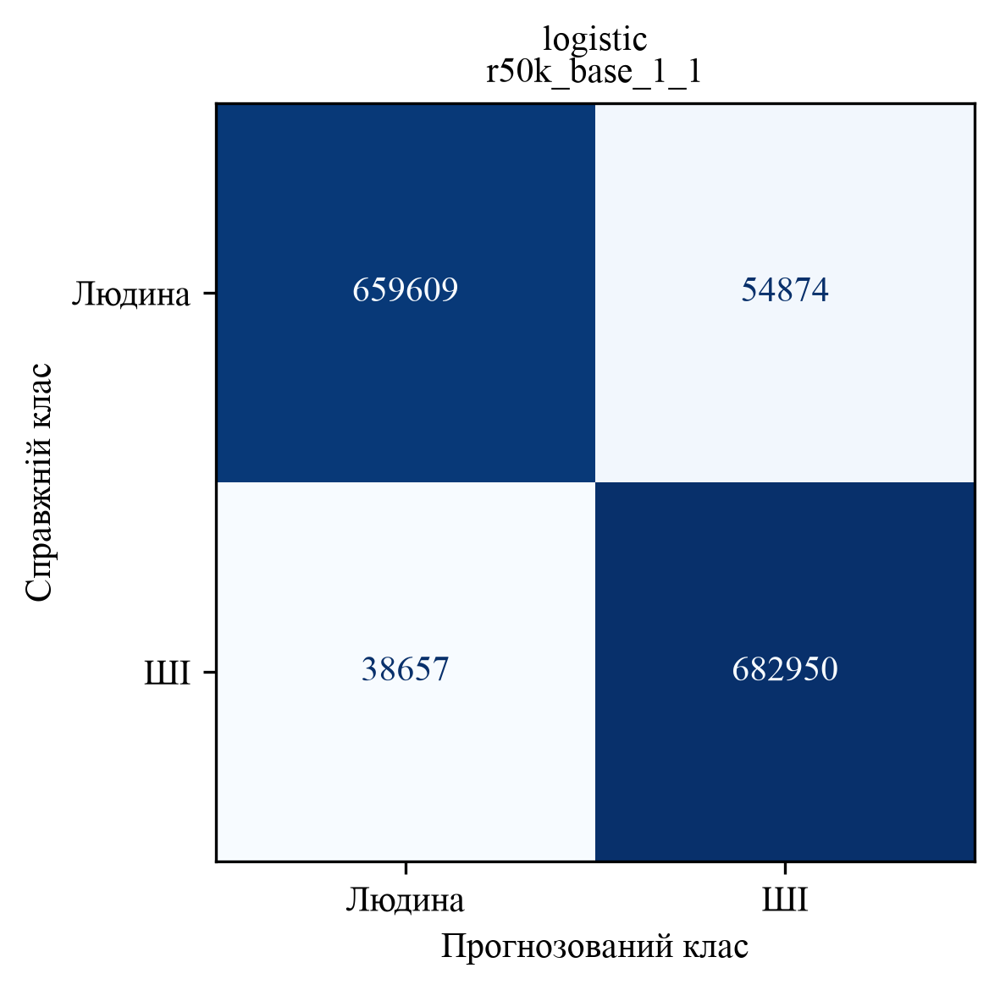


logistic | cl100k_base_1_1 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9580    0.9328    0.9453    714483
          ШІ     0.9352    0.9595    0.9472    721607

    accuracy                         0.9463   1436090
   macro avg     0.9466    0.9462    0.9462   1436090
weighted avg     0.9466    0.9463    0.9462   1436090



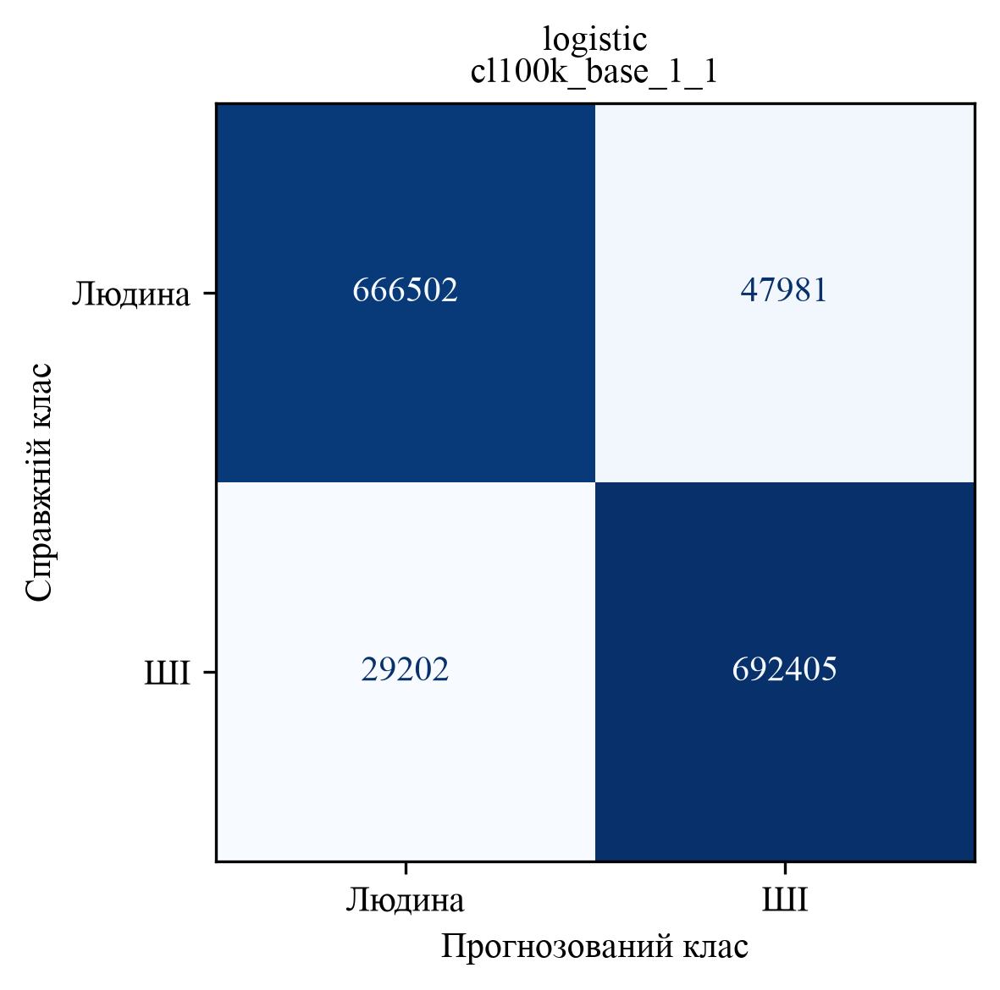


logistic | o200k_base_1_1 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9590    0.9329    0.9458    714483
          ШІ     0.9353    0.9605    0.9477    721607

    accuracy                         0.9468   1436090
   macro avg     0.9471    0.9467    0.9467   1436090
weighted avg     0.9471    0.9468    0.9468   1436090



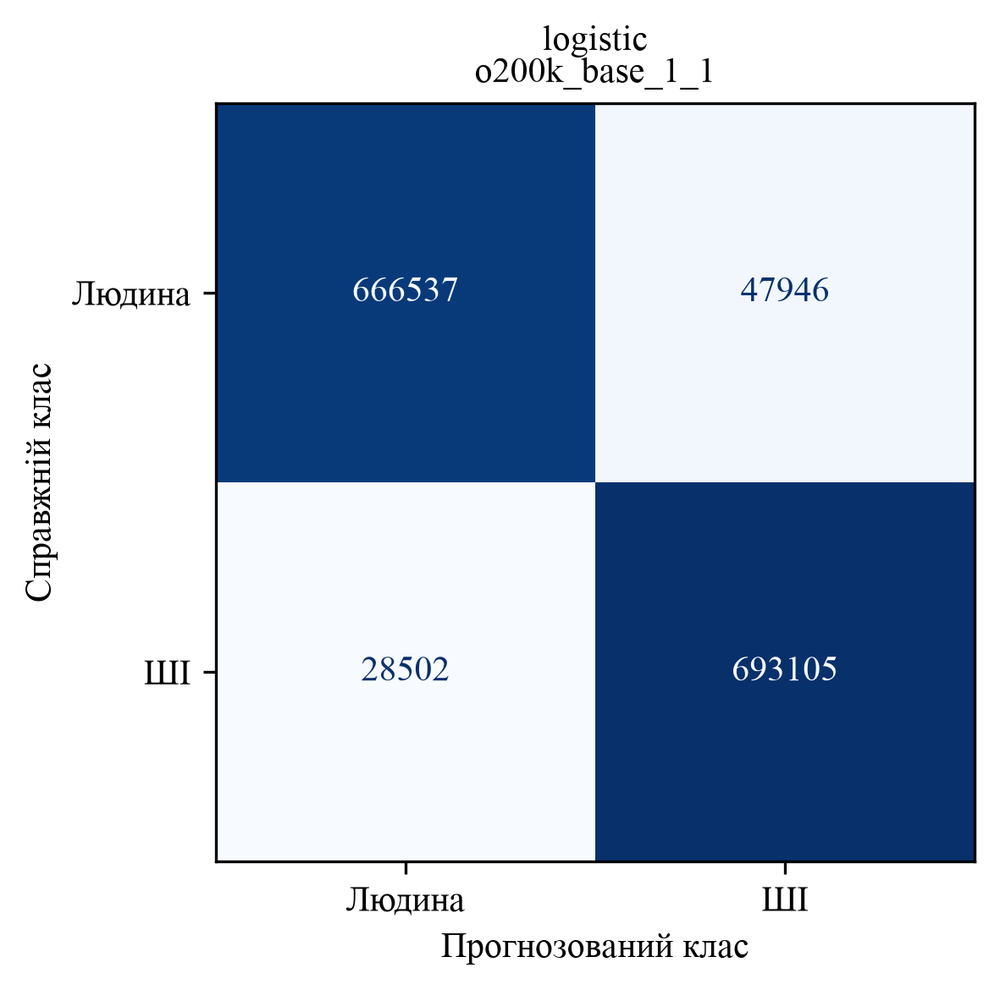


logistic | word_1_3 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9381    0.9127    0.9252    714483
          ШІ     0.9158    0.9403    0.9279    721607

    accuracy                         0.9266   1436090
   macro avg     0.9270    0.9265    0.9266   1436090
weighted avg     0.9269    0.9266    0.9266   1436090



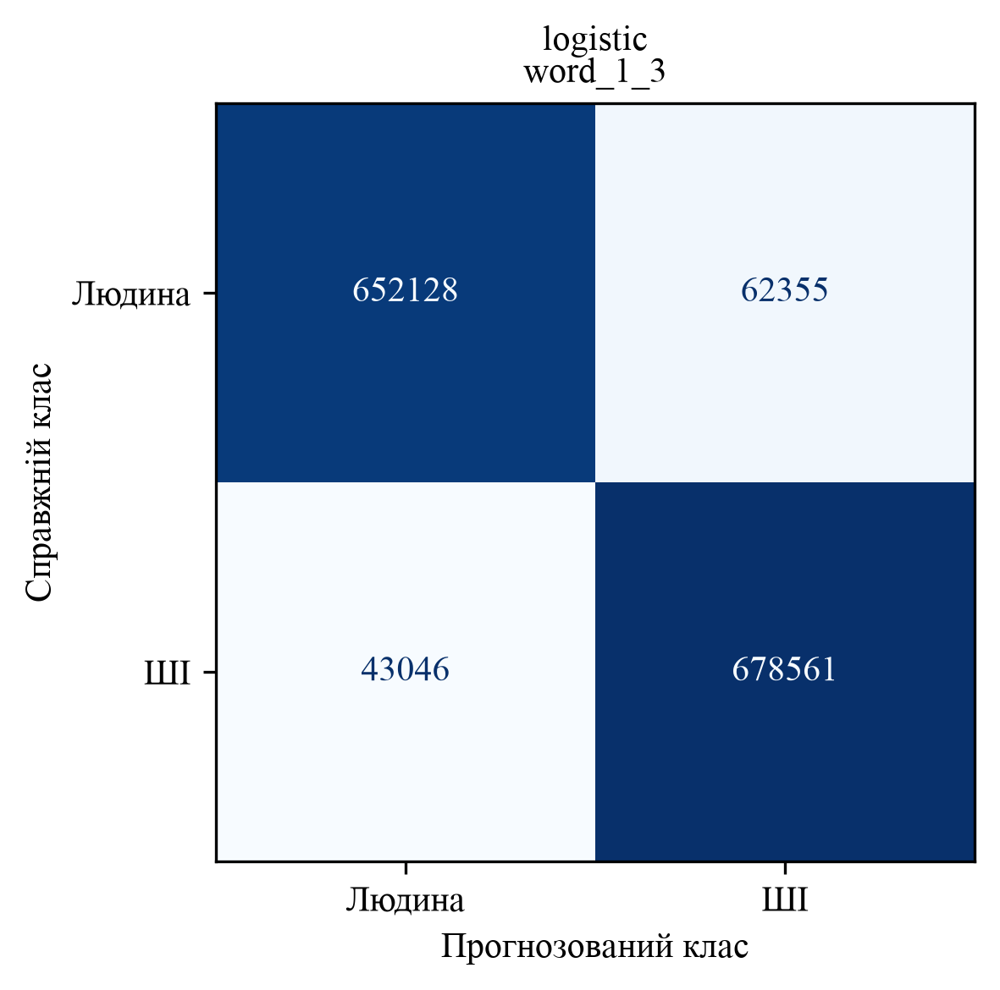


logistic | char_2_5 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9548    0.9262    0.9402    714483
          ШІ     0.9290    0.9566    0.9426    721607

    accuracy                         0.9414   1436090
   macro avg     0.9419    0.9414    0.9414   1436090
weighted avg     0.9418    0.9414    0.9414   1436090



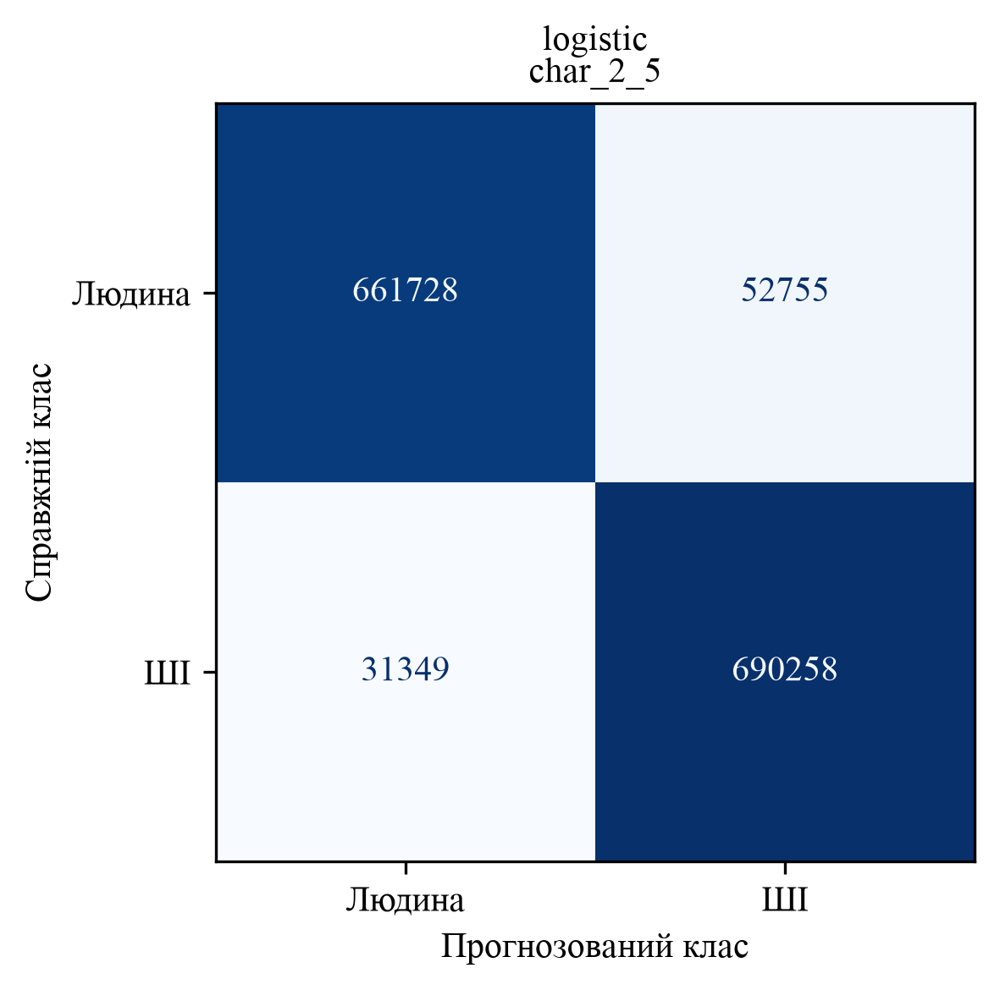


logistic | r50k_base_1_1 + cl100k_base_1_1 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9575    0.9325    0.9448    714483
          ШІ     0.9348    0.9590    0.9468    721607

    accuracy                         0.9458   1436090
   macro avg     0.9462    0.9457    0.9458   1436090
weighted avg     0.9461    0.9458    0.9458   1436090



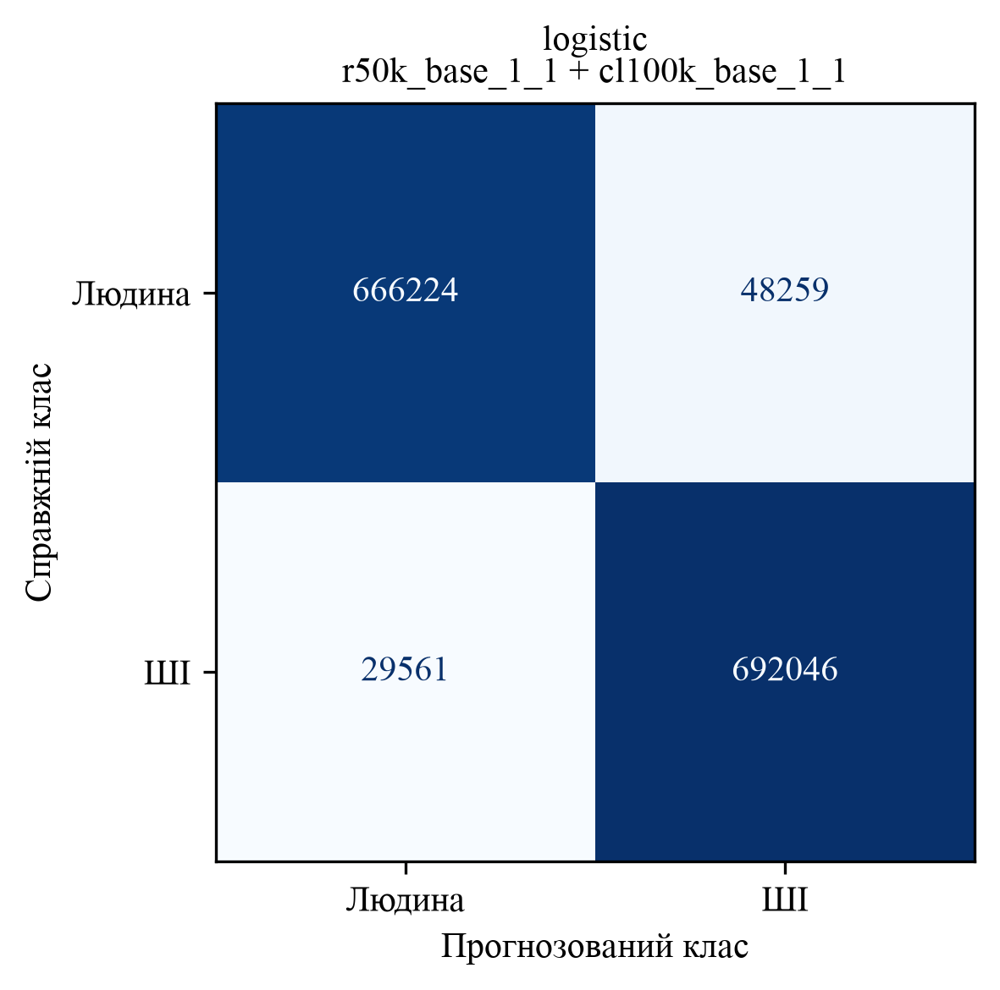


logistic | r50k_base_1_1 + o200k_base_1_1 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9583    0.9328    0.9454    714483
          ШІ     0.9351    0.9598    0.9473    721607

    accuracy                         0.9463   1436090
   macro avg     0.9467    0.9463    0.9463   1436090
weighted avg     0.9467    0.9463    0.9463   1436090



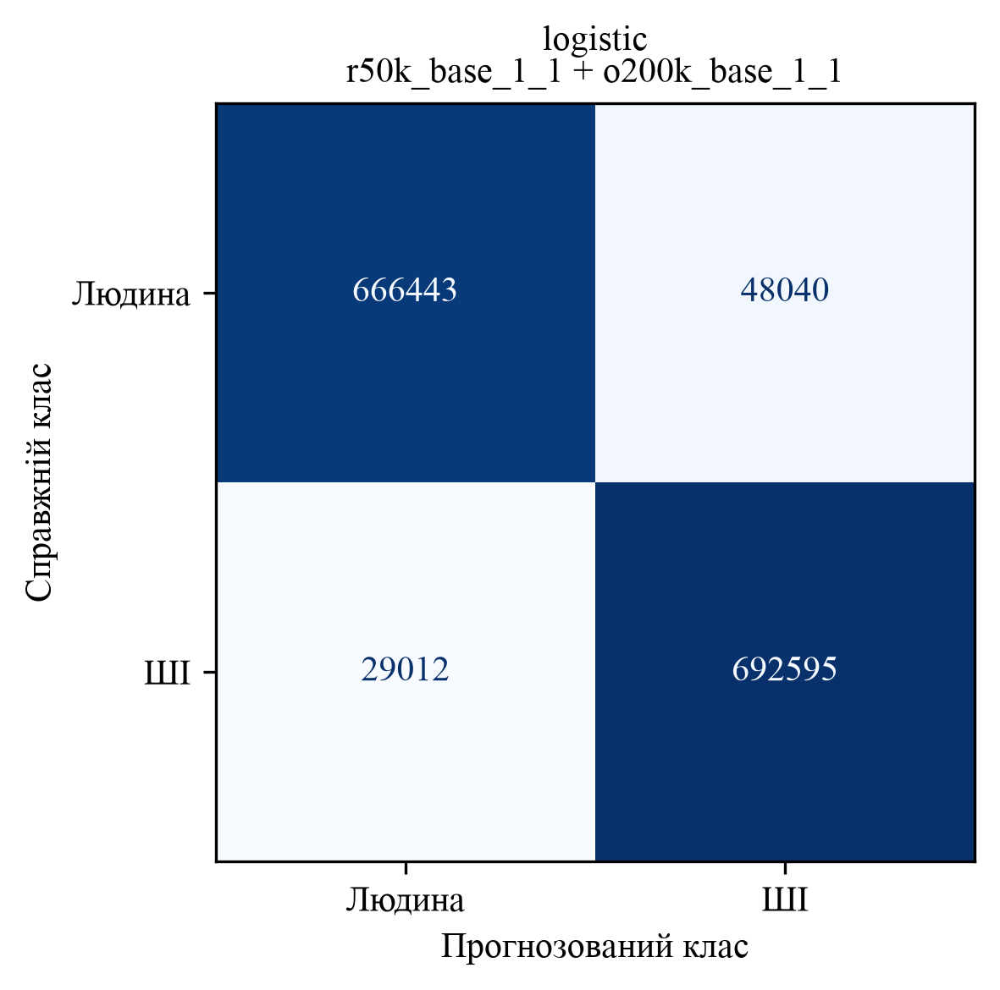


logistic | r50k_base_1_1 + word_1_3 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9498    0.9272    0.9384    714483
          ШІ     0.9296    0.9515    0.9404    721607

    accuracy                         0.9394   1436090
   macro avg     0.9397    0.9393    0.9394   1436090
weighted avg     0.9396    0.9394    0.9394   1436090



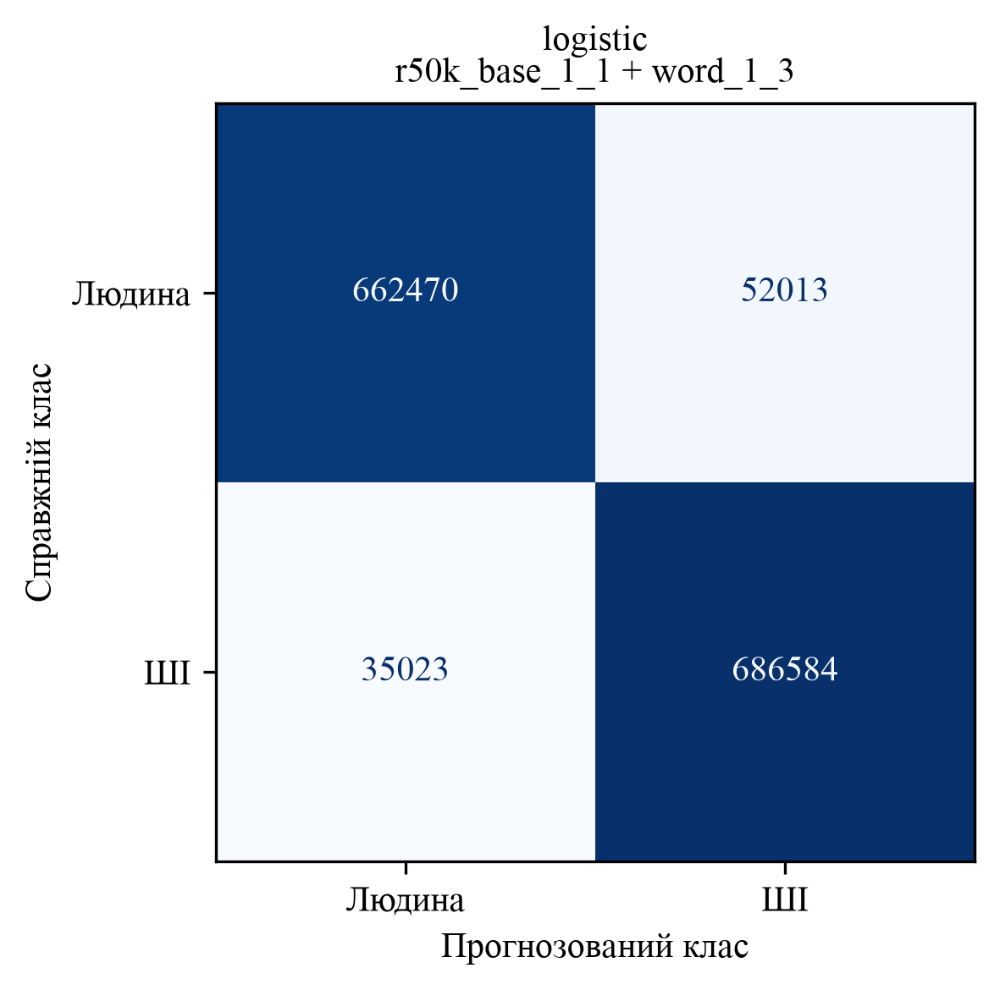


logistic | r50k_base_1_1 + char_2_5 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9563    0.9327    0.9443    714483
          ШІ     0.9350    0.9578    0.9462    721607

    accuracy                         0.9453   1436090
   macro avg     0.9456    0.9452    0.9453   1436090
weighted avg     0.9456    0.9453    0.9453   1436090



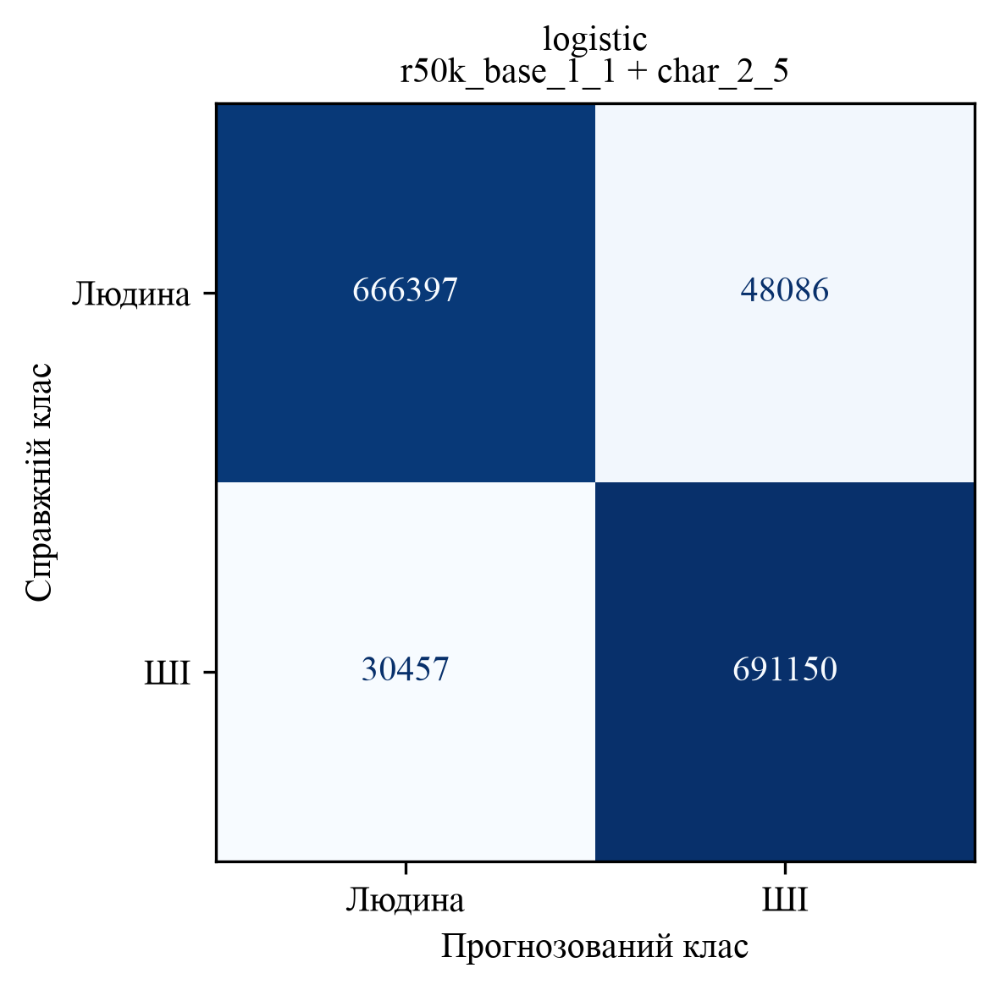


logistic | cl100k_base_1_1 + o200k_base_1_1 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9591    0.9333    0.9460    714483
          ШІ     0.9357    0.9605    0.9480    721607

    accuracy                         0.9470   1436090
   macro avg     0.9474    0.9469    0.9470   1436090
weighted avg     0.9473    0.9470    0.9470   1436090



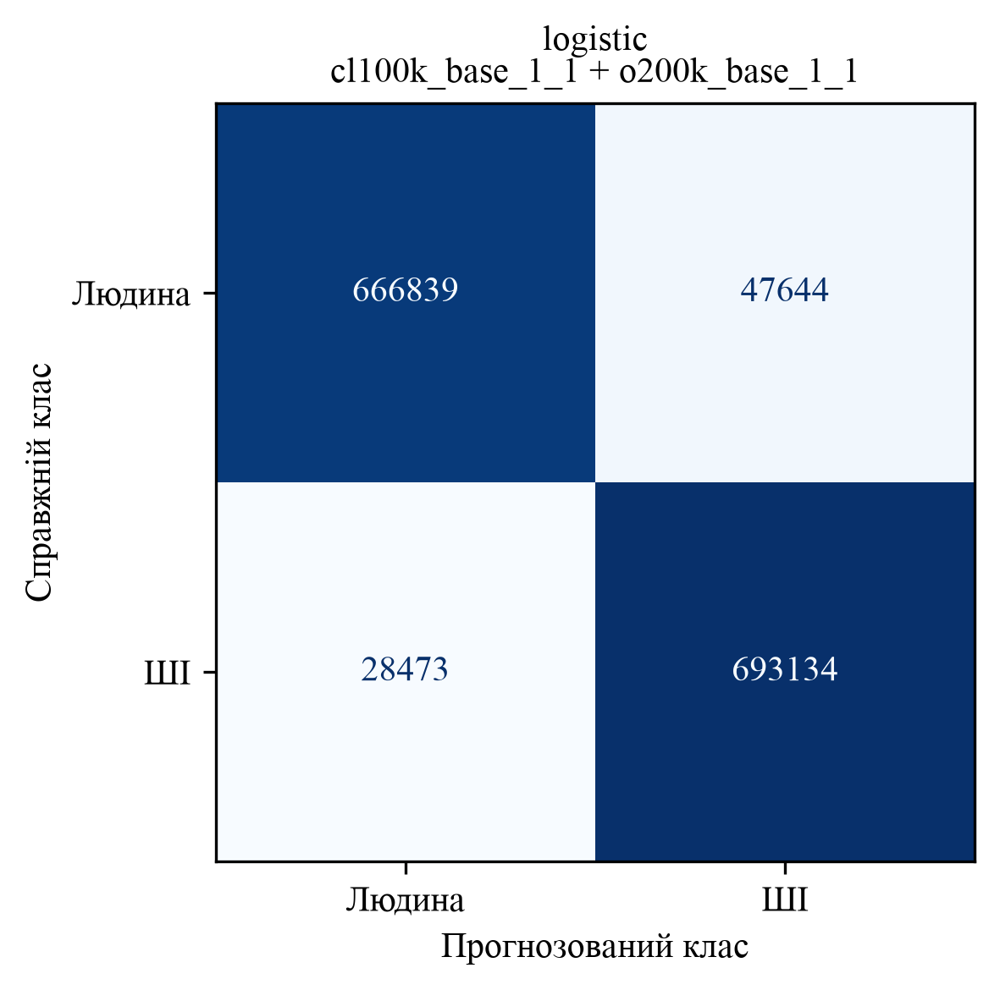


logistic | cl100k_base_1_1 + word_1_3 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9594    0.9338    0.9464    714483
          ШІ     0.9362    0.9609    0.9483    721607

    accuracy                         0.9474   1436090
   macro avg     0.9478    0.9473    0.9474   1436090
weighted avg     0.9477    0.9474    0.9474   1436090



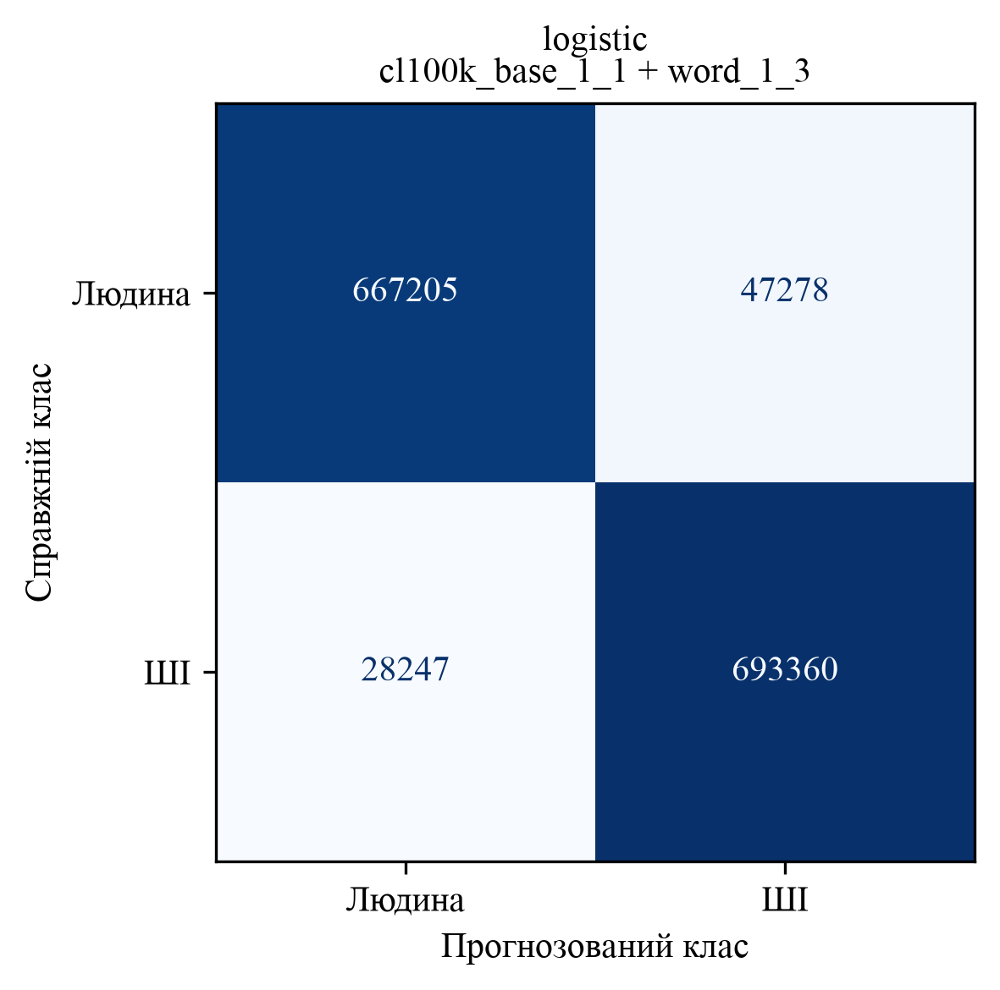


logistic | cl100k_base_1_1 + char_2_5 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9626    0.9348    0.9485    714483
          ШІ     0.9372    0.9641    0.9505    721607

    accuracy                         0.9495   1436090
   macro avg     0.9499    0.9494    0.9495   1436090
weighted avg     0.9499    0.9495    0.9495   1436090



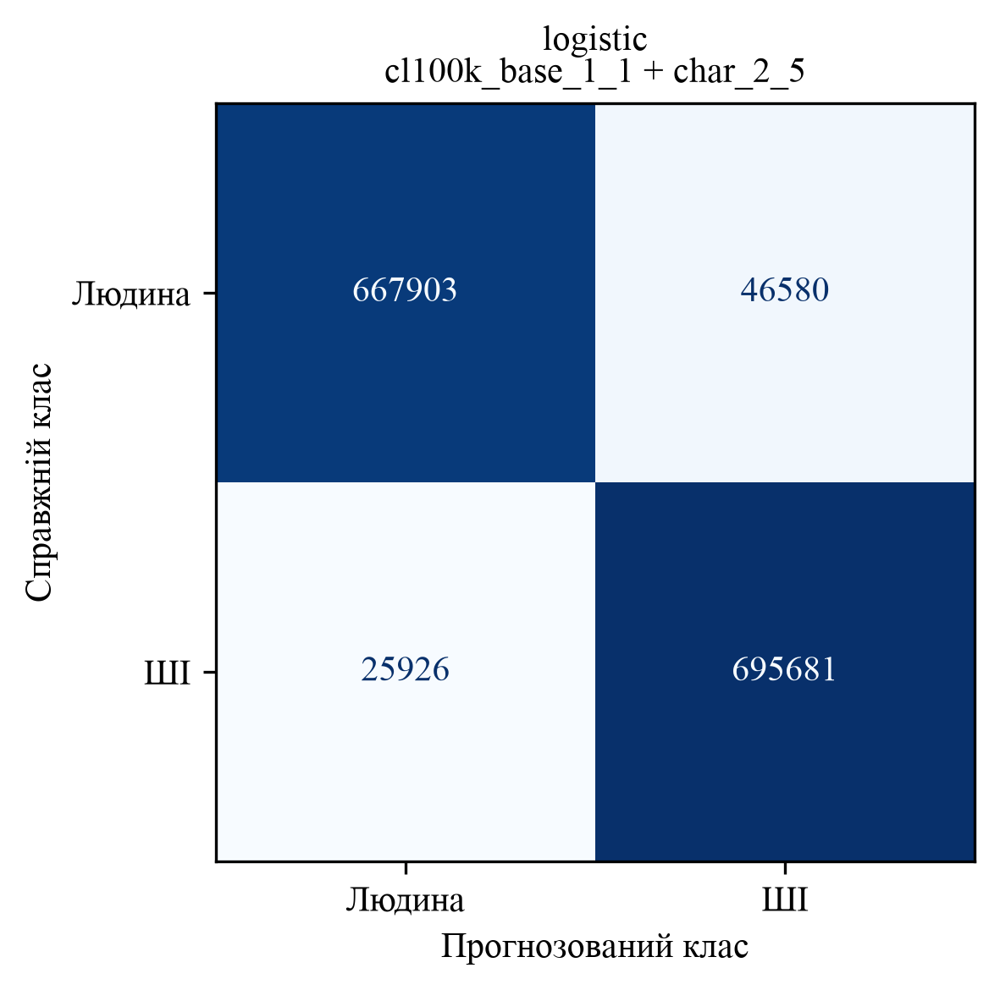


logistic | o200k_base_1_1 + word_1_3 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9598    0.9337    0.9466    714483
          ШІ     0.9361    0.9613    0.9485    721607

    accuracy                         0.9476   1436090
   macro avg     0.9479    0.9475    0.9475   1436090
weighted avg     0.9479    0.9476    0.9475   1436090



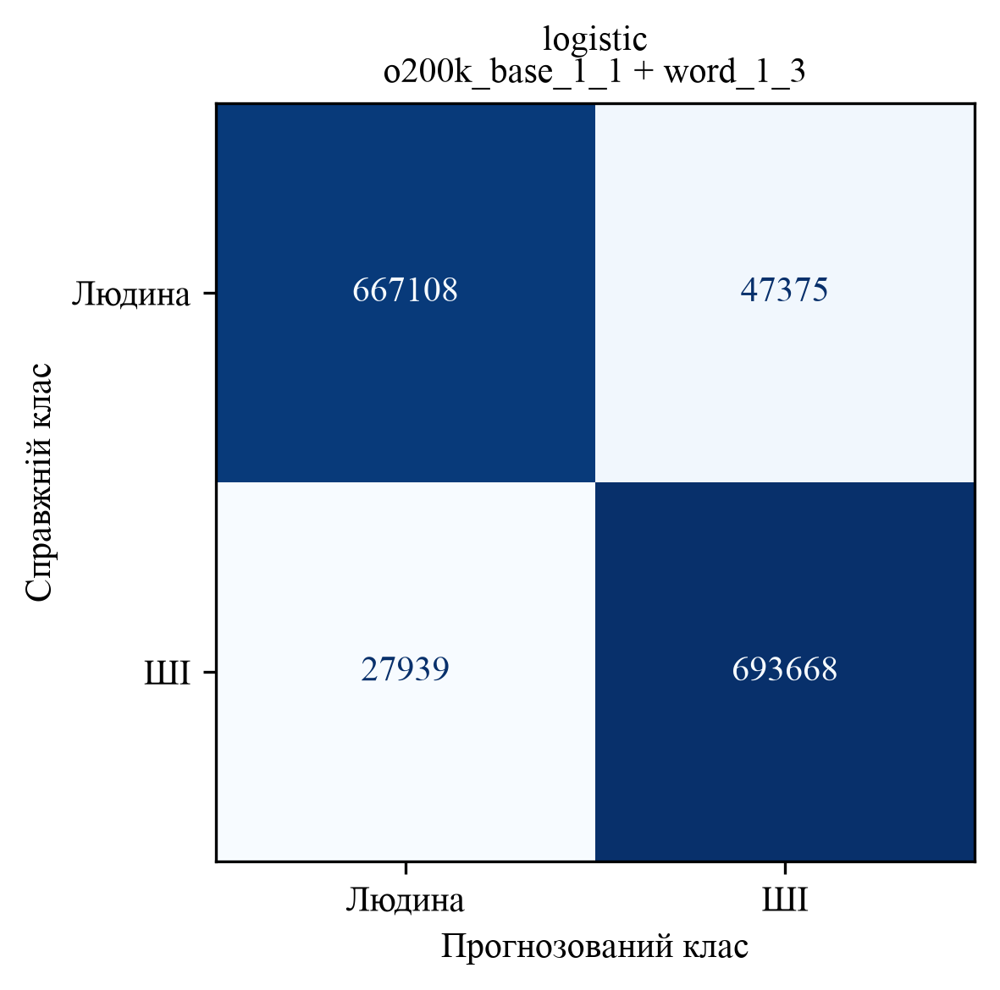


logistic | o200k_base_1_1 + char_2_5 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9631    0.9347    0.9487    714483
          ШІ     0.9371    0.9646    0.9507    721607

    accuracy                         0.9497   1436090
   macro avg     0.9501    0.9496    0.9497   1436090
weighted avg     0.9501    0.9497    0.9497   1436090



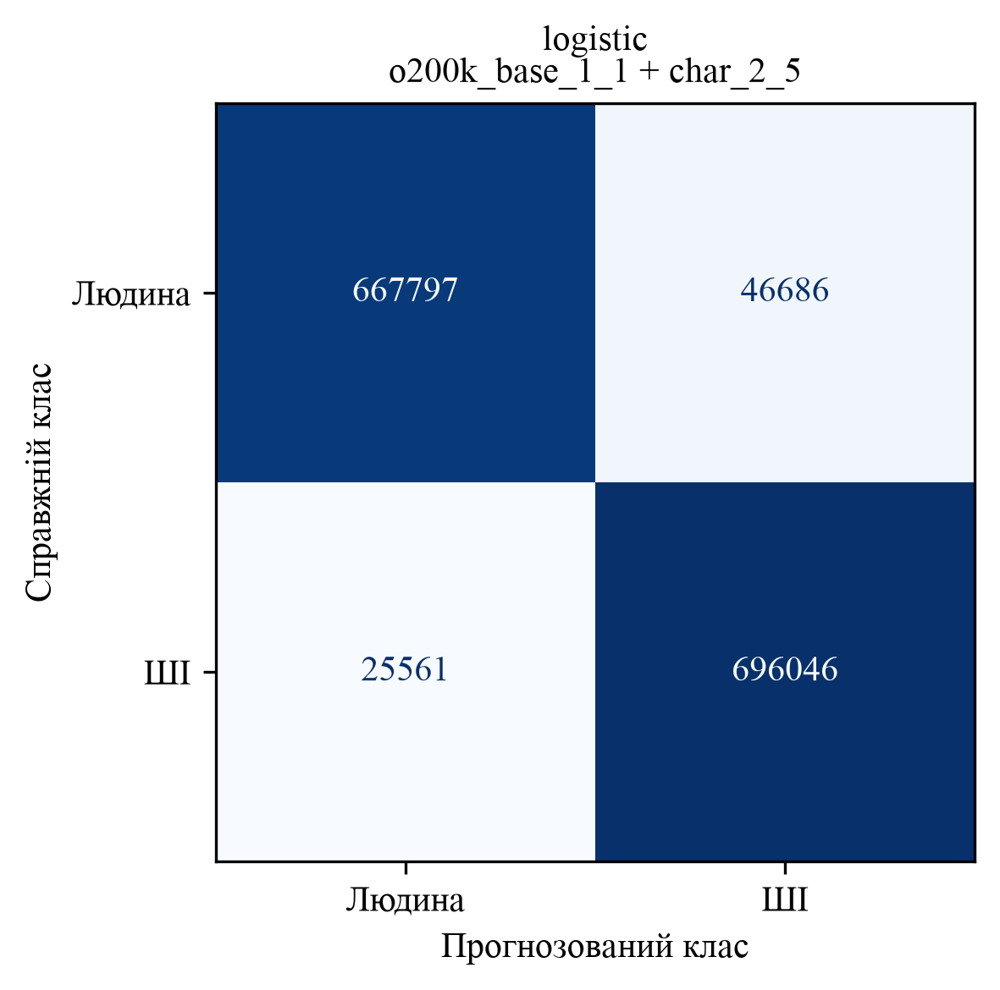


logistic | word_1_3 + char_2_5 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9549    0.9265    0.9405    714483
          ШІ     0.9293    0.9567    0.9428    721607

    accuracy                         0.9416   1436090
   macro avg     0.9421    0.9416    0.9416   1436090
weighted avg     0.9420    0.9416    0.9416   1436090



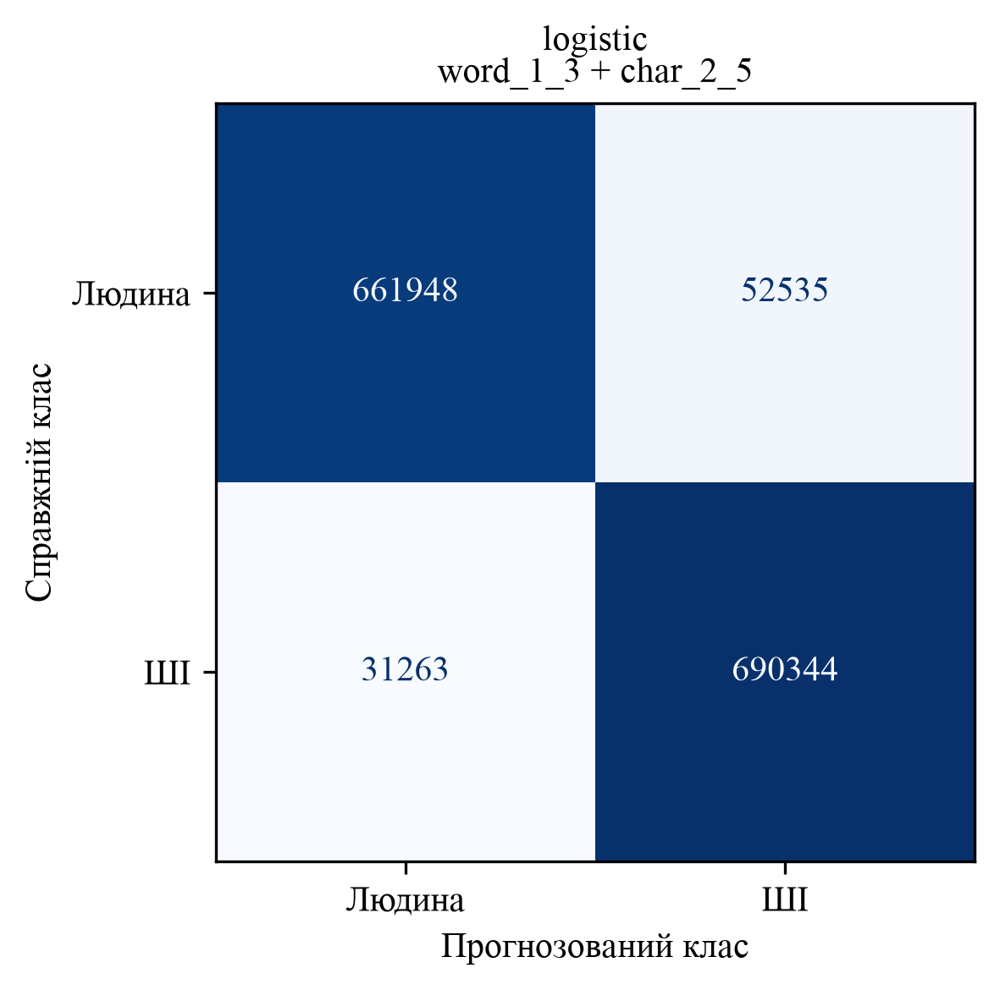

,algorithm,variant,epoch,Accuracy,Precision,Recall,F1 Score,n_features,model_file
13,logistic,o200k_base_1_1__char_2_5,2,0.9497,0.9371,0.9646,0.9507,200000,/home/artem/diploma/classifier_results_accurac...
11,logistic,cl100k_base_1_1__char_2_5,2,0.9495,0.9372,0.9641,0.9505,183175,/home/artem/diploma/classifier_results_accurac...
12,logistic,o200k_base_1_1__word_1_3,2,0.9476,0.9361,0.9613,0.9485,200000,/home/artem/diploma/classifier_results_accurac...
10,logistic,cl100k_base_1_1__word_1_3,2,0.9474,0.9362,0.9609,0.9483,183175,/home/artem/diploma/classifier_results_accurac...
9,logistic,cl100k_base_1_1__o200k_base_1_1,2,0.9470,0.9357,0.9605,0.9480,183175,/home/artem/diploma/classifier_results_accurac...
2,logistic,o200k_base_1_1,2,0.9468,0.9353,0.9605,0.9477,100000,/home/artem/diploma/classifier_results_accurac...
6,logistic,r50k_base_1_1__o200k_base_1_1,2,0.9463,0.9351,0.9598,0.9473,149996,/home/artem/diploma/classifier_results_accurac...
1,logistic,cl100k_base_1_1,2,0.9463,0.9352,0.9595,0.9472,83175,/home/artem/diploma/classifier_results_accurac...
5,logistic,r50k_base_1_1__cl100k_base_1_1,2,0.9458,0.9348,0.9590,0.9468,133171,/home/artem/diploma/classifier_results_accurac...
8,logistic,r50k_base_1_1__char_2_5,2,0.9453,0.9350,0.9578,0.9462,149996,/home/artem/diploma/classifier_results_accurac...


In [11]:
logistic_metrics = evaluate_best_models("logistic")
display(logistic_metrics.round(4))

## 9. Лінійний SVM: 5 представлень і 10 пар

Використовуємо ті самі представлення, пари, епохи та порядок батчів.
Змінюємо функцію втрат на `hinge`.

In [12]:
svm_results = train_models("svm", loss="hinge")
display(svm_results)

svm: епоха 1/3
Train: батч 10/230
Train: батч 20/230
Train: батч 30/230
Train: батч 40/230
Train: батч 50/230
Train: батч 60/230
Train: батч 70/230
Train: батч 80/230
Train: батч 90/230
Train: батч 100/230
Train: батч 110/230
Train: батч 120/230
Train: батч 130/230
Train: батч 140/230
Train: батч 150/230
Train: батч 160/230
Train: батч 170/230
Train: батч 180/230
Train: батч 190/230
Train: батч 200/230
Train: батч 210/230
Train: батч 220/230
Train: батч 230/230
Val: батч 5/29
Val: батч 10/29
Val: батч 15/29
Val: батч 20/29
Val: батч 25/29
Val: батч 29/29
Найкраща accuracy після епохи: 0.960521
svm: епоха 2/3
Train: батч 10/230
Train: батч 20/230
Train: батч 30/230
Train: батч 40/230
Train: батч 50/230
Train: батч 60/230
Train: батч 70/230
Train: батч 80/230
Train: батч 90/230
Train: батч 100/230
Train: батч 110/230
Train: батч 120/230
Train: батч 130/230
Train: батч 140/230
Train: батч 150/230
Train: батч 160/230
Train: батч 170/230
Train: батч 180/230
Train: батч 190/230
Train: батч 2

,algorithm,variant,epoch,accuracy,n_features,model_file
13,svm,o200k_base_1_1__char_2_5,2,0.960638,200000,/home/artem/diploma/classifier_results_accurac...
11,svm,cl100k_base_1_1__char_2_5,2,0.960189,183175,/home/artem/diploma/classifier_results_accurac...
12,svm,o200k_base_1_1__word_1_3,2,0.959352,200000,/home/artem/diploma/classifier_results_accurac...
10,svm,cl100k_base_1_1__word_1_3,2,0.959182,183175,/home/artem/diploma/classifier_results_accurac...
8,svm,r50k_base_1_1__char_2_5,2,0.957136,149996,/home/artem/diploma/classifier_results_accurac...
6,svm,r50k_base_1_1__o200k_base_1_1,2,0.957020,149996,/home/artem/diploma/classifier_results_accurac...
9,svm,cl100k_base_1_1__o200k_base_1_1,2,0.956584,183175,/home/artem/diploma/classifier_results_accurac...
2,svm,o200k_base_1_1,2,0.956312,100000,/home/artem/diploma/classifier_results_accurac...
5,svm,r50k_base_1_1__cl100k_base_1_1,2,0.955769,133171,/home/artem/diploma/classifier_results_accurac...
1,svm,cl100k_base_1_1,2,0.955124,83175,/home/artem/diploma/classifier_results_accurac...


### SVM: звіти та матриці помилок усіх 15 варіантів

Виводимо звіти найкращих епох, потім таблицю чотирьох метрик.

svm: оцінювання val 1/29
svm: оцінювання val 2/29
svm: оцінювання val 3/29
svm: оцінювання val 4/29
svm: оцінювання val 5/29
svm: оцінювання val 6/29
svm: оцінювання val 7/29
svm: оцінювання val 8/29
svm: оцінювання val 9/29
svm: оцінювання val 10/29
svm: оцінювання val 11/29
svm: оцінювання val 12/29
svm: оцінювання val 13/29
svm: оцінювання val 14/29
svm: оцінювання val 15/29
svm: оцінювання val 16/29
svm: оцінювання val 17/29
svm: оцінювання val 18/29
svm: оцінювання val 19/29
svm: оцінювання val 20/29
svm: оцінювання val 21/29
svm: оцінювання val 22/29
svm: оцінювання val 23/29
svm: оцінювання val 24/29
svm: оцінювання val 25/29
svm: оцінювання val 26/29
svm: оцінювання val 27/29
svm: оцінювання val 28/29
svm: оцінювання val 29/29

svm | r50k_base_1_1 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9582    0.9305    0.9441    714483
          ШІ     0.9331    0.9598    0.9463    721607

    accuracy                         0.9452   1436090
   mac

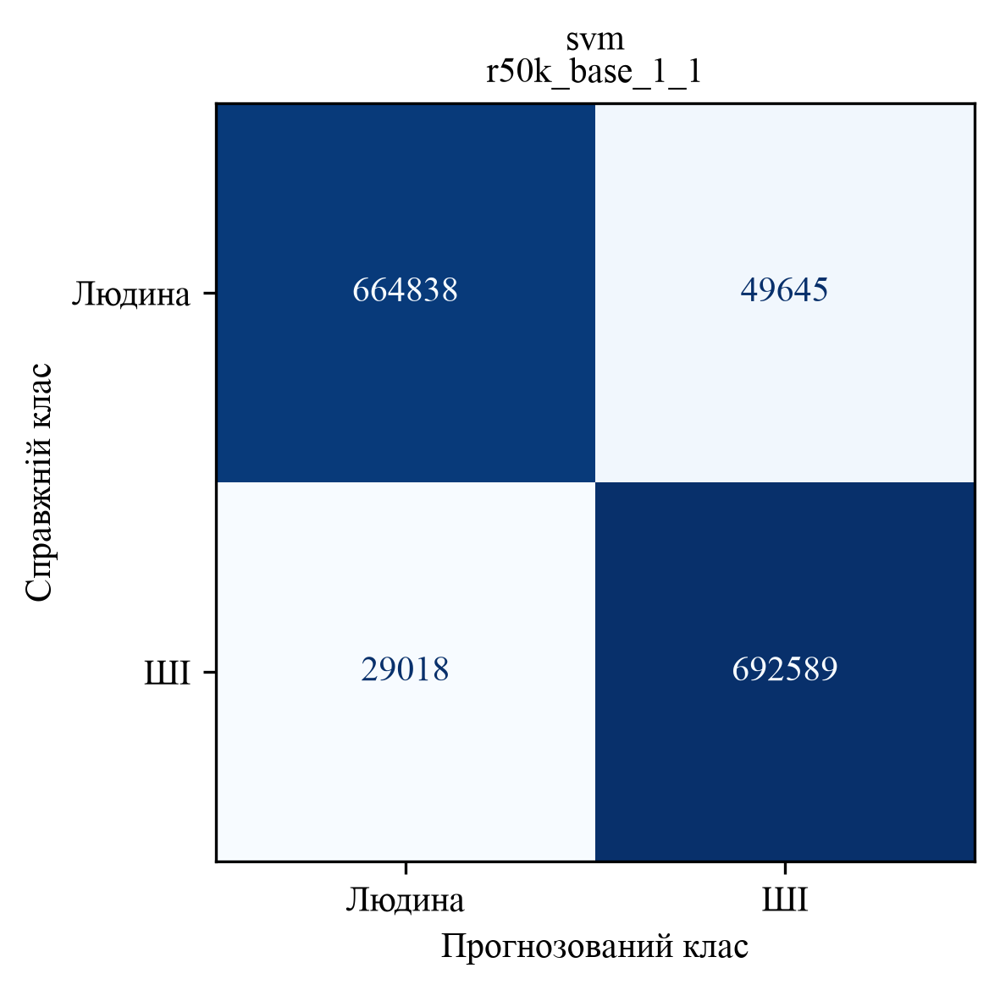


svm | cl100k_base_1_1 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9692    0.9397    0.9542    714483
          ШІ     0.9420    0.9704    0.9560    721607

    accuracy                         0.9551   1436090
   macro avg     0.9556    0.9550    0.9551   1436090
weighted avg     0.9555    0.9551    0.9551   1436090



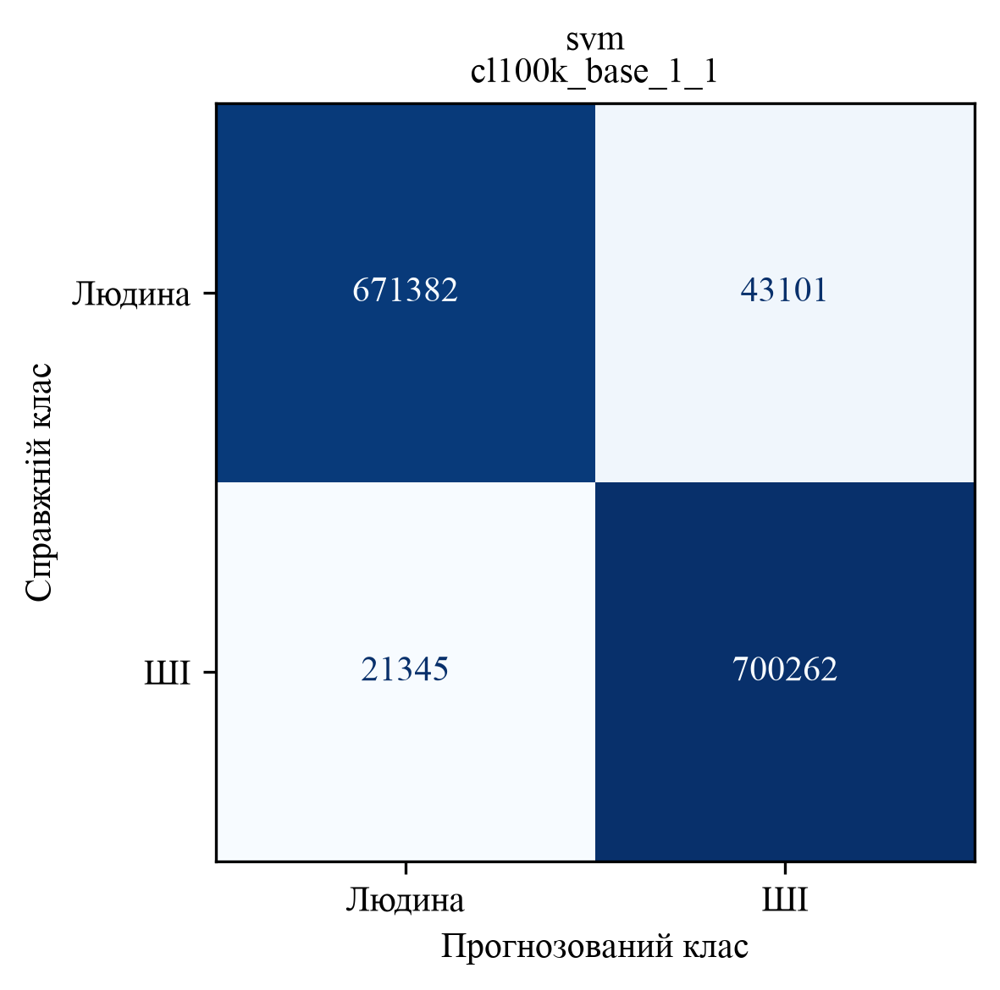


svm | o200k_base_1_1 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9706    0.9407    0.9554    714483
          ШІ     0.9430    0.9718    0.9572    721607

    accuracy                         0.9563   1436090
   macro avg     0.9568    0.9562    0.9563   1436090
weighted avg     0.9567    0.9563    0.9563   1436090



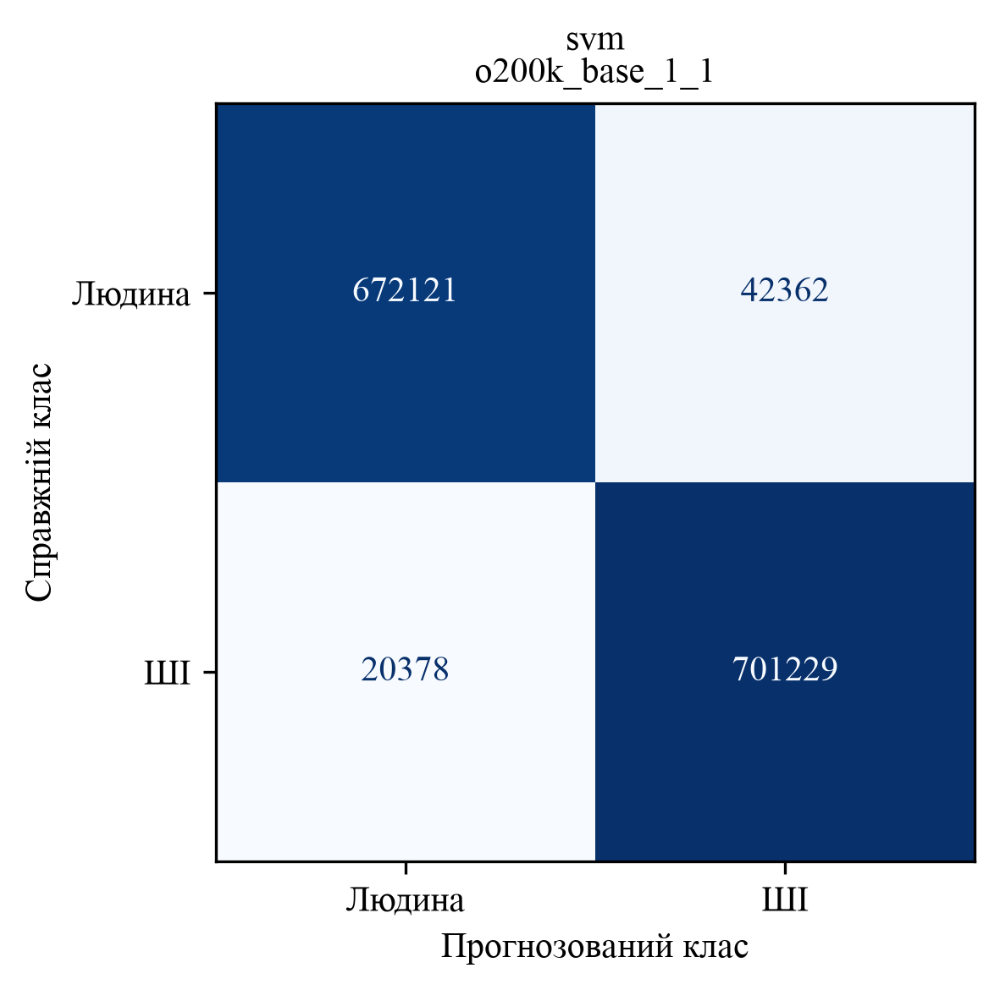


svm | word_1_3 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9552    0.9213    0.9379    714483
          ШІ     0.9247    0.9572    0.9407    721607

    accuracy                         0.9393   1436090
   macro avg     0.9399    0.9392    0.9393   1436090
weighted avg     0.9399    0.9393    0.9393   1436090



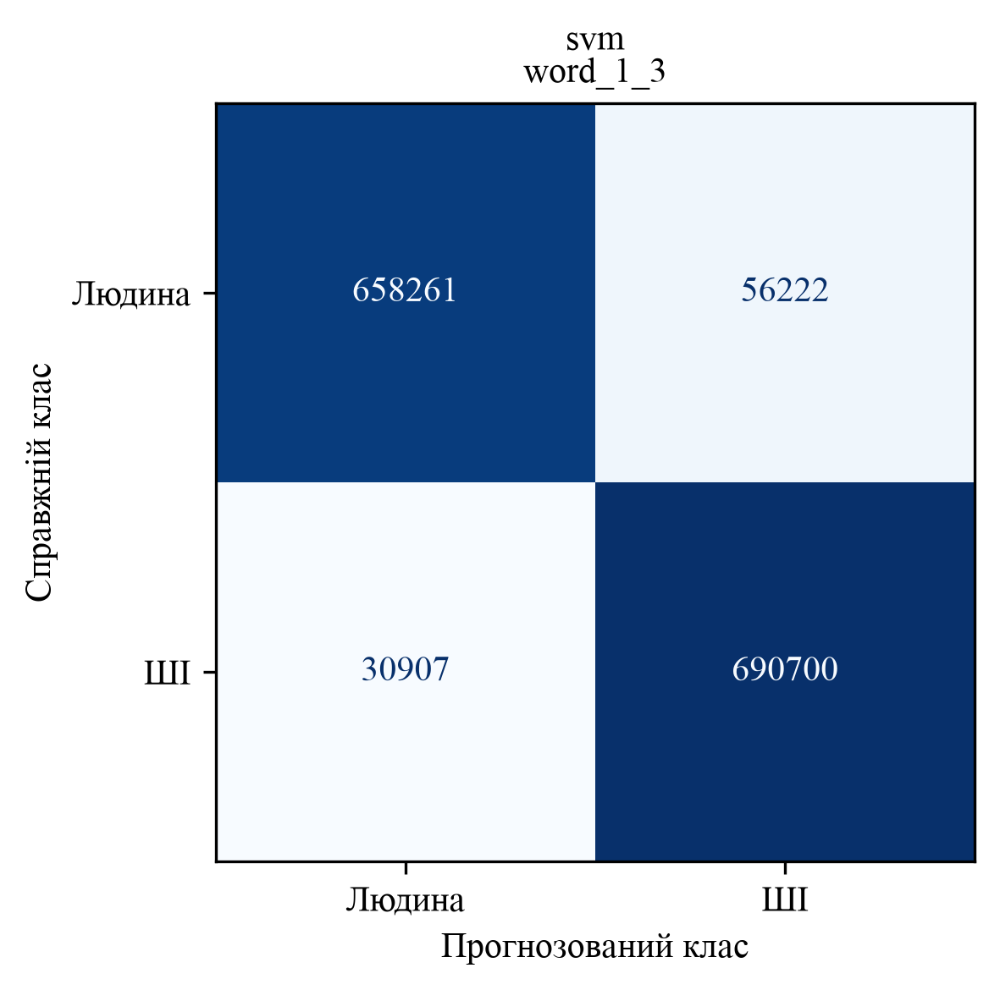


svm | char_2_5 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9673    0.9356    0.9512    714483
          ШІ     0.9382    0.9687    0.9532    721607

    accuracy                         0.9522   1436090
   macro avg     0.9527    0.9521    0.9522   1436090
weighted avg     0.9527    0.9522    0.9522   1436090



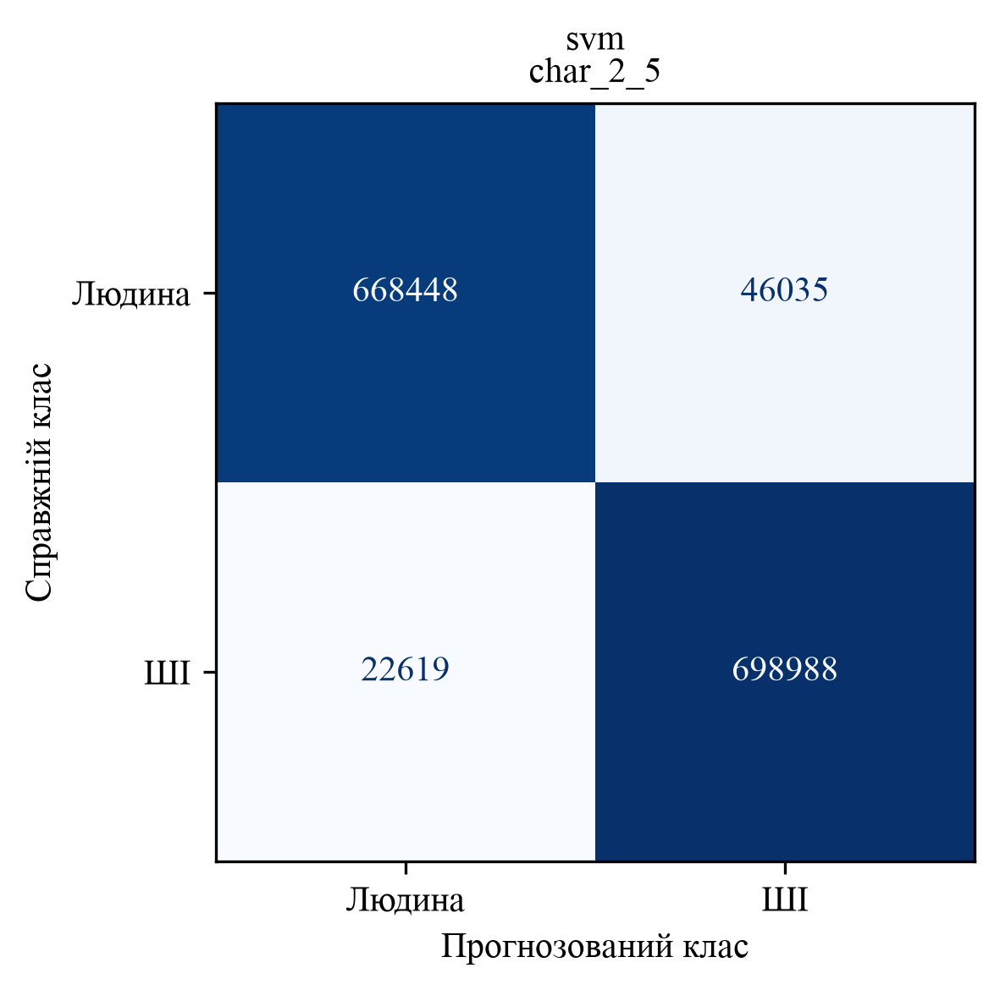


svm | r50k_base_1_1 + cl100k_base_1_1 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9698    0.9404    0.9549    714483
          ШІ     0.9427    0.9710    0.9566    721607

    accuracy                         0.9558   1436090
   macro avg     0.9562    0.9557    0.9558   1436090
weighted avg     0.9562    0.9558    0.9558   1436090



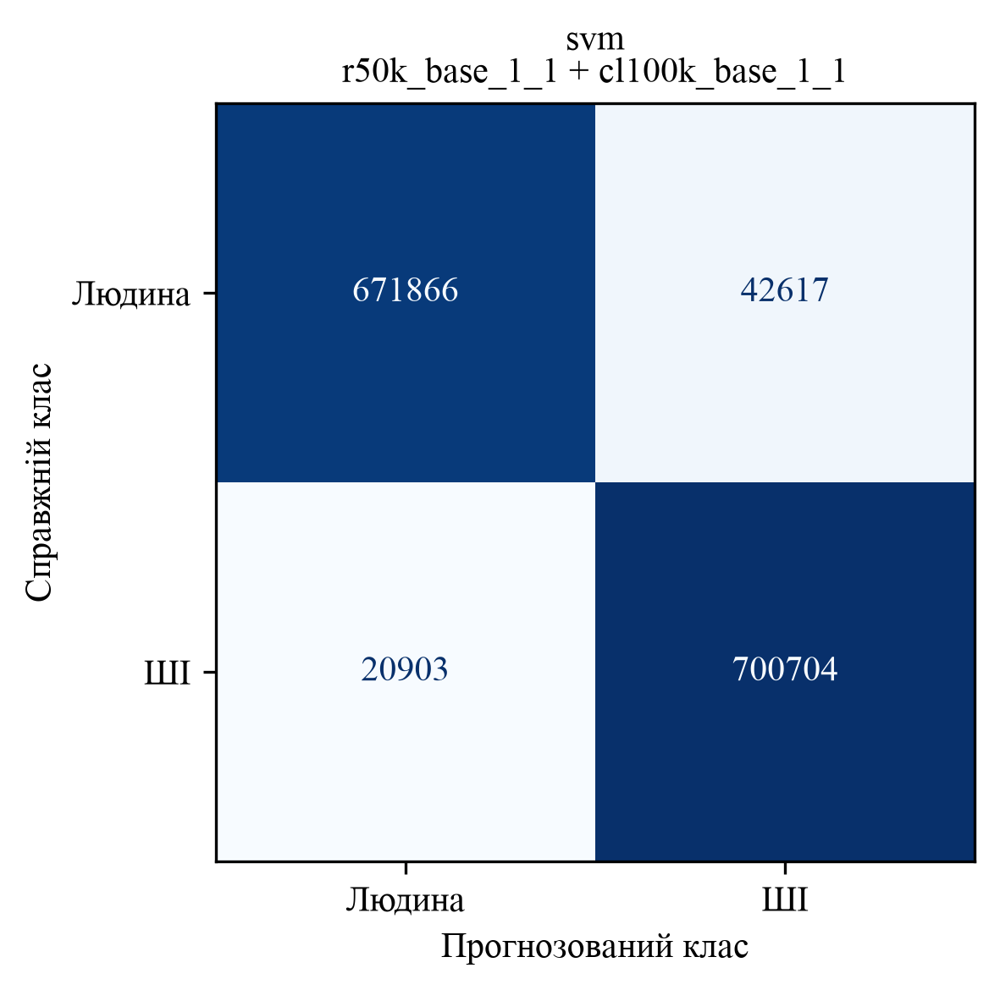


svm | r50k_base_1_1 + o200k_base_1_1 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9710    0.9417    0.9561    714483
          ШІ     0.9440    0.9721    0.9579    721607

    accuracy                         0.9570   1436090
   macro avg     0.9575    0.9569    0.9570   1436090
weighted avg     0.9574    0.9570    0.9570   1436090



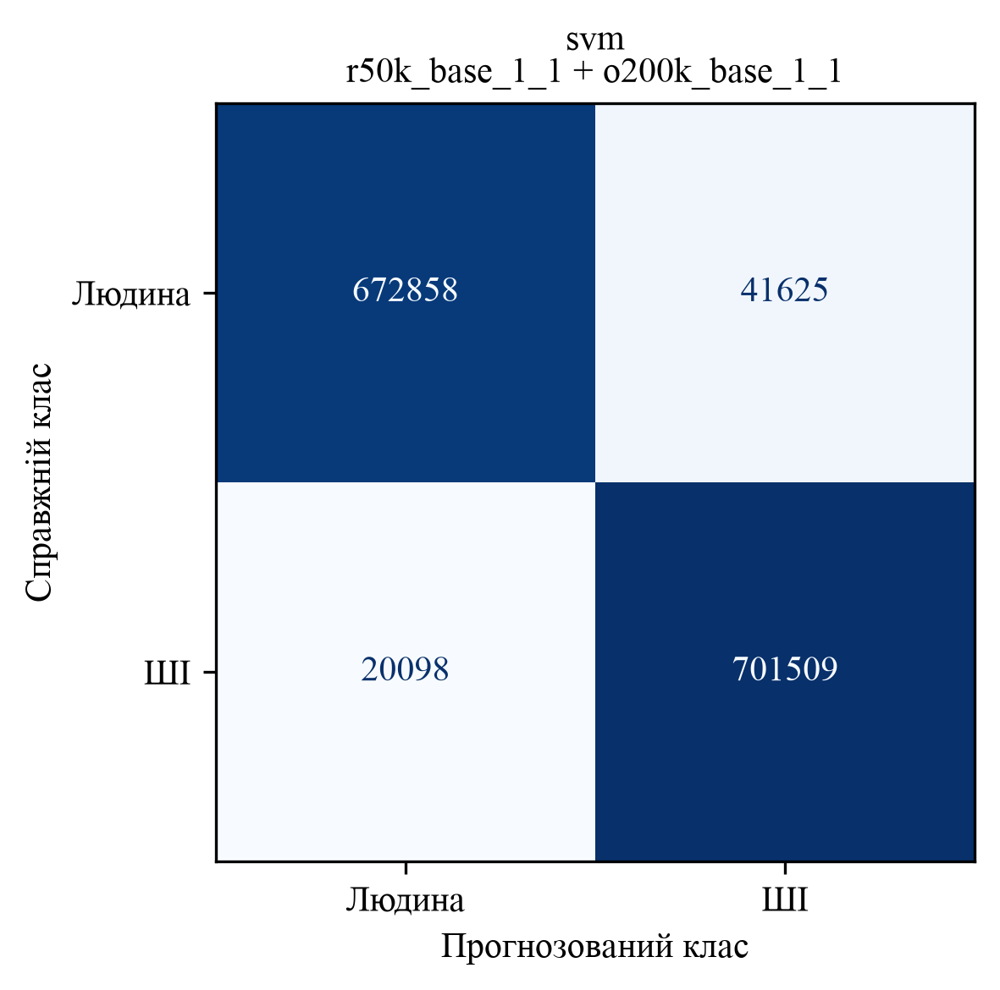


svm | r50k_base_1_1 + word_1_3 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9656    0.9378    0.9515    714483
          ШІ     0.9401    0.9669    0.9533    721607

    accuracy                         0.9524   1436090
   macro avg     0.9528    0.9523    0.9524   1436090
weighted avg     0.9528    0.9524    0.9524   1436090



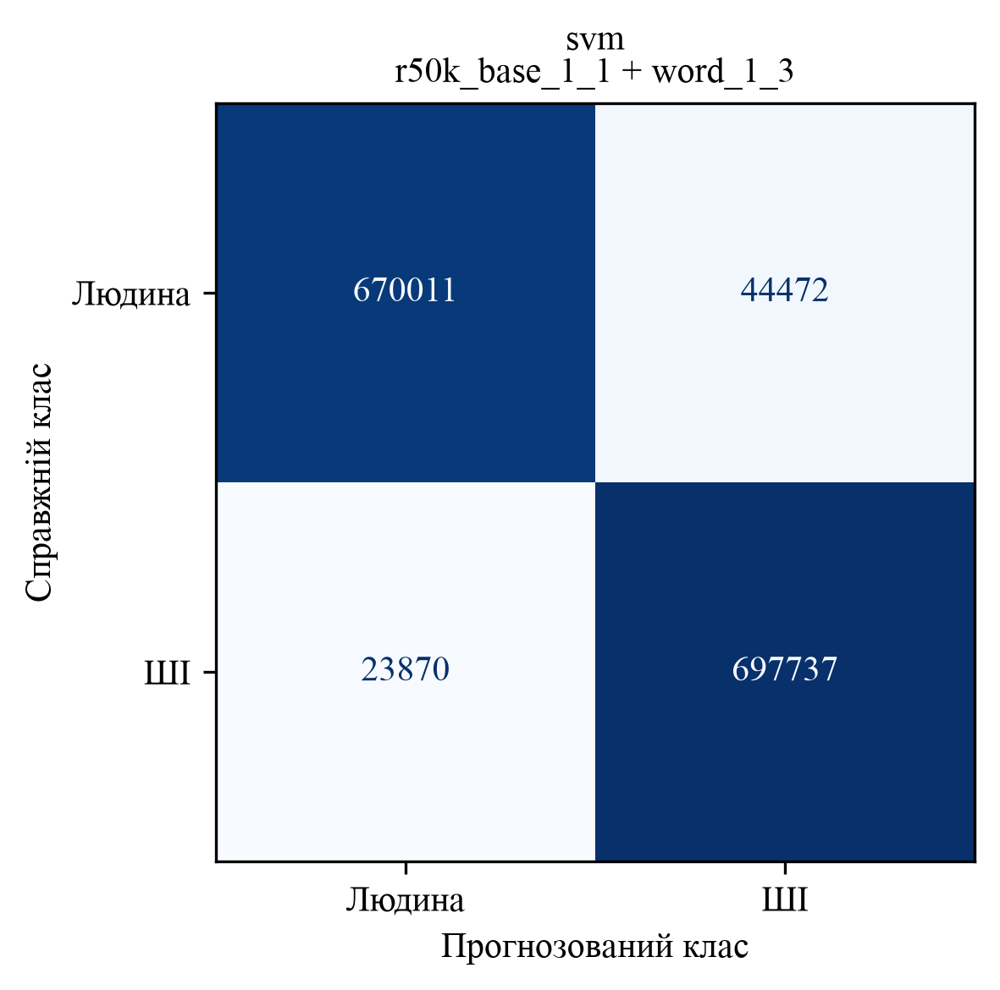


svm | r50k_base_1_1 + char_2_5 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9700    0.9430    0.9563    714483
          ШІ     0.9451    0.9711    0.9579    721607

    accuracy                         0.9571   1436090
   macro avg     0.9575    0.9571    0.9571   1436090
weighted avg     0.9575    0.9571    0.9571   1436090



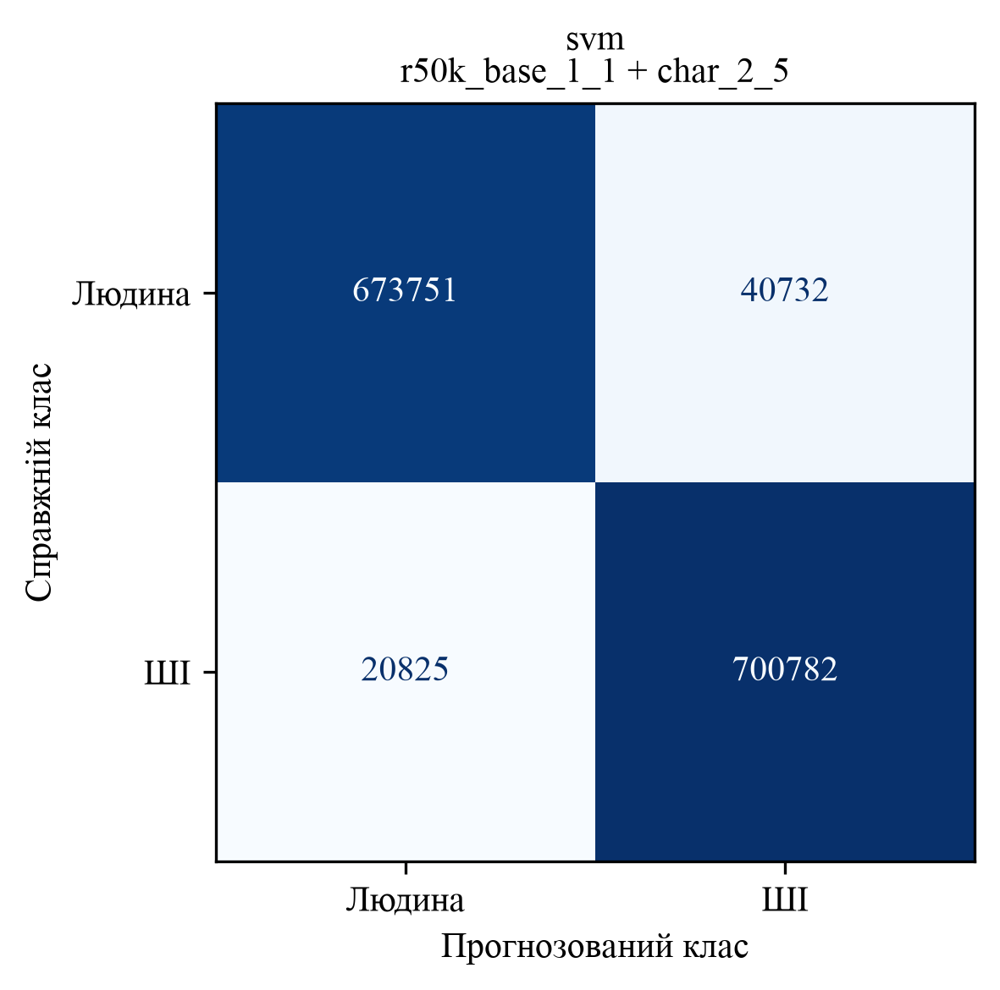


svm | cl100k_base_1_1 + o200k_base_1_1 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9707    0.9412    0.9557    714483
          ШІ     0.9434    0.9719    0.9574    721607

    accuracy                         0.9566   1436090
   macro avg     0.9571    0.9565    0.9566   1436090
weighted avg     0.9570    0.9566    0.9566   1436090



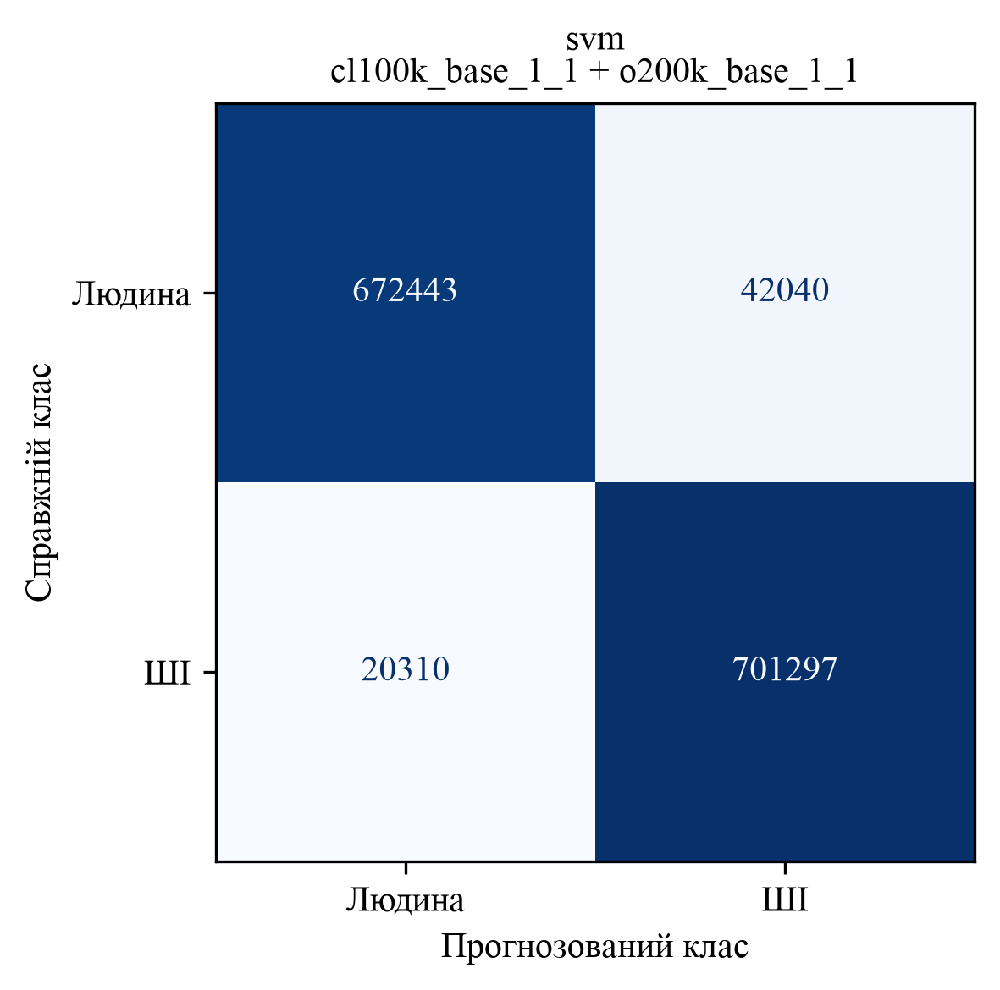


svm | cl100k_base_1_1 + word_1_3 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9734    0.9437    0.9583    714483
          ШІ     0.9459    0.9745    0.9600    721607

    accuracy                         0.9592   1436090
   macro avg     0.9597    0.9591    0.9592   1436090
weighted avg     0.9596    0.9592    0.9592   1436090



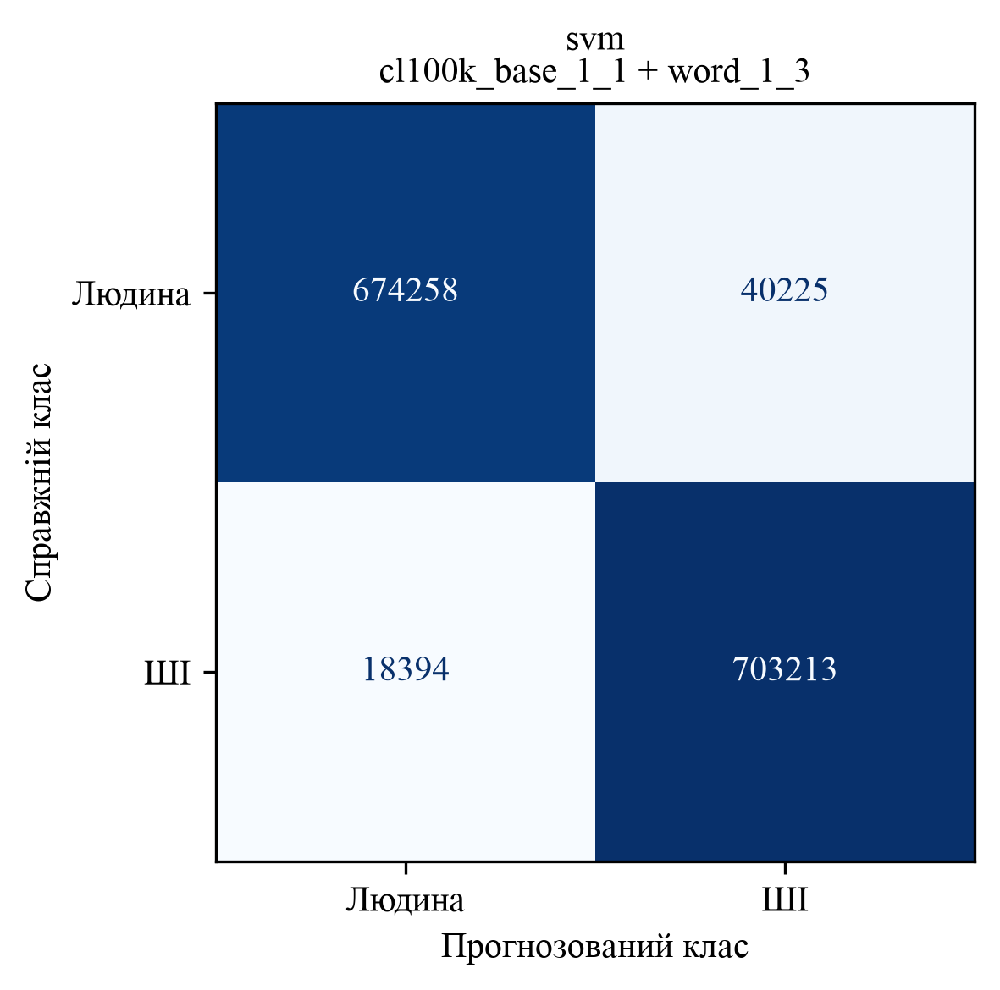


svm | cl100k_base_1_1 + char_2_5 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9752    0.9440    0.9593    714483
          ШІ     0.9462    0.9763    0.9610    721607

    accuracy                         0.9602   1436090
   macro avg     0.9607    0.9601    0.9602   1436090
weighted avg     0.9607    0.9602    0.9602   1436090



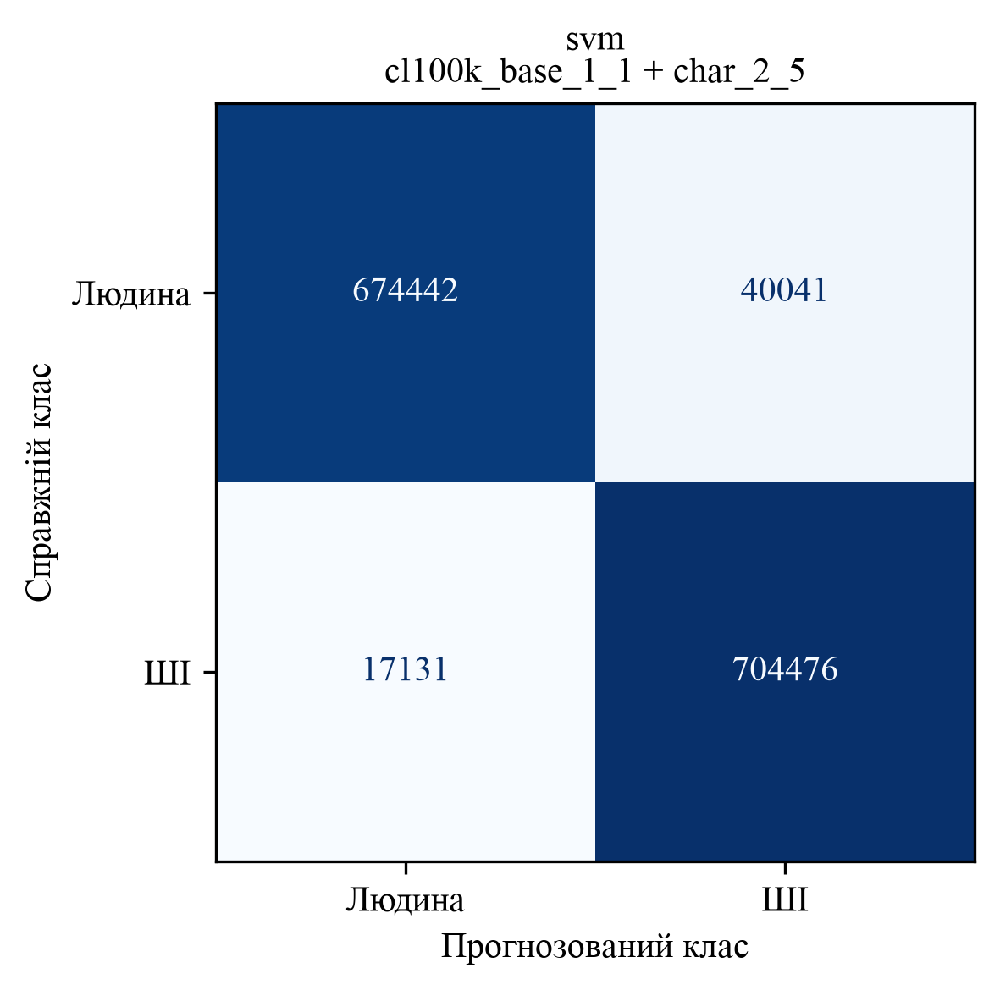


svm | o200k_base_1_1 + word_1_3 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9738    0.9437    0.9585    714483
          ШІ     0.9459    0.9749    0.9602    721607

    accuracy                         0.9594   1436090
   macro avg     0.9599    0.9593    0.9593   1436090
weighted avg     0.9598    0.9594    0.9593   1436090



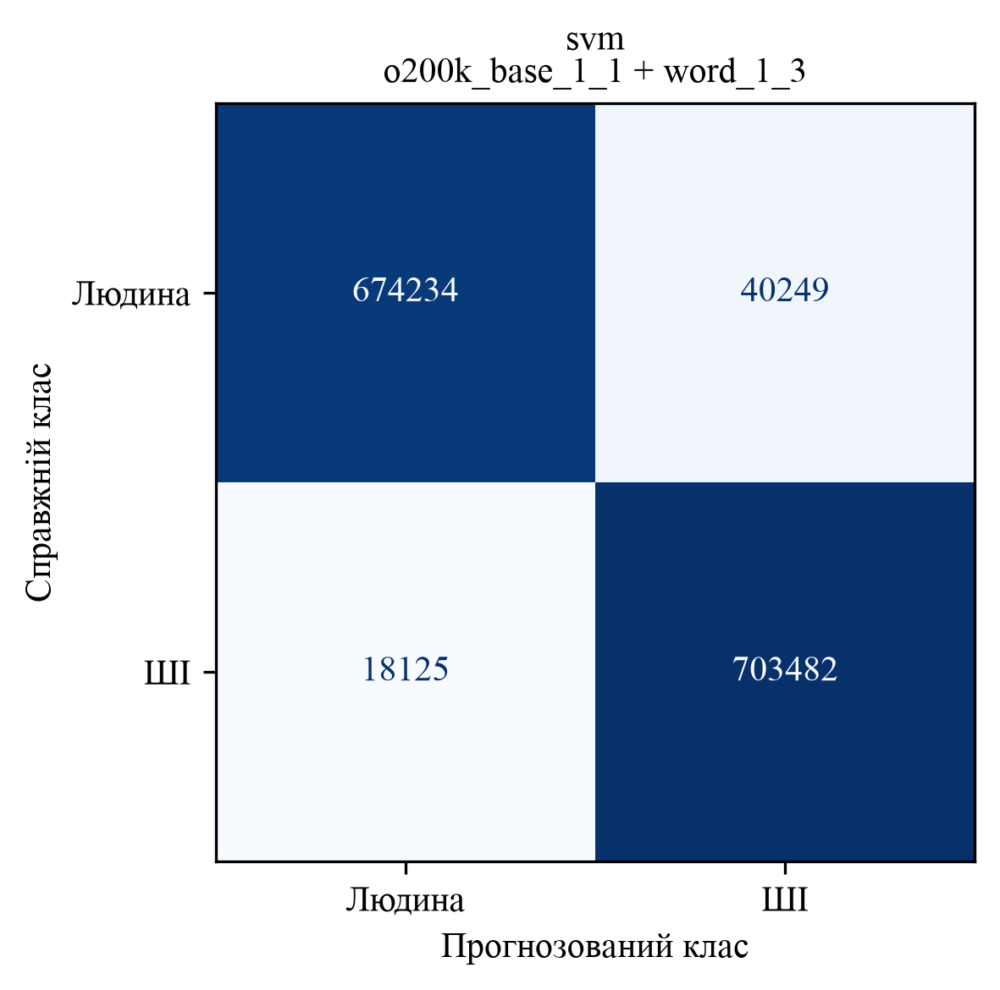


svm | o200k_base_1_1 + char_2_5 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9759    0.9442    0.9598    714483
          ШІ     0.9465    0.9769    0.9615    721607

    accuracy                         0.9606   1436090
   macro avg     0.9612    0.9606    0.9606   1436090
weighted avg     0.9611    0.9606    0.9606   1436090



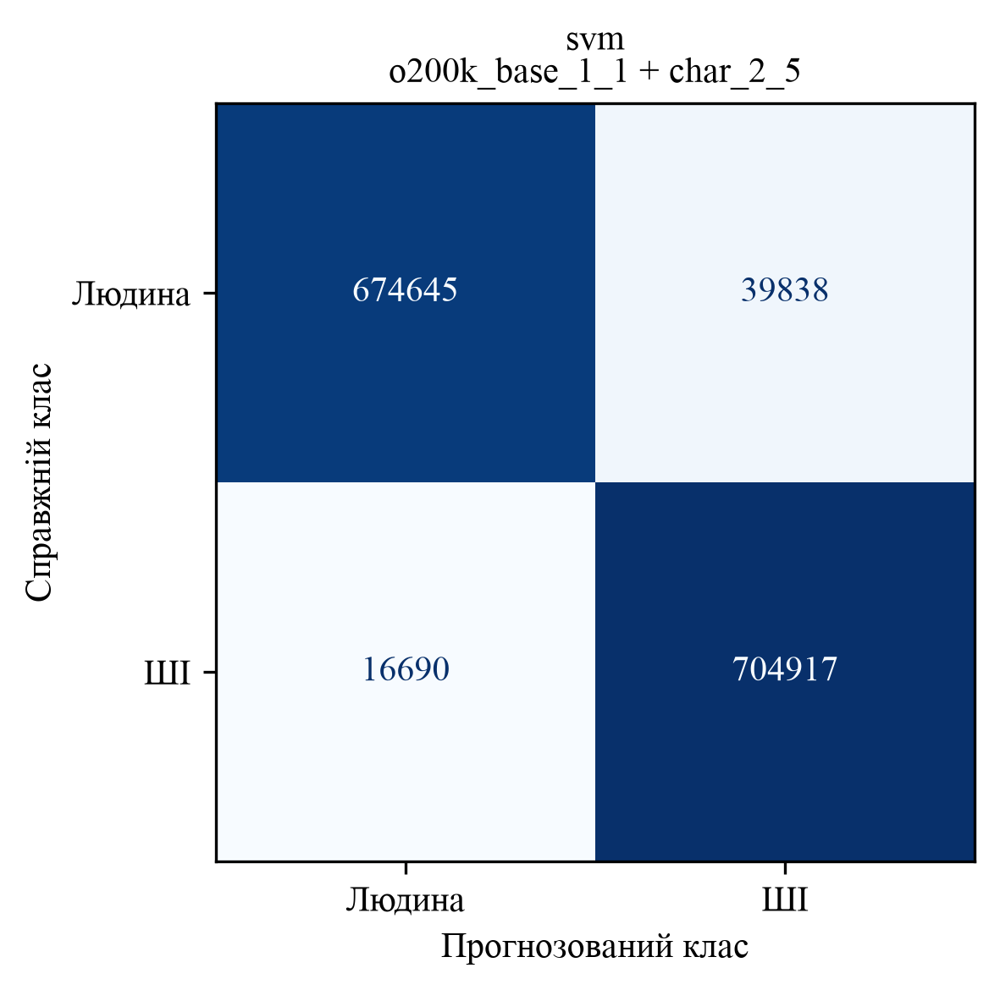


svm | word_1_3 + char_2_5 | епоха 2
              precision    recall  f1-score   support

      Людина     0.9699    0.9375    0.9534    714483
          ШІ     0.9401    0.9712    0.9554    721607

    accuracy                         0.9544   1436090
   macro avg     0.9550    0.9544    0.9544   1436090
weighted avg     0.9549    0.9544    0.9544   1436090



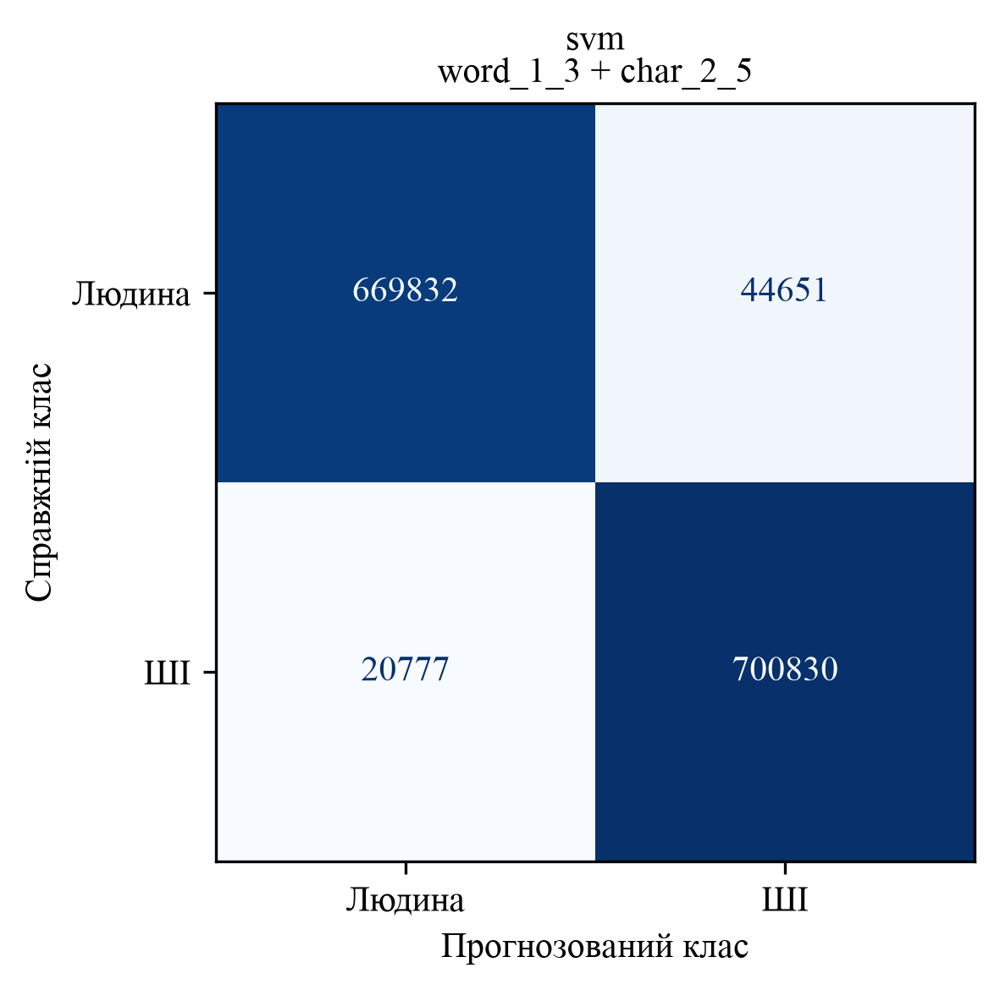

,algorithm,variant,epoch,Accuracy,Precision,Recall,F1 Score,n_features,model_file
13,svm,o200k_base_1_1__char_2_5,2,0.9606,0.9465,0.9769,0.9615,200000,/home/artem/diploma/classifier_results_accurac...
11,svm,cl100k_base_1_1__char_2_5,2,0.9602,0.9462,0.9763,0.9610,183175,/home/artem/diploma/classifier_results_accurac...
12,svm,o200k_base_1_1__word_1_3,2,0.9594,0.9459,0.9749,0.9602,200000,/home/artem/diploma/classifier_results_accurac...
10,svm,cl100k_base_1_1__word_1_3,2,0.9592,0.9459,0.9745,0.9600,183175,/home/artem/diploma/classifier_results_accurac...
8,svm,r50k_base_1_1__char_2_5,2,0.9571,0.9451,0.9711,0.9579,149996,/home/artem/diploma/classifier_results_accurac...
6,svm,r50k_base_1_1__o200k_base_1_1,2,0.9570,0.9440,0.9721,0.9579,149996,/home/artem/diploma/classifier_results_accurac...
9,svm,cl100k_base_1_1__o200k_base_1_1,2,0.9566,0.9434,0.9719,0.9574,183175,/home/artem/diploma/classifier_results_accurac...
2,svm,o200k_base_1_1,2,0.9563,0.9430,0.9718,0.9572,100000,/home/artem/diploma/classifier_results_accurac...
5,svm,r50k_base_1_1__cl100k_base_1_1,2,0.9558,0.9427,0.9710,0.9566,133171,/home/artem/diploma/classifier_results_accurac...
1,svm,cl100k_base_1_1,2,0.9551,0.9420,0.9704,0.9560,83175,/home/artem/diploma/classifier_results_accurac...


In [13]:
svm_metrics = evaluate_best_models("svm")
display(svm_metrics.round(4))

## 10. Порівняння всіх 30 моделей

Читаємо метрики збережених найкращих моделей після оцінювання на всьому val.
У таблиці є **Accuracy, Precision, Recall та F1 Score**; три останні показники — для ШІ (`label=1`).
Сортуємо та обираємо переможця **лише за Accuracy**.
При однаковій Accuracy зберігаємо початковий порядок варіантів.
Усі метрики — частки від 0 до 1.

In [14]:
logistic_results = pd.read_csv(RESULTS_DIR / "logistic" / "validation_results.csv")
svm_results = pd.read_csv(RESULTS_DIR / "svm" / "validation_results.csv")

all_results = pd.concat([logistic_results, svm_results], ignore_index=True)
all_results = all_results.sort_values("Accuracy", ascending=False, kind="stable").reset_index(drop=True)
all_results.insert(0, "rank", np.arange(1, len(all_results) + 1))
all_results.to_csv(RESULTS_DIR / "all_results.csv", index=False)
display(all_results.round(4))

best = all_results.iloc[0]
print("Алгоритм:", best["algorithm"])
print("Представлення:", best["variant"])
print("Епоха:", best["epoch"])
print(f"Accuracy на val: {best['Accuracy']:.4%}")
print("Файл моделі:", best["model_file"])

best.to_json(RESULTS_DIR / "best_variant.json", force_ascii=False, indent=2)

,rank,algorithm,variant,epoch,Accuracy,Precision,Recall,F1 Score,n_features,model_file
0,1,svm,o200k_base_1_1__char_2_5,2,0.9606,0.9465,0.9769,0.9615,200000,/home/artem/diploma/classifier_results_accurac...
1,2,svm,cl100k_base_1_1__char_2_5,2,0.9602,0.9462,0.9763,0.9610,183175,/home/artem/diploma/classifier_results_accurac...
2,3,svm,o200k_base_1_1__word_1_3,2,0.9594,0.9459,0.9749,0.9602,200000,/home/artem/diploma/classifier_results_accurac...
3,4,svm,cl100k_base_1_1__word_1_3,2,0.9592,0.9459,0.9745,0.9600,183175,/home/artem/diploma/classifier_results_accurac...
4,5,svm,r50k_base_1_1__char_2_5,2,0.9571,0.9451,0.9711,0.9579,149996,/home/artem/diploma/classifier_results_accurac...
5,6,svm,r50k_base_1_1__o200k_base_1_1,2,0.9570,0.9440,0.9721,0.9579,149996,/home/artem/diploma/classifier_results_accurac...
6,7,svm,cl100k_base_1_1__o200k_base_1_1,2,0.9566,0.9434,0.9719,0.9574,183175,/home/artem/diploma/classifier_results_accurac...
7,8,svm,o200k_base_1_1,2,0.9563,0.9430,0.9718,0.9572,100000,/home/artem/diploma/classifier_results_accurac...
8,9,svm,r50k_base_1_1__cl100k_base_1_1,2,0.9558,0.9427,0.9710,0.9566,133171,/home/artem/diploma/classifier_results_accurac...
9,10,svm,cl100k_base_1_1,2,0.9551,0.9420,0.9704,0.9560,83175,/home/artem/diploma/classifier_results_accurac...


Алгоритм: svm
Представлення: o200k_base_1_1__char_2_5
Епоха: 2
Accuracy на val: 96.0638%
Файл моделі: /home/artem/diploma/classifier_results_accuracy/svm/o200k_base_1_1__char_2_5.joblib


### Збережені файли

- `classifier_results_accuracy/logistic/` — моделі логістичної регресії.
- `classifier_results_accuracy/svm/` — моделі SVM.
- `<алгоритм>/<представлення або пара>.joblib` — модель найкращої епохи за accuracy.
- `<алгоритм>/checkpoint.joblib` — усі 15 моделей та позиція для продовження навчання.
- `<алгоритм>/epoch_history.csv` — accuracy кожної моделі після кожної епохи.
- `<алгоритм>/best_results.csv` — найкраща епоха кожного варіанта.
- `all_results.csv`, `best_variant.json` — загальне порівняння та обраний варіант.
- `feature_blocks.csv` — порядок ознак для зіставлення ваг моделі з токенами, словами чи символами.

Checkpoint містить поточні моделі, а окремі файли моделей — найкращі за accuracy на val.

Додаткові результати оцінювання найкращих епох:

- `<алгоритм>/validation_results.csv` — Accuracy, Precision, Recall та F1 Score для 15 варіантів.
- `<алгоритм>/reports/<варіант>_classification_report.txt` і `.json` — повний звіт для обох класів.
- `<алгоритм>/reports/<варіант>_confusion_matrix.csv` — матриця помилок у числах.
- `<алгоритм>/reports/<варіант>_confusion_matrix.png` — зображення 300 dpi на білому фоні.

Рядки confusion matrix — справжні класи; колонки — прогнозовані. Порядок: `0 — Людина`, `1 — ШІ`.

# Тюнінг SVM: o200k_base_1_1 + char_2_5

Найкраще представлення попереднього експерименту — поєднання окремих токенів `o200k_base`
і символьних n-грам `(2, 5)`. Залишаємо ці ознаки та підбираємо параметри
**лінійного SVM через `SGDClassifier(loss="hinge")`**.

Пошук складається з двох етапів:

1. П'ять значень `alpha` при L2-регуляризації та усередненні ваг.
2. Для найкращого `alpha` — L1, L2, Elastic Net та `average=True/False`.

Це послідовний пошук, а не повний перебір усіх спільних комбінацій параметрів.
Кожного кандидата навчаємо з нуля до **5 епох**, зберігаючи найкращу епоху за **accuracy на всьому val**.
Початкову модель включаємо у фінальне порівняння: тюнінг не гарантує покращення.
Test використовуватимемо лише після завершення вибору параметрів.

## 1. Налаштування тюнінгу

Цей розділ можна виконувати окремо від попереднього навчання.
Матриці та початкова модель вже мають бути збережені.
Результати тюнінгу записуємо в нову папку, попередні моделі не перезаписуємо.

In [15]:
import gc
import json
import shutil
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.preprocessing import normalize
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits
from IPython.display import display

TUNE_FEATURES = Path("vectorization_sklearn/tfidf")
BASE_RESULTS = Path("classifier_results_accuracy")
TUNE_DIR = Path("svm_tuning_o200k_char")
TUNE_DIR.mkdir(exist_ok=True)

TUNE_REPRESENTATIONS = ["o200k_base_1_1", "char_2_5"]
TUNE_VARIANT = "__".join(TUNE_REPRESENTATIONS)
TUNE_EPOCHS = 5
TUNE_THREADS = 4
TUNE_SEED = 42

## 2. Дані та початковий результат

Перевіряємо готові train/val для двох представлень і читаємо метрики початкової моделі.
Зберігаємо порядок блоків ознак: спочатку `o200k_base_1_1`, потім `char_2_5`.

In [16]:
tune_manifests = {}
tune_data_version = []
for name in TUNE_REPRESENTATIONS:
    tune_manifests[name] = {}
    for split in ["train", "val"]:
        file = TUNE_FEATURES / name / split / "manifest.json"
        info = json.loads(file.read_text())
        if not info["complete"] or sum(part["rows"] for part in info["shards"]) != info["n_rows"]:
            raise ValueError(f"Незавершена векторизація: {name}, {split}")
        tune_manifests[name][split] = info
        tune_data_version.append((str(file.resolve()), file.stat().st_mtime_ns))
    if tune_manifests[name]["train"]["n_features"] != tune_manifests[name]["val"]["n_features"]:
        raise ValueError("У train і val різна кількість ознак.")

for split in ["train", "val"]:
    left = tune_manifests[TUNE_REPRESENTATIONS[0]][split]
    right = tune_manifests[TUNE_REPRESENTATIONS[1]][split]
    if [part["rows"] for part in left["shards"]] != [part["rows"] for part in right["shards"]]:
        raise ValueError("Представлення мають різний поділ на батчі.")

base_table = pd.read_csv(BASE_RESULTS / "svm" / "validation_results.csv")
baseline = base_table.loc[base_table["variant"] == TUNE_VARIANT].iloc[0]
print(f"Початкова accuracy на val: {baseline['Accuracy']:.4%}")
display(baseline.to_frame("Початкова модель"))

blocks = []
offset = 0
for name in TUNE_REPRESENTATIONS:
    size = tune_manifests[name]["train"]["n_features"]
    blocks.append({"representation": name, "column_start": offset, "column_stop": offset + size,
                   "feature_table": str((TUNE_FEATURES / name / "features.parquet").resolve())})
    offset += size
pd.DataFrame(blocks).to_csv(TUNE_DIR / "feature_blocks.csv", index=False)

Початкова accuracy на val: 96.0638%


,Початкова модель
algorithm,svm
variant,o200k_base_1_1__char_2_5
epoch,2
Accuracy,0.960638
Precision,0.946509
Recall,0.976871
F1 Score,0.96145
n_features,200000
model_file,/home/artem/diploma/classifier_results_accurac...


## 3. Читання та об'єднання одного батча

Читаємо лише два потрібні представлення. Перевіряємо відповідність текстів за `row_id` та `label`.
Об'єднуємо колонки й нормалізуємо L2 так само, як у попередньому експерименті.
Один готовий батч використовуємо для всіх кандидатів, не створюючи окрему копію для кожного.
Значення залишаються `float32`, індекси CSR — `int32`.

In [17]:
def read_tuning_batch(split, number):
    parts = []
    for name in TUNE_REPRESENTATIONS:
        info = tune_manifests[name][split]
        batch = info["shards"][number]
        folder = TUNE_FEATURES / name / split
        labels = np.load(folder / batch["label"])
        row_ids = np.load(folder / batch["row_id"])
        if not len(labels) == len(row_ids) == batch["rows"]:
            raise ValueError("Не збігається кількість рядків, міток та row_id.")
        if not parts:
            y, expected_ids = labels, row_ids
            start = sum(item["rows"] for item in info["shards"][:number])
            if not np.array_equal(row_ids, np.arange(start, start + len(y))) or not np.isin(y, [0, 1]).all():
                raise ValueError("Некоректні row_id або мітки.")
        elif not (np.array_equal(labels, y) and np.array_equal(row_ids, expected_ids)):
            raise ValueError("У двох представленнях різний порядок текстів або мітки.")

        X = sparse.load_npz(folder / batch["file"])
        if X.format != "csr" or X.dtype != np.float32 or X.shape != (len(y), info["n_features"]):
            raise ValueError("Очікуємо CSR float32 відповідного розміру.")
        parts.append(X)

    if max(sum(part.nnz for part in parts), sum(part.shape[1] for part in parts), len(y)) > np.iinfo(np.int32).max:
        raise OverflowError("Об'єднаний батч перевищує межу int32.")
    X = sparse.hstack(parts, format="csr", dtype=np.float32)
    X.indices = X.indices.astype(np.int32, copy=False)
    X.indptr = X.indptr.astype(np.int32, copy=False)
    normalize(X, norm="l2", copy=False)
    return X, y


def save_tuning_model(file, value):
    temporary = file.with_suffix(".tmp")
    joblib.dump(value, temporary)
    temporary.replace(file)

## 4. Прогнози кандидатів на всьому val

Зберігаємо в пам'яті лише мітки та прогнози `int8`, а великі CSR-батчі звільняємо.
Це дозволяє порахувати метрики для всього val та сформувати звіти найкращих епох.

In [18]:
def tuning_train_batch(model, X, y):
    model.partial_fit(X, y, classes=[0, 1])


def tuning_predict_batch(model, X):
    return model.predict(X).astype(np.int8)


def tuning_predictions(models, pool):
    labels = []
    predictions = [[] for model in models]
    info = tune_manifests[TUNE_REPRESENTATIONS[0]]["val"]
    for number in range(len(info["shards"])):
        X, y = read_tuning_batch("val", number)
        tasks = [pool.submit(tuning_predict_batch, model, X) for model in models]
        for index, task in enumerate(tasks):
            predictions[index].append(task.result())
        labels.append(y.astype(np.int8))
        del X, y, tasks
        gc.collect()
        if (number + 1) % 5 == 0 or number + 1 == len(info["shards"]):
            print(f"Val: батч {number + 1}/{len(info['shards'])}", flush=True)
    y_true = np.concatenate(labels)
    if len(y_true) != info["n_rows"]:
        raise ValueError("Опрацьовано не всі рядки val.")
    return y_true, [np.concatenate(parts) for parts in predictions]

## 5. Навчання одного етапу пошуку

Кожен кандидат має власну модель, найкращу епоху та файл результатів.
Після кожного train-батча зберігаємо checkpoint; повторний запуск продовжує той самий етап.
Після епохи обчислюємо **Accuracy, Precision, Recall, F1 Score** на всьому val.
Precision, Recall та F1 Score у таблиці — для ШІ (`label=1`).

Коли accuracy зростає, зберігаємо модель, classification report та confusion matrix саме цієї епохи.
При рівності залишаємо ранішу епоху. Для нових даних або змінених налаштувань задайте іншу `TUNE_DIR`.

In [19]:
def run_svm_tuning(configs, stage):
    folder = TUNE_DIR / stage
    folder.mkdir(exist_ok=True)
    checkpoint = folder / "checkpoint.joblib"
    settings = {"configs": configs, "epochs": TUNE_EPOCHS, "seed": TUNE_SEED,
                "data_version": tune_data_version, "loss": "hinge", "learning_rate": "optimal"}
    if checkpoint.exists():
        state = joblib.load(checkpoint)
        if state["settings"] != settings:
            raise ValueError("Параметри або дані змінилися. Задайте іншу TUNE_DIR.")
        print("Продовжуємо етап:", stage, flush=True)
    else:
        state = {"settings": settings, "epoch": 0, "next_batch": 0, "history": [],
                 "best_accuracy": [-1.0] * len(configs), "best_rows": [None] * len(configs),
                 "models": [SGDClassifier(loss="hinge", learning_rate="optimal", random_state=TUNE_SEED,
                             n_jobs=1, **params) for params in configs]}

    batch_count = len(tune_manifests[TUNE_REPRESENTATIONS[0]]["train"]["shards"])
    with threadpool_limits(limits=1), ThreadPoolExecutor(max_workers=TUNE_THREADS) as pool:
        for epoch in range(state["epoch"], TUNE_EPOCHS):
            print(f"{stage}: епоха {epoch + 1}/{TUNE_EPOCHS}", flush=True)
            order = np.random.default_rng(TUNE_SEED + epoch).permutation(batch_count)
            for position in range(state["next_batch"], batch_count):
                X, y = read_tuning_batch("train", int(order[position]))
                tasks = [pool.submit(tuning_train_batch, model, X, y) for model in state["models"]]
                for task in tasks:
                    task.result()
                state["next_batch"] = position + 1
                save_tuning_model(checkpoint, state)
                del X, y, tasks
                gc.collect()
                if (position + 1) % 10 == 0 or position + 1 == batch_count:
                    print(f"Train: батч {position + 1}/{batch_count}", flush=True)

            y_true, predictions = tuning_predictions(state["models"], pool)
            for index, params in enumerate(configs):
                trial = f"trial_{index:02d}"
                y_pred = predictions[index]
                report = classification_report(y_true, y_pred, labels=[0, 1],
                             target_names=["Людина", "ШІ"], output_dict=True, zero_division=0)
                row = {"stage": stage, "trial": trial, **params,
                       "l1_ratio": params.get("l1_ratio", np.nan), "epoch": epoch + 1,
                       "Accuracy": accuracy_score(y_true, y_pred),
                       "Precision": report["ШІ"]["precision"], "Recall": report["ШІ"]["recall"],
                       "F1 Score": report["ШІ"]["f1-score"],
                       "model_file": str((folder / f"{trial}.joblib").resolve()),
                       "report_file": str((folder / f"{trial}_report.txt").resolve()),
                       "confusion_matrix_file": str((folder / f"{trial}_confusion_matrix.csv").resolve())}
                state["history"].append(row)
                if row["Accuracy"] > state["best_accuracy"][index]:
                    save_tuning_model(folder / f"{trial}.joblib", state["models"][index])
                    text = classification_report(y_true, y_pred, labels=[0, 1],
                              target_names=["Людина", "ШІ"], digits=4, zero_division=0)
                    Path(row["report_file"]).write_text(text, encoding="utf-8")
                    (folder / f"{trial}_report.json").write_text(
                        json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8")
                    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
                    pd.DataFrame(cm, index=["Людина", "ШІ"], columns=["Людина", "ШІ"]).to_csv(
                        row["confusion_matrix_file"])
                    state["best_accuracy"][index] = row["Accuracy"]
                    state["best_rows"][index] = row

            del y_true, y_pred, predictions
            state["epoch"] = epoch + 1
            state["next_batch"] = 0
            table = pd.DataFrame(state["best_rows"]).sort_values("Accuracy", ascending=False, kind="stable")
            table.to_csv(folder / "best_results.csv", index=False)
            pd.DataFrame(state["history"]).to_csv(folder / "epoch_history.csv", index=False)
            save_tuning_model(checkpoint, state)
            print(f"Найкраща accuracy: {table.iloc[0]['Accuracy']:.6f}", flush=True)
            gc.collect()

    table = pd.DataFrame(state["best_rows"]).sort_values("Accuracy", ascending=False, kind="stable")
    del state
    gc.collect()
    return table

## 6. Етап 1: сила регуляризації alpha

Перевіряємо `1e-6`, `3e-6`, `1e-5`, `3e-5`, `1e-4`.
Початкове значення `1e-5` також входить у пошук. Залишаємо `penalty="l2"`, `average=True`.

Більше `alpha` означає сильнішу регуляризацію. При `learning_rate="optimal"`
цей параметр також впливає на крок навчання. Налаштування описані в
[документації SGDClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDClassifier.html).
Кількість епох контролюємо власним циклом: `max_iter` не керує викликами `partial_fit`.

In [20]:
alpha_configs = list(ParameterGrid({
    "alpha": [1e-6, 3e-6, 1e-5, 3e-5, 1e-4],
    "penalty": ["l2"],
    "average": [True]
}))
display(pd.DataFrame(alpha_configs))

,alpha,average,penalty
0,0.000001,True,l2
1,0.000003,True,l2
2,0.000010,True,l2
3,0.000030,True,l2
4,0.000100,True,l2


In [21]:
alpha_results = run_svm_tuning(alpha_configs, stage="alpha_search")
display(alpha_results.round(6))

alpha_search: епоха 1/5
Train: батч 10/230
Train: батч 20/230
Train: батч 30/230
Train: батч 40/230
Train: батч 50/230
Train: батч 60/230
Train: батч 70/230
Train: батч 80/230
Train: батч 90/230
Train: батч 100/230
Train: батч 110/230
Train: батч 120/230
Train: батч 130/230
Train: батч 140/230
Train: батч 150/230
Train: батч 160/230
Train: батч 170/230
Train: батч 180/230
Train: батч 190/230
Train: батч 200/230
Train: батч 210/230
Train: батч 220/230
Train: батч 230/230
Val: батч 5/29
Val: батч 10/29
Val: батч 15/29
Val: батч 20/29
Val: батч 25/29
Val: батч 29/29
Найкраща accuracy: 0.971047
alpha_search: епоха 2/5
Train: батч 10/230
Train: батч 20/230
Train: батч 30/230
Train: батч 40/230
Train: батч 50/230
Train: батч 60/230
Train: батч 70/230
Train: батч 80/230
Train: батч 90/230
Train: батч 100/230
Train: батч 110/230
Train: батч 120/230
Train: батч 130/230
Train: батч 140/230
Train: батч 150/230
Train: батч 160/230
Train: батч 170/230
Train: батч 180/230
Train: батч 190/230
Train: 

,stage,trial,alpha,average,penalty,l1_ratio,epoch,Accuracy,Precision,Recall,F1 Score,model_file,report_file,confusion_matrix_file
0,alpha_search,trial_00,0.000001,True,l2,NaN,5,0.972075,0.964216,0.980826,0.972450,/home/artem/diploma/svm_tuning_o200k_char/alph...,/home/artem/diploma/svm_tuning_o200k_char/alph...,/home/artem/diploma/svm_tuning_o200k_char/alph...
1,alpha_search,trial_01,0.000003,True,l2,NaN,5,0.967601,0.957428,0.979055,0.968121,/home/artem/diploma/svm_tuning_o200k_char/alph...,/home/artem/diploma/svm_tuning_o200k_char/alph...,/home/artem/diploma/svm_tuning_o200k_char/alph...
2,alpha_search,trial_02,0.000010,True,l2,NaN,5,0.960812,0.946962,0.976716,0.961609,/home/artem/diploma/svm_tuning_o200k_char/alph...,/home/artem/diploma/svm_tuning_o200k_char/alph...,/home/artem/diploma/svm_tuning_o200k_char/alph...
3,alpha_search,trial_03,0.000030,True,l2,NaN,5,0.951330,0.932689,0.973389,0.952604,/home/artem/diploma/svm_tuning_o200k_char/alph...,/home/artem/diploma/svm_tuning_o200k_char/alph...,/home/artem/diploma/svm_tuning_o200k_char/alph...
4,alpha_search,trial_04,0.000100,True,l2,NaN,5,0.936230,0.911443,0.967050,0.938423,/home/artem/diploma/svm_tuning_o200k_char/alph...,/home/artem/diploma/svm_tuning_o200k_char/alph...,/home/artem/diploma/svm_tuning_o200k_char/alph...


## 7. Етап 2: регуляризація та усереднення ваг

Фіксуємо найкращий `alpha` першого етапу. Перевіряємо:

- `penalty`: L2, L1 та Elastic Net.
- `average`: `True` та `False` — з усередненням ваг або без нього.
- Для Elastic Net — `l1_ratio=0.15` та `0.5`, тобто різну частку L1-регуляризації.

Найкращий L2-кандидат з `average=True` вже навчений на першому етапі,
тому повторно його не навчаємо. Залишається **7 нових кандидатів**.

In [22]:
alpha_results = pd.read_csv(TUNE_DIR / "alpha_search" / "best_results.csv")
best_alpha = float(alpha_results.iloc[0]["alpha"])
print("Найкращий alpha:", best_alpha)

refine_configs = list(ParameterGrid([
    {"alpha": [best_alpha], "penalty": ["l2", "l1"], "average": [True, False]},
    {"alpha": [best_alpha], "penalty": ["elasticnet"],
     "l1_ratio": [0.15, 0.5], "average": [True, False]}
]))
refine_configs = [params for params in refine_configs
                  if not (params["penalty"] == "l2" and params["average"])]
display(pd.DataFrame(refine_configs))

Найкращий alpha: 1e-06


,alpha,average,penalty,l1_ratio
0,0.000001,True,l1,NaN
1,0.000001,False,l2,NaN
2,0.000001,False,l1,NaN
3,0.000001,True,elasticnet,0.15
4,0.000001,True,elasticnet,0.50
5,0.000001,False,elasticnet,0.15
6,0.000001,False,elasticnet,0.50


In [23]:
refine_results = run_svm_tuning(refine_configs, stage="regularization_search")
display(refine_results.round(6))

regularization_search: епоха 1/5
Train: батч 10/230
Train: батч 20/230
Train: батч 30/230
Train: батч 40/230
Train: батч 50/230
Train: батч 60/230
Train: батч 70/230
Train: батч 80/230
Train: батч 90/230
Train: батч 100/230
Train: батч 110/230
Train: батч 120/230
Train: батч 130/230
Train: батч 140/230
Train: батч 150/230
Train: батч 160/230
Train: батч 170/230
Train: батч 180/230
Train: батч 190/230
Train: батч 200/230
Train: батч 210/230
Train: батч 220/230
Train: батч 230/230
Val: батч 5/29
Val: батч 10/29
Val: батч 15/29
Val: батч 20/29
Val: батч 25/29
Val: батч 29/29
Найкраща accuracy: 0.971557
regularization_search: епоха 2/5
Train: батч 10/230
Train: батч 20/230
Train: батч 30/230
Train: батч 40/230
Train: батч 50/230
Train: батч 60/230
Train: батч 70/230
Train: батч 80/230
Train: батч 90/230
Train: батч 100/230
Train: батч 110/230
Train: батч 120/230
Train: батч 130/230
Train: батч 140/230
Train: батч 150/230
Train: батч 160/230
Train: батч 170/230
Train: батч 180/230
Train: ба

,stage,trial,alpha,average,penalty,l1_ratio,epoch,Accuracy,Precision,Recall,F1 Score,model_file,report_file,confusion_matrix_file
1,regularization_search,trial_01,0.000001,False,l2,NaN,5,0.973475,0.966556,0.981160,0.973803,/home/artem/diploma/svm_tuning_o200k_char/regu...,/home/artem/diploma/svm_tuning_o200k_char/regu...,/home/artem/diploma/svm_tuning_o200k_char/regu...
5,regularization_search,trial_05,0.000001,False,elasticnet,0.15,5,0.973281,0.966095,0.981263,0.973620,/home/artem/diploma/svm_tuning_o200k_char/regu...,/home/artem/diploma/svm_tuning_o200k_char/regu...,/home/artem/diploma/svm_tuning_o200k_char/regu...
6,regularization_search,trial_06,0.000001,False,elasticnet,0.50,5,0.972094,0.964679,0.980358,0.972455,/home/artem/diploma/svm_tuning_o200k_char/regu...,/home/artem/diploma/svm_tuning_o200k_char/regu...,/home/artem/diploma/svm_tuning_o200k_char/regu...
3,regularization_search,trial_03,0.000001,True,elasticnet,0.15,5,0.971896,0.964005,0.980688,0.972275,/home/artem/diploma/svm_tuning_o200k_char/regu...,/home/artem/diploma/svm_tuning_o200k_char/regu...,/home/artem/diploma/svm_tuning_o200k_char/regu...
4,regularization_search,trial_04,0.000001,True,elasticnet,0.50,5,0.971362,0.963622,0.980003,0.971743,/home/artem/diploma/svm_tuning_o200k_char/regu...,/home/artem/diploma/svm_tuning_o200k_char/regu...,/home/artem/diploma/svm_tuning_o200k_char/regu...
2,regularization_search,trial_02,0.000001,False,l1,NaN,5,0.970361,0.963234,0.978358,0.970737,/home/artem/diploma/svm_tuning_o200k_char/regu...,/home/artem/diploma/svm_tuning_o200k_char/regu...,/home/artem/diploma/svm_tuning_o200k_char/regu...
0,regularization_search,trial_00,0.000001,True,l1,NaN,5,0.970139,0.963341,0.977782,0.970508,/home/artem/diploma/svm_tuning_o200k_char/regu...,/home/artem/diploma/svm_tuning_o200k_char/regu...,/home/artem/diploma/svm_tuning_o200k_char/regu...


## 8. Порівняння з початковою моделлю та збереження переможця

Порівнюємо 12 кандидатів тюнінгу та початкову модель за **Accuracy**.
Precision, Recall і F1 Score також виводимо. При рівності спочатку залишаємо початкову модель,
далі — попередній порядок кандидатів. Від'ємна різниця Accuracy означає погіршення.

Копіюємо найкращу модель у `best_model.joblib` і зберігаємо її параметри.
Початковий файл моделі залишається на своєму місці.

In [24]:
alpha_results = pd.read_csv(TUNE_DIR / "alpha_search" / "best_results.csv")
refine_results = pd.read_csv(TUNE_DIR / "regularization_search" / "best_results.csv")

baseline_row = {"stage": "baseline", "trial": "original", "alpha": 1e-5,
                "penalty": "l2", "average": True, "l1_ratio": np.nan,
                "epoch": int(baseline["epoch"]),
                **{name: baseline[name] for name in ["Accuracy", "Precision", "Recall", "F1 Score", "model_file"]},
                "report_file": str((BASE_RESULTS / "svm" / "reports" / f"{TUNE_VARIANT}_classification_report.txt").resolve()),
                "confusion_matrix_file": str((BASE_RESULTS / "svm" / "reports" / f"{TUNE_VARIANT}_confusion_matrix.csv").resolve())}

tuning_results = pd.concat([pd.DataFrame([baseline_row]), alpha_results, refine_results], ignore_index=True)
tuning_results = tuning_results.sort_values("Accuracy", ascending=False, kind="stable").reset_index(drop=True)
tuning_results["Accuracy change, pp"] = (tuning_results["Accuracy"] - baseline["Accuracy"]) * 100
tuning_results.to_csv(TUNE_DIR / "all_results.csv", index=False)
display(tuning_results[["stage", "trial", "alpha", "penalty", "l1_ratio", "average", "epoch",
                        "Accuracy", "Precision", "Recall", "F1 Score", "Accuracy change, pp"]].round(6))

best_tuned = tuning_results.iloc[0].copy()
print("Параметри обраної моделі:")
display(best_tuned[["stage", "alpha", "penalty", "l1_ratio", "average", "epoch"]])
print(f"Accuracy: {best_tuned['Accuracy']:.4%}")
print(f"Зміна проти початкової: {best_tuned['Accuracy change, pp']:+.4f} відсоткового пункту")

shutil.copyfile(best_tuned["model_file"], TUNE_DIR / "best_model.joblib")
best_tuned["source_model_file"] = best_tuned["model_file"]
best_tuned["model_file"] = str((TUNE_DIR / "best_model.joblib").resolve())
best_tuned["variant"] = TUNE_VARIANT
best_tuned["loss"] = "hinge"
best_tuned["learning_rate"] = "optimal"
best_tuned["random_state"] = TUNE_SEED
best_tuned.to_json(TUNE_DIR / "best_parameters.json", force_ascii=False, indent=2)

,stage,trial,alpha,penalty,l1_ratio,average,epoch,Accuracy,Precision,Recall,F1 Score,"Accuracy change, pp"
0,regularization_search,trial_01,0.000001,l2,NaN,False,5,0.973475,0.966556,0.981160,0.973803,1.283694
1,regularization_search,trial_05,0.000001,elasticnet,0.15,False,5,0.973281,0.966095,0.981263,0.973620,1.264336
2,regularization_search,trial_06,0.000001,elasticnet,0.50,False,5,0.972094,0.964679,0.980358,0.972455,1.145611
3,alpha_search,trial_00,0.000001,l2,NaN,True,5,0.972075,0.964216,0.980826,0.972450,1.143731
4,regularization_search,trial_03,0.000001,elasticnet,0.15,True,5,0.971896,0.964005,0.980688,0.972275,1.125835
5,regularization_search,trial_04,0.000001,elasticnet,0.50,True,5,0.971362,0.963622,0.980003,0.971743,1.072426
6,regularization_search,trial_02,0.000001,l1,NaN,False,5,0.970361,0.963234,0.978358,0.970737,0.972362
7,regularization_search,trial_00,0.000001,l1,NaN,True,5,0.970139,0.963341,0.977782,0.970508,0.950149
8,alpha_search,trial_01,0.000003,l2,NaN,True,5,0.967601,0.957428,0.979055,0.968121,0.696335
9,alpha_search,trial_02,0.000010,l2,NaN,True,5,0.960812,0.946962,0.976716,0.961609,0.017478


Параметри обраної моделі:


stage       regularization_search
alpha                    0.000001
penalty                        l2
l1_ratio                      NaN
average                     False
epoch                           5
Name: 0, dtype: object

Accuracy: 97.3475%
Зміна проти початкової: +1.2837 відсоткового пункту


## 9. Classification report та confusion matrix всіх кандидатів

Читаємо збережені звіти найкращих епох: повторного навчання або прогнозування тут немає.
Графіки виводимо та зберігаємо з білим фоном, шрифтом Times New Roman і роздільністю 300 dpi.
Рядки confusion matrix — справжні класи, колонки — прогнозовані.


regularization_search | trial_01 | alpha=1e-06 | penalty=l2 | average=False | епоха 5
              precision    recall  f1-score   support

      Людина     0.9807    0.9657    0.9731    714483
          ШІ     0.9666    0.9812    0.9738    721607

    accuracy                         0.9735   1436090
   macro avg     0.9736    0.9734    0.9735   1436090
weighted avg     0.9736    0.9735    0.9735   1436090



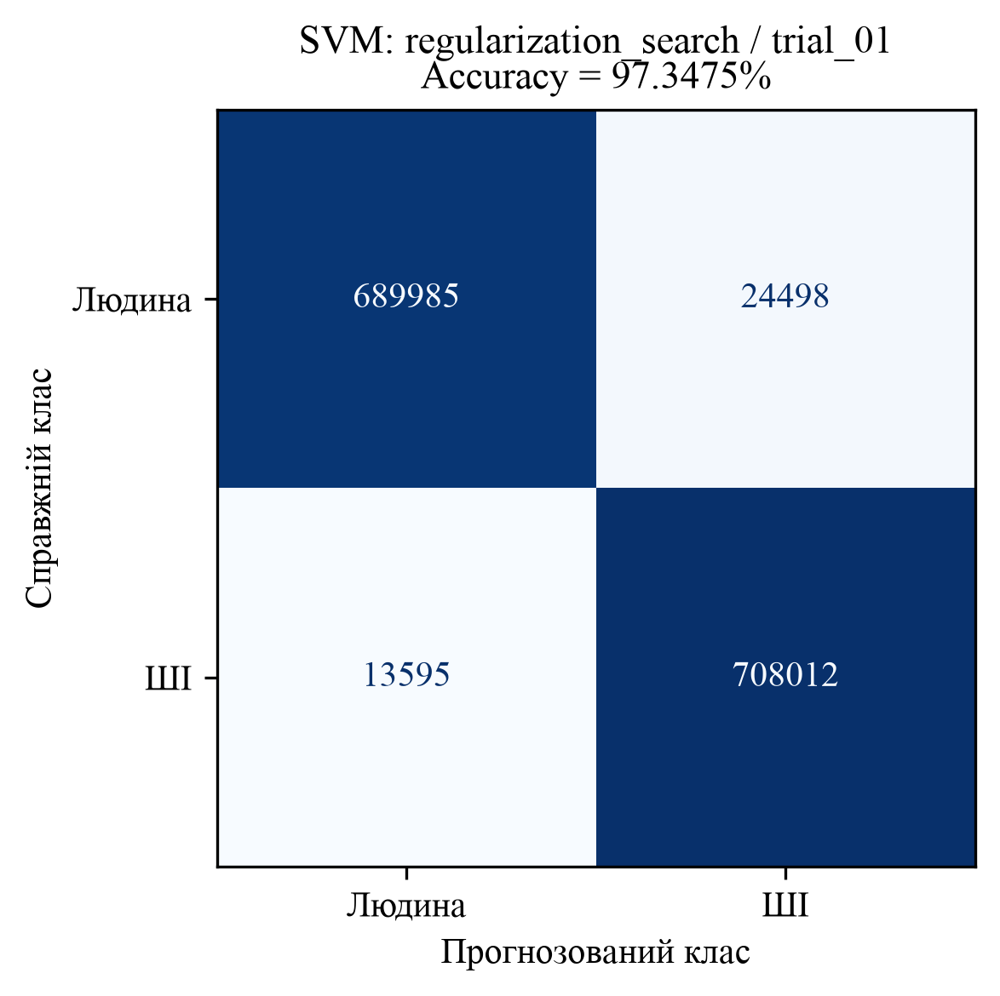


regularization_search | trial_05 | alpha=1e-06 | penalty=elasticnet | average=False | епоха 5
              precision    recall  f1-score   support

      Людина     0.9808    0.9652    0.9729    714483
          ШІ     0.9661    0.9813    0.9736    721607

    accuracy                         0.9733   1436090
   macro avg     0.9734    0.9732    0.9733   1436090
weighted avg     0.9734    0.9733    0.9733   1436090



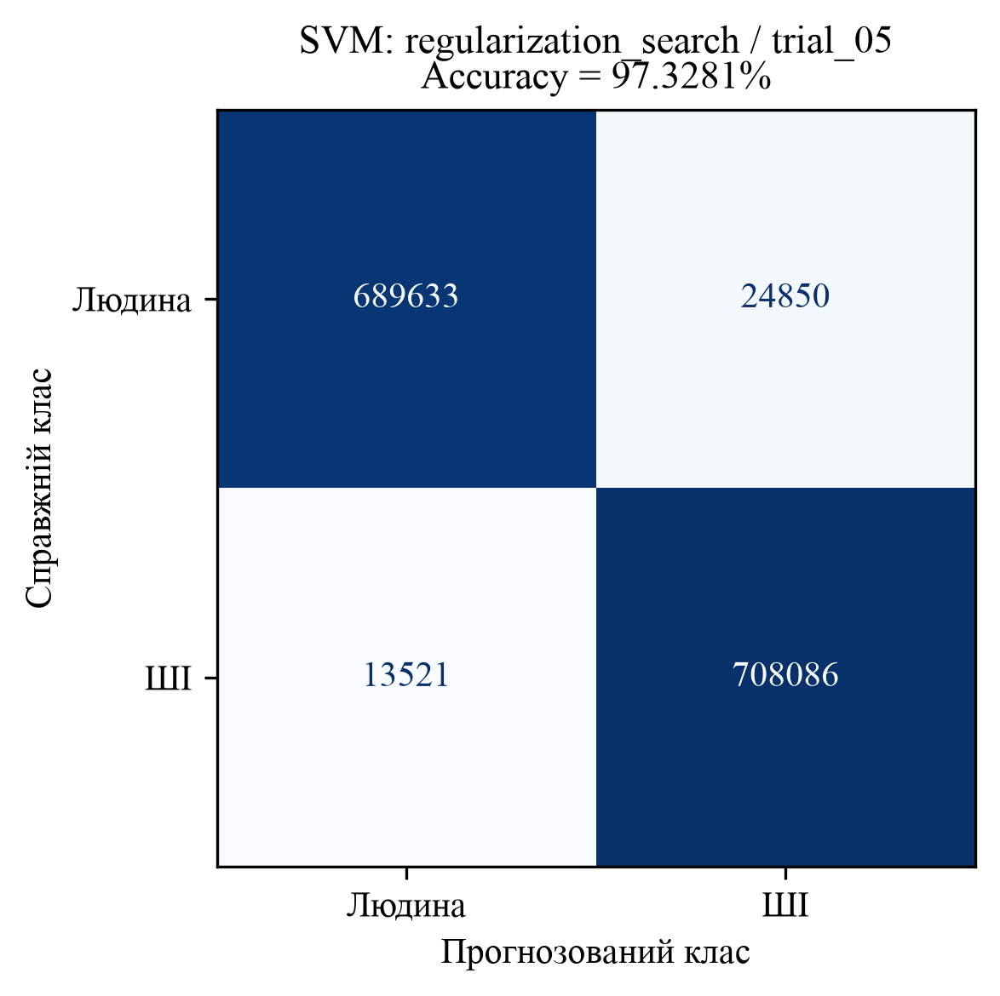


regularization_search | trial_06 | alpha=1e-06 | penalty=elasticnet | average=False | епоха 5
              precision    recall  f1-score   support

      Людина     0.9798    0.9637    0.9717    714483
          ШІ     0.9647    0.9804    0.9725    721607

    accuracy                         0.9721   1436090
   macro avg     0.9723    0.9721    0.9721   1436090
weighted avg     0.9722    0.9721    0.9721   1436090



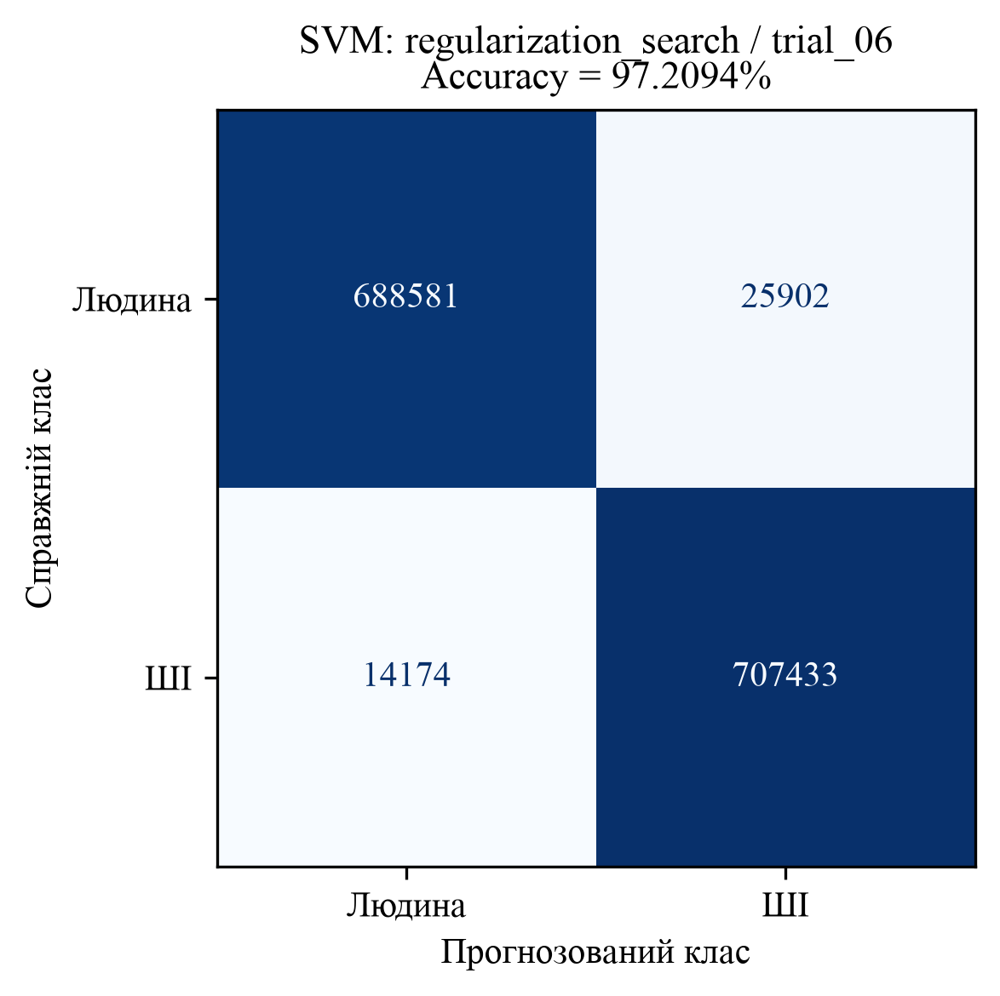


alpha_search | trial_00 | alpha=1e-06 | penalty=l2 | average=True | епоха 5
              precision    recall  f1-score   support

      Людина     0.9803    0.9632    0.9717    714483
          ШІ     0.9642    0.9808    0.9725    721607

    accuracy                         0.9721   1436090
   macro avg     0.9723    0.9720    0.9721   1436090
weighted avg     0.9722    0.9721    0.9721   1436090



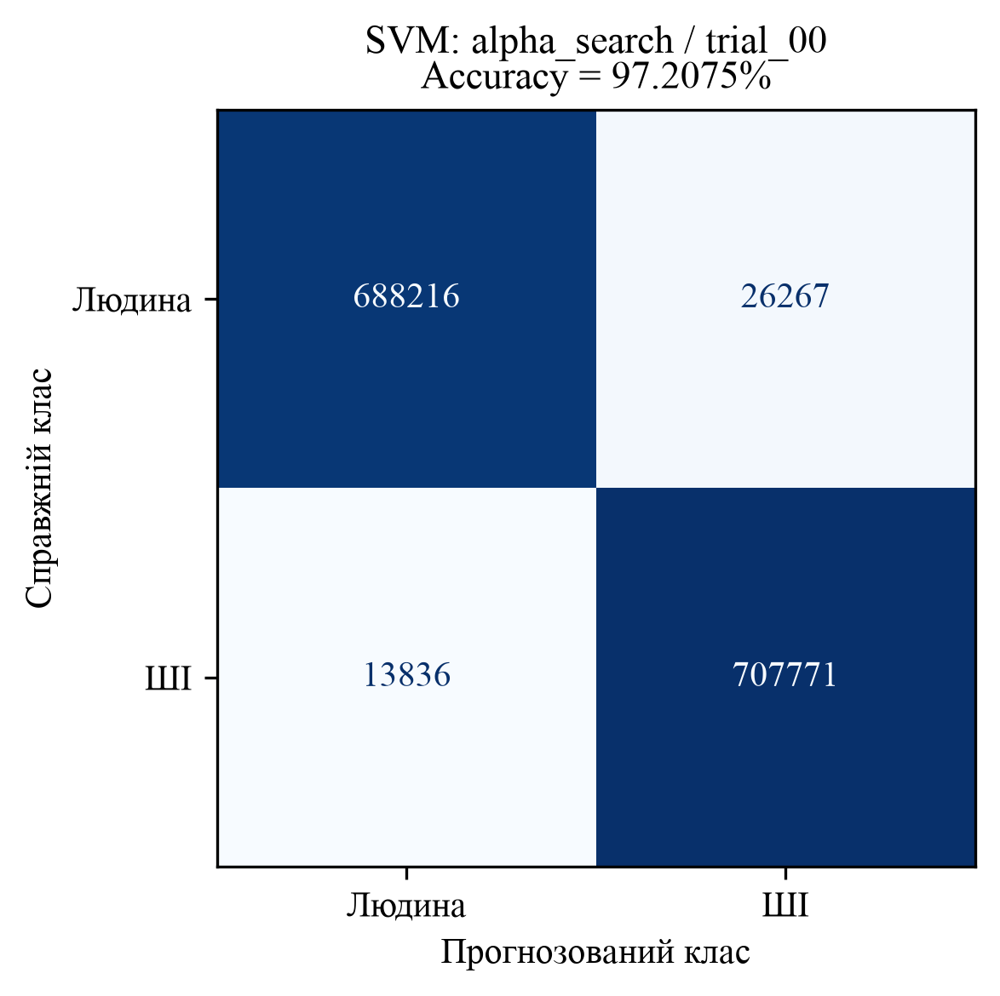


regularization_search | trial_03 | alpha=1e-06 | penalty=elasticnet | average=True | епоха 5
              precision    recall  f1-score   support

      Людина     0.9801    0.9630    0.9715    714483
          ШІ     0.9640    0.9807    0.9723    721607

    accuracy                         0.9719   1436090
   macro avg     0.9721    0.9719    0.9719   1436090
weighted avg     0.9720    0.9719    0.9719   1436090



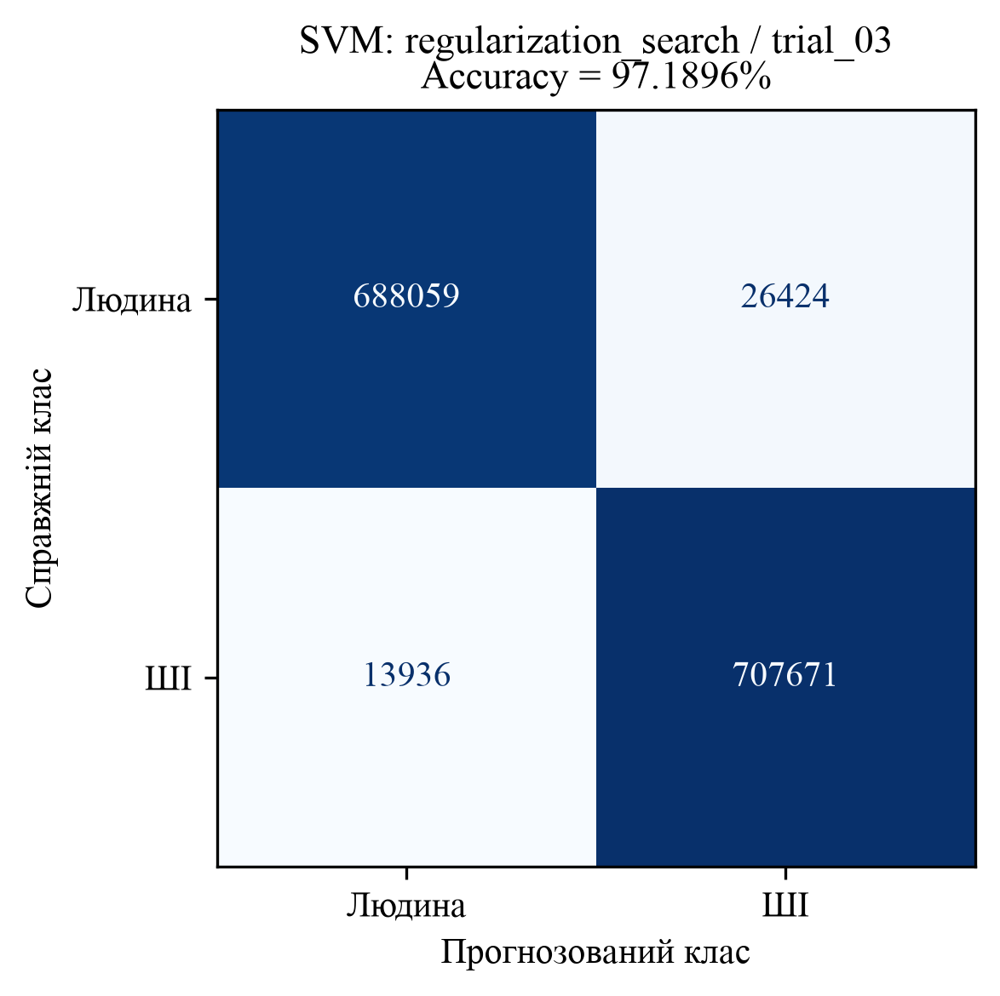


regularization_search | trial_04 | alpha=1e-06 | penalty=elasticnet | average=True | епоха 5
              precision    recall  f1-score   support

      Людина     0.9795    0.9626    0.9710    714483
          ШІ     0.9636    0.9800    0.9717    721607

    accuracy                         0.9714   1436090
   macro avg     0.9715    0.9713    0.9714   1436090
weighted avg     0.9715    0.9714    0.9714   1436090



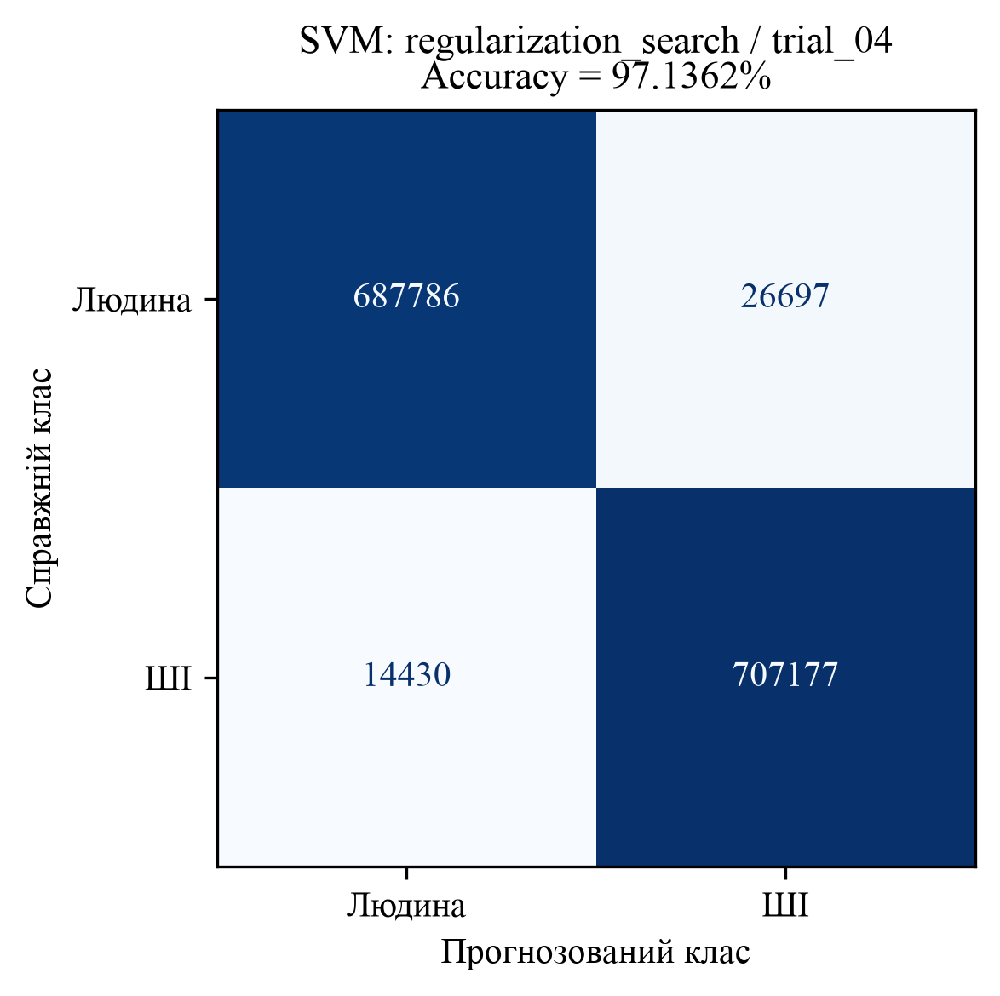


regularization_search | trial_02 | alpha=1e-06 | penalty=l1 | average=False | епоха 5
              precision    recall  f1-score   support

      Людина     0.9778    0.9623    0.9700    714483
          ШІ     0.9632    0.9784    0.9707    721607

    accuracy                         0.9704   1436090
   macro avg     0.9705    0.9703    0.9704   1436090
weighted avg     0.9705    0.9704    0.9704   1436090



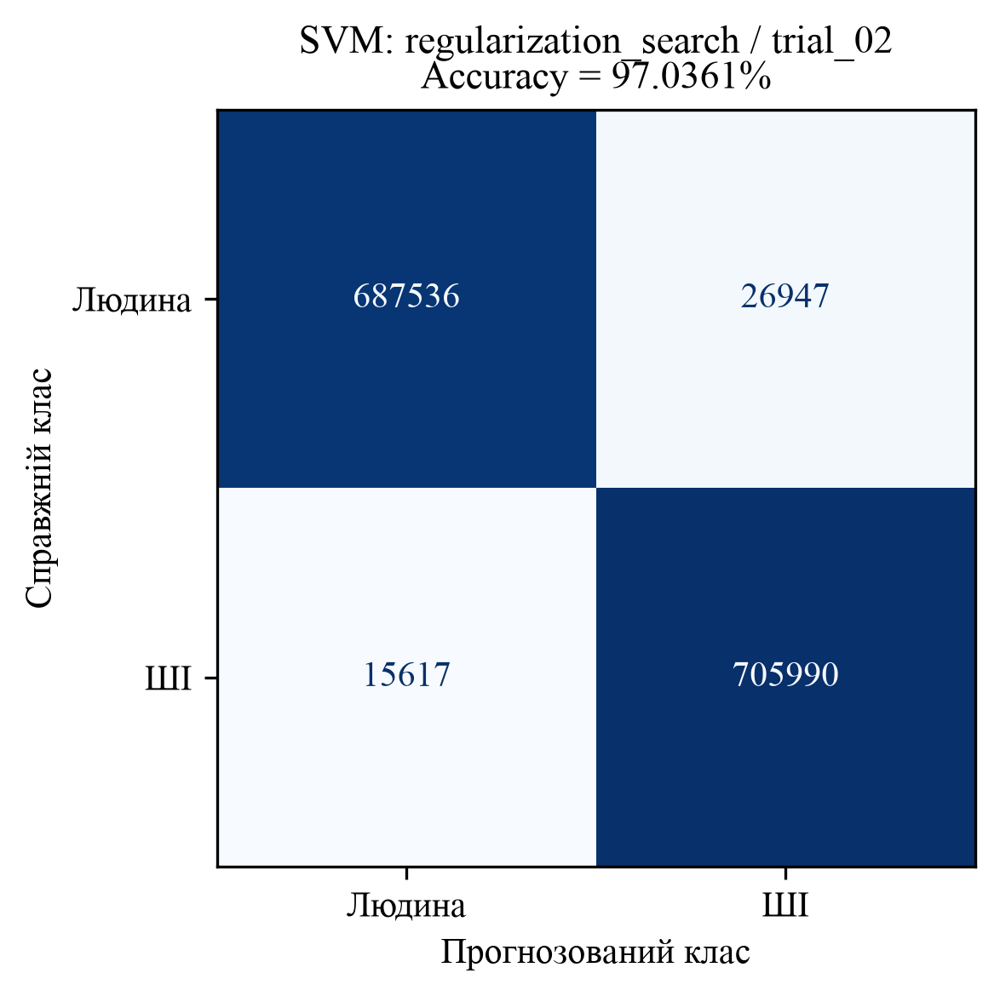


regularization_search | trial_00 | alpha=1e-06 | penalty=l1 | average=True | епоха 5
              precision    recall  f1-score   support

      Людина     0.9772    0.9624    0.9698    714483
          ШІ     0.9633    0.9778    0.9705    721607

    accuracy                         0.9701   1436090
   macro avg     0.9703    0.9701    0.9701   1436090
weighted avg     0.9702    0.9701    0.9701   1436090



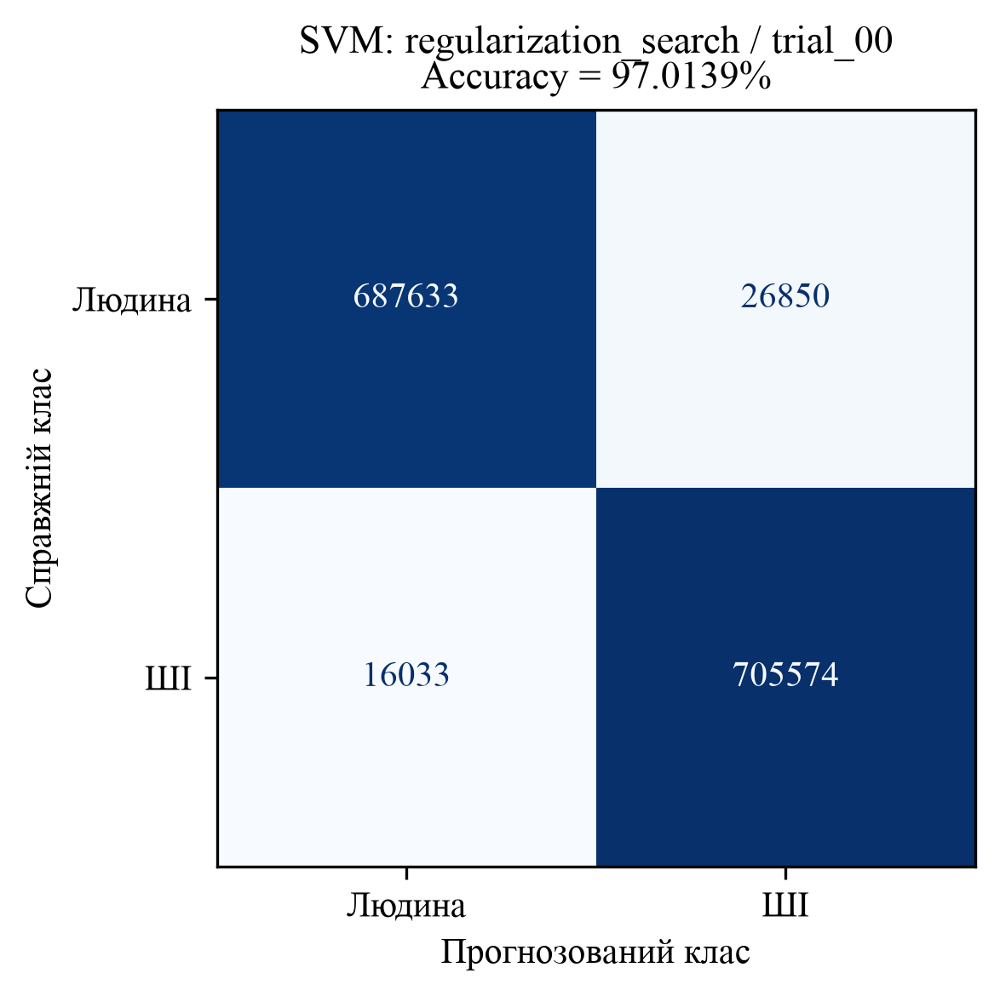


alpha_search | trial_01 | alpha=3e-06 | penalty=l2 | average=True | епоха 5
              precision    recall  f1-score   support

      Людина     0.9784    0.9560    0.9671    714483
          ШІ     0.9574    0.9791    0.9681    721607

    accuracy                         0.9676   1436090
   macro avg     0.9679    0.9675    0.9676   1436090
weighted avg     0.9678    0.9676    0.9676   1436090



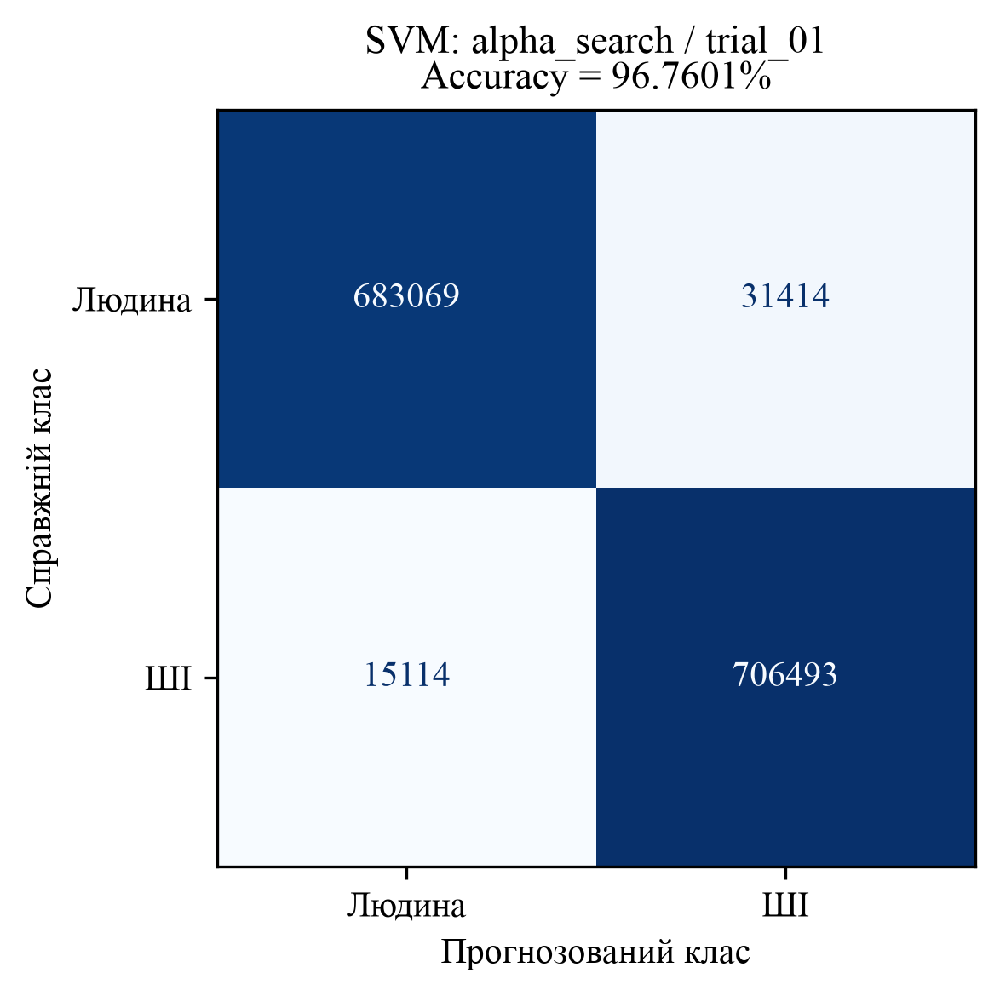


alpha_search | trial_02 | alpha=1e-05 | penalty=l2 | average=True | епоха 5
              precision    recall  f1-score   support

      Людина     0.9757    0.9448    0.9600    714483
          ШІ     0.9470    0.9767    0.9616    721607

    accuracy                         0.9608   1436090
   macro avg     0.9613    0.9607    0.9608   1436090
weighted avg     0.9613    0.9608    0.9608   1436090



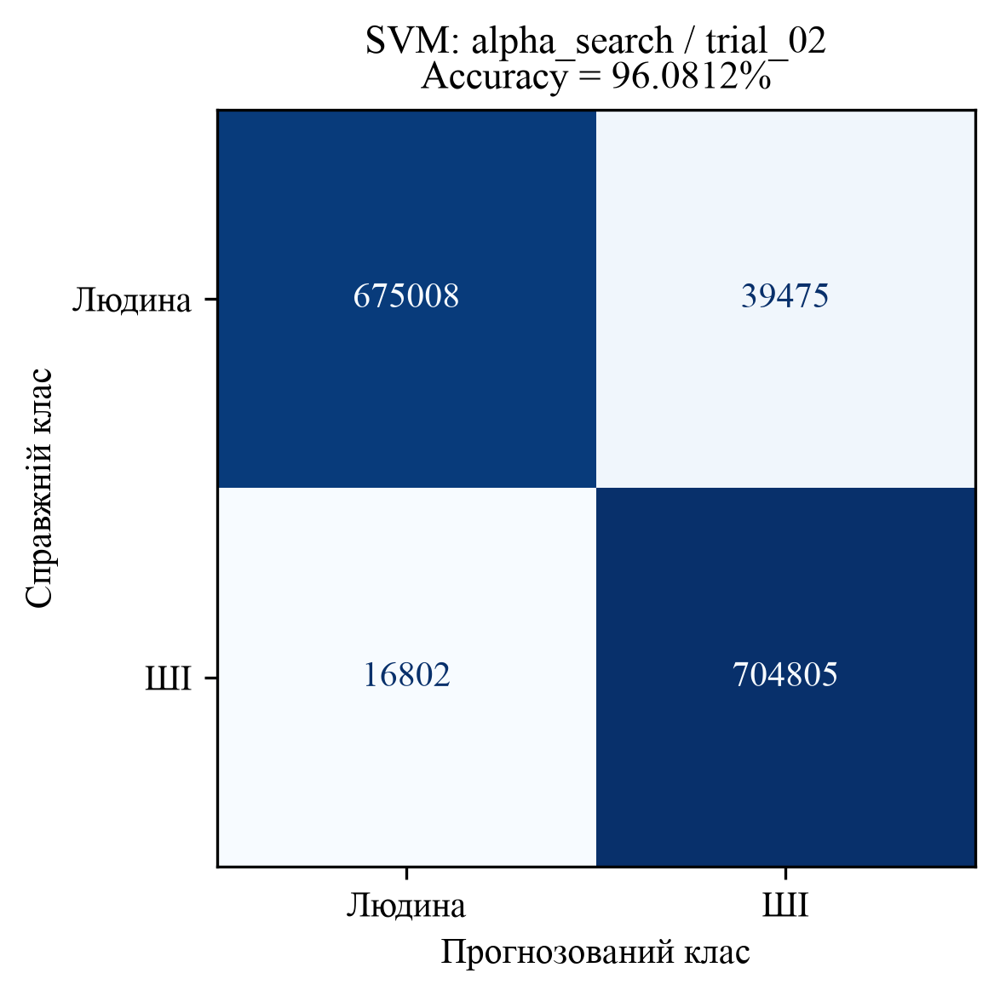


baseline | original | alpha=1e-05 | penalty=l2 | average=True | епоха 2
              precision    recall  f1-score   support

      Людина     0.9759    0.9442    0.9598    714483
          ШІ     0.9465    0.9769    0.9615    721607

    accuracy                         0.9606   1436090
   macro avg     0.9612    0.9606    0.9606   1436090
weighted avg     0.9611    0.9606    0.9606   1436090



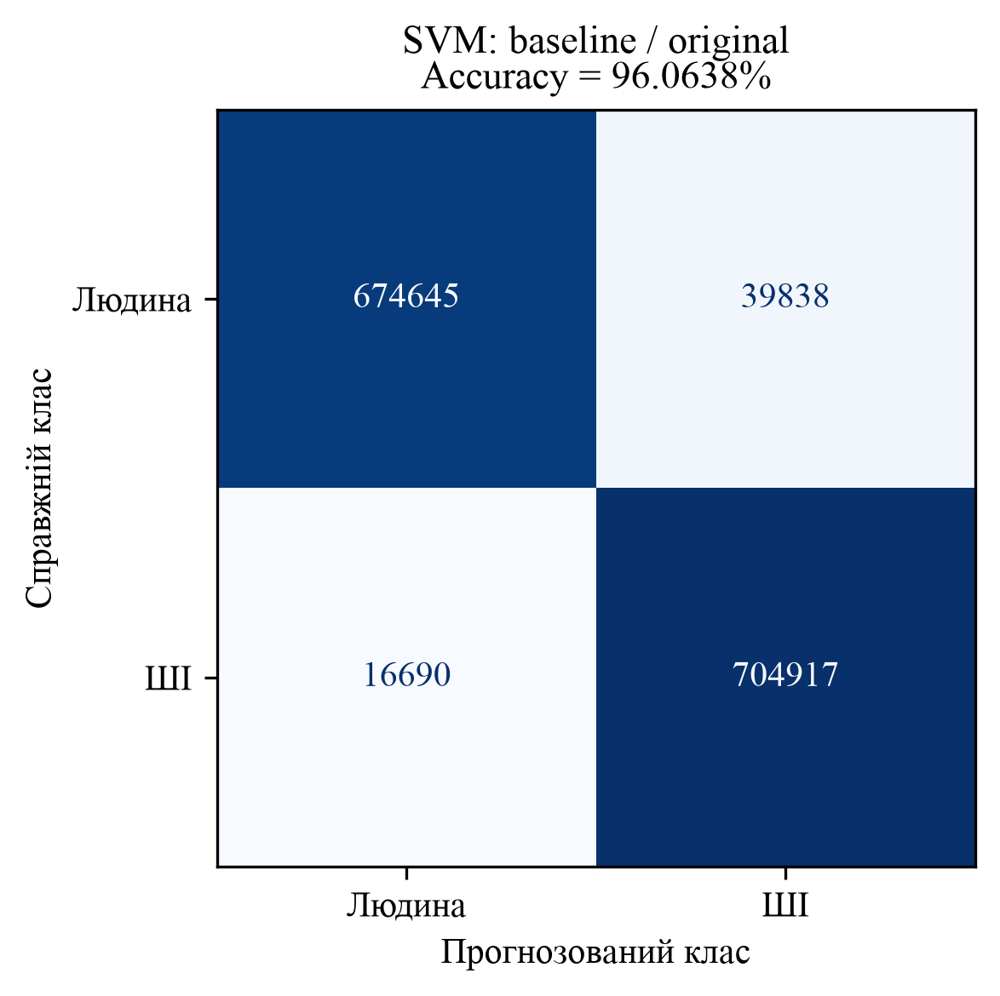


alpha_search | trial_03 | alpha=3e-05 | penalty=l2 | average=True | епоха 5
              precision    recall  f1-score   support

      Людина     0.9719    0.9291    0.9500    714483
          ШІ     0.9327    0.9734    0.9526    721607

    accuracy                         0.9513   1436090
   macro avg     0.9523    0.9512    0.9513   1436090
weighted avg     0.9522    0.9513    0.9513   1436090



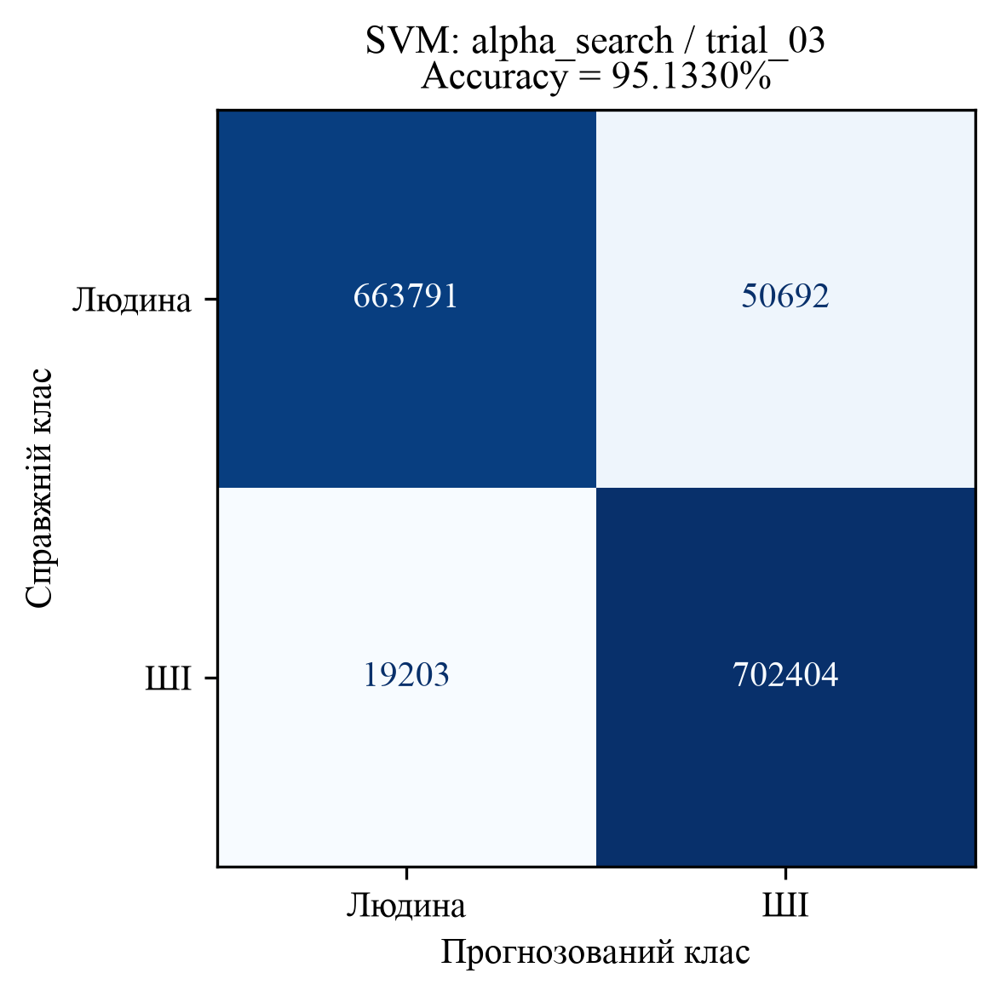


alpha_search | trial_04 | alpha=0.0001 | penalty=l2 | average=True | епоха 5
              precision    recall  f1-score   support

      Людина     0.9645    0.9051    0.9339    714483
          ШІ     0.9114    0.9670    0.9384    721607

    accuracy                         0.9362   1436090
   macro avg     0.9380    0.9361    0.9361   1436090
weighted avg     0.9379    0.9362    0.9362   1436090



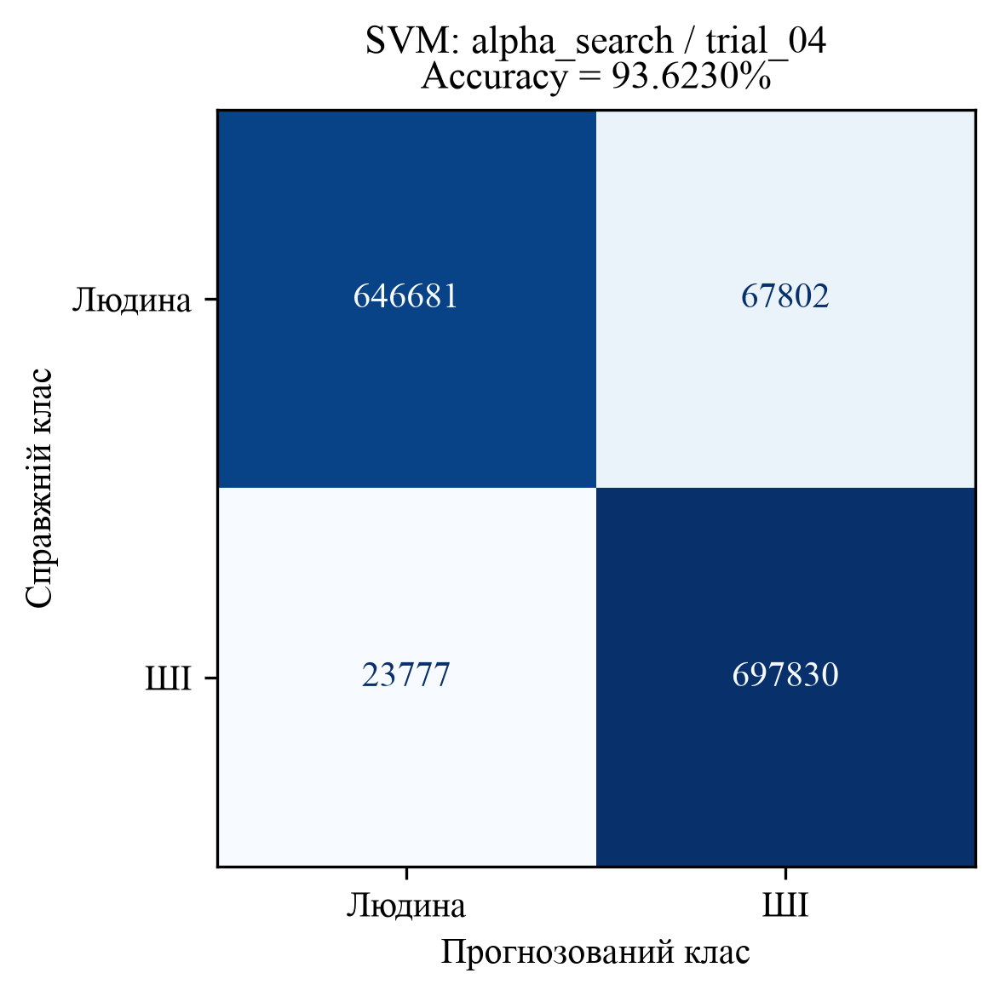

In [25]:
tuning_results = pd.read_csv(TUNE_DIR / "all_results.csv")
for _, row in tuning_results.iterrows():
    print(f"\n{row['stage']} | {row['trial']} | alpha={row['alpha']} | "
          f"penalty={row['penalty']} | average={row['average']} | епоха {int(row['epoch'])}")
    print(Path(row["report_file"]).read_text(encoding="utf-8"))
    cm = pd.read_csv(row["confusion_matrix_file"], index_col=0).to_numpy()

    with plt.rc_context({"font.family": "Times New Roman", "text.color": "black",
                         "axes.labelcolor": "black", "xtick.color": "black", "ytick.color": "black"}):
        fig, ax = plt.subplots(figsize=(6, 4), dpi=300, facecolor="white")
        ax.set_facecolor("white")
        ConfusionMatrixDisplay(cm, display_labels=["Людина", "ШІ"]).plot(
            ax=ax, cmap="Blues", colorbar=False, values_format="d")
        ax.set_title(f"SVM: {row['stage']} / {row['trial']}\nAccuracy = {row['Accuracy']:.4%}",
                     fontsize=11, linespacing=1)
        ax.set_xlabel("Прогнозований клас")
        ax.set_ylabel("Справжній клас")
        ax.grid(False)
        fig.tight_layout()
        fig.savefig(TUNE_DIR / f"{row['stage']}_{row['trial']}_confusion_matrix.png",
                    dpi=300, facecolor="white", bbox_inches="tight", pad_inches=0.05)
        plt.show()
        plt.close(fig)

### Результати тюнінгу

Усі нові файли — у `svm_tuning_o200k_char/`:

- `alpha_search/`, `regularization_search/` — кандидати, checkpoints, історія епох і звіти.
- `all_results.csv` — метрики та параметри всіх кандидатів разом із початковою моделлю.
- `best_model.joblib`, `best_parameters.json` — обраний за accuracy варіант.
- `feature_blocks.csv` — відповідність колонок двом вихідним таблицям ознак.
- `*_confusion_matrix.png` — графіки для вставки в роботу.

Оцінки в цьому розділі отримані на val, який використовуємо для підбору параметрів.
Фінальне оцінювання на test буде окремим наступним етапом.

# Навчання обраного SVM: до 15 епох із ранньою зупинкою

Використовуємо `o200k_base_1_1 + char_2_5` і параметри:
`alpha=1e-6`, `penalty="l2"`, `average=False`, `loss="hinge"`.
`l1_ratio` для L2 не використовується, тому його не передаємо.

Починаємо новий прогін **з нуля** з обраними гіперпараметрами. Попередню модель із тюнінгу зберігаємо.
Максимум — **15 епох**. Якщо accuracy на val не зростає **дві епохи поспіль**,
зупиняємо навчання й залишаємо модель найкращої епохи.
Однакова accuracy також вважається відсутністю покращення.

Кожної епохи перемішуємо порядок батчів і **рядки всередині кожного батча**.
Для матриці та міток використовуємо одну перестановку. Кожен виклик `partial_fit` обробляє цілий батч.
Test у цьому розділі не використовуємо.

## 1. Імпорти та параметри

Розділ самостійний: повторно запускати тюнінг не потрібно.
Читаємо готові TF-IDF-матриці, результати записуємо у нову папку `svm_final_o200k_char/`.

In [1]:
import gc
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import normalize
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits
from IPython.display import display

FINAL_FEATURES = Path("vectorization_sklearn/tfidf")
FINAL_DIR = Path("svm_final_o200k_char")
FINAL_DIR.mkdir(exist_ok=True)
FINAL_REPRESENTATIONS = ["o200k_base_1_1", "char_2_5"]
MAX_EPOCHS = 30
PATIENCE = 3
FINAL_SEED = 42

FINAL_PARAMS = {
    "loss": "hinge", "alpha": 1e-6, "penalty": "l2", "average": False,
    "learning_rate": "optimal", "random_state": FINAL_SEED, "n_jobs": 1,
    "shuffle": False  # Рядки явно перемішуємо самі перед кожним partial_fit.
}
display(pd.Series(FINAL_PARAMS, name="Параметри моделі"))

loss                hinge
alpha            0.000001
penalty                l2
average             False
learning_rate     optimal
random_state           42
n_jobs                  1
shuffle             False
Name: Параметри моделі, dtype: object

## 2. Перевірка збережених матриць

Порядок колонок залишається тим самим: спочатку токени, потім символи.
Зберігаємо цю відповідність для подальшого аналізу ваг класифікатора.

In [2]:
final_manifests = {}
final_data_version = []
for name in FINAL_REPRESENTATIONS:
    final_manifests[name] = {}
    for split in ["train", "val"]:
        file = FINAL_FEATURES / name / split / "manifest.json"
        info = json.loads(file.read_text())
        if not info["complete"] or sum(part["rows"] for part in info["shards"]) != info["n_rows"]:
            raise ValueError(f"Незавершені матриці: {name}, {split}")
        final_manifests[name][split] = info
        final_data_version.append((str(file.resolve()), file.stat().st_mtime_ns))
    if final_manifests[name]["train"]["n_features"] != final_manifests[name]["val"]["n_features"]:
        raise ValueError("Train і val мають різну кількість ознак.")

for split in ["train", "val"]:
    left = final_manifests[FINAL_REPRESENTATIONS[0]][split]
    right = final_manifests[FINAL_REPRESENTATIONS[1]][split]
    if [part["rows"] for part in left["shards"]] != [part["rows"] for part in right["shards"]]:
        raise ValueError("Представлення мають різний поділ на батчі.")
    print(split, "рядків:", left["n_rows"])

blocks = []
offset = 0
for name in FINAL_REPRESENTATIONS:
    size = final_manifests[name]["train"]["n_features"]
    blocks.append({"representation": name, "column_start": offset, "column_stop": offset + size,
                   "feature_table": str((FINAL_FEATURES / name / "features.parquet").resolve())})
    offset += size
pd.DataFrame(blocks).to_csv(FINAL_DIR / "feature_blocks.csv", index=False)

train рядків: 11488661
val рядків: 1436090


## 3. Читання батча та збереження моделі

Об'єднуємо два CSR-батчі, перевіряємо мітки та порядок рядків, нормалізуємо L2.
Значення залишаємо `float32`, індекси — `int32`.

In [3]:
def read_final_batch(split, number):
    parts = []
    for name in FINAL_REPRESENTATIONS:
        info = final_manifests[name][split]
        batch = info["shards"][number]
        folder = FINAL_FEATURES / name / split
        labels = np.load(folder / batch["label"])
        row_ids = np.load(folder / batch["row_id"])
        if not len(labels) == len(row_ids) == batch["rows"]:
            raise ValueError("Не збігається кількість рядків, міток та row_id.")
        if not parts:
            y, expected_ids = labels, row_ids
            start = sum(item["rows"] for item in info["shards"][:number])
            if not np.array_equal(row_ids, np.arange(start, start + len(y))) or not np.isin(y, [0, 1]).all():
                raise ValueError("Некоректні row_id або мітки.")
        elif not (np.array_equal(labels, y) and np.array_equal(row_ids, expected_ids)):
            raise ValueError("У двох представленнях різний порядок текстів або мітки.")

        X = sparse.load_npz(folder / batch["file"])
        if X.format != "csr" or X.dtype != np.float32 or X.shape != (len(y), info["n_features"]):
            raise ValueError("Очікуємо CSR float32 відповідного розміру.")
        parts.append(X)

    if max(sum(part.nnz for part in parts), sum(part.shape[1] for part in parts), len(y)) > np.iinfo(np.int32).max:
        raise OverflowError("Об'єднаний батч перевищує межу int32.")
    X = sparse.hstack(parts, format="csr", dtype=np.float32)
    X.indices = X.indices.astype(np.int32, copy=False)
    X.indptr = X.indptr.astype(np.int32, copy=False)
    normalize(X, norm="l2", copy=False)
    return X, y



def save_final_model(file, value):
    temporary = file.with_suffix(".tmp")
    joblib.dump(value, temporary)
    temporary.replace(file)

## 4. Accuracy та loss на всій вибірці

Після епохи фіксуємо ваги моделі та окремо оцінюємо **весь train і весь val**.
Train-метрики не є середнім показників, отриманих під час оновлення ваг.
Це додатковий повний прохід по train після кожної епохи.

Loss — середній **hinge loss**: `max(0, 1 - y_signed * score)`, де `y_signed` дорівнює −1 для людини
та +1 для ШІ. Рахуємо за цією формулою через NumPy, без доданку регуляризації L2.
Явне перетворення міток працює також для батча, що містить лише один клас.
Кількість правильних прогнозів та сумарний loss ділимо на загальну кількість текстів,
тому менший останній батч враховується правильно.

In [4]:
def score_final_model(model, split, keep_predictions=False):
    correct = 0
    loss_sum = 0.0
    total = 0
    labels = []
    predictions = []
    info = final_manifests[FINAL_REPRESENTATIONS[0]][split]

    for number in range(len(info["shards"])):
        X, y = read_final_batch(split, number)
        scores = model.decision_function(X).astype(np.float64)
        y_pred = (scores > 0).astype(np.int8)
        correct += int(np.count_nonzero(y_pred == y))
        signed_y = 2 * y.astype(np.float64) - 1
        loss_sum += float(np.maximum(0.0, 1.0 - signed_y * scores).sum())
        total += len(y)
        if keep_predictions:
            labels.append(y.astype(np.int8))
            predictions.append(y_pred)
        del X, y, scores, y_pred, signed_y
        gc.collect()
        if (number + 1) % 10 == 0 or number + 1 == len(info["shards"]):
            print(f"Оцінювання {split}: {number + 1}/{len(info['shards'])}", flush=True)

    if total != info["n_rows"]:
        raise ValueError("Опрацьовано не всі рядки вибірки.")
    result = {"accuracy": correct / total, "loss": loss_sum / total}
    if keep_predictions:
        result["labels"] = np.concatenate(labels)
        result["predictions"] = np.concatenate(predictions)
    return result

## 5. Навчання, shuffle рядків та рання зупинка

Для кожного батча створюємо відтворювану перестановку, залежну від номера епохи й батча.
Після перемішування `X` і `y` навчаємо модель через `partial_fit`.

Критерій покращення — **строго більша accuracy на val**. Loss показуємо на графіку,
але він не керує ранньою зупинкою. При покращенні лічильник невдалих епох скидаємо до нуля.

Після кожного навчального батча зберігаємо checkpoint. Повторний запуск продовжує прогін
з останнього завершеного батча, зі збереженим лічильником ранньої зупинки.
При зміні даних або налаштувань задайте іншу `FINAL_DIR`.

In [5]:
def train_final_svm():
    checkpoint = FINAL_DIR / "checkpoint.joblib"
    settings = {"params": FINAL_PARAMS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
                "data_version": final_data_version, "row_shuffle": "seed_epoch_batch_v1"}
    if checkpoint.exists():
        state = joblib.load(checkpoint)
        if state["settings"] != settings:
            raise ValueError("Змінилися дані або параметри. Задайте іншу FINAL_DIR.")
        print("Завантажено checkpoint.", flush=True)
    else:
        state = {"settings": settings, "model": SGDClassifier(**FINAL_PARAMS),
                 "epoch": 0, "next_batch": 0, "history": [],
                 "best_accuracy": -1.0, "best_epoch": 0, "bad_epochs": 0}

    batch_count = len(final_manifests[FINAL_REPRESENTATIONS[0]]["train"]["shards"])
    with threadpool_limits(limits=1):
        for epoch in range(state["epoch"], MAX_EPOCHS):
            if state["bad_epochs"] >= PATIENCE:
                print("Навчання вже завершене ранньою зупинкою.", flush=True)
                break
            print(f"Епоха {epoch + 1}/{MAX_EPOCHS}", flush=True)
            batch_order = np.random.default_rng(FINAL_SEED + epoch).permutation(batch_count)

            for position in range(state["next_batch"], batch_count):
                number = int(batch_order[position])
                X, y = read_final_batch("train", number)

                # Одна перестановка для рядків матриці та відповідних міток.
                rng = np.random.default_rng(np.random.SeedSequence([FINAL_SEED, epoch, number]))
                row_order = rng.permutation(len(y))
                X = X[row_order]
                y = y[row_order]
                X.indices = X.indices.astype(np.int32, copy=False)
                X.indptr = X.indptr.astype(np.int32, copy=False)
                state["model"].partial_fit(X, y, classes=[0, 1])

                state["next_batch"] = position + 1
                save_final_model(checkpoint, state)
                del X, y, row_order
                gc.collect()
                if (position + 1) % 10 == 0 or position + 1 == batch_count:
                    print(f"Train: батч {position + 1}/{batch_count}", flush=True)

            
            val = score_final_model(state["model"], "val", keep_predictions=True)
            row = {"epoch": epoch + 1, 
                   "val_accuracy": val["accuracy"], "val_loss": val["loss"]}
            state["history"].append(row)

            if val["accuracy"] > state["best_accuracy"]:
                state["best_accuracy"] = val["accuracy"]
                state["best_epoch"] = epoch + 1
                state["bad_epochs"] = 0
                save_final_model(FINAL_DIR / "best_model.joblib", state["model"])
                np.save(FINAL_DIR / "val_labels.npy", val["labels"])
                np.save(FINAL_DIR / "val_predictions.npy", val["predictions"])
                pd.Series(row).to_json(FINAL_DIR / "best_metrics.json", indent=2)
            else:
                state["bad_epochs"] += 1

            state["epoch"] = epoch + 1
            state["next_batch"] = 0
            pd.DataFrame(state["history"]).to_csv(FINAL_DIR / "history.csv", index=False)
            save_final_model(checkpoint, state)
            print(f"Val accuracy: {val['accuracy']:.6f}")
            print(f"Val loss: {val['loss']:.6f}")
            print(f"Епох без покращення: {state['bad_epochs']}/{PATIENCE}", flush=True)
            del  val
            gc.collect()
            if state["bad_epochs"] >= PATIENCE:
                print("Рання зупинка: дві епохи без покращення accuracy на val.", flush=True)
                break

    history = pd.DataFrame(state["history"])
    print("Завершено епох:", state["epoch"])
    print("Найкраща епоха:", state["best_epoch"])
    print(f"Найкраща accuracy на val: {state['best_accuracy']:.4%}")
    metadata = {"params": FINAL_PARAMS, "representations": FINAL_REPRESENTATIONS,
                "best_epoch": state["best_epoch"], "completed_epochs": state["epoch"],
                "best_val_accuracy": state["best_accuracy"], "max_epochs": MAX_EPOCHS,
                "patience": PATIENCE, "stopped_early": state["bad_epochs"] >= PATIENCE}
    (FINAL_DIR / "training_summary.json").write_text(
        json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
    del state
    gc.collect()
    return history

## 6. Запуск навчання

Ця комірка навчає модель або продовжує збережений прогін.
Таблиця містить train/val accuracy та hinge loss після кожної завершеної епохи.

In [6]:
final_history = train_final_svm()
display(final_history.round(6))

Епоха 1/30
Train: батч 10/230
Train: батч 20/230
Train: батч 30/230
Train: батч 40/230
Train: батч 50/230
Train: батч 60/230
Train: батч 70/230
Train: батч 80/230
Train: батч 90/230
Train: батч 100/230
Train: батч 110/230
Train: батч 120/230
Train: батч 130/230
Train: батч 140/230
Train: батч 150/230
Train: батч 160/230
Train: батч 170/230
Train: батч 180/230
Train: батч 190/230
Train: батч 200/230
Train: батч 210/230
Train: батч 220/230
Train: батч 230/230
Оцінювання val: 10/29
Оцінювання val: 20/29
Оцінювання val: 29/29
Val accuracy: 0.971240
Val loss: 0.077541
Епох без покращення: 0/3
Епоха 2/30
Train: батч 10/230
Train: батч 20/230
Train: батч 30/230
Train: батч 40/230
Train: батч 50/230
Train: батч 60/230
Train: батч 70/230
Train: батч 80/230
Train: батч 90/230
Train: батч 100/230
Train: батч 110/230
Train: батч 120/230
Train: батч 130/230
Train: батч 140/230
Train: батч 150/230
Train: батч 160/230
Train: батч 170/230
Train: батч 180/230
Train: батч 190/230
Train: батч 200/230
Tra

,epoch,val_accuracy,val_loss
0,1,0.971240,0.077541
1,2,0.971883,0.077317
2,3,0.971019,0.079768
3,4,0.972773,0.072663
4,5,0.973511,0.070082
5,6,0.973988,0.068520
6,7,0.974371,0.067555
7,8,0.974667,0.066713
8,9,0.975027,0.066179
9,10,0.975177,0.065650


## 7. Результат найкращої епохи на val

Завантажуємо збережені прогнози **найкращої**, а не останньої епохи.
Виводимо Accuracy, Precision, Recall, F1 Score, classification report та confusion matrix.
Precision, Recall і F1 Score у підсумковому рядку — для класу ШІ (`label=1`).

Завершено епох: 30
Найкраща епоха: 30
Рання зупинка: False


,Найкраща епоха
epoch,30.000000
val_accuracy,0.976459
val_loss,0.062279


              precision    recall  f1-score   support

      Людина     0.9821    0.9704    0.9762    714483
          ШІ     0.9710    0.9825    0.9767    721607

    accuracy                         0.9765   1436090
   macro avg     0.9766    0.9764    0.9765   1436090
weighted avg     0.9765    0.9765    0.9765   1436090



,epoch,Accuracy,Precision,Recall,F1 Score,Hinge loss
0,30,0.976459,0.971026,0.982466,0.976712,0.062279


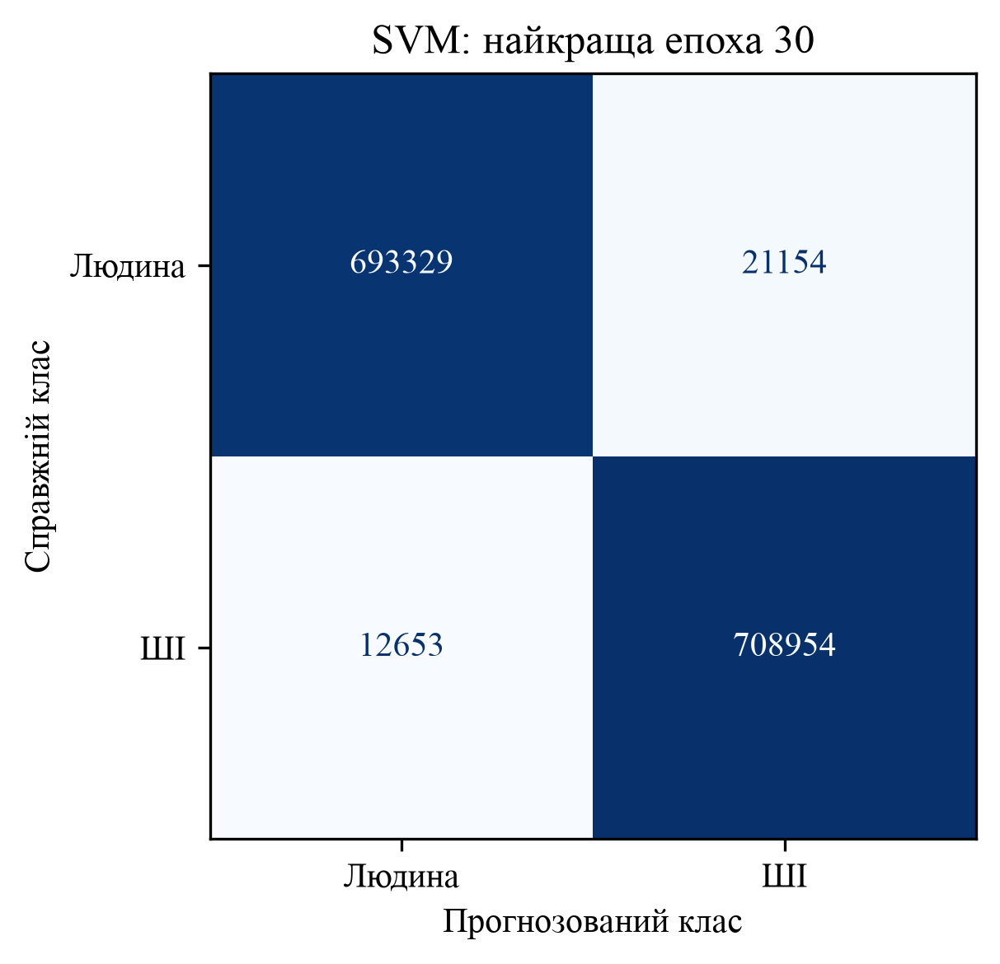

5

In [7]:
summary = json.loads((FINAL_DIR / "training_summary.json").read_text())
best_metrics = json.loads((FINAL_DIR / "best_metrics.json").read_text())
y_true = np.load(FINAL_DIR / "val_labels.npy")
y_pred = np.load(FINAL_DIR / "val_predictions.npy")

print("Завершено епох:", summary["completed_epochs"])
print("Найкраща епоха:", summary["best_epoch"])
print("Рання зупинка:", summary["stopped_early"])
display(pd.Series(best_metrics, name="Найкраща епоха").to_frame())

report = classification_report(y_true, y_pred, labels=[0, 1],
             target_names=["Людина", "ШІ"], output_dict=True, zero_division=0)
report_text = classification_report(y_true, y_pred, labels=[0, 1],
             target_names=["Людина", "ШІ"], digits=4, zero_division=0)
print(report_text)
(FINAL_DIR / "classification_report.txt").write_text(report_text, encoding="utf-8")
(FINAL_DIR / "classification_report.json").write_text(
    json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8")

result = pd.DataFrame([{"epoch": summary["best_epoch"], "Accuracy": accuracy_score(y_true, y_pred),
                       "Precision": report["ШІ"]["precision"], "Recall": report["ШІ"]["recall"],
                       "F1 Score": report["ШІ"]["f1-score"], "Hinge loss": best_metrics["val_loss"]}])
result.to_csv(FINAL_DIR / "validation_results.csv", index=False)
display(result.round(6))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
pd.DataFrame(cm, index=["Людина", "ШІ"], columns=["Людина", "ШІ"]).to_csv(FINAL_DIR / "confusion_matrix.csv")
with plt.rc_context({"font.family": "Times New Roman", "text.color": "black",
                     "axes.labelcolor": "black", "xtick.color": "black", "ytick.color": "black"}):
    fig, ax = plt.subplots(figsize=(6, 4), dpi=300, facecolor="white")
    ax.set_facecolor("white")
    ConfusionMatrixDisplay(cm, display_labels=["Людина", "ШІ"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"SVM: найкраща епоха {summary['best_epoch']}", linespacing=1)
    ax.set_xlabel("Прогнозований клас")
    ax.set_ylabel("Справжній клас")
    ax.grid(False)
    fig.tight_layout()
    fig.savefig(FINAL_DIR / "confusion_matrix.png", dpi=300, facecolor="white",
                bbox_inches="tight", pad_inches=0.05)
    plt.show()
    plt.close(fig)

del y_true, y_pred
gc.collect()

## 8. Спільна процедура побудови графіків навчання

Читаємо історію з диска. На кожному графіку показуємо лише val,
пунктиром позначаємо найкращу епоху за accuracy на val.
Зображення виводимо та зберігаємо: Times New Roman, білий фон, 300 dpi, мінімальні поля.

In [8]:
def plot_final_history(metric, ylabel, filename):
    history = pd.read_csv(FINAL_DIR / "history.csv")
    summary = json.loads((FINAL_DIR / "training_summary.json").read_text())
    with plt.rc_context({"font.family": "Times New Roman", "text.color": "black",
                         "axes.labelcolor": "black", "xtick.color": "black", "ytick.color": "black"}):
        fig, ax = plt.subplots(figsize=(8, 4), dpi=300, facecolor="white")
        ax.set_facecolor("white")
        ax.plot(history["epoch"], history[f"val_{metric}"], marker="o", color="#e58b50", label="Val")
        ax.axvline(summary["best_epoch"], linestyle="--", color="#666666", label="Найкраща епоха")
        ax.set(title=f"SVM: {ylabel} на val", xlabel="Епоха", ylabel=ylabel)
        ax.set_xticks(history["epoch"])
        ax.grid(axis="y", color="#dddddd")
        ax.grid(axis="x", visible=False)
        ax.spines[["top", "right"]].set_visible(False)
        legend = ax.legend()
        for text in [ax.title, ax.xaxis.label, ax.yaxis.label, *legend.get_texts()]:
            text.set_linespacing(1)
        fig.tight_layout()
        fig.savefig(FINAL_DIR / filename, dpi=300, facecolor="white",
                    bbox_inches="tight", pad_inches=0.05)
        plt.show()
        plt.close(fig)

### Accuracy на val


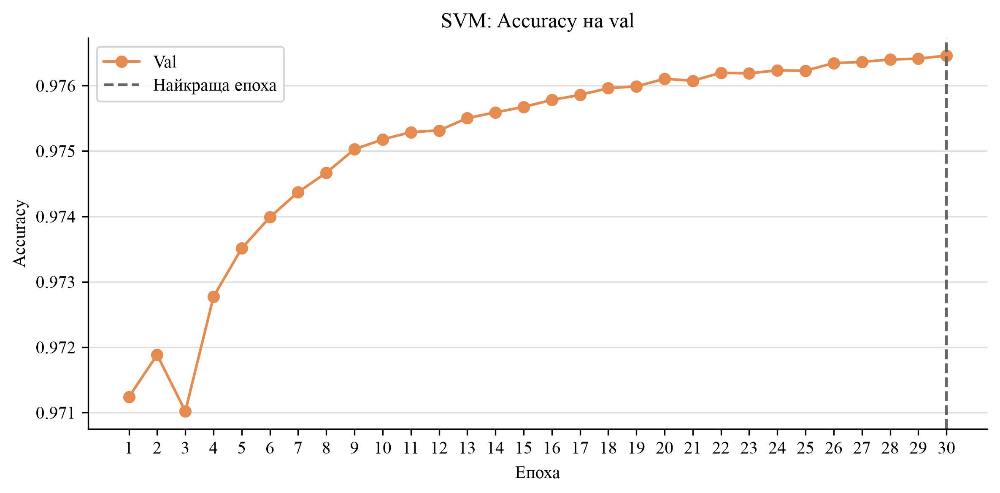

In [9]:
plot_final_history("accuracy", "Accuracy", "accuracy_by_epoch.png")

### Hinge loss на val


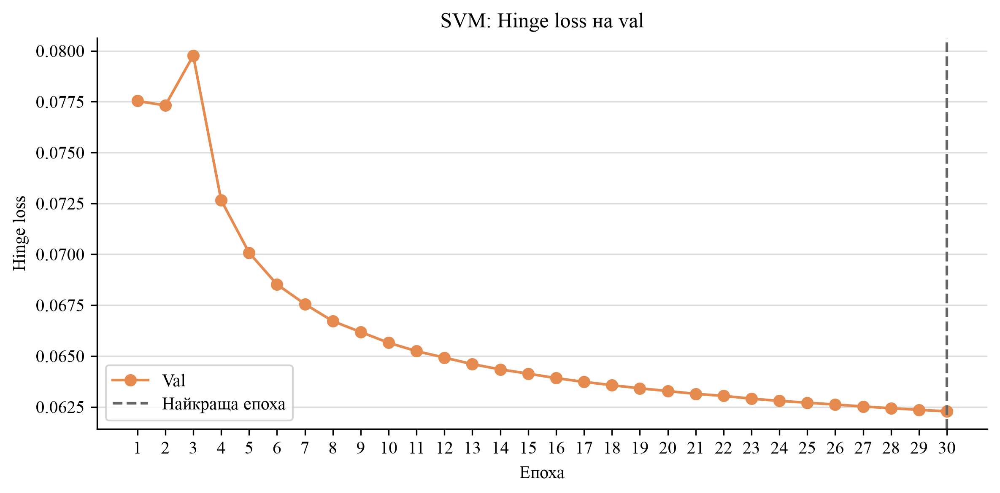

In [10]:
plot_final_history("loss", "Hinge loss", "loss_by_epoch.png")

### Збережені результати

Усі файли — у `svm_final_o200k_char/`:

- `best_model.joblib` — модель найкращої епохи за accuracy на val.
- `checkpoint.joblib` — поточна модель, позиція батча, історія та лічильник ранньої зупинки.
- `history.csv` — train/val accuracy та hinge loss для всіх завершених епох.
- `training_summary.json`, `best_metrics.json` — параметри та підсумок навчання.
- `val_labels.npy`, `val_predictions.npy` — мітки та прогнози найкращої епохи на val.
- `validation_results.csv`, `classification_report.txt`, `classification_report.json` — метрики.
- `confusion_matrix.csv`, `confusion_matrix.png` — матриця помилок.
- `accuracy_by_epoch.png`, `loss_by_epoch.png` — графіки навчання.
- `feature_blocks.csv` — відповідність колонок вихідним ознакам.

## Збереження результуючої моделі

Після завершення навчання зберігаємо окремий файл `final_svm_model.joblib`.
Беремо модель найкращої епохи за accuracy на val з `best_model.joblib`.


In [11]:
import gc
import joblib

final_model = joblib.load("svm_final_o200k_char/best_model.joblib")
joblib.dump(final_model, "final_svm_model.joblib", compress=3)

print("Збережено результуючу модель: final_svm_model.joblib")

del final_model
gc.collect()


Збережено результуючу модель: final_svm_model.joblib


9929

# Калібрування ймовірностей SVM: sigmoid та isotonic

Використовуємо збережений SVM для `o200k_base_1_1 + char_2_5`.
Навчаємо два калібратори на **всьому val**, ваги SVM залишаємо незмінними:

- **Sigmoid** — логістична регресія з однією ознакою, оцінкою SVM.
- **Isotonic** — монотонне нелінійне перетворення оцінки SVM на ймовірність.

На **всьому test** порівнюємо початковий варіант і два відкалібровані:
виводимо метрики, classification reports та один спільний графік калібрування.
Test не бере участі у навчанні SVM, словників, IDF або калібраторів.

Якщо за результатами test обираємо метод калібрування, test стає набором для порівняння методів;
остаточна незалежна оцінка обраного варіанта потребуватиме інших відкладених даних.
Опис методів: [Probability calibration, scikit-learn](https://scikit-learn.org/stable/modules/calibration.html).

## 1. Імпорти та параметри

Використовуємо `read_final_batch`, `final_manifests` і `FINAL_REPRESENTATIONS` із розділу фінального навчання.
Якщо kernel перезапущено, виконайте там лише імпорти, перевірку матриць і визначення читання батча.
Повторне навчання SVM та тюнінг не потрібні.

Нові результати зберігаємо у `svm_calibration_full_val/`, окремо від попереднього експерименту.

In [12]:
import os
os.environ.setdefault("TIKTOKEN_CACHE_DIR", "vectorization_sklearn/tiktoken_cache")

import gc
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import tiktoken
from scipy import sparse
from scipy.special import expit
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import normalize
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, brier_score_loss, log_loss
from threadpoolctl import threadpool_limits
from IPython.display import display

CALIBRATION_DIR = Path("svm_calibration_full_val")
CALIBRATION_DIR.mkdir(exist_ok=True)
CALIBRATION_FEATURES = Path("vectorization_sklearn/tfidf")
MODEL_FILE = Path("final_svm_model.joblib")
TEST_FILE = Path("test.parquet")
CALIBRATION_BATCH_SIZE = 50_000
CALIBRATION_THREADS = 8
pa.set_cpu_count(CALIBRATION_THREADS)

svm_model = joblib.load(MODEL_FILE)
if not np.array_equal(svm_model.classes_, [0, 1]):
    raise ValueError("Очікуємо класи 0 — людина, 1 — ШІ.")
if FINAL_REPRESENTATIONS != ["o200k_base_1_1", "char_2_5"]:
    raise ValueError("Потрібен порядок ознак: o200k_base_1_1, потім char_2_5.")

## 2. TF-IDF для test із готовими словниками та IDF

Словник та IDF беремо **з train**. Викликаємо лише `transform` — на test нічого не підбираємо.
Для токенів використовуємо той самий `o200k_base`, 8 потоків та цілі батчі по 50 000 текстів.
Для символів зберігаємо n-грами `(2, 5)` і параметри попередньої векторизації.

Після кожного батча зберігаємо CSR `float32` з індексами `int32`, мітки та `row_id`.
Завершені батчі можна використати повторно, а незавершений прохід — продовжити.

In [13]:
def save_calibration_json(file, value):
    temporary = file.with_suffix(file.suffix + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")
    temporary.replace(file)


def prepare_test_tfidf(name):
    folder = CALIBRATION_FEATURES / name
    destination = folder / "test"
    destination.mkdir(exist_ok=True)
    cfg = json.loads((folder / "fit_info.json").read_text())["cfg"]
    settings = {"input": str(TEST_FILE.resolve()), "bytes": TEST_FILE.stat().st_size,
                "mtime_ns": TEST_FILE.stat().st_mtime_ns, "cfg": cfg,
                "vocabulary_mtime": (folder / "vocabulary.json").stat().st_mtime_ns,
                "idf_mtime": (folder / "idf.npy").stat().st_mtime_ns,
                "batch_size": CALIBRATION_BATCH_SIZE, "engine": "calibration_test_v1"}
    manifest_file = destination / "manifest.json"
    manifest = {"settings": settings, "split": "test", "n_rows": 0,
                "shards": [], "complete": False}
    if manifest_file.exists():
        manifest = json.loads(manifest_file.read_text())
        if manifest["settings"] != settings:
            raise ValueError("Дані або параметри test змінилися. Використайте іншу папку матриць.")
        if manifest["complete"]:
            print("Test уже векторизовано:", name)
            return manifest

    vocabulary = json.loads((folder / "vocabulary.json").read_text())
    idf = np.load(folder / "idf.npy").astype(np.float32)
    if len(vocabulary) != len(idf) or not np.isfinite(idf).all():
        raise ValueError("Некоректний словник або IDF.")
    manifest["n_features"] = len(vocabulary)
    tokenizer = None
    if name == "o200k_base_1_1":
        if tuple(cfg["ngram_range"]) != (1, 1):
            raise ValueError("Очікуємо TF-IDF окремих токенів.")
        tokenizer = tiktoken.get_encoding("o200k_base")
        vectorizer = CountVectorizer(analyzer=lambda tokens: map(str, tokens),
                                     vocabulary=vocabulary, dtype=np.float32)
    else:
        vectorizer = CountVectorizer(analyzer=cfg["analyzer"], ngram_range=tuple(cfg["ngram_range"]),
                                     lowercase=cfg["lowercase"], vocabulary=vocabulary, dtype=np.float32)

    parquet = pq.ParquetFile(TEST_FILE)
    completed = len(manifest["shards"])
    offset = 0
    for number, batch in enumerate(parquet.iter_batches(batch_size=CALIBRATION_BATCH_SIZE,
                                      columns=["text", "label"], use_threads=True)):
        start = offset
        offset += batch.num_rows
        if number < completed:
            if manifest["shards"][number]["rows"] != batch.num_rows:
                raise ValueError("Змінилися розміри збережених батчів test.")
            continue
        texts = batch.column(0).to_pylist()
        labels = np.asarray(batch.column(1).to_pylist())
        if not np.isin(labels, [0, 1]).all() or any(not isinstance(text, str) for text in texts):
            raise ValueError("Некоректний текст або label у test.")
        documents = texts
        if tokenizer is not None:
            documents = tokenizer.encode_batch(texts, num_threads=CALIBRATION_THREADS, disallowed_special=())
        X = vectorizer.transform(documents)
        if max(X.nnz, *X.shape) > np.iinfo(np.int32).max:
            raise OverflowError("Батч перевищує межу int32.")
        if cfg.get("sublinear_tf", True):
            np.log(X.data, out=X.data)
            X.data += 1
        X.data *= idf[X.indices]
        normalize(X, norm="l2", copy=False)
        if not np.isfinite(X.data).all():
            raise ValueError("Некоректні значення TF-IDF.")
        X.indices = X.indices.astype(np.int32, copy=False)
        X.indptr = X.indptr.astype(np.int32, copy=False)

        stem = f"batch_{number:06d}"
        sparse.save_npz(destination / f"{stem}.npz", X)
        np.save(destination / f"{stem}_label.npy", labels.astype(np.int8))
        np.save(destination / f"{stem}_row_id.npy", np.arange(start, offset, dtype=np.int64))
        manifest["shards"].append({"file": f"{stem}.npz", "label": f"{stem}_label.npy",
            "row_id": f"{stem}_row_id.npy", "rows": len(labels), "shape": list(X.shape),
            "nnz": int(X.nnz), "dtype": "float32", "index_dtype": "int32"})
        manifest["n_rows"] += len(labels)
        save_calibration_json(manifest_file, manifest)
        print(name, "test — збережено рядків:", manifest["n_rows"], flush=True)
        del texts, documents, labels, X, batch
        gc.collect()

    if manifest["n_rows"] != parquet.metadata.num_rows:
        raise ValueError("Векторизовано не всі рядки test.")
    parquet.close()
    manifest["complete"] = True
    save_calibration_json(manifest_file, manifest)
    return manifest

### Test: токени o200k_base

In [14]:
test_token_info = prepare_test_tfidf("o200k_base_1_1")
print("Рядків test:", test_token_info["n_rows"])
gc.collect()

Test уже векторизовано: o200k_base_1_1
Рядків test: 1436090


0

### Test: символьні n-грами

In [15]:
test_char_info = prepare_test_tfidf("char_2_5")
print("Рядків test:", test_char_info["n_rows"])
gc.collect()

Test уже векторизовано: char_2_5
Рядків test: 1436090


0

## 3. Оцінки SVM на val і test

Додаємо готові test-маніфести до опису матриць. `read_final_batch` об'єднує ознаки
в тому самому порядку та перевіряє відповідність міток і рядків.
Зберігаємо лише оцінки SVM і мітки; великі матриці залишаються на диску.

In [16]:
for name in FINAL_REPRESENTATIONS:
    file = CALIBRATION_FEATURES / name / "test" / "manifest.json"
    final_manifests[name]["test"] = json.loads(file.read_text())
    info = final_manifests[name]["test"]
    if not info["complete"] or info["n_features"] != final_manifests[name]["train"]["n_features"]:
        raise ValueError("Test не завершений або має інші ознаки.")
left = final_manifests[FINAL_REPRESENTATIONS[0]]["test"]
right = final_manifests[FINAL_REPRESENTATIONS[1]]["test"]
if [part["rows"] for part in left["shards"]] != [part["rows"] for part in right["shards"]]:
    raise ValueError("Різний поділ test на батчі.")


def collect_calibration_scores(split):
    info = final_manifests[FINAL_REPRESENTATIONS[0]][split]
    scores = np.empty(info["n_rows"], dtype=np.float64)
    labels = np.empty(info["n_rows"], dtype=np.int8)
    position = 0
    with threadpool_limits(limits=1):
        for number in range(len(info["shards"])):
            X, y = read_final_batch(split, number)
            end = position + len(y)
            scores[position:end] = svm_model.decision_function(X)
            labels[position:end] = y
            position = end
            del X, y
            gc.collect()
            print(f"{split}: оцінки SVM {number + 1}/{len(info['shards'])}", flush=True)
    if position != info["n_rows"] or not np.isfinite(scores).all():
        raise ValueError("Не всі рядки отримали коректні оцінки SVM.")
    np.save(CALIBRATION_DIR / f"{split}_scores.npy", scores)
    np.save(CALIBRATION_DIR / f"{split}_labels.npy", labels)
    manifest_versions = []
    for name in FINAL_REPRESENTATIONS:
        file = CALIBRATION_FEATURES / name / split / "manifest.json"
        manifest_versions.append([str(file.resolve()), file.stat().st_mtime_ns])
    save_calibration_json(CALIBRATION_DIR / f"{split}_score_metadata.json", {
        "model_file": str(MODEL_FILE.resolve()), "model_mtime_ns": MODEL_FILE.stat().st_mtime_ns,
        "manifests": manifest_versions, "rows": position})

In [17]:
collect_calibration_scores("val")

val: оцінки SVM 1/29
val: оцінки SVM 2/29
val: оцінки SVM 3/29
val: оцінки SVM 4/29
val: оцінки SVM 5/29
val: оцінки SVM 6/29
val: оцінки SVM 7/29
val: оцінки SVM 8/29
val: оцінки SVM 9/29
val: оцінки SVM 10/29
val: оцінки SVM 11/29
val: оцінки SVM 12/29
val: оцінки SVM 13/29
val: оцінки SVM 14/29
val: оцінки SVM 15/29
val: оцінки SVM 16/29
val: оцінки SVM 17/29
val: оцінки SVM 18/29
val: оцінки SVM 19/29
val: оцінки SVM 20/29
val: оцінки SVM 21/29
val: оцінки SVM 22/29
val: оцінки SVM 23/29
val: оцінки SVM 24/29
val: оцінки SVM 25/29
val: оцінки SVM 26/29
val: оцінки SVM 27/29
val: оцінки SVM 28/29
val: оцінки SVM 29/29


In [18]:
collect_calibration_scores("test")

test: оцінки SVM 1/29
test: оцінки SVM 2/29
test: оцінки SVM 3/29
test: оцінки SVM 4/29
test: оцінки SVM 5/29
test: оцінки SVM 6/29
test: оцінки SVM 7/29
test: оцінки SVM 8/29
test: оцінки SVM 9/29
test: оцінки SVM 10/29
test: оцінки SVM 11/29
test: оцінки SVM 12/29
test: оцінки SVM 13/29
test: оцінки SVM 14/29
test: оцінки SVM 15/29
test: оцінки SVM 16/29
test: оцінки SVM 17/29
test: оцінки SVM 18/29
test: оцінки SVM 19/29
test: оцінки SVM 20/29
test: оцінки SVM 21/29
test: оцінки SVM 22/29
test: оцінки SVM 23/29
test: оцінки SVM 24/29
test: оцінки SVM 25/29
test: оцінки SVM 26/29
test: оцінки SVM 27/29
test: оцінки SVM 28/29
test: оцінки SVM 29/29


## 4. Sigmoid та isotonic на всьому val

В обидва `fit` передаємо лише `val_scores` та `val_labels`.
Test використовуватимемо далі тільки для прогнозування та порівняння.
Словники, IDF і ваги SVM залишаються незмінними.

In [19]:
def load_calibration_scores(split):
    metadata = json.loads((CALIBRATION_DIR / f"{split}_score_metadata.json").read_text())
    versions = []
    for name in FINAL_REPRESENTATIONS:
        file = CALIBRATION_FEATURES / name / split / "manifest.json"
        versions.append([str(file.resolve()), file.stat().st_mtime_ns])
    if (metadata["model_file"] != str(MODEL_FILE.resolve())
            or metadata["model_mtime_ns"] != MODEL_FILE.stat().st_mtime_ns
            or metadata["manifests"] != versions):
        raise ValueError("Модель або матриці змінилися. Повторно отримайте оцінки SVM.")
    return (np.load(CALIBRATION_DIR / f"{split}_scores.npy"),
            np.load(CALIBRATION_DIR / f"{split}_labels.npy"))


val_scores, val_labels = load_calibration_scores("val")
sigmoid_calibrator = LogisticRegression(penalty=None, solver="lbfgs", max_iter=1000)
with threadpool_limits(limits=1):
    sigmoid_calibrator.fit(val_scores.reshape(-1, 1), val_labels)
joblib.dump(sigmoid_calibrator, CALIBRATION_DIR / "sigmoid_calibrator.joblib")
print("Sigmoid: калібрувальних рядків:", len(val_labels))

Sigmoid: калібрувальних рядків: 1436090


In [20]:
isotonic_calibrator = IsotonicRegression(y_min=0, y_max=1, increasing=True, out_of_bounds="clip")
isotonic_calibrator.fit(val_scores, val_labels)
joblib.dump(isotonic_calibrator, CALIBRATION_DIR / "isotonic_calibrator.joblib")
print("Isotonic: калібрувальних рядків:", len(val_labels))

Isotonic: калібрувальних рядків: 1436090


## 5. Три варіанти прогнозів на test

SVM повертає необмежену оцінку, тому для початкової кривої використовуємо
**`sigmoid(score)` без підбору коефіцієнтів**. Це довідкове перетворення оцінки у діапазон [0, 1].
Початковий клас SVM, як і раніше, визначаємо за `score > 0`.

Навчений sigmoid підбирає нахил і зсув на val, isotonic — монотонну функцію.
Для двох калібраторів використовуємо поріг ймовірності 0.5.

In [21]:
test_scores, test_labels = load_calibration_scores("test")
test_probabilities = {
    "original": expit(test_scores),
    "sigmoid": sigmoid_calibrator.predict_proba(test_scores.reshape(-1, 1))[:, 1],
    "isotonic": isotonic_calibrator.predict(test_scores)
}
variant_names = {"original": "Початковий: sigmoid(score)", "sigmoid": "Sigmoid", "isotonic": "Isotonic"}
for name, probabilities in test_probabilities.items():
    np.save(CALIBRATION_DIR / f"test_probabilities_{name}.npy", probabilities)

## 6. Результати на test

Показуємо **Accuracy, Precision, Recall, F1 Score**, а також **Brier score** та **Log loss**.
Precision, Recall і F1 Score у таблиці — для ШІ (`label=1`). Для Brier score та Log loss менше — краще.
Для початкового варіанта ймовірнісні метрики стосуються довідкової `sigmoid(score)`.

Сортуємо таблицю за Accuracy, як у попередніх експериментах.
Рішення про кращий варіант приймемо після перегляду таблиці та графіка, без автоматичної заміни моделі.

In [22]:
rows = []
for name, probabilities in test_probabilities.items():
    predictions = (test_scores > 0).astype(np.int8) if name == "original" else (probabilities > 0.5).astype(np.int8)
    report = classification_report(test_labels, predictions, labels=[0, 1],
                 target_names=["Людина", "ШІ"], output_dict=True, zero_division=0)
    report_text = classification_report(test_labels, predictions, labels=[0, 1],
                      target_names=["Людина", "ШІ"], digits=4, zero_division=0)
    print("\n", variant_names[name])
    print(report_text)
    (CALIBRATION_DIR / f"test_report_{name}.txt").write_text(report_text, encoding="utf-8")
    save_calibration_json(CALIBRATION_DIR / f"test_report_{name}.json", report)
    cm = confusion_matrix(test_labels, predictions, labels=[0, 1])
    pd.DataFrame(cm, index=["Людина", "ШІ"], columns=["Людина", "ШІ"]).to_csv(
        CALIBRATION_DIR / f"test_confusion_matrix_{name}.csv")
    rows.append({"Variant": name, "Accuracy": accuracy_score(test_labels, predictions),
                 "Precision": report["ШІ"]["precision"], "Recall": report["ШІ"]["recall"],
                 "F1 Score": report["ШІ"]["f1-score"],
                 "Brier score": brier_score_loss(test_labels, probabilities),
                 "Log loss": log_loss(test_labels, probabilities, labels=[0, 1])})

calibration_results = pd.DataFrame(rows).sort_values("Accuracy", ascending=False, kind="stable")
calibration_results.to_csv(CALIBRATION_DIR / "test_metrics.csv", index=False)
display(calibration_results.round(6))


 Початковий: sigmoid(score)
              precision    recall  f1-score   support

      Людина     0.9821    0.9706    0.9763    714482
          ШІ     0.9712    0.9824    0.9768    721608

    accuracy                         0.9765   1436090
   macro avg     0.9766    0.9765    0.9765   1436090
weighted avg     0.9766    0.9765    0.9765   1436090


 Sigmoid
              precision    recall  f1-score   support

      Людина     0.9805    0.9722    0.9763    714482
          ШІ     0.9727    0.9809    0.9768    721608

    accuracy                         0.9765   1436090
   macro avg     0.9766    0.9765    0.9765   1436090
weighted avg     0.9766    0.9765    0.9765   1436090


 Isotonic
              precision    recall  f1-score   support

      Людина     0.9801    0.9726    0.9763    714482
          ШІ     0.9731    0.9804    0.9768    721608

    accuracy                         0.9766   1436090
   macro avg     0.9766    0.9765    0.9765   1436090
weighted avg     0.9766 

,Variant,Accuracy,Precision,Recall,F1 Score,Brier score,Log loss
2,isotonic,0.976552,0.973119,0.980417,0.976755,0.017851,0.064560
1,sigmoid,0.976546,0.972690,0.980864,0.976759,0.017848,0.064928
0,original,0.976535,0.971193,0.982442,0.976785,0.023693,0.104964


## 7. Один графік калібрування трьох варіантів на test

Для всіх кривих використовуємо однакові 15 інтервалів імовірності.
На осі X — середня прогнозована ймовірність, на осі Y — фактична частка ШІ-текстів.
Пунктирна діагональ — ідеальне калібрування; порожні інтервали пропускаємо.

Графік виводимо та зберігаємо: Times New Roman, міжрядковий інтервал 1, білий фон, 300 dpi.

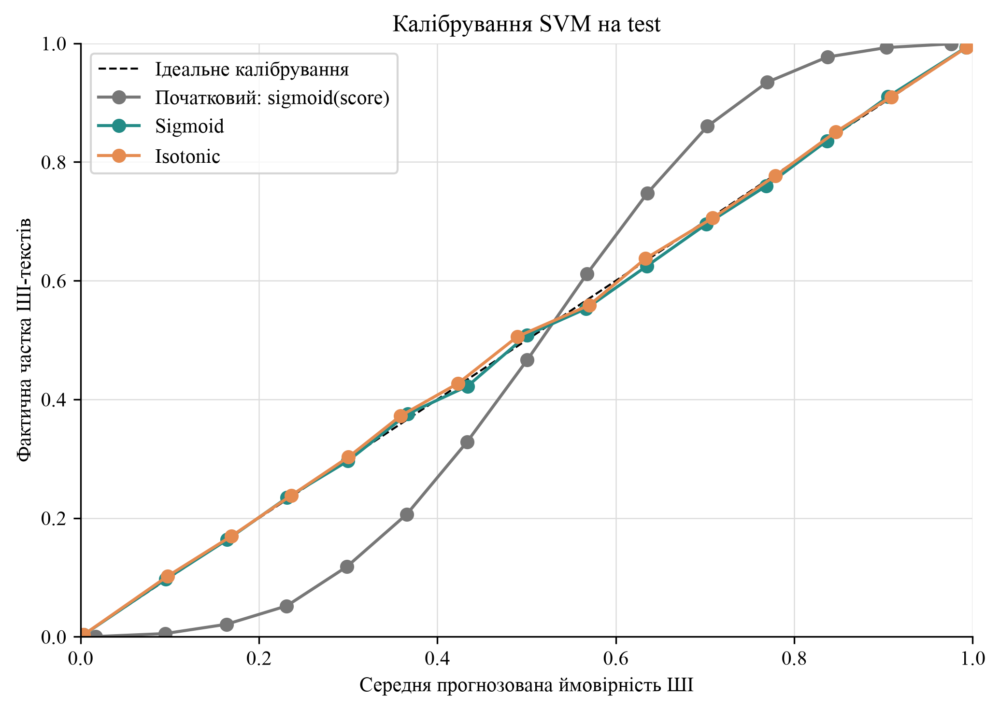

In [23]:
colors = {"original": "#777777", "sigmoid": "#238b86", "isotonic": "#e58b50"}
with plt.rc_context({"font.family": "Times New Roman", "text.color": "black",
                     "axes.labelcolor": "black", "xtick.color": "black", "ytick.color": "black"}):
    fig, ax = plt.subplots(figsize=(7, 5), dpi=300, facecolor="white")
    ax.set_facecolor("white")
    ax.plot([0, 1], [0, 1], "--", color="black", linewidth=1, label="Ідеальне калібрування")
    for name, probabilities in test_probabilities.items():
        fraction_positive, mean_probability = calibration_curve(
            test_labels, probabilities, n_bins=15, strategy="uniform")
        pd.DataFrame({"mean_probability": mean_probability, "fraction_ai": fraction_positive}).to_csv(
            CALIBRATION_DIR / f"test_calibration_curve_{name}.csv", index=False)
        ax.plot(mean_probability, fraction_positive, marker="o", color=colors[name], label=variant_names[name])
    ax.set(title="Калібрування SVM на test", xlabel="Середня прогнозована ймовірність ШІ",
           ylabel="Фактична частка ШІ-текстів", xlim=(0, 1), ylim=(0, 1))
    ax.grid(color="#dddddd", linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    legend = ax.legend()
    for text in [ax.title, ax.xaxis.label, ax.yaxis.label, *legend.get_texts()]:
        text.set_linespacing(1)
    fig.tight_layout()
    fig.savefig(CALIBRATION_DIR / "test_calibration_comparison.png", dpi=300, facecolor="white",
                bbox_inches="tight", pad_inches=0.05)
    plt.show()
    plt.close(fig)

## 8. Збереження обох калібраторів разом із SVM

Зберігаємо початковий SVM та обидва калібратори в одному словнику.
Поки не обираємо переможця й не перезаписуємо початковий `final_svm_model.joblib`.

In [24]:
calibrated_models = {
    "svm": svm_model,
    "sigmoid": sigmoid_calibrator,
    "isotonic": isotonic_calibrator,
    "representations": list(FINAL_REPRESENTATIONS),
    "normalization": "l2 after hstack", "classes": [0, 1],
    "calibration_split": "full val", "evaluation_split": "test",
    "original_probability": "expit(decision_function)"
}
joblib.dump(calibrated_models, CALIBRATION_DIR / "svm_with_calibrators.joblib", compress=3)
print("Моделі:", CALIBRATION_DIR / "svm_with_calibrators.joblib")
print("Таблиця:", CALIBRATION_DIR / "test_metrics.csv")
print("Графік:", CALIBRATION_DIR / "test_calibration_comparison.png")

Моделі: svm_calibration_full_val/svm_with_calibrators.joblib
Таблиця: svm_calibration_full_val/test_metrics.csv
Графік: svm_calibration_full_val/test_calibration_comparison.png


### Використання збережених варіантів

Для нового CSR-батча `X` з тими самими TF-IDF-ознаками:

```python
models = joblib.load("svm_calibration_full_val/svm_with_calibrators.joblib")
scores = models["svm"].decision_function(X)
probability_sigmoid = models["sigmoid"].predict_proba(scores.reshape(-1, 1))[:, 1]
probability_isotonic = models["isotonic"].predict(scores)
```

У `svm_calibration_full_val/` збережені оцінки val/test, два калібратори,
порівняльна таблиця, classification reports, confusion matrices та спільний графік на test.

## Збереження об'єднаного векторизованого test

Окремі TF-IDF-представлення вже збережені у папках `o200k_base_1_1/test/` і `char_2_5/test/`.
Тепер збережемо готові для SVM об'єднані батчі: спочатку токени, потім символи, з нормалізацією L2.
Повторної токенізації чи обчислення IDF немає.

Результат: `vectorization_sklearn/tfidf/o200k_base_1_1__char_2_5/test/`.
Залишаємо окремі CSR-батчі, щоб не завантажувати весь test у пам'ять та зберегти індекси int32.
Для кожного батча записуємо матрицю `.npz`, мітки `_label.npy` та номери рядків `_row_id.npy`.
`manifest.json` містить порядок файлів; `feature_blocks.csv` — відповідність колонок ознакам.

Використовуємо `read_final_batch` із попередніх комірок. Повторний запуск пропускає вже збережені батчі.


In [25]:
import gc
import json
from pathlib import Path

import numpy as np
from scipy import sparse

combined_folder = Path("vectorization_sklearn/tfidf/o200k_base_1_1__char_2_5")
test_folder = combined_folder / "test"
test_folder.mkdir(parents=True, exist_ok=True)

source_versions = []
for name in FINAL_REPRESENTATIONS:
    file = Path("vectorization_sklearn/tfidf") / name / "test" / "manifest.json"
    info = json.loads(file.read_text())
    if not info["complete"]:
        raise ValueError("Спочатку завершіть векторизацію test.")
    final_manifests[name]["test"] = info
    source_versions.append({"path": str(file.resolve()), "mtime_ns": file.stat().st_mtime_ns})

first = final_manifests[FINAL_REPRESENTATIONS[0]]["test"]
second = final_manifests[FINAL_REPRESENTATIONS[1]]["test"]
if [part["rows"] for part in first["shards"]] != [part["rows"] for part in second["shards"]]:
    raise ValueError("Представлення мають різний поділ на батчі.")
settings = {"sources": source_versions, "representations": list(FINAL_REPRESENTATIONS),
            "normalization": "l2 after hstack"}
manifest_file = test_folder / "manifest.json"
manifest = {"settings": settings, "split": "test", "complete": False, "n_rows": 0,
            "n_features": first["n_features"] + second["n_features"], "shards": []}
if manifest_file.exists():
    manifest = json.loads(manifest_file.read_text())
    if manifest["settings"] != settings:
        raise ValueError("Вихідні матриці змінилися. Задайте іншу папку збереження.")
    if manifest["n_rows"] != sum(part["rows"] for part in manifest["shards"]):
        raise ValueError("Некоректна кількість збережених рядків.")
    for part in manifest["shards"]:
        if not all((test_folder / part[key]).is_file() for key in ["file", "label", "row_id"]):
            raise ValueError("Відсутній раніше збережений файл батча.")

for number in range(len(manifest["shards"]), len(first["shards"])):
    X, y = read_final_batch("test", number)
    stem = f"batch_{number:06d}"
    start = manifest["n_rows"]
    sparse.save_npz(test_folder / f"{stem}.npz", X)
    np.save(test_folder / f"{stem}_label.npy", y)
    np.save(test_folder / f"{stem}_row_id.npy", np.arange(start, start + len(y), dtype=np.int64))
    manifest["shards"].append({"file": f"{stem}.npz", "label": f"{stem}_label.npy",
        "row_id": f"{stem}_row_id.npy", "rows": len(y), "shape": list(X.shape),
        "nnz": int(X.nnz), "dtype": str(X.dtype), "index_dtype": str(X.indices.dtype)})
    manifest["n_rows"] += len(y)
    save_calibration_json(manifest_file, manifest)
    print(f"Збережено батч {number + 1}/{len(first['shards'])}", flush=True)
    del X, y
    gc.collect()

if manifest["n_rows"] != first["n_rows"]:
    raise ValueError("Збережено не всі рядки test.")
manifest["complete"] = True
save_calibration_json(manifest_file, manifest)

# Та сама відповідність колонок, яку використовує фінальний SVM.
feature_blocks_file = Path("svm_final_o200k_char/feature_blocks.csv")
(combined_folder / "feature_blocks.csv").write_bytes(feature_blocks_file.read_bytes())

print("Збережено векторизований test:", test_folder.resolve())
print("Форма:", (manifest["n_rows"], manifest["n_features"]))
print("Кількість батчів:", len(manifest["shards"]))


Збережено батч 1/29
Збережено батч 2/29
Збережено батч 3/29
Збережено батч 4/29
Збережено батч 5/29
Збережено батч 6/29
Збережено батч 7/29
Збережено батч 8/29
Збережено батч 9/29
Збережено батч 10/29
Збережено батч 11/29
Збережено батч 12/29
Збережено батч 13/29
Збережено батч 14/29
Збережено батч 15/29
Збережено батч 16/29
Збережено батч 17/29
Збережено батч 18/29
Збережено батч 19/29
Збережено батч 20/29
Збережено батч 21/29
Збережено батч 22/29
Збережено батч 23/29
Збережено батч 24/29
Збережено батч 25/29
Збережено батч 26/29
Збережено батч 27/29
Збережено батч 28/29
Збережено батч 29/29
Збережено векторизований test: /home/artem/diploma/vectorization_sklearn/tfidf/o200k_base_1_1__char_2_5/test
Форма: (1436090, 200000)
Кількість батчів: 29


# Оцінювання обраної ізотонічно відкаліброваної моделі на test

Надалі використовуємо **SVM + isotonic**, навчений на всьому val.
Оцінюємо збережену модель на **всьому test**, читаючи готові об'єднані TF-IDF-батчі.
Повторно навчати SVM, калібратор або векторизатори не потрібно.

Ймовірність ШІ отримуємо через isotonic; прогноз — `1`, якщо ймовірність **більша за 0.5**, і `0` інакше.
Виводимо загальні метрики, classification report, confusion matrix та статистику за мовами й доменами.
Результати зберігаємо у `isotonic_test_results/`.

## 1. Збереження обраного варіанта для подальшої роботи

Зі словника з двома калібраторами залишаємо SVM та isotonic.
Зберігаємо їх разом у `final_isotonic_svm_model.joblib` — саме цей файл використовуватимемо надалі.
Він містить словник зі стандартними моделями під ключами `svm` та `calibrator`.

In [26]:
import gc
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, brier_score_loss, log_loss, classification_report, confusion_matrix, ConfusionMatrixDisplay)
from threadpoolctl import threadpool_limits
from IPython.display import display

ISOTONIC_RESULTS = Path("isotonic_test_results")
ISOTONIC_RESULTS.mkdir(exist_ok=True)
ISOTONIC_TEST = Path("vectorization_sklearn/tfidf/o200k_base_1_1__char_2_5/test")

saved_models = joblib.load("svm_calibration_full_val/svm_with_calibrators.joblib")
isotonic_model = {"svm": saved_models["svm"], "calibrator": saved_models["isotonic"],
                  "method": "isotonic", "representations": saved_models["representations"],
                  "normalization": saved_models["normalization"], "classes": [0, 1],
                  "calibration_split": "full val", "threshold": 0.5}
joblib.dump(isotonic_model, "final_isotonic_svm_model.joblib", compress=3)
del saved_models
gc.collect()
print("Обрана модель: final_isotonic_svm_model.joblib")

Обрана модель: final_isotonic_svm_model.joblib


## 2. Прогнози на всьому test батчами

Читаємо вже збережені матриці, без повторного об'єднання або нормалізації.
Перевіряємо їхню форму, типи та порядок `row_id`.
У пам'яті залишаємо лише один CSR-батч і невеликі масиви міток та ймовірностей.

In [27]:
test_manifest = json.loads((ISOTONIC_TEST / "manifest.json").read_text())
if not test_manifest["complete"]:
    raise ValueError("Збереження об'єднаного test ще не завершене.")
if test_manifest["settings"]["representations"] != isotonic_model["representations"]:
    raise ValueError("Порядок представлень не відповідає моделі.")
if test_manifest["settings"]["normalization"] != isotonic_model["normalization"]:
    raise ValueError("Нормалізація ознак не відповідає моделі.")
if test_manifest["n_features"] != isotonic_model["svm"].n_features_in_:
    raise ValueError("Кількість ознак не відповідає моделі.")
if not np.array_equal(isotonic_model["svm"].classes_, [0, 1]):
    raise ValueError("Очікуємо порядок класів: людина, ШІ.")

isotonic_labels = np.empty(test_manifest["n_rows"], dtype=np.int8)
isotonic_probabilities = np.empty(test_manifest["n_rows"], dtype=np.float64)
position = 0

with threadpool_limits(limits=1):
    for number, batch in enumerate(test_manifest["shards"]):
        X = sparse.load_npz(ISOTONIC_TEST / batch["file"])
        y = np.load(ISOTONIC_TEST / batch["label"])
        row_ids = np.load(ISOTONIC_TEST / batch["row_id"])
        end = position + len(y)
        if not len(y) == len(row_ids) == batch["rows"]:
            raise ValueError("Різна кількість рядків та міток.")
        if not np.array_equal(row_ids, np.arange(position, end)) or not np.isin(y, [0, 1]).all():
            raise ValueError("Порушено порядок row_id або некоректні мітки.")
        if X.format != "csr" or X.dtype != np.float32 or X.shape != (len(y), test_manifest["n_features"]):
            raise ValueError("Некоректна форма або тип CSR.")
        if X.indices.dtype != np.int32 or X.indptr.dtype != np.int32:
            raise ValueError("Очікуємо індекси CSR int32.")

        scores = isotonic_model["svm"].decision_function(X)
        isotonic_probabilities[position:end] = isotonic_model["calibrator"].predict(scores)
        isotonic_labels[position:end] = y
        position = end
        del X, y, row_ids, scores
        gc.collect()
        print(f"Test: батч {number + 1}/{len(test_manifest['shards'])}", flush=True)

if position != test_manifest["n_rows"] or not np.isfinite(isotonic_probabilities).all():
    raise ValueError("Не всі рядки test отримали коректні прогнози.")
if ((isotonic_probabilities < 0) | (isotonic_probabilities > 1)).any():
    raise ValueError("Ймовірності повинні бути від 0 до 1.")

test_predictions = pd.DataFrame({
    "row_id": np.arange(position, dtype=np.int64), "label": isotonic_labels,
    "prediction": (isotonic_probabilities > 0.5).astype(np.int8), "probability_ai": isotonic_probabilities
})
test_predictions.to_parquet(ISOTONIC_RESULTS / "test_predictions.parquet", index=False)
print("Перевірено текстів:", len(test_predictions))

Test: батч 1/29
Test: батч 2/29
Test: батч 3/29
Test: батч 4/29
Test: батч 5/29
Test: батч 6/29
Test: батч 7/29
Test: батч 8/29
Test: батч 9/29
Test: батч 10/29
Test: батч 11/29
Test: батч 12/29
Test: батч 13/29
Test: батч 14/29
Test: батч 15/29
Test: батч 16/29
Test: батч 17/29
Test: батч 18/29
Test: батч 19/29
Test: батч 20/29
Test: батч 21/29
Test: батч 22/29
Test: батч 23/29
Test: батч 24/29
Test: батч 25/29
Test: батч 26/29
Test: батч 27/29
Test: батч 28/29
Test: батч 29/29
Перевірено текстів: 1436090


## 3. Загальна статистика та classification report

Усі метрики обчислюємо на всьому test. Precision, Recall і F1 Score у підсумковій таблиці — для ШІ.
FPR — частка людських текстів, помилково позначених як ШІ.
Brier score та Log loss характеризують якість імовірностей; менші значення кращі.
Показники у таблицях — частки від 0 до 1.

In [28]:
def isotonic_test_metrics(labels, probabilities):
    predictions = (probabilities > 0.5).astype(np.int8)
    human = labels == 0
    ai = labels == 1
    return {
        "Texts": len(labels), "Human": int(human.sum()), "AI": int(ai.sum()),
        "Accuracy": accuracy_score(labels, predictions),
        "Precision": precision_score(labels, predictions, zero_division=0),
        "Recall": recall_score(labels, predictions, zero_division=0),
        "F1 Score": f1_score(labels, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(labels, probabilities) if len(np.unique(labels)) == 2 else np.nan,
        "Brier score": brier_score_loss(labels, probabilities),
        "Log loss": log_loss(labels, probabilities, labels=[0, 1]),
        "FPR human": float(predictions[human].mean()) if human.any() else np.nan
    }


test_predictions = pd.read_parquet(ISOTONIC_RESULTS / "test_predictions.parquet")
y_test = test_predictions["label"].to_numpy()
p_test = test_predictions["probability_ai"].to_numpy()
pred_test = test_predictions["prediction"].to_numpy()

test_metrics = pd.DataFrame([isotonic_test_metrics(y_test, p_test)])
test_metrics.to_csv(ISOTONIC_RESULTS / "test_metrics.csv", index=False)
display(test_metrics.round(6))

report_text = classification_report(y_test, pred_test, labels=[0, 1],
                  target_names=["Людина", "ШІ"], digits=4, zero_division=0)
report = classification_report(y_test, pred_test, labels=[0, 1],
             target_names=["Людина", "ШІ"], output_dict=True, zero_division=0)
print(report_text)
(ISOTONIC_RESULTS / "classification_report.txt").write_text(report_text, encoding="utf-8")
(ISOTONIC_RESULTS / "classification_report.json").write_text(
    json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8")

cm = confusion_matrix(y_test, pred_test, labels=[0, 1])
cm_table = pd.DataFrame(cm, index=["Людина", "ШІ"], columns=["Людина", "ШІ"])
cm_table.index.name = "Справжній клас"
cm_table.columns.name = "Прогнозований клас"
display(cm_table)
cm_table.to_csv(ISOTONIC_RESULTS / "confusion_matrix.csv")

,Texts,Human,AI,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Brier score,Log loss,FPR human
0,1436090,714482,721608,0.976552,0.973119,0.980417,0.976755,0.997044,0.017851,0.06456,0.027353


              precision    recall  f1-score   support

      Людина     0.9801    0.9726    0.9763    714482
          ШІ     0.9731    0.9804    0.9768    721608

    accuracy                         0.9766   1436090
   macro avg     0.9766    0.9765    0.9765   1436090
weighted avg     0.9766    0.9766    0.9766   1436090



Прогнозований клас,Людина,ШІ
Справжній клас,,
Людина,694939,19543
ШІ,14131,707477


## 4. Матриця помилок обраної моделі

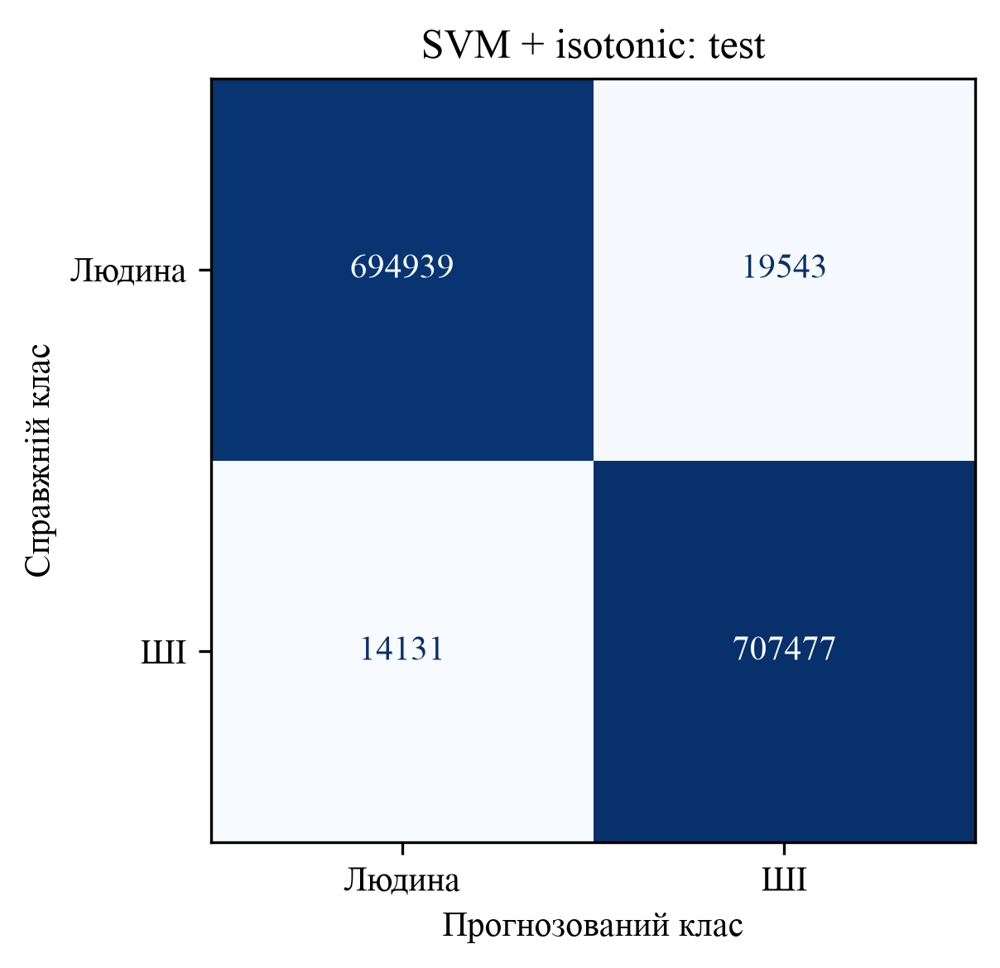

In [29]:
with plt.rc_context({"font.family": "Times New Roman", "text.color": "black",
                     "axes.labelcolor": "black", "xtick.color": "black", "ytick.color": "black"}):
    fig, ax = plt.subplots(figsize=(6, 4), dpi=300, facecolor="white")
    ax.set_facecolor("white")
    ConfusionMatrixDisplay(cm, display_labels=["Людина", "ШІ"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title("SVM + isotonic: test", linespacing=1)
    ax.set_xlabel("Прогнозований клас")
    ax.set_ylabel("Справжній клас")
    ax.grid(False)
    fig.tight_layout()
    fig.savefig(ISOTONIC_RESULTS / "confusion_matrix.png", dpi=300, facecolor="white",
                bbox_inches="tight", pad_inches=0.05)
    plt.show()
    plt.close(fig)

## 5. Статистика за мовами та групами доменів

Читаємо лише метадані test без текстів. Перевіряємо кількість і порядок міток перед зіставленням із прогнозами.
Для кожної мови та групи доменів виводимо кількість текстів, баланс класів і метрики.
ROC-AUC не визначаємо для груп, що містять лише один справжній клас.

In [30]:
test_metadata = pd.read_parquet("test.parquet", columns=["language", "domain_group", "label"])
if len(test_metadata) != len(test_predictions) or not np.array_equal(test_metadata["label"].to_numpy(), y_test):
    raise ValueError("Метадані test не відповідають збереженим прогнозам.")
test_metadata["probability_ai"] = p_test

for column in ["language", "domain_group"]:
    rows = []
    for name, group in test_metadata.groupby(column, dropna=False, observed=True):
        rows.append({column: name, **isotonic_test_metrics(
            group["label"].to_numpy(), group["probability_ai"].to_numpy())})
    group_metrics = pd.DataFrame(rows).sort_values("Texts", ascending=False)
    print("Статистика:", column)
    display(group_metrics.round(6))
    group_metrics.to_csv(ISOTONIC_RESULTS / f"metrics_by_{column}.csv", index=False)

del test_metadata
gc.collect()

Статистика: language


,language,Texts,Human,AI,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Brier score,Log loss,FPR human
7,english,1152884,578370,574514,0.975916,0.972206,0.979678,0.975928,0.997126,0.018249,0.065174,0.027821
8,german,128873,64436,64437,0.993529,0.993575,0.993482,0.993528,0.999597,0.005591,0.024969,0.006425
5,czech,117789,52868,64921,0.989524,0.989712,0.991297,0.990504,0.998710,0.008705,0.036794,0.012654
3,chinese,11636,6122,5514,0.810846,0.789042,0.820094,0.804269,0.887279,0.140678,0.507132,0.197484
1,bulgarian,2699,1404,1295,0.941460,0.931008,0.948263,0.939556,0.984575,0.045437,0.158226,0.064815
16,russian,1677,882,795,0.922481,0.885284,0.961006,0.921592,0.973932,0.057564,0.199815,0.112245
0,arabic,1509,762,747,0.948310,0.926115,0.973226,0.949086,0.985678,0.043411,0.150992,0.076115
10,hungarian,1393,696,697,0.931084,0.899070,0.971306,0.933793,0.980475,0.050749,0.171700,0.109195
6,dutch,1392,696,696,0.934626,0.909337,0.965517,0.936585,0.980744,0.049427,0.168229,0.096264
14,portuguese,1392,696,696,0.937500,0.912043,0.968391,0.939373,0.982366,0.047704,0.162006,0.093391


Статистика: domain_group


,domain_group,Texts,Human,AI,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Brier score,Log loss,FPR human
5,other,279566,136401,143165,0.970787,0.969317,0.973779,0.971542,0.995187,0.022137,0.080611,0.032353
0,creative,270612,135306,135306,0.980877,0.975364,0.986675,0.980987,0.997976,0.014615,0.052616,0.024921
4,news,165651,82595,83056,0.971198,0.965888,0.977064,0.971444,0.995934,0.021790,0.077770,0.034699
3,instruction,162207,81104,81103,0.981813,0.980179,0.983515,0.981844,0.998686,0.013484,0.046214,0.019888
1,discussion,147265,73632,73633,0.969239,0.959077,0.980308,0.969576,0.995573,0.023356,0.083265,0.041830
9,wiki,139241,69620,69621,0.979194,0.987520,0.970655,0.979015,0.997949,0.016115,0.061309,0.012267
7,science,134666,67333,67333,0.987837,0.983870,0.991936,0.987886,0.998600,0.009892,0.039167,0.016262
6,reviews,72917,36508,36409,0.971790,0.965878,0.978055,0.971928,0.996421,0.021375,0.075384,0.034458
8,technical,57075,28538,28537,0.990819,0.989995,0.991660,0.990827,0.999114,0.007358,0.029808,0.010022
2,editing,6890,3445,3445,0.859942,0.818602,0.924819,0.868475,0.946376,0.101674,0.332145,0.204935


50

### Подальше використання моделі

Для векторизованого батча `X` із тим самим порядком ознак:

```python
model = joblib.load("final_isotonic_svm_model.joblib")
scores = model["svm"].decision_function(X)
probability_ai = model["calibrator"].predict(scores)
prediction = (probability_ai > 0.5).astype(np.int8)
```

У `isotonic_test_results/` зберігаємо прогнози, загальні метрики, classification report,
confusion matrix та метрики за мовами і групами доменів.

# Детальна статистика SVM + isotonic на test

Використовуємо збережені прогнози `isotonic_test_results/test_predictions.parquet`.
Повторне прогнозування або навчання не потрібні.
Показуємо таблиці метрик та графіки accuracy за класами, мовами, групами доменів,
групами моделей, діапазонами довжини в символах і словах та видами атак.

Метрики в таблицях — частки від 0 до 1, accuracy на графіках — відсотки.
У таблицях груп Precision, Recall і F1 Score стосуються ШІ (`label=1`).
Для груп із одним справжнім класом Precision, F1 Score та ROC-AUC не оцінюємо й показуємо `NaN`.
Окремі колонки Recall Human і Recall AI показують частку правильно розпізнаних текстів кожного класу.

## 1. Прогнози та метадані test

Перевіряємо порядок `row_id` і міток перед зіставленням метаданих із прогнозами.
Відсутні значення категорій позначаємо `unknown`, зокрема для невідомого виду атаки.
Відоме значення `none` залишаємо окремою категорією.

In [31]:
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    precision_recall_fscore_support, roc_auc_score, brier_score_loss, log_loss)
from IPython.display import display

DETAIL_DIR = Path("isotonic_test_results/details")
DETAIL_TABLES = DETAIL_DIR / "tables"
DETAIL_FIGURES = DETAIL_DIR / "figures"
DETAIL_TABLES.mkdir(parents=True, exist_ok=True)
DETAIL_FIGURES.mkdir(exist_ok=True)

detail_predictions = pd.read_parquet("isotonic_test_results/test_predictions.parquet")
test_details = pd.read_parquet("test.parquet",
    columns=["label", "language", "domain_group", "model_group", "attack"])
if not np.array_equal(detail_predictions["row_id"].to_numpy(), np.arange(len(test_details))):
    raise ValueError("Не збігаються кількість або порядок рядків test.")
if not np.array_equal(test_details["label"].to_numpy(), detail_predictions["label"].to_numpy()):
    raise ValueError("Мітки метаданих не відповідають збереженим прогнозам.")

test_details["prediction"] = detail_predictions["prediction"].to_numpy()
test_details["probability_ai"] = detail_predictions["probability_ai"].to_numpy()
for column in ["language", "domain_group", "model_group", "attack"]:
    test_details[column] = (test_details[column].astype("string").str.strip()
                            .fillna("unknown").replace("", "unknown").astype("category"))
del detail_predictions
gc.collect()
print("Текстів для аналізу:", len(test_details))

Текстів для аналізу: 1436090


## 2. Довжини текстів без завантаження всього текстового корпусу

Читаємо лише колонку `text`, батчами по 50 000 рядків.
Слова рахуємо як послідовності непробільних символів (`\S+`), так само як у попередньому EDA.
Використовуємо попередні діапазони довжини; межі зліва включаємо, справа не включаємо.

In [32]:
char_lengths = np.empty(len(test_details), dtype=np.int32)
word_lengths = np.empty(len(test_details), dtype=np.int32)
position = 0
parquet = pq.ParquetFile("test.parquet")
for batch in parquet.iter_batches(batch_size=50_000, columns=["text"], use_threads=True):
    texts = pd.Series(batch.column(0).to_pylist(), dtype="string")
    if texts.isna().any():
        raise ValueError("У test є NA замість тексту.")
    end = position + len(texts)
    char_lengths[position:end] = texts.str.len().to_numpy(dtype=np.int32)
    word_lengths[position:end] = texts.str.count(r"\S+").to_numpy(dtype=np.int32)
    position = end
    del texts, batch
    gc.collect()
parquet.close()
if position != len(test_details):
    raise ValueError("Кількість довжин не відповідає кількості прогнозів.")

char_names = ["0–99", "100–249", "250–499", "500–999", "1000–1999", "2000–3999", "4000+"]
word_names = ["0–24", "25–49", "50–99", "100–199", "200–399", "400–799", "800+"]
test_details["chars"] = char_lengths
test_details["words"] = word_lengths
test_details["char_group"] = pd.cut(char_lengths,
    bins=[0, 100, 250, 500, 1000, 2000, 4000, float("inf")], labels=char_names, right=False)
test_details["word_group"] = pd.cut(word_lengths,
    bins=[0, 25, 50, 100, 200, 400, 800, float("inf")], labels=word_names, right=False)
test_details.to_parquet(DETAIL_DIR / "test_analysis.parquet", index=False)
del char_lengths, word_lengths
gc.collect()

0

## 3. Спільні процедури для таблиць та графіків

У таблицях показуємо чисельність обох класів, Accuracy, Precision, Recall, F1 Score,
ROC-AUC, Brier score, Log loss та частку помилкового позначення людського тексту як ШІ — FPR human.
Якщо у групі немає певного класу, його Recall і FPR human за відсутності людей не визначаємо.
Порожні діапазони мають нульову кількість текстів та не потрапляють на графік.

Усі графіки виводимо й зберігаємо: Times New Roman, міжрядковий інтервал 1,
білий фон, 300 dpi, мінімальні поля. На підписах груп указуємо кількість текстів.

In [33]:
def detailed_group_metrics(group):
    labels = group["label"].to_numpy()
    predictions = group["prediction"].to_numpy()
    probabilities = group["probability_ai"].to_numpy()
    human = labels == 0
    ai = labels == 1
    both_classes = human.any() and ai.any()
    return {
        "Texts": len(group), "Human": int(human.sum()), "AI": int(ai.sum()),
        "Accuracy": accuracy_score(labels, predictions),
        "Precision": precision_score(labels, predictions, zero_division=0) if both_classes else np.nan,
        "Recall": recall_score(labels, predictions, zero_division=0) if ai.any() else np.nan,
        "F1 Score": f1_score(labels, predictions, zero_division=0) if both_classes else np.nan,
        "Recall Human": float((predictions[human] == 0).mean()) if human.any() else np.nan,
        "Recall AI": float((predictions[ai] == 1).mean()) if ai.any() else np.nan,
        "ROC-AUC": roc_auc_score(labels, probabilities) if both_classes else np.nan,
        "Brier score": brier_score_loss(labels, probabilities),
        "Log loss": log_loss(labels, probabilities, labels=[0, 1]),
        "FPR human": float((predictions[human] == 1).mean()) if human.any() else np.nan
    }


def plot_detail_accuracy(table, title, filename, keep_order=False, colors="#238b86"):
    plotted = table.dropna(subset=["Accuracy"]).copy()
    if not keep_order:
        plotted = plotted.sort_values("Accuracy", ascending=True, kind="stable")
    labels = [f"{name} (n={int(row['Texts']):,})" for name, row in plotted.iterrows()]
    values = plotted["Accuracy"].to_numpy() * 100
    with plt.rc_context({"font.family": "Times New Roman", "text.color": "black",
                         "axes.labelcolor": "black", "xtick.color": "black", "ytick.color": "black"}):
        fig, ax = plt.subplots(figsize=(10, max(3, len(plotted) * 0.4)), dpi=300, facecolor="white")
        ax.set_facecolor("white")
        ax.barh(np.arange(len(plotted)), values, color=colors, height=0.75)
        ax.set_yticks(np.arange(len(plotted)), labels=labels)
        ax.invert_yaxis()
        ax.set(title=title, xlabel="Accuracy, %", xlim=(0, 100))
        for index, value in enumerate(values):
            if value >= 15:
                ax.text(value - 1, index, f"{value:.2f}%", ha="right", va="center", color="white")
            else:
                ax.text(value + 1, index, f"{value:.2f}%", ha="left", va="center", color="black")
        ax.grid(axis="x", color="#dddddd", linewidth=0.6)
        ax.grid(axis="y", visible=False)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        for text in [ax.title, ax.xaxis.label, ax.yaxis.label, *ax.texts]:
            text.set_linespacing(1)
        fig.tight_layout()
        fig.savefig(DETAIL_FIGURES / f"{filename}.png", dpi=300, facecolor="white",
                    bbox_inches="tight", pad_inches=0.05)
        plt.show()
        plt.close(fig)


def show_detail_metrics(column, title, filename, order=None):
    rows = []
    for name, group in test_details.groupby(column, dropna=False, observed=True):
        rows.append({column: name, **detailed_group_metrics(group)})
    table = pd.DataFrame(rows).set_index(column)
    if order is not None:
        table = table.reindex(order)
        table[["Texts", "Human", "AI"]] = table[["Texts", "Human", "AI"]].fillna(0).astype(int)
    else:
        table = table.sort_values("Texts", ascending=False)
    with pd.option_context("display.max_rows", None):
        display(table.round(6))
    table.to_csv(DETAIL_TABLES / f"{filename}.csv")
    plot_detail_accuracy(table, title, filename, keep_order=order is not None)
    return table

## 4. Метрики за класами

Precision, Recall та F1 для кожного класу обчислюємо на всьому test:
так у Precision враховуються помилкові прогнози з іншого справжнього класу.
Accuracy всередині справжнього класу — частка його правильно визначених текстів, тобто його Recall.

,Texts,Accuracy,Precision,Recall,F1 Score
Class,,,,,
Людина,714482,0.972647,0.980071,0.972647,0.976345
ШІ,721608,0.980417,0.973119,0.980417,0.976755


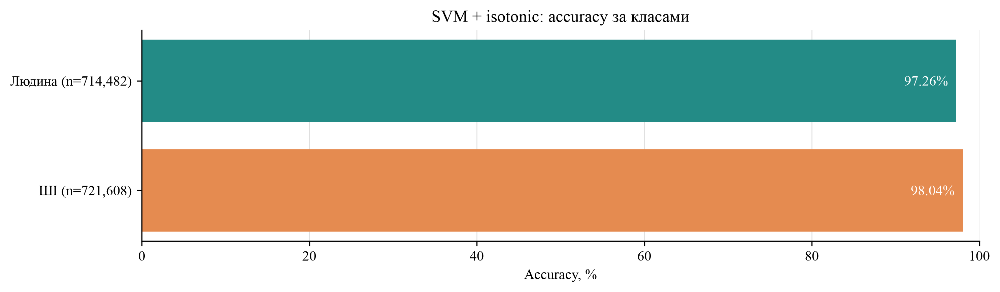

In [34]:
class_precision, class_recall, class_f1, class_support = precision_recall_fscore_support(
    test_details["label"], test_details["prediction"], labels=[0, 1], zero_division=0
)
class_metrics = pd.DataFrame({
    "Class": ["Людина", "ШІ"], "Texts": class_support,
    "Accuracy": class_recall, "Precision": class_precision,
    "Recall": class_recall, "F1 Score": class_f1
}).set_index("Class")
display(class_metrics.round(6))
class_metrics.to_csv(DETAIL_TABLES / "metrics_by_class.csv")
plot_detail_accuracy(class_metrics, "SVM + isotonic: accuracy за класами", "accuracy_by_class",
                     keep_order=True, colors=["#238b86", "#e58b50"])

## 5. Метрики та accuracy за мовами

,Texts,Human,AI,Accuracy,Precision,Recall,F1 Score,Recall Human,Recall AI,ROC-AUC,Brier score,Log loss,FPR human
language,,,,,,,,,,,,,
english,1152884,578370,574514,0.975916,0.972206,0.979678,0.975928,0.972179,0.979678,0.997126,0.018249,0.065174,0.027821
german,128873,64436,64437,0.993529,0.993575,0.993482,0.993528,0.993575,0.993482,0.999597,0.005591,0.024969,0.006425
czech,117789,52868,64921,0.989524,0.989712,0.991297,0.990504,0.987346,0.991297,0.998710,0.008705,0.036794,0.012654
chinese,11636,6122,5514,0.810846,0.789042,0.820094,0.804269,0.802516,0.820094,0.887279,0.140678,0.507132,0.197484
bulgarian,2699,1404,1295,0.941460,0.931008,0.948263,0.939556,0.935185,0.948263,0.984575,0.045437,0.158226,0.064815
russian,1677,882,795,0.922481,0.885284,0.961006,0.921592,0.887755,0.961006,0.973932,0.057564,0.199815,0.112245
arabic,1509,762,747,0.948310,0.926115,0.973226,0.949086,0.923885,0.973226,0.985678,0.043411,0.150992,0.076115
hungarian,1393,696,697,0.931084,0.899070,0.971306,0.933793,0.890805,0.971306,0.980475,0.050749,0.171700,0.109195
dutch,1392,696,696,0.934626,0.909337,0.965517,0.936585,0.903736,0.965517,0.980744,0.049427,0.168229,0.096264


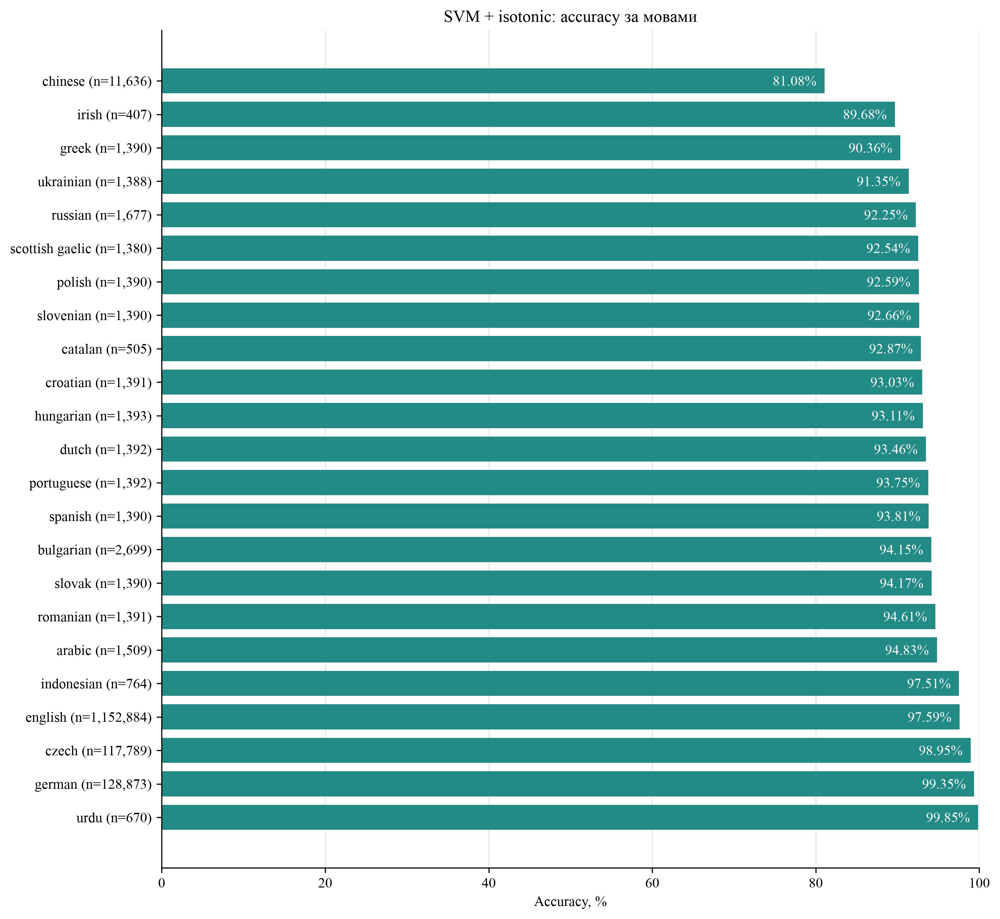

In [35]:
language_metrics = show_detail_metrics("language", "SVM + isotonic: accuracy за мовами", "metrics_by_language")

## 6. Метрики та accuracy за групами доменів

,Texts,Human,AI,Accuracy,Precision,Recall,F1 Score,Recall Human,Recall AI,ROC-AUC,Brier score,Log loss,FPR human
domain_group,,,,,,,,,,,,,
other,279566,136401,143165,0.970787,0.969317,0.973779,0.971542,0.967647,0.973779,0.995187,0.022137,0.080611,0.032353
creative,270612,135306,135306,0.980877,0.975364,0.986675,0.980987,0.975079,0.986675,0.997976,0.014615,0.052616,0.024921
news,165651,82595,83056,0.971198,0.965888,0.977064,0.971444,0.965301,0.977064,0.995934,0.021790,0.077770,0.034699
instruction,162207,81104,81103,0.981813,0.980179,0.983515,0.981844,0.980112,0.983515,0.998686,0.013484,0.046214,0.019888
discussion,147265,73632,73633,0.969239,0.959077,0.980308,0.969576,0.958170,0.980308,0.995573,0.023356,0.083265,0.041830
wiki,139241,69620,69621,0.979194,0.987520,0.970655,0.979015,0.987733,0.970655,0.997949,0.016115,0.061309,0.012267
science,134666,67333,67333,0.987837,0.983870,0.991936,0.987886,0.983738,0.991936,0.998600,0.009892,0.039167,0.016262
reviews,72917,36508,36409,0.971790,0.965878,0.978055,0.971928,0.965542,0.978055,0.996421,0.021375,0.075384,0.034458
technical,57075,28538,28537,0.990819,0.989995,0.991660,0.990827,0.989978,0.991660,0.999114,0.007358,0.029808,0.010022


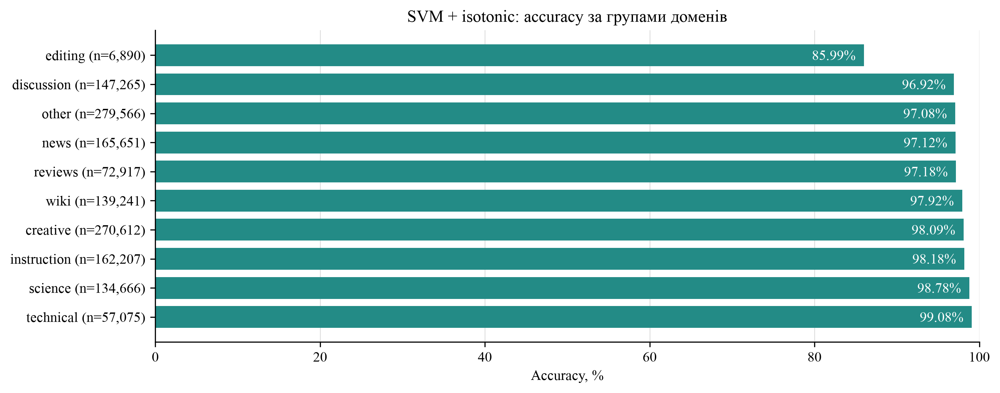

In [36]:
domain_metrics = show_detail_metrics("domain_group", "SVM + isotonic: accuracy за групами доменів", "metrics_by_domain_group")

## 7. Метрики та accuracy за групами моделей

Група Human містить людські тексти, групи генераторів — зазвичай лише ШІ-тексти.
У таких групах Accuracy дорівнює Recall наявного класу; Precision і F1 не оцінюємо
без представників протилежного класу. Кількості Human та AI в таблиці показують склад кожної групи.

,Texts,Human,AI,Accuracy,Precision,Recall,F1 Score,Recall Human,Recall AI,ROC-AUC,Brier score,Log loss,FPR human
model_group,,,,,,,,,,,,,
Human,714483,714482,1,0.972646,0.0,0.000000,0.0,0.972647,0.000000,0.966845,0.020527,0.071281,0.027353
Mistral,154852,0,154852,0.990714,NaN,0.990714,NaN,NaN,0.990714,NaN,0.007674,0.032534,NaN
GPT-3+,152065,0,152065,0.972058,NaN,0.972058,NaN,NaN,0.972058,NaN,0.020822,0.074872,NaN
MPT,144669,0,144669,0.984537,NaN,0.984537,NaN,NaN,0.984537,NaN,0.012430,0.051207,NaN
Llama,82506,0,82506,0.994946,NaN,0.994946,NaN,NaN,0.994946,NaN,0.004268,0.020118,NaN
Cohere,78784,0,78784,0.979412,NaN,0.979412,NaN,NaN,0.979412,NaN,0.016780,0.066644,NaN
GPT-2,74826,0,74826,0.993518,NaN,0.993518,NaN,NaN,0.993518,NaN,0.005954,0.027939,NaN
Other,32583,0,32583,0.889329,NaN,0.889329,NaN,NaN,0.889329,NaN,0.080748,0.267562,NaN
Claude,1124,0,1124,0.933274,NaN,0.933274,NaN,NaN,0.933274,NaN,0.057142,0.204271,NaN


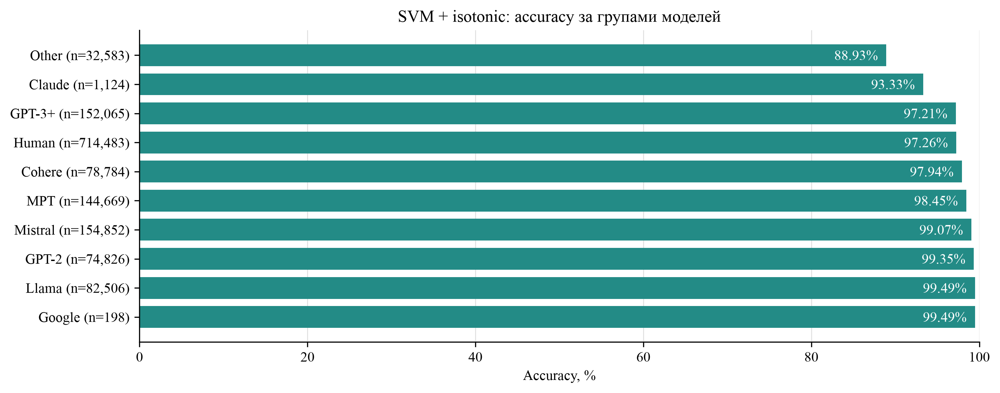

In [37]:
model_metrics = show_detail_metrics("model_group", "SVM + isotonic: accuracy за групами моделей", "metrics_by_model_group")

## 8. Метрики та accuracy за довжиною в символах

,Texts,Human,AI,Accuracy,Precision,Recall,F1 Score,Recall Human,Recall AI,ROC-AUC,Brier score,Log loss,FPR human
char_group,,,,,,,,,,,,,
0–99,23801,12445,11356,0.833452,0.815358,0.841493,0.828220,0.826115,0.841493,0.918461,0.122066,0.417564,0.173885
100–249,48795,25444,23351,0.895707,0.888719,0.894009,0.891356,0.897265,0.894009,0.965657,0.075747,0.250548,0.102735
250–499,91992,46360,45632,0.952909,0.947260,0.958428,0.952811,0.947476,0.958428,0.990768,0.035319,0.121459,0.052524
500–999,308930,152595,156335,0.980186,0.974346,0.986830,0.980548,0.973381,0.986830,0.997739,0.015121,0.054882,0.026619
1000–1999,631932,312389,319543,0.985457,0.981306,0.990101,0.985684,0.980707,0.990101,0.998447,0.011509,0.044372,0.019293
2000–3999,297611,148742,148869,0.985800,0.987555,0.984013,0.985781,0.987589,0.984013,0.998880,0.011004,0.041323,0.012411
4000+,33029,16507,16522,0.977232,0.976147,0.978392,0.977269,0.976071,0.978392,0.997560,0.017118,0.063075,0.023929


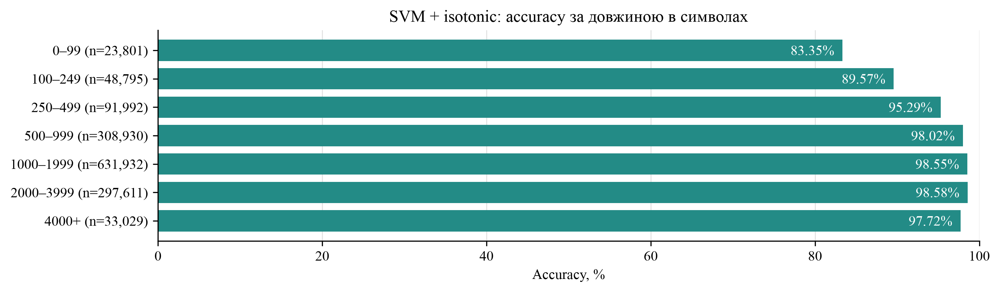

In [38]:
char_metrics = show_detail_metrics("char_group", "SVM + isotonic: accuracy за довжиною в символах",
                                   "metrics_by_char_length", order=char_names)

## 9. Метрики та accuracy за довжиною в словах

,Texts,Human,AI,Accuracy,Precision,Recall,F1 Score,Recall Human,Recall AI,ROC-AUC,Brier score,Log loss,FPR human
word_group,,,,,,,,,,,,,
0–24,43424,22517,20907,0.864246,0.849311,0.872913,0.860951,0.856198,0.872913,0.944458,0.098847,0.335729,0.143802
25–49,58531,34096,24435,0.924416,0.907373,0.912052,0.909707,0.933277,0.912052,0.980046,0.055303,0.183920,0.066723
50–99,149766,80334,69432,0.970594,0.964552,0.972304,0.968412,0.969116,0.972304,0.995897,0.022310,0.078167,0.030884
100–199,390877,167162,223715,0.980403,0.975965,0.990144,0.983003,0.967367,0.990144,0.997406,0.015039,0.055565,0.032633
200–399,625111,282703,342408,0.985630,0.985650,0.988152,0.986899,0.982575,0.988152,0.998513,0.011380,0.043853,0.017425
400–799,153156,115612,37544,0.987059,0.973579,0.973631,0.973605,0.991420,0.973631,0.998748,0.009925,0.036787,0.008580
800+,15225,12058,3167,0.978588,0.944879,0.952637,0.948742,0.985404,0.952637,0.996795,0.016551,0.058877,0.014596


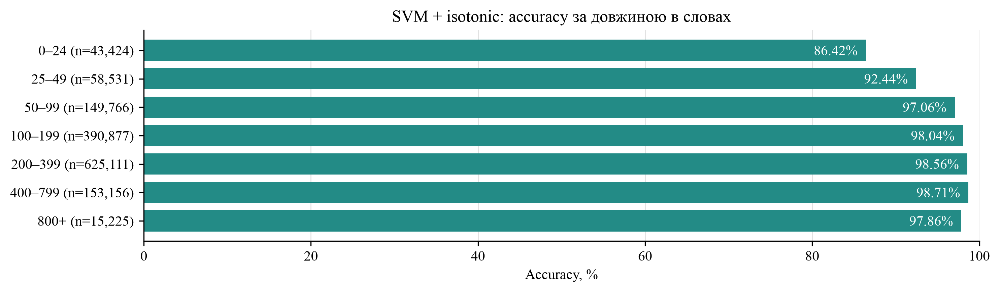

In [39]:
word_metrics = show_detail_metrics("word_group", "SVM + isotonic: accuracy за довжиною в словах",
                                   "metrics_by_word_length", order=word_names)

## 10. Метрики та accuracy за видами атак

`unknown` означає відсутню інформацію про атаку; це окрема категорія від явного `none`.
Атаковані групи можуть містити лише ШІ-тексти — тоді Accuracy дорівнює Recall ШІ.
Не змішуємо їхній склад із групами, у яких присутні обидва класи: чисельності видно в таблиці.

,Texts,Human,AI,Accuracy,Precision,Recall,F1 Score,Recall Human,Recall AI,ROC-AUC,Brier score,Log loss,FPR human
attack,,,,,,,,,,,,,
none,754356,658329,96027,0.989896,0.944322,0.978308,0.961015,0.991586,0.978308,0.998964,0.007878,0.029401,0.008414
unknown,90886,38799,52087,0.835860,0.848005,0.869430,0.858584,0.790794,0.869430,0.915266,0.119130,0.394999,0.209206
paraphrase,63561,1818,61743,0.957631,0.975642,0.980872,0.978250,0.168317,0.980872,0.808380,0.034594,0.135311,0.831683
zero_width_space,63481,1719,61762,0.982278,0.983772,0.998251,0.990959,0.408377,0.998251,0.978293,0.013348,0.053065,0.591623
homoglyph,63404,1857,61547,0.984417,0.985474,0.998668,0.992027,0.512116,0.998668,0.974327,0.012606,0.050884,0.487884
whitespace,63188,1825,61363,0.986105,0.992685,0.993009,0.992847,0.753973,0.993009,0.987292,0.011026,0.042663,0.246027
upper_lower,62064,1753,60311,0.985241,0.994489,0.990300,0.992390,0.811181,0.990300,0.988023,0.011782,0.045749,0.188819
synonym,61873,1763,60110,0.980654,0.993334,0.986708,0.990010,0.774248,0.986708,0.982837,0.015130,0.057724,0.225752
insert_paragraphs,57531,1682,55849,0.987276,0.992266,0.994646,0.993454,0.742568,0.994646,0.985386,0.010300,0.041060,0.257432


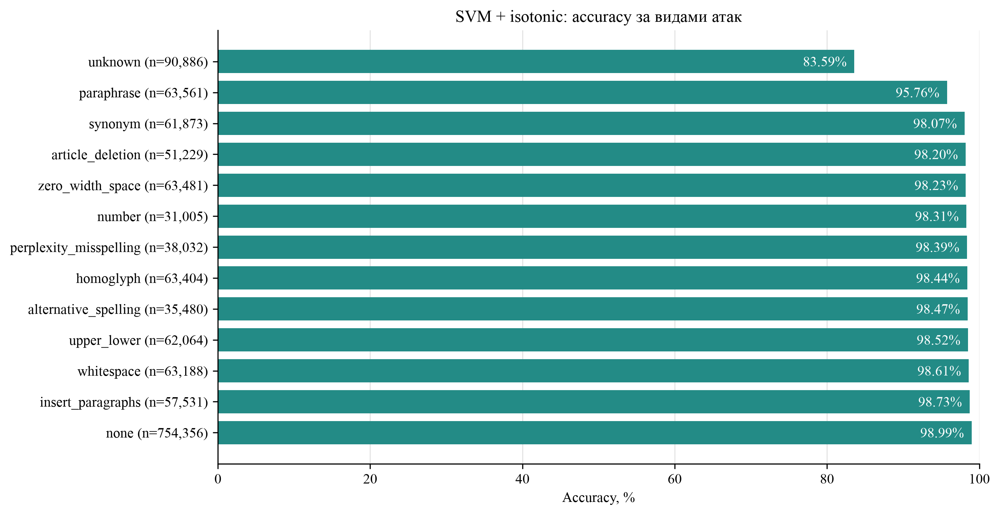

In [40]:
attack_metrics = show_detail_metrics("attack", "SVM + isotonic: accuracy за видами атак", "metrics_by_attack")

### Файли детального аналізу

- `isotonic_test_results/details/tables/` — CSV-таблиці для всіх розрізів.
- `isotonic_test_results/details/figures/` — графіки accuracy у PNG, 300 dpi.
- `isotonic_test_results/details/test_analysis.parquet` — метадані, довжини та прогнози для повторного аналізу.